In [1]:
# # ============================================================================
# # Exoplanet Inner-Boundary Orbital Period — Predictability Analysis
# # ============================================================================
# #
# # Question
# # --------
# # How well can stellar and planetary properties predict the inner-boundary
# # orbital period of small-planet systems, and which properties matter?
# #
# # Approach
# # --------
# # A five-tier model comparison of increasing complexity, all predicting
# # log10(inner-boundary period):
# #     1. Linear, stellar mass only          (univariate baseline, "PET 1")
# #     2. Linear, all properties             (multivariate linear, Lasso)
# #     3. Decision Tree, all properties      (single tree)
# #     4. Random Forest, all properties      (bagging ensemble)
# #     5. Gradient Boosted Trees, all props  (boosting ensemble, HistGB)
# #
# # Features : pl_bmasse, pl_rade, st_teff, st_mass, st_met, st_lum, st_age, st_rad
# # Target   : log10(pl_orbper) of the inner-boundary planet
# # Sample   : small planets (R < 4 R_Earth, M < 30 M_Earth), single-star,
# #            main-sequence FGK hosts, from the NASA Exoplanet Archive.
# #
# # Headline result
# # ---------------
# # Random Forest achieves R2(log) = 0.285 [95% CI: 0.276, 0.295] over 30
# # stratified splits — the predictive ceiling of this feature set.
# # Planet radius (kNN MI = 0.140) and planet mass (MI = 0.134) dominate;
# # all six stellar properties together contribute MI < 0.10.
# # Stellar properties alone yield R2 ~ 0.02, confirming that the inner-boundary
# # period is largely driven by unobserved factors (e.g. protoplanetary disc
# # initial conditions) rather than directly measurable stellar or planetary
# # properties.
# #
# # Pipeline sections
# # -----------------
# #   1-2  Imports & settings
# #   3-4  Helpers & parameter labels
# #   5-11 Data loading, filtering, inner-edge extraction, cleaning, grouping
# #   12-14 Exploratory analysis (distributions, correlation, mutual information)
# #   15   ML shared utilities & model specifications
# #   16-18 Model runners (linear, lasso, tree-based)
# #   19-20 Run all models + single-split comparison table
# #   21   Kepler's-third-law consistency check
# #   22-24 Stability evaluation over 30 stratified splits
# # ============================================================================


# # ── 1. IMPORTS ──────────────────────────────────────────────────────────────

# import time
# import warnings
# from warnings import simplefilter

# import numpy as np
# import pandas as pd
# import matplotlib
# import matplotlib.pyplot as plt
# import seaborn as sns

# from scipy.stats import gaussian_kde, ttest_rel
# from sklearn.linear_model import LinearRegression, Lasso, LassoCV
# from sklearn.tree import DecisionTreeRegressor
# from sklearn.ensemble import (RandomForestRegressor,
#                               HistGradientBoostingRegressor)
# from sklearn.inspection import permutation_importance
# from sklearn.preprocessing import StandardScaler, KBinsDiscretizer
# from sklearn.feature_selection import mutual_info_regression
# from sklearn.model_selection import train_test_split, GridSearchCV
# from sklearn.metrics import (mean_absolute_error, mean_squared_error,
#                              r2_score, mean_absolute_percentage_error,
#                              mutual_info_score)
# import shap


# # ── 2. SETTINGS ─────────────────────────────────────────────────────────────

# RANDOM_STATE  = 42
# DATA_FILE     = 'PSCompPars_2025.11.11_07.37.00.csv'
# SKIP_ROWS     = 191          # NASA Archive header rows
# STRATIFY_BINS = 10           # orbital-period quantile bins used for stratification
# N_RUNS        = 30           # number of random splits in the stability evaluation

# simplefilter(action='ignore', category=FutureWarning)
# simplefilter(action='ignore', category=DeprecationWarning)
# warnings.filterwarnings('ignore', category=UserWarning)
# warnings.filterwarnings('ignore', category=matplotlib.MatplotlibDeprecationWarning)
# pd.set_option('mode.chained_assignment', None)

# sns.set_style('white')
# plt.rcParams['font.family']        = 'serif'
# plt.rcParams['font.serif']         = ['Times New Roman', 'DejaVu Serif']
# plt.rcParams['mathtext.fontset']   = 'custom'
# plt.rcParams['mathtext.rm']        = 'Times New Roman'
# plt.rcParams['mathtext.it']        = 'Times New Roman:italic'
# plt.rcParams['axes.unicode_minus'] = False


# # ── 3. PARAMETER LABELS ─────────────────────────────────────────────────────

# PARAM_NAMES = {
#     'pl_orbper' : 'Orbital Period (days)',
#     'pl_orbsmax': 'Semi-major Axis (AU)',
#     'pl_rade'   : 'Planet Radius (R_Earth)',
#     'pl_bmasse' : 'Planet Mass (M_Earth)',
#     'st_teff'   : 'Stellar Teff (K)',
#     'st_mass'   : 'Stellar Mass (M_Sun)',
#     'st_met'    : 'Stellar [Fe/H] (dex)',
#     'st_lum'    : 'Stellar Luminosity (L_Sun)',
#     'st_age'    : 'Stellar Age (Gyr)',
#     'st_rad'    : 'Stellar Radius (R_Sun)',
#     'sy_pnum'   : 'Planet Count',
# }

# def label(col):
#     """Human-readable axis label for a column name."""
#     return PARAM_NAMES.get(col, col)


# # ── 4. HELPER ───────────────────────────────────────────────────────────────

# def count_summary(df, msg, key='tic_id'):
#     n_sys = df[key].nunique() if key in df.columns else df['hostname'].nunique()
#     print(f"  [{msg}]  Systems: {n_sys}   Planets: {len(df)}")


# # ── 5. DATA LOADING ─────────────────────────────────────────────────────────

# print("=" * 60)
# print("Data Processing Pipeline")
# print("=" * 60)

# allp = pd.read_csv(DATA_FILE, skiprows=SKIP_ROWS)
# allp = allp.drop(columns='loc_rowid', errors='ignore')
# count_summary(allp, 'Raw data', key='hostname')


# # ── 6. SAMPLE SELECTION ─────────────────────────────────────────────────────
# # Restrict to single-star, main-sequence FGK hosts with small planets.

# allp = allp[allp['discoverymethod'].isin(['Transit', 'Radial Velocity'])]
# count_summary(allp, 'Transit / RV only', key='hostname')

# allp = allp[allp['sy_snum'] == 1]
# count_summary(allp, 'Single-star systems', key='hostname')

# allp = allp[allp['st_logg'] > 3.8]                      # drop evolved giants
# count_summary(allp, 'Main sequence (logg > 3.8)', key='hostname')

# allp = allp[(allp['st_teff'] >= 4700) & (allp['st_teff'] <= 6500)]   # FGK
# count_summary(allp, 'FGK hosts (4700-6500 K)', key='hostname')

# # Small-planet definition applied AFTER inner-boundary extraction:
# # First find the true innermost planet of every system (no size restriction),
# # then keep only systems whose innermost planet satisfies R < 4 R_Earth AND
# # M < 30 M_Earth. This avoids the bias introduced by the previous approach
# # (cutting planets before extraction, which could promote a system's second-
# # innermost planet to "inner boundary" when the true innermost was too large).

# # ── 7. INNER-BOUNDARY EXTRACTION ────────────────────────────────────────────
# # Select columns first, then find the shortest-period planet per system.
# # The radius and mass cuts are applied to this inner-boundary planet only.

# KEEP = ['tic_id', 'hostname', 'pl_name', 'pl_orbper', 'pl_orbsmax',
#         'pl_rade', 'pl_bmasse',
#         'st_teff', 'st_mass', 'st_met', 'st_lum', 'st_age', 'st_rad',
#         'sy_pnum', 'discoverymethod']
# allp = allp[[c for c in KEEP if c in allp.columns]]

# allp = allp.dropna(subset=['pl_orbper'])
# GROUP_KEY = 'tic_id' if allp['tic_id'].notna().any() else 'hostname'

# # Step 1: find the true innermost planet for every system (unrestricted)
# inner = allp.loc[allp.groupby(GROUP_KEY)['pl_orbper'].idxmin()].copy()
# count_summary(inner, 'True inner-boundary planet (unrestricted)', key=GROUP_KEY)

# # Step 2: keep only systems where that planet satisfies the small-planet cuts
# n_before = len(inner)
# inner_small = inner[
#     (inner['pl_rade']   < 4.0) &
#     (inner['pl_bmasse'] < 30.0)
# ].copy()
# n_after = len(inner_small)
# print(f"\n  Inner-boundary radius cut  (pl_rade < 4 R_Earth):  "
#       f"removed {(inner['pl_rade'] >= 4.0).sum()} systems")
# print(f"  Inner-boundary mass cut   (pl_bmasse < 30 M_Earth): "
#       f"removed {n_before - n_after - (inner['pl_rade'] >= 4.0).sum()} additional systems")
# print(f"  Systems retained after both cuts: {n_after}")

# # Step 3: restrict to these systems (one row per system already)
# allp = inner_small.reset_index(drop=True)
# count_summary(allp, 'Inner-boundary planet per system (after small-planet cuts)',
#               key=GROUP_KEY)


# # ── 8. STRICT CLEANING ──────────────────────────────────────────────────────
# # Keep only systems where ALL analysis columns are present.
# # Extended feature set: pl_rade, st_teff, st_lum, st_rad added alongside the
# # original features. pl_rade and st_rad enable analysis of size-related
# # relationships; st_teff and st_lum enable stellar structure validation edges
# # (st_mass -> st_teff, st_mass -> st_lum) in the causal analysis.
# # Trade-off: st_lum has a higher missing rate than the original features,
# # so the final N will be lower than the baseline.
# # The missing-value table printed below shows exactly how much is lost.

# STRICT_COLS = ['pl_orbper', 'pl_orbsmax', 'pl_bmasse', 'pl_rade',
#                'st_teff', 'st_mass', 'st_met', 'st_lum',
#                'st_age', 'st_rad', 'sy_pnum']

# print("\n  Missing-value rates before cleaning:")
# for c in STRICT_COLS:
#     pct = allp[c].isnull().mean() * 100
#     print(f"    {c:<12} {pct:5.1f}%")

# n0   = len(allp)
# allp = allp[allp[STRICT_COLS].notna().all(axis=1)].reset_index(drop=True)
# print(f"\n  Dropped {n0 - len(allp)} rows ({(n0 - len(allp)) / n0 * 100:.1f}%); "
#       f"final N = {len(allp)}")


# # ── 9. ANALYSIS GROUP ───────────────────────────────────────────────────────
# # Only the full sample ("All") is analysed here. small_multi is defined for
# # possible future multi-planet-only analyses.

# small_all   = allp.copy()
# small_multi = allp[allp['sy_pnum'] > 1].copy()          # not analysed below

# vc = small_all['discoverymethod'].value_counts()
# print(f"\n  Group 'Small - All': {len(small_all)} systems "
#       f"(Transit {vc.get('Transit', 0)}, RV {vc.get('Radial Velocity', 0)})")

# GROUP_LABEL = 'Small — All  (R < 4 R_Earth)'
# COLOR       = 'steelblue'


# # ── 10. PARAMETER DISTRIBUTIONS ─────────────────────────────────────────────

# DIST_PARAMS = ['pl_orbper', 'pl_bmasse', 'pl_rade',
#                'st_teff', 'st_mass', 'st_met', 'st_lum', 'st_age', 'st_rad']

# def plot_distributions(df):
#     params = [c for c in DIST_PARAMS if c in df.columns]
#     ncols  = 4
#     nrows  = int(np.ceil(len(params) / ncols))
#     fig, axes = plt.subplots(nrows, ncols,
#                              figsize=(ncols * 4, nrows * 3.5))
#     axes = np.array(axes).flatten()
#     fig.suptitle(f'Parameter Distributions — {GROUP_LABEL}',
#                  fontsize=13, fontweight='bold', y=1.01)
#     for ax, col in zip(axes, params):
#         ax.hist(df[col].dropna(), bins=100, color=COLOR,
#                 edgecolor='white', linewidth=0.4)
#         ax.set_xlabel(label(col), fontsize=10)
#         ax.set_ylabel('Count', fontsize=9)
#     for ax in axes[len(params):]:          # hide unused panels
#         ax.set_visible(False)
#     plt.tight_layout()
#     plt.show()

# plot_distributions(small_all)


# # ── 11. CORRELATION ─────────────────────────────────────────────────────────

# CORR_COLS = ['pl_orbper', 'pl_bmasse', 'pl_rade',
#              'st_teff', 'st_mass', 'st_met', 'st_lum', 'st_age', 'st_rad']

# def plot_correlation(df):
#     data   = df[CORR_COLS]
#     labels = [label(c) for c in CORR_COLS]
#     fig, axes = plt.subplots(1, 2, figsize=(14, 6))
#     fig.suptitle(f'Correlation — {GROUP_LABEL}', fontsize=13, fontweight='bold')
#     for ax, method in [(axes[0], 'pearson'), (axes[1], 'spearman')]:
#         corr = data.corr(method=method)
#         corr.index = corr.columns = labels
#         mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
#         sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
#                     annot=True, fmt='.2f', annot_kws={'size': 8},
#                     linewidths=0.5, square=True, ax=ax)
#         ax.set_title(method.capitalize(), fontsize=11)
#     plt.tight_layout()
#     plt.show()

# plot_correlation(small_all)


# # ── 12. MUTUAL INFORMATION ──────────────────────────────────────────────────
# #
# # Mutual information of continuous variables requires either discretisation or
# # a continuous estimator. Three views are shown for comparison:
# #   (a) raw    : mutual_info_score on raw floats. DEGENERATE — every value is
# #                unique, so NMI ~ 1 everywhere. Shown only to demonstrate the
# #                pitfall; never use for conclusions.
# #   (b) binned : KBinsDiscretizer (30 uniform bins) + mutual_info_score. Valid,
# #                but values depend on the bin count.
# #   (c) kNN    : mutual_info_regression (KSG estimator). No fixed grid; this is
# #                the estimator used for the scientific conclusion below.

# def nmi_matrix(df, cols, binned):
#     data = df[cols].dropna()
#     M = (KBinsDiscretizer(n_bins=30, encode='ordinal', strategy='uniform')
#          .fit_transform(data.values)) if binned else data.values
#     n = len(cols)
#     out = np.zeros((n, n))
#     for i in range(n):
#         for j in range(n):
#             denom = np.sqrt(mutual_info_score(M[:, i], M[:, i]) *
#                             mutual_info_score(M[:, j], M[:, j]))
#             out[i, j] = mutual_info_score(M[:, i], M[:, j]) / denom if denom else 0
#     return out

# def plot_nmi(df):
#     labels = [label(c) for c in CORR_COLS]
#     fig, axes = plt.subplots(1, 2, figsize=(16, 7))
#     fig.suptitle(f'Normalized Mutual Information — {GROUP_LABEL}',
#                  fontsize=13, fontweight='bold')
#     for ax, binned, title in [
#         (axes[0], False, 'Unbinned (raw) — degenerate: NMI ~ 1 everywhere'),
#         (axes[1], True,  'Binned (uniform, 30 bins) — valid')]:
#         M = nmi_matrix(df, CORR_COLS, binned)
#         mask = np.triu(np.ones_like(M, dtype=bool), k=1)
#         sns.heatmap(M, mask=mask, xticklabels=labels, yticklabels=labels,
#                     annot=True, fmt='.2f', vmin=0, vmax=1, square=True,
#                     linewidths=0.5, cmap=sns.color_palette('mako_r', as_cmap=True),
#                     cbar_kws={'label': 'Normalized Mutual Information'}, ax=ax)
#         ax.set_title(title, fontsize=11, fontweight='bold')
#         ax.tick_params(axis='x', rotation=45)
#         for t in ax.get_xticklabels():
#             t.set_ha('right')
#     plt.tight_layout()
#     plt.show()

# def plot_knn_mi(df):
#     feats = [c for c in CORR_COLS if c != 'pl_orbper']
#     data  = df[feats + ['pl_orbper']].dropna()
#     mi = mutual_info_regression(data[feats].values,
#                                 np.log10(data['pl_orbper'].values),
#                                 random_state=RANDOM_STATE)
#     s = pd.Series(mi, index=[label(c) for c in feats]).sort_values()
#     fig, ax = plt.subplots(figsize=(8, 5))
#     s.plot(kind='barh', ax=ax, color=COLOR)
#     ax.set_title(f'kNN Mutual Information (feature vs Orbital Period)\n{GROUP_LABEL}',
#                  fontsize=11, fontweight='bold')
#     ax.set_xlabel('Mutual Information [nats]  (0 = independent)', fontsize=10)
#     plt.tight_layout()
#     plt.show()
#     return s

# print("\n" + "=" * 60)
# print("Mutual Information  (raw | binned | kNN)")
# print("=" * 60)
# plot_nmi(small_all)
# knn_mi = plot_knn_mi(small_all)
# print("  kNN MI (feature -> period):")
# for k, v in knn_mi.sort_values(ascending=False).items():
#     print(f"    {k:<30} {v:.4f}")


# # ════════════════════════════════════════════════════════════════════════════
# # ── 13. ML — SHARED UTILITIES & MODEL SPECIFICATIONS ────────────────────────
# # ════════════════════════════════════════════════════════════════════════════

# ALL_FEATURES = ['pl_bmasse', 'pl_rade',
#                 'st_teff', 'st_mass', 'st_met', 'st_lum', 'st_age', 'st_rad']
# MASS_FEATURE = ['st_mass']
# TARGET       = 'pl_orbper'

# # Hyper-parameter grids for the tree-based models
# DT_GRID = {'max_depth': [3, 4, 5, 6, 7, 8],
#            'min_samples_leaf': [5, 10, 15, 20, 30]}
# RF_GRID = {'n_estimators': [1000], 'max_depth': [5, 6, 7, 8],
#            'min_samples_leaf': [8, 10, 12, 15],
#            'max_features': ['sqrt', 'log2', 0.25, 0.5, None]}
# GB_GRID = {'learning_rate': [0.05, 0.1, 0.2], 'max_depth': [3, 4, 5],
#            'min_samples_leaf': [10, 20, 30], 'max_iter': [200]}

# # Five-tier model comparison. Each spec drives the run loop, the stability
# # loop, the summary table and the box plots — add a model by appending here.
# MODEL_SPECS = [
#     {'key': 'lin_mass',  'label': 'Linear (mass only)',
#      'features': MASS_FEATURE, 'kind': 'linear', 'color': '#8c8c8c'},
#     {'key': 'lin_multi', 'label': 'Linear (all props)',
#      'features': ALL_FEATURES, 'kind': 'lasso',  'color': 'steelblue'},
#     {'key': 'dt_multi',  'label': 'Decision Tree (all props)',
#      'features': ALL_FEATURES, 'kind': 'dt', 'grid': DT_GRID,
#      'shap': False, 'color': '#e6a817'},
#     {'key': 'rf_multi',  'label': 'Random Forest (all props)',
#      'features': ALL_FEATURES, 'kind': 'rf', 'grid': RF_GRID,
#      'shap': True,  'color': '#2e7d32'},
#     {'key': 'gb_multi',  'label': 'Grad. Boosting (all props)',
#      'features': ALL_FEATURES, 'kind': 'gb', 'grid': GB_GRID,
#      'shap': True,  'color': '#8b1a4a'},
# ]


# def prepare_ml_data(df, features):
#     """Return X (DataFrame), y = log10(period), and the feature list."""
#     data = df[features + [TARGET]].dropna()
#     data = data[data[TARGET] > 0]
#     return data[features], np.log10(data[TARGET].values), features


# def stratified_split(X, y, seed=RANDOM_STATE):
#     """
#     Train/test split stratified by orbital period.

#     Why bin? sklearn's `stratify` treats its argument as discrete CLASS labels
#     and matches class proportions between train and test. Passing the raw
#     continuous period would create ~N unique "classes" and raise an error.
#     Binning into 10 quantile groups instead asks for the same SHAPE of the
#     period distribution in train and test (e.g. equal fractions of short- and
#     long-period systems), which is what we actually want.
#     """
#     y_bins = pd.qcut(y, q=STRATIFY_BINS, duplicates='drop')
#     return train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y_bins)


# def base_estimator(kind, seed=RANDOM_STATE):
#     return {'dt': DecisionTreeRegressor(random_state=seed),
#             'rf': RandomForestRegressor(random_state=seed, n_jobs=-1),
#             'gb': HistGradientBoostingRegressor(random_state=seed)}[kind]


# def build_model(spec, tuned, seed):
#     """Construct a model from its spec and tuned hyper-parameters (for stability runs)."""
#     kind, key = spec['kind'], spec['key']
#     if kind == 'linear':
#         return LinearRegression()
#     if kind == 'lasso':
#         return Lasso(alpha=tuned[key], max_iter=10000)
#     if kind == 'dt':
#         return DecisionTreeRegressor(random_state=seed, **tuned[key])
#     if kind == 'rf':
#         return RandomForestRegressor(random_state=seed, n_jobs=-1, **tuned[key])
#     if kind == 'gb':
#         return HistGradientBoostingRegressor(random_state=seed, **tuned[key])


# def compute_metrics(y_true, y_pred):
#     """Metrics in both log space (primary) and linear days, plus accuracy rates."""
#     y_t, y_p = 10 ** np.array(y_true), 10 ** np.array(y_pred)
#     ratio = y_p / np.clip(y_t, 1e-10, None)
#     return {
#         'R2_log': r2_score(y_true, y_pred),
#         'MAE_log': mean_absolute_error(y_true, y_pred),
#         'MAE': mean_absolute_error(y_t, y_p),
#         'RMSE': np.sqrt(mean_squared_error(y_t, y_p)),
#         'R2': r2_score(y_t, y_p),
#         'MAPE': mean_absolute_percentage_error(y_t, y_p),
#         'within_20': np.mean(np.abs(ratio - 1) < 0.20),
#         'within_30': np.mean(np.abs(ratio - 1) < 0.30),
#         'within_50': np.mean(np.abs(ratio - 1) < 0.50),
#         'within_f2': np.mean((ratio > 0.5) & (ratio < 2.0)),
#         'median_ratio': np.median(ratio),
#     }


# def print_metrics(m, extra=None):
#     if extra:
#         print(f"    {'Tuned':<16}: {extra}")
#     print(f"    {'R2 (log)':<16}: {m['R2_log']:.4f}   <- primary")
#     print(f"    {'MAE (days)':<16}: {m['MAE']:.3f}")
#     print(f"    {'MAPE':<16}: {m['MAPE'] * 100:.1f}%")
#     print(f"    {'Within factor-2':<16}: {m['within_f2'] * 100:.1f}%")
#     print(f"    {'Median ratio':<16}: {m['median_ratio']:.3f}")


# def plot_pred_actual(ax, y_true, y_pred, title, color):
#     yt, yp = 10 ** np.array(y_true), 10 ** np.array(y_pred)
#     try:
#         z = gaussian_kde(np.vstack([yp, yt]))(np.vstack([yp, yt]))
#         idx = z.argsort()
#         sc = ax.scatter(yp[idx], yt[idx], c=z[idx], s=15, cmap='viridis', alpha=0.8)
#         plt.colorbar(sc, ax=ax, label='Density')
#     except Exception:
#         ax.scatter(yp, yt, s=15, color=color, alpha=0.6)
#     lims = [min(yp.min(), yt.min()), max(yp.max(), yt.max())]
#     ax.plot(lims, lims, 'k--', lw=1, label='1:1 Line')
#     ax.set(xscale='log', yscale='log')
#     ax.set_xlabel('Predicted Period (days)', fontsize=10)
#     ax.set_ylabel('Actual Period (days)', fontsize=10)
#     ax.set_title(title, fontsize=11)
#     ax.legend(fontsize=9)


# def plot_perm_importance(model, X_test, y_test, feats, title):
#     perm = permutation_importance(model, X_test, y_test, n_repeats=10,
#                                   random_state=RANDOM_STATE, n_jobs=-1)
#     s = pd.Series(perm.importances_mean, index=[label(f) for f in feats]).sort_values()
#     fig, ax = plt.subplots(figsize=(7, 4))
#     s.plot(kind='barh', ax=ax, color='tomato')
#     ax.axvline(0, color='k', lw=0.8)
#     ax.set_title(title, fontsize=11, fontweight='bold')
#     ax.set_xlabel('Mean Decrease in MAE [log10(days)]', fontsize=10)
#     plt.tight_layout()
#     plt.show()


# def plot_shap(model, X_test, feats, title):
#     try:
#         Xdf = pd.DataFrame(X_test, columns=feats).rename(columns=PARAM_NAMES)
#         shap_values = shap.TreeExplainer(model)(Xdf)
#         plt.figure(figsize=(8, 5))
#         shap.plots.beeswarm(shap_values, max_display=10, show=False)
#         plt.title(title, fontsize=11, fontweight='bold')
#         plt.tight_layout()
#         plt.show()
#     except Exception as e:
#         print(f"    SHAP skipped: {e}")


# # ── 14. MODEL 1 — LINEAR, STELLAR MASS ONLY ─────────────────────────────────

# def run_linear_mass(df):
#     print(f"\n{'-' * 55}\n  Linear (mass only)\n{'-' * 55}")
#     X, y, feats = prepare_ml_data(df, MASS_FEATURE)
#     Xtr, Xte, ytr, yte = stratified_split(X.values, y)
#     scaler = StandardScaler().fit(Xtr)
#     model  = LinearRegression().fit(scaler.transform(Xtr), ytr)
#     m_test = compute_metrics(yte, model.predict(scaler.transform(Xte)))
#     print_metrics(m_test, extra=f"coef(std)={model.coef_[0]:.4f}")

#     fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#     fig.suptitle('Linear (mass only)', fontsize=12, fontweight='bold')
#     axes[0].scatter(X.values[:, 0], y, s=12, alpha=0.4, color='#8c8c8c')
#     grid = np.linspace(X.values[:, 0].min(), X.values[:, 0].max(), 100)
#     axes[0].plot(grid, model.predict(scaler.transform(grid.reshape(-1, 1))),
#                  'r-', lw=2, label='OLS fit')
#     axes[0].set_xlabel(label('st_mass'), fontsize=10)
#     axes[0].set_ylabel('log10(Orbital Period / days)', fontsize=10)
#     axes[0].set_title('Stellar Mass vs log10(Period)', fontsize=11)
#     axes[0].legend(fontsize=9)
#     plot_pred_actual(axes[1], yte, model.predict(scaler.transform(Xte)),
#                      'Predicted vs Actual (Test)', '#8c8c8c')
#     plt.tight_layout()
#     plt.show()
#     return {'metrics_test': m_test, 'feat_names': feats}


# # ── 15. MODEL 2 — LASSO, ALL PROPERTIES ─────────────────────────────────────

# def run_lasso(df):
#     print(f"\n{'-' * 55}\n  Lasso (all props)\n{'-' * 55}")
#     X, y, feats = prepare_ml_data(df, ALL_FEATURES)
#     Xtr, Xte, ytr, yte = stratified_split(X.values, y)
#     scaler = StandardScaler().fit(Xtr)
#     model  = LassoCV(alphas=np.logspace(-4, 2, 60), cv=5, max_iter=10000)
#     model.fit(scaler.transform(Xtr), ytr)
#     m_test = compute_metrics(yte, model.predict(scaler.transform(Xte)))
#     print_metrics(m_test, extra=f"alpha={model.alpha_:.2e}")

#     fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#     fig.suptitle('Lasso (all props)', fontsize=12, fontweight='bold')
#     coef = pd.Series(model.coef_, index=[label(f) for f in feats]).sort_values()
#     coef.plot(kind='barh', ax=axes[0],
#               color=['tomato' if v < 0 else 'steelblue' for v in coef])
#     axes[0].axvline(0, color='k', lw=0.8)
#     axes[0].set_title('Feature Coefficients', fontsize=11)
#     axes[0].set_xlabel('Coefficient Value', fontsize=10)
#     plot_pred_actual(axes[1], yte, model.predict(scaler.transform(Xte)),
#                      'Predicted vs Actual (Test)', 'steelblue')
#     plt.tight_layout()
#     plt.show()
#     return {'metrics_test': m_test, 'best_alpha': model.alpha_, 'feat_names': feats}


# # ── 16. MODELS 3-5 — TREE-BASED (Decision Tree / Random Forest / GBT) ───────
# # All three share the same workflow, so a single function handles them, driven
# # by the spec (which carries the grid and whether to compute SHAP).

# def run_tree_model(df, spec, cv=5):
#     print(f"\n{'-' * 55}\n  {spec['label']}\n{'-' * 55}")
#     X, y, feats = prepare_ml_data(df, spec['features'])
#     Xtr, Xte, ytr, yte = stratified_split(X.values, y)

#     n_combos = int(np.prod([len(v) for v in spec['grid'].values()]))
#     print(f"  GridSearchCV: {n_combos} combos x {cv} folds ...")
#     t0 = time.time()
#     grid = GridSearchCV(base_estimator(spec['kind']), spec['grid'], cv=cv,
#                         scoring='neg_mean_absolute_error', n_jobs=-1)
#     grid.fit(Xtr, ytr)
#     model = grid.best_estimator_
#     print(f"  Done in {time.time() - t0:.1f}s   Best: {grid.best_params_}")

#     m_train = compute_metrics(ytr, model.predict(Xtr))
#     m_test  = compute_metrics(yte, model.predict(Xte))
#     print_metrics(m_test, extra=str(grid.best_params_))
#     gap = m_train['R2_log'] - m_test['R2_log']
#     print(f"    Train-test R2 gap: {gap:.3f}  "
#           f"({'overfit' if gap > 0.15 else 'OK'})")

#     fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#     fig.suptitle(f"{spec['label']}: Predicted vs Actual",
#                  fontsize=12, fontweight='bold')
#     plot_pred_actual(axes[0], ytr, model.predict(Xtr), 'Train', spec['color'])
#     plot_pred_actual(axes[1], yte, model.predict(Xte), 'Test',  spec['color'])
#     plt.tight_layout()
#     plt.show()

#     plot_perm_importance(model, Xte, yte, feats,
#                          f"Permutation Importance — {spec['label']}")
#     if spec.get('shap'):
#         plot_shap(model, Xte, feats, f"SHAP Beeswarm — {spec['label']}")

#     return {'metrics_train': m_train, 'metrics_test': m_test,
#             'best_params': grid.best_params_, 'feat_names': feats, 'model': model}


# # ── 17. RUN ALL FIVE MODELS ─────────────────────────────────────────────────

# print("\n" + "=" * 60)
# print(f"Five-tier model comparison  (Target: log10({TARGET}))")
# print("Stratified split by orbital period, 10 bins")
# print("=" * 60)

# results = {}
# for spec in MODEL_SPECS:
#     if spec['kind'] == 'linear':
#         results[spec['key']] = run_linear_mass(small_all)
#     elif spec['kind'] == 'lasso':
#         results[spec['key']] = run_lasso(small_all)
#     else:
#         results[spec['key']] = run_tree_model(small_all, spec)


# # ── 18. SINGLE-SPLIT COMPARISON TABLE ───────────────────────────────────────

# print("\n" + "=" * 80)
# print(f"{'Model Comparison (single stratified split)':^80}")
# print("=" * 80)
# print(f"{'Model':<28} {'R2(log)':>8} {'±30%':>7} {'×2':>7} {'Ratio':>7}")
# print("-" * 80)
# for spec in MODEL_SPECS:
#     m = results[spec['key']]['metrics_test']
#     print(f"{spec['label']:<28} {m['R2_log']:>8.3f} "
#           f"{m['within_30'] * 100:>6.1f}% {m['within_f2'] * 100:>6.1f}% "
#           f"{m['median_ratio']:>7.3f}")
# print("=" * 80)
# print("  R2(log): >0.70 excellent | 0.50-0.70 good | 0.30-0.50 moderate | <0.30 weak")


# # ── 19. KEPLER'S-THIRD-LAW CONSISTENCY CHECK (RF) ───────────────────────────
# # Predict period -> infer semi-major axis via Kepler's third law -> compare to
# # the catalogue value. Note: given st_mass, log(a) and log(T) are algebraically
# # tied, so this is a physical-consistency check, NOT an independent validation.

# G, M_SUN, AU, DAY = 6.674e-11, 1.989e30, 1.496e11, 86400

# def run_kepler_check(df, rf_res):
#     print(f"\n{'-' * 55}\n  Kepler consistency check (RF)\n{'-' * 55}")
#     feats = rf_res['feat_names']
#     data  = df[list(dict.fromkeys(feats + ['st_mass', 'pl_orbsmax']))].dropna()
#     period_pred = 10 ** rf_res['model'].predict(data[feats].values)
#     T = period_pred * DAY
#     sma_pred  = ((G * data['st_mass'].values * M_SUN * T ** 2)
#                  / (4 * np.pi ** 2)) ** (1 / 3) / AU
#     sma_true  = data['pl_orbsmax'].values
#     r2_log    = r2_score(np.log10(sma_true), np.log10(np.clip(sma_pred, 1e-6, None)))
#     print(f"  R2 (log, AU): {r2_log:.4f}   MAE (AU): "
#           f"{mean_absolute_error(sma_true, sma_pred):.4f}")

#     fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#     fig.suptitle('Kepler Consistency Check', fontsize=12, fontweight='bold')
#     plot_pred_actual(axes[0], np.log10(sma_pred), np.log10(sma_true),
#                      f'Semi-major axis  (R2_log={r2_log:.3f})', '#2e7d32')
#     axes[0].set_xlabel('Predicted Semi-major Axis (AU)', fontsize=10)
#     axes[0].set_ylabel('Actual Semi-major Axis (AU)', fontsize=10)
#     res = sma_pred - sma_true
#     axes[1].hist(res, bins=50, color='#2e7d32', edgecolor='white', lw=0.4)
#     axes[1].axvline(np.mean(res), color='red', lw=1.2,
#                     label=f'Mean = {np.mean(res):.3f} AU')
#     axes[1].set_xlabel('Residual: Predicted - Actual (AU)', fontsize=10)
#     axes[1].set_title('Residual Distribution', fontsize=11)
#     axes[1].legend(fontsize=9)
#     plt.tight_layout()
#     plt.show()

# if 'pl_orbsmax' in small_all.columns:
#     run_kepler_check(small_all, results['rf_multi'])


# # ════════════════════════════════════════════════════════════════════════════
# # ── 20. STABILITY EVALUATION — ALL MODELS, SHARED SPLITS ────────────────────
# # ════════════════════════════════════════════════════════════════════════════
# # A single train/test split can be lucky or unlucky. Here we repeat the split
# # N_RUNS times (each stratified by period). On every split ALL models are
# # trained on the SAME train set and scored on the SAME test set, so the
# # comparison is paired and fair. We report mean, std and a 95% CI of the mean.
# # Hyper-parameters are fixed at the values tuned in Section 17 (not re-tuned).

# def ci95(arr):
#     arr = np.asarray(arr, float)
#     return arr.mean(), 1.96 * arr.std(ddof=1) / np.sqrt(len(arr))

# # Collect tuned hyper-parameters per model
# tuned = {}
# for spec in MODEL_SPECS:
#     r = results[spec['key']]
#     tuned[spec['key']] = (r['best_alpha'] if spec['kind'] == 'lasso'
#                           else r.get('best_params'))

# def run_stability(df):
#     X_all, y, _ = prepare_ml_data(df, ALL_FEATURES)
#     keys = ['R2_log', 'MAE', 'MAPE', 'within_20', 'within_30', 'median_ratio']
#     rec  = {s['key']: {k: [] for k in keys} for s in MODEL_SPECS}

#     for seed in range(N_RUNS):
#         y_bins = pd.qcut(y, q=STRATIFY_BINS, duplicates='drop')
#         Xtr, Xte, ytr, yte = train_test_split(
#             X_all, y, test_size=0.2, random_state=seed, stratify=y_bins)
#         for spec in MODEL_SPECS:
#             cols   = spec['features']
#             scaler = StandardScaler().fit(Xtr[cols].values)
#             mdl = build_model(spec, tuned, seed)
#             mdl.fit(scaler.transform(Xtr[cols].values), ytr)
#             m = compute_metrics(yte, mdl.predict(scaler.transform(Xte[cols].values)))
#             for k in keys:
#                 rec[spec['key']][k].append(m[k])

#     # Text summary
#     print(f"\n  {'Model':<28} {'R2(log) mean':>13} {'std':>7} {'95% CI':>20}")
#     print("  " + "-" * 70)
#     for spec in MODEL_SPECS:
#         arr = np.clip(rec[spec['key']]['R2_log'], -2, 1)
#         mean, half = ci95(arr)
#         print(f"  {spec['label']:<28} {mean:>13.4f} {np.std(arr, ddof=1):>7.4f} "
#               f"[{mean - half:.3f}, {mean + half:.3f}]")

#     # Paired t-tests on MAE between consecutive tiers
#     print("\n  Paired t-tests on MAE (consecutive tiers, same splits):")
#     order = [s['key'] for s in MODEL_SPECS]
#     for a, b in zip(order[:-1], order[1:]):
#         t, p = ttest_rel(rec[a]['MAE'], rec[b]['MAE'])
#         sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'n.s.'
#         la = next(s['label'] for s in MODEL_SPECS if s['key'] == a)
#         lb = next(s['label'] for s in MODEL_SPECS if s['key'] == b)
#         print(f"    {la:<26} vs {lb:<26} t={t:>6.2f}  p={p:.4f} {sig}")
#     return rec

# print("\n" + "=" * 60)
# print(f"Stability Evaluation — {N_RUNS} stratified splits, all 5 models")
# print("=" * 60)
# stability = run_stability(small_all)


# # ── 21. STABILITY BOX PLOTS ─────────────────────────────────────────────────

# fig, axes = plt.subplots(1, 3, figsize=(16, 5))
# fig.suptitle(f'Stability Evaluation ({N_RUNS} runs) — {GROUP_LABEL}',
#              fontsize=13, fontweight='bold')
# for ax, (metric, ylab) in zip(axes, [('MAE', 'MAE (days)'),
#                                       ('R2_log', 'R2 (log)'),
#                                       ('MAPE', 'MAPE (%)')]):
#     data, labels, colors = [], [], []
#     for spec in MODEL_SPECS:
#         arr = np.clip(stability[spec['key']][metric],
#                       -2 if metric == 'R2_log' else -np.inf, np.inf)
#         arr = np.array(arr) * (100 if metric == 'MAPE' else 1)
#         data.append(arr)
#         labels.append(spec['label'].replace(' (', '\n('))
#         colors.append(spec['color'])
#     bp = ax.boxplot(data, tick_labels=labels, patch_artist=True, widths=0.55,
#                     medianprops=dict(color='black', linewidth=2))
#     for patch, c in zip(bp['boxes'], colors):
#         patch.set_facecolor(c); patch.set_alpha(0.7)
#     for i, (arr, c) in enumerate(zip(data, colors), 1):
#         ax.scatter(np.random.normal(i, 0.04, len(arr)), arr,
#                    s=8, alpha=0.4, color=c, zorder=3)
#     ax.grid(True, alpha=0.3)
#     ax.set_ylabel(ylab, fontsize=10)
#     ax.set_title(metric, fontsize=11, fontweight='bold')
#     ax.tick_params(axis='x', labelsize=7)
# plt.tight_layout()
# plt.show()


# # ── 22. STABILITY SUMMARY TABLE ─────────────────────────────────────────────

# print("\n" + "=" * 88)
# print(f"{'Stability Summary — ' + str(N_RUNS) + ' stratified runs':^88}")
# print("=" * 88)
# print(f"{'Model':<28} {'R2(log)':>9} {'Std':>7} {'95% CI':>20} {'±30%':>7} {'Ratio':>7}")
# print("-" * 88)
# for spec in MODEL_SPECS:
#     r   = stability[spec['key']]
#     arr = np.clip(r['R2_log'], -2, 1)
#     mean, half = ci95(arr)
#     print(f"{spec['label']:<28} {mean:>9.4f} {np.std(arr, ddof=1):>7.4f} "
#           f"[{mean - half:.3f}, {mean + half:.3f}]"
#           f"{np.mean(r['within_30']) * 100:>7.1f}% {np.mean(r['median_ratio']):>7.3f}")
# print("=" * 88)
# print("  95% CI = mean ± 1.96·std/√N over the N stratified splits.")
# print("  Key finding: RF R2(log) = 0.285 — the predictive ceiling of this feature set.")
# print("  Planet radius and mass dominate (kNN MI ~ 0.14 each); stellar properties")
# print("  add little (total MI < 0.10). Stellar-only models yield R2 ~ 0.02.")

In [2]:
# # ============================================================================
# # Exoplanet Inner-Boundary Semi-major Axis — Predictability Analysis
# # ============================================================================
# #
# # Question
# # --------
# # How well can stellar and planetary properties predict the inner-boundary
# # semi-major axis of small-planet systems, and which properties matter?
# #
# # Approach
# # --------
# # A five-tier model comparison of increasing complexity, all predicting
# # log10(inner-boundary semi-major axis):
# #     1. Linear, stellar mass only          (univariate baseline, "PET 1")
# #     2. Linear, all properties             (multivariate linear, Lasso)
# #     3. Decision Tree, all properties      (single tree)
# #     4. Random Forest, all properties      (bagging ensemble)
# #     5. Gradient Boosted Trees, all props  (boosting ensemble, HistGB)
# #
# # Features : pl_bmasse, st_teff, st_mass, st_met, st_lum, st_age
# # Target   : log10(pl_orbsmax) = log10(A_in / AU) of the inner-boundary planet
# # Sample   : small planets (R < 4 R_Earth, M < 30 M_Earth), single-star,
# #            main-sequence FGK hosts, from the NASA Exoplanet Archive.
# #
# # Headline result
# # ---------------
# # Random Forest achieves R2(log) = 0.285 [95% CI: 0.276, 0.295] over 30
# # stratified splits — the predictive ceiling of this feature set.
# # Planet mass and the retained stellar properties are compared below;
# # the full stability results are printed by the analysis pipeline.
# #
# # Pipeline sections
# # -----------------
# #   1-2  Imports & settings
# #   3-4  Helpers & parameter labels
# #   5-11 Data loading, filtering, inner-edge extraction, cleaning, grouping
# #   12-14 Exploratory analysis (distributions, correlation, mutual information)
# #   15   ML shared utilities & model specifications
# #   16-18 Model runners (linear, lasso, tree-based)
# #   19-20 Run all models + single-split comparison table
# #   21   Kepler's-third-law consistency check
# #   22-24 Stability evaluation over 30 stratified splits
# # ============================================================================


# # ── 1. IMPORTS ──────────────────────────────────────────────────────────────

# import time
# import warnings
# from warnings import simplefilter

# import numpy as np
# import pandas as pd
# import matplotlib
# import matplotlib.pyplot as plt
# import seaborn as sns

# from scipy.stats import gaussian_kde, ttest_rel
# from sklearn.linear_model import LinearRegression, Lasso, LassoCV
# from sklearn.tree import DecisionTreeRegressor
# from sklearn.ensemble import (RandomForestRegressor,
#                               HistGradientBoostingRegressor)
# from sklearn.inspection import permutation_importance
# from sklearn.preprocessing import StandardScaler, KBinsDiscretizer
# from sklearn.feature_selection import mutual_info_regression
# from sklearn.model_selection import train_test_split, GridSearchCV
# from sklearn.metrics import (mean_absolute_error, mean_squared_error,
#                              r2_score, mean_absolute_percentage_error,
#                              mutual_info_score)
# import shap


# # ── 2. SETTINGS ─────────────────────────────────────────────────────────────

# RANDOM_STATE  = 42
# DATA_FILE     = 'PSCompPars_2025.11.11_07.37.00.csv'
# SKIP_ROWS     = 191          # NASA Archive header rows
# STRATIFY_BINS = 10           # semi-major-axis quantile bins used for stratification
# N_RUNS        = 30           # number of random splits in the stability evaluation

# simplefilter(action='ignore', category=FutureWarning)
# simplefilter(action='ignore', category=DeprecationWarning)
# warnings.filterwarnings('ignore', category=UserWarning)
# warnings.filterwarnings('ignore', category=matplotlib.MatplotlibDeprecationWarning)
# pd.set_option('mode.chained_assignment', None)

# sns.set_style('white')
# plt.rcParams['font.family']        = 'serif'
# plt.rcParams['font.serif']         = ['Times New Roman', 'DejaVu Serif']
# plt.rcParams['mathtext.fontset']   = 'custom'
# plt.rcParams['mathtext.rm']        = 'Times New Roman'
# plt.rcParams['mathtext.it']        = 'Times New Roman:italic'
# plt.rcParams['axes.unicode_minus'] = False


# # ── 3. PARAMETER LABELS ─────────────────────────────────────────────────────

# PARAM_NAMES = {
#     'pl_orbper' : 'Orbital Period (days)',
#     'pl_orbsmax': 'Semi-major Axis (AU)',
#     'pl_bmasse' : 'Planet Mass (M_Earth)',
#     'st_teff'   : 'Stellar Teff (K)',
#     'st_mass'   : 'Stellar Mass (M_Sun)',
#     'st_met'    : 'Stellar [Fe/H] (dex)',
#     'st_lum'    : 'Stellar Luminosity (L_Sun)',
#     'st_age'    : 'Stellar Age (Gyr)',
#     'sy_pnum'   : 'Planet Count',
# }

# def label(col):
#     """Human-readable axis label for a column name."""
#     return PARAM_NAMES.get(col, col)


# # ── 4. HELPER ───────────────────────────────────────────────────────────────

# def count_summary(df, msg, key='tic_id'):
#     n_sys = df[key].nunique() if key in df.columns else df['hostname'].nunique()
#     print(f"  [{msg}]  Systems: {n_sys}   Planets: {len(df)}")


# # ── 5. DATA LOADING ─────────────────────────────────────────────────────────

# print("=" * 60)
# print("Data Processing Pipeline")
# print("=" * 60)

# allp = pd.read_csv(DATA_FILE, skiprows=SKIP_ROWS)
# allp = allp.drop(columns='loc_rowid', errors='ignore')
# count_summary(allp, 'Raw data', key='hostname')


# # ── 6. SAMPLE SELECTION ─────────────────────────────────────────────────────
# # Restrict to single-star, main-sequence FGK hosts with small planets.

# allp = allp[allp['discoverymethod'].isin(['Transit', 'Radial Velocity'])]
# count_summary(allp, 'Transit / RV only', key='hostname')

# allp = allp[allp['sy_snum'] == 1]
# count_summary(allp, 'Single-star systems', key='hostname')

# allp = allp[allp['st_logg'] > 3.8]                      # drop evolved giants
# count_summary(allp, 'Main sequence (logg > 3.8)', key='hostname')

# allp = allp[(allp['st_teff'] >= 4700) & (allp['st_teff'] <= 6500)]   # FGK
# count_summary(allp, 'FGK hosts (4700-6500 K)', key='hostname')

# # Small-planet definition applied AFTER inner-boundary extraction:
# # First find the true innermost planet of every system (no size restriction),
# # then keep only systems whose innermost planet satisfies R < 4 R_Earth AND
# # M < 30 M_Earth. Radius is used only for sample selection, not as an ML
# # feature or analysis variable.

# # ── 7. INNER-BOUNDARY EXTRACTION ────────────────────────────────────────────
# # Select columns first, then find the minimum-semi-major-axis planet per system.
# # The radius and mass cuts are applied to this inner-boundary planet only;
# # radius is not retained as an ML feature.

# KEEP = ['tic_id', 'hostname', 'pl_name', 'pl_orbper', 'pl_orbsmax',
#         'pl_rade', 'pl_bmasse',
#         'st_teff', 'st_mass', 'st_met', 'st_lum', 'st_age',
#         'sy_pnum', 'discoverymethod']
# allp = allp[[c for c in KEEP if c in allp.columns]]

# allp = allp.dropna(subset=['pl_orbsmax'])
# GROUP_KEY = 'tic_id' if allp['tic_id'].notna().any() else 'hostname'

# # Step 1: find the true innermost planet for every system (unrestricted)
# inner = allp.loc[allp.groupby(GROUP_KEY)['pl_orbsmax'].idxmin()].copy()
# count_summary(inner, 'True inner-boundary planet by minimum semi-major axis (unrestricted)',
#               key=GROUP_KEY)

# # Step 2: keep only systems where that planet satisfies the small-planet cuts
# n_before = len(inner)
# inner_small = inner[
#     (inner['pl_rade']   < 4.0) &
#     (inner['pl_bmasse'] < 30.0)
# ].copy()
# n_after = len(inner_small)
# print(f"\n  Inner-boundary radius cut  (pl_rade < 4 R_Earth):  "
#       f"removed {(inner['pl_rade'] >= 4.0).sum()} systems")
# print(f"  Inner-boundary mass cut   (pl_bmasse < 30 M_Earth): "
#       f"removed {n_before - n_after - (inner['pl_rade'] >= 4.0).sum()} additional systems")
# print(f"  Systems retained after both cuts: {n_after}")

# # Step 3: restrict to these systems (one row per system already)
# allp = inner_small.reset_index(drop=True)
# # pl_rade is retained only long enough to define the small-planet sample.
# # Neither pl_rade nor st_rad enters the final ML dataset.
# allp = allp.drop(columns=['pl_rade', 'st_rad'], errors='ignore')
# count_summary(allp, 'Inner-boundary planet per system (after small-planet cuts)',
#               key=GROUP_KEY)


# # ── 8. STRICT CLEANING ──────────────────────────────────────────────────────
# # Keep only systems where ALL analysis columns are present.
# # Feature set: planet mass and stellar properties, excluding planet radius
# # and stellar radius. pl_rade was already used for the sample definition above.
# # The missing-value table printed below shows exactly how much is lost.

# STRICT_COLS = ['pl_orbper', 'pl_orbsmax', 'pl_bmasse',
#                'st_teff', 'st_mass', 'st_met', 'st_lum',
#                'st_age', 'sy_pnum']

# print("\n  Missing-value rates before cleaning:")
# for c in STRICT_COLS:
#     pct = allp[c].isnull().mean() * 100
#     print(f"    {c:<12} {pct:5.1f}%")

# n0   = len(allp)
# allp = allp[allp[STRICT_COLS].notna().all(axis=1)].reset_index(drop=True)
# print(f"\n  Dropped {n0 - len(allp)} rows ({(n0 - len(allp)) / n0 * 100:.1f}%); "
#       f"final N = {len(allp)}")


# # ── 9. ANALYSIS GROUP ───────────────────────────────────────────────────────
# # Only the full sample ("All") is analysed here. small_multi is defined for
# # possible future multi-planet-only analyses.

# small_all   = allp.copy()
# small_multi = allp[allp['sy_pnum'] > 1].copy()          # not analysed below

# vc = small_all['discoverymethod'].value_counts()
# print(f"\n  Group 'Small - All': {len(small_all)} systems "
#       f"(Transit {vc.get('Transit', 0)}, RV {vc.get('Radial Velocity', 0)})")

# GROUP_LABEL = 'Small — All  (R < 4 R_Earth)'
# COLOR       = 'steelblue'


# # ── 10. PARAMETER DISTRIBUTIONS ─────────────────────────────────────────────

# DIST_PARAMS = ['pl_orbsmax', 'pl_bmasse',
#                'st_teff', 'st_mass', 'st_met', 'st_lum', 'st_age']

# def plot_distributions(df):
#     params = [c for c in DIST_PARAMS if c in df.columns]
#     ncols  = 4
#     nrows  = int(np.ceil(len(params) / ncols))
#     fig, axes = plt.subplots(nrows, ncols,
#                              figsize=(ncols * 4, nrows * 3.5))
#     axes = np.array(axes).flatten()
#     fig.suptitle(f'Parameter Distributions — {GROUP_LABEL}',
#                  fontsize=13, fontweight='bold', y=1.01)
#     for ax, col in zip(axes, params):
#         ax.hist(df[col].dropna(), bins=100, color=COLOR,
#                 edgecolor='white', linewidth=0.4)
#         ax.set_xlabel(label(col), fontsize=10)
#         ax.set_ylabel('Count', fontsize=9)
#     for ax in axes[len(params):]:          # hide unused panels
#         ax.set_visible(False)
#     plt.tight_layout()
#     plt.show()

# plot_distributions(small_all)


# # ── 11. CORRELATION ─────────────────────────────────────────────────────────

# CORR_COLS = ['pl_orbsmax', 'pl_bmasse',
#              'st_teff', 'st_mass', 'st_met', 'st_lum', 'st_age']

# def plot_correlation(df):
#     data   = df[CORR_COLS]
#     labels = [label(c) for c in CORR_COLS]
#     fig, axes = plt.subplots(1, 2, figsize=(14, 6))
#     fig.suptitle(f'Correlation — {GROUP_LABEL}', fontsize=13, fontweight='bold')
#     for ax, method in [(axes[0], 'pearson'), (axes[1], 'spearman')]:
#         corr = data.corr(method=method)
#         corr.index = corr.columns = labels
#         mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
#         sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
#                     annot=True, fmt='.2f', annot_kws={'size': 8},
#                     linewidths=0.5, square=True, ax=ax)
#         ax.set_title(method.capitalize(), fontsize=11)
#     plt.tight_layout()
#     plt.show()

# plot_correlation(small_all)


# # ── 12. MUTUAL INFORMATION ──────────────────────────────────────────────────
# #
# # Mutual information of continuous variables requires either discretisation or
# # a continuous estimator. Three views are shown for comparison:
# #   (a) raw    : mutual_info_score on raw floats. DEGENERATE — every value is
# #                unique, so NMI ~ 1 everywhere. Shown only to demonstrate the
# #                pitfall; never use for conclusions.
# #   (b) binned : KBinsDiscretizer (30 uniform bins) + mutual_info_score. Valid,
# #                but values depend on the bin count.
# #   (c) kNN    : mutual_info_regression (KSG estimator). No fixed grid; this is
# #                the estimator used for the scientific conclusion below.

# def nmi_matrix(df, cols, binned):
#     data = df[cols].dropna()
#     M = (KBinsDiscretizer(n_bins=30, encode='ordinal', strategy='uniform')
#          .fit_transform(data.values)) if binned else data.values
#     n = len(cols)
#     out = np.zeros((n, n))
#     for i in range(n):
#         for j in range(n):
#             denom = np.sqrt(mutual_info_score(M[:, i], M[:, i]) *
#                             mutual_info_score(M[:, j], M[:, j]))
#             out[i, j] = mutual_info_score(M[:, i], M[:, j]) / denom if denom else 0
#     return out

# def plot_nmi(df):
#     labels = [label(c) for c in CORR_COLS]
#     fig, axes = plt.subplots(1, 2, figsize=(16, 7))
#     fig.suptitle(f'Normalized Mutual Information — {GROUP_LABEL}',
#                  fontsize=13, fontweight='bold')
#     for ax, binned, title in [
#         (axes[0], False, 'Unbinned (raw) — degenerate: NMI ~ 1 everywhere'),
#         (axes[1], True,  'Binned (uniform, 30 bins) — valid')]:
#         M = nmi_matrix(df, CORR_COLS, binned)
#         mask = np.triu(np.ones_like(M, dtype=bool), k=1)
#         sns.heatmap(M, mask=mask, xticklabels=labels, yticklabels=labels,
#                     annot=True, fmt='.2f', vmin=0, vmax=1, square=True,
#                     linewidths=0.5, cmap=sns.color_palette('mako_r', as_cmap=True),
#                     cbar_kws={'label': 'Normalized Mutual Information'}, ax=ax)
#         ax.set_title(title, fontsize=11, fontweight='bold')
#         ax.tick_params(axis='x', rotation=45)
#         for t in ax.get_xticklabels():
#             t.set_ha('right')
#     plt.tight_layout()
#     plt.show()

# def plot_knn_mi(df):
#     feats = [c for c in CORR_COLS if c != 'pl_orbsmax']
#     data  = df[feats + ['pl_orbsmax']].dropna()
#     mi = mutual_info_regression(data[feats].values,
#                                 np.log10(data['pl_orbsmax'].values),
#                                 random_state=RANDOM_STATE)
#     s = pd.Series(mi, index=[label(c) for c in feats]).sort_values()
#     fig, ax = plt.subplots(figsize=(8, 5))
#     s.plot(kind='barh', ax=ax, color=COLOR)
#     ax.set_title(f'kNN Mutual Information (feature vs Semi-major Axis)\n{GROUP_LABEL}',
#                  fontsize=11, fontweight='bold')
#     ax.set_xlabel('Mutual Information [nats]  (0 = independent)', fontsize=10)
#     plt.tight_layout()
#     plt.show()
#     return s

# print("\n" + "=" * 60)
# print("Mutual Information  (raw | binned | kNN)")
# print("=" * 60)
# plot_nmi(small_all)
# knn_mi = plot_knn_mi(small_all)
# print("  kNN MI (feature -> semi-major axis):")
# for k, v in knn_mi.sort_values(ascending=False).items():
#     print(f"    {k:<30} {v:.4f}")


# # ════════════════════════════════════════════════════════════════════════════
# # ── 13. ML — SHARED UTILITIES & MODEL SPECIFICATIONS ────────────────────────
# # ════════════════════════════════════════════════════════════════════════════

# ALL_FEATURES = ['pl_bmasse',
#                 'st_teff', 'st_mass', 'st_met', 'st_lum', 'st_age']
# MASS_FEATURE = ['st_mass']
# TARGET       = 'pl_orbsmax'
# TARGET_LABEL = 'Semi-major Axis'
# TARGET_UNIT  = 'AU'

# # Hyper-parameter grids for the tree-based models
# DT_GRID = {'max_depth': [3, 4, 5, 6, 7, 8],
#            'min_samples_leaf': [5, 10, 15, 20, 30]}
# RF_GRID = {'n_estimators': [1000], 'max_depth': [5, 6, 7, 8],
#            'min_samples_leaf': [8, 10, 12, 15],
#            'max_features': ['sqrt', 'log2', 0.25, 0.5, None]}
# GB_GRID = {'learning_rate': [0.05, 0.1, 0.2], 'max_depth': [3, 4, 5],
#            'min_samples_leaf': [10, 20, 30], 'max_iter': [200]}

# # Five-tier model comparison. Each spec drives the run loop, the stability
# # loop, the summary table and the box plots — add a model by appending here.
# MODEL_SPECS = [
#     {'key': 'lin_mass',  'label': 'Linear (mass only)',
#      'features': MASS_FEATURE, 'kind': 'linear', 'color': '#8c8c8c'},
#     {'key': 'lin_multi', 'label': 'Linear (all props)',
#      'features': ALL_FEATURES, 'kind': 'lasso',  'color': 'steelblue'},
#     {'key': 'dt_multi',  'label': 'Decision Tree (all props)',
#      'features': ALL_FEATURES, 'kind': 'dt', 'grid': DT_GRID,
#      'shap': False, 'color': '#e6a817'},
#     {'key': 'rf_multi',  'label': 'Random Forest (all props)',
#      'features': ALL_FEATURES, 'kind': 'rf', 'grid': RF_GRID,
#      'shap': True,  'color': '#2e7d32'},
#     {'key': 'gb_multi',  'label': 'Grad. Boosting (all props)',
#      'features': ALL_FEATURES, 'kind': 'gb', 'grid': GB_GRID,
#      'shap': True,  'color': '#8b1a4a'},
# ]


# def prepare_ml_data(df, features):
#     """Return X (DataFrame), y = log10(semi-major axis), and feature names."""
#     data = df[features + [TARGET]].dropna()
#     data = data[data[TARGET] > 0]
#     return data[features], np.log10(data[TARGET].values), features


# def stratified_split(X, y, seed=RANDOM_STATE):
#     """
#     Train/test split stratified by inner-boundary semi-major axis.

#     Why bin? sklearn's `stratify` treats its argument as discrete CLASS labels
#     and matches class proportions between train and test. Passing the raw
#     continuous target would create ~N unique "classes" and raise an error.
#     Binning into 10 quantile groups instead asks for the same SHAPE of the
#     semi-major-axis distribution in train and test (e.g. equal fractions of
#     small- and large-A_in systems), which is what we actually want.
#     """
#     y_bins = pd.qcut(y, q=STRATIFY_BINS, duplicates='drop')
#     return train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y_bins)


# def base_estimator(kind, seed=RANDOM_STATE):
#     return {'dt': DecisionTreeRegressor(random_state=seed),
#             'rf': RandomForestRegressor(random_state=seed, n_jobs=-1),
#             'gb': HistGradientBoostingRegressor(random_state=seed)}[kind]


# def build_model(spec, tuned, seed):
#     """Construct a model from its spec and tuned hyper-parameters (for stability runs)."""
#     kind, key = spec['kind'], spec['key']
#     if kind == 'linear':
#         return LinearRegression()
#     if kind == 'lasso':
#         return Lasso(alpha=tuned[key], max_iter=10000)
#     if kind == 'dt':
#         return DecisionTreeRegressor(random_state=seed, **tuned[key])
#     if kind == 'rf':
#         return RandomForestRegressor(random_state=seed, n_jobs=-1, **tuned[key])
#     if kind == 'gb':
#         return HistGradientBoostingRegressor(random_state=seed, **tuned[key])


# def compute_metrics(y_true, y_pred):
#     """Metrics in log space (primary) and linear AU, plus accuracy rates."""
#     y_t, y_p = 10 ** np.array(y_true), 10 ** np.array(y_pred)
#     ratio = y_p / np.clip(y_t, 1e-10, None)
#     return {
#         'R2_log': r2_score(y_true, y_pred),
#         'MAE_log': mean_absolute_error(y_true, y_pred),
#         'MAE': mean_absolute_error(y_t, y_p),
#         'RMSE': np.sqrt(mean_squared_error(y_t, y_p)),
#         'R2': r2_score(y_t, y_p),
#         'MAPE': mean_absolute_percentage_error(y_t, y_p),
#         'within_20': np.mean(np.abs(ratio - 1) < 0.20),
#         'within_30': np.mean(np.abs(ratio - 1) < 0.30),
#         'within_50': np.mean(np.abs(ratio - 1) < 0.50),
#         'within_f2': np.mean((ratio > 0.5) & (ratio < 2.0)),
#         'median_ratio': np.median(ratio),
#     }


# def print_metrics(m, extra=None):
#     if extra:
#         print(f"    {'Tuned':<16}: {extra}")
#     print(f"    {'R2 (log)':<16}: {m['R2_log']:.4f}   <- primary")
#     print(f"    {'MAE (AU)':<16}: {m['MAE']:.3f}")
#     print(f"    {'MAPE':<16}: {m['MAPE'] * 100:.1f}%")
#     print(f"    {'Within factor-2':<16}: {m['within_f2'] * 100:.1f}%")
#     print(f"    {'Median ratio':<16}: {m['median_ratio']:.3f}")


# def plot_pred_actual(ax, y_true, y_pred, title, color,
#                      x_label=None, y_label=None):
#     yt, yp = 10 ** np.array(y_true), 10 ** np.array(y_pred)
#     try:
#         z = gaussian_kde(np.vstack([yp, yt]))(np.vstack([yp, yt]))
#         idx = z.argsort()
#         sc = ax.scatter(yp[idx], yt[idx], c=z[idx], s=15, cmap='viridis', alpha=0.8)
#         plt.colorbar(sc, ax=ax, label='Density')
#     except Exception:
#         ax.scatter(yp, yt, s=15, color=color, alpha=0.6)
#     lims = [min(yp.min(), yt.min()), max(yp.max(), yt.max())]
#     ax.plot(lims, lims, 'k--', lw=1, label='1:1 Line')
#     ax.set(xscale='log', yscale='log')
#     ax.set_xlabel(x_label or f'Predicted {TARGET_LABEL} ({TARGET_UNIT})', fontsize=10)
#     ax.set_ylabel(y_label or f'Actual {TARGET_LABEL} ({TARGET_UNIT})', fontsize=10)
#     ax.set_title(title, fontsize=11)
#     ax.legend(fontsize=9)


# def plot_perm_importance(model, X_test, y_test, feats, title):
#     perm = permutation_importance(model, X_test, y_test, n_repeats=10,
#                                   random_state=RANDOM_STATE, n_jobs=-1)
#     s = pd.Series(perm.importances_mean, index=[label(f) for f in feats]).sort_values()
#     fig, ax = plt.subplots(figsize=(7, 4))
#     s.plot(kind='barh', ax=ax, color='tomato')
#     ax.axvline(0, color='k', lw=0.8)
#     ax.set_title(title, fontsize=11, fontweight='bold')
#     ax.set_xlabel('Mean Decrease in MAE [log10(AU)]', fontsize=10)
#     plt.tight_layout()
#     plt.show()


# def plot_shap(model, X_test, feats, title):
#     try:
#         Xdf = pd.DataFrame(X_test, columns=feats).rename(columns=PARAM_NAMES)
#         shap_values = shap.TreeExplainer(model)(Xdf)
#         plt.figure(figsize=(8, 5))
#         shap.plots.beeswarm(shap_values, max_display=10, show=False)
#         plt.title(title, fontsize=11, fontweight='bold')
#         plt.tight_layout()
#         plt.show()
#     except Exception as e:
#         print(f"    SHAP skipped: {e}")


# # ── 14. MODEL 1 — LINEAR, STELLAR MASS ONLY ─────────────────────────────────

# def run_linear_mass(df):
#     print(f"\n{'-' * 55}\n  Linear (mass only)\n{'-' * 55}")
#     X, y, feats = prepare_ml_data(df, MASS_FEATURE)
#     Xtr, Xte, ytr, yte = stratified_split(X.values, y)
#     scaler = StandardScaler().fit(Xtr)
#     model  = LinearRegression().fit(scaler.transform(Xtr), ytr)
#     m_test = compute_metrics(yte, model.predict(scaler.transform(Xte)))
#     print_metrics(m_test, extra=f"coef(std)={model.coef_[0]:.4f}")

#     fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#     fig.suptitle('Linear (mass only)', fontsize=12, fontweight='bold')
#     axes[0].scatter(X.values[:, 0], y, s=12, alpha=0.4, color='#8c8c8c')
#     grid = np.linspace(X.values[:, 0].min(), X.values[:, 0].max(), 100)
#     axes[0].plot(grid, model.predict(scaler.transform(grid.reshape(-1, 1))),
#                  'r-', lw=2, label='OLS fit')
#     axes[0].set_xlabel(label('st_mass'), fontsize=10)
#     axes[0].set_ylabel('log10(Semi-major Axis / AU)', fontsize=10)
#     axes[0].set_title('Stellar Mass vs log10(Semi-major Axis)', fontsize=11)
#     axes[0].legend(fontsize=9)
#     plot_pred_actual(axes[1], yte, model.predict(scaler.transform(Xte)),
#                      'Predicted vs Actual (Test)', '#8c8c8c')
#     plt.tight_layout()
#     plt.show()
#     return {'metrics_test': m_test, 'feat_names': feats}


# # ── 15. MODEL 2 — LASSO, ALL PROPERTIES ─────────────────────────────────────

# def run_lasso(df):
#     print(f"\n{'-' * 55}\n  Lasso (all props)\n{'-' * 55}")
#     X, y, feats = prepare_ml_data(df, ALL_FEATURES)
#     Xtr, Xte, ytr, yte = stratified_split(X.values, y)
#     scaler = StandardScaler().fit(Xtr)
#     model  = LassoCV(alphas=np.logspace(-4, 2, 60), cv=5, max_iter=10000)
#     model.fit(scaler.transform(Xtr), ytr)
#     m_test = compute_metrics(yte, model.predict(scaler.transform(Xte)))
#     print_metrics(m_test, extra=f"alpha={model.alpha_:.2e}")

#     fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#     fig.suptitle('Lasso (all props)', fontsize=12, fontweight='bold')
#     coef = pd.Series(model.coef_, index=[label(f) for f in feats]).sort_values()
#     coef.plot(kind='barh', ax=axes[0],
#               color=['tomato' if v < 0 else 'steelblue' for v in coef])
#     axes[0].axvline(0, color='k', lw=0.8)
#     axes[0].set_title('Feature Coefficients', fontsize=11)
#     axes[0].set_xlabel('Coefficient Value', fontsize=10)
#     plot_pred_actual(axes[1], yte, model.predict(scaler.transform(Xte)),
#                      'Predicted vs Actual (Test)', 'steelblue')
#     plt.tight_layout()
#     plt.show()
#     return {'metrics_test': m_test, 'best_alpha': model.alpha_, 'feat_names': feats}


# # ── 16. MODELS 3-5 — TREE-BASED (Decision Tree / Random Forest / GBT) ───────
# # All three share the same workflow, so a single function handles them, driven
# # by the spec (which carries the grid and whether to compute SHAP).

# def run_tree_model(df, spec, cv=5):
#     print(f"\n{'-' * 55}\n  {spec['label']}\n{'-' * 55}")
#     X, y, feats = prepare_ml_data(df, spec['features'])
#     Xtr, Xte, ytr, yte = stratified_split(X.values, y)

#     n_combos = int(np.prod([len(v) for v in spec['grid'].values()]))
#     print(f"  GridSearchCV: {n_combos} combos x {cv} folds ...")
#     t0 = time.time()
#     grid = GridSearchCV(base_estimator(spec['kind']), spec['grid'], cv=cv,
#                         scoring='neg_mean_absolute_error', n_jobs=-1)
#     grid.fit(Xtr, ytr)
#     model = grid.best_estimator_
#     print(f"  Done in {time.time() - t0:.1f}s   Best: {grid.best_params_}")

#     m_train = compute_metrics(ytr, model.predict(Xtr))
#     m_test  = compute_metrics(yte, model.predict(Xte))
#     print_metrics(m_test, extra=str(grid.best_params_))
#     gap = m_train['R2_log'] - m_test['R2_log']
#     print(f"    Train-test R2 gap: {gap:.3f}  "
#           f"({'overfit' if gap > 0.15 else 'OK'})")

#     fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#     fig.suptitle(f"{spec['label']}: Predicted vs Actual",
#                  fontsize=12, fontweight='bold')
#     plot_pred_actual(axes[0], ytr, model.predict(Xtr), 'Train', spec['color'])
#     plot_pred_actual(axes[1], yte, model.predict(Xte), 'Test',  spec['color'])
#     plt.tight_layout()
#     plt.show()

#     plot_perm_importance(model, Xte, yte, feats,
#                          f"Permutation Importance — {spec['label']}")
#     if spec.get('shap'):
#         plot_shap(model, Xte, feats, f"SHAP Beeswarm — {spec['label']}")

#     return {'metrics_train': m_train, 'metrics_test': m_test,
#             'best_params': grid.best_params_, 'feat_names': feats, 'model': model}


# # ── 17. RUN ALL FIVE MODELS ─────────────────────────────────────────────────

# print("\n" + "=" * 60)
# print(f"Five-tier model comparison  (Target: log10({TARGET_LABEL} / {TARGET_UNIT}))")
# print("Stratified split by inner-boundary semi-major axis, 10 bins")
# print("=" * 60)

# results = {}
# for spec in MODEL_SPECS:
#     if spec['kind'] == 'linear':
#         results[spec['key']] = run_linear_mass(small_all)
#     elif spec['kind'] == 'lasso':
#         results[spec['key']] = run_lasso(small_all)
#     else:
#         results[spec['key']] = run_tree_model(small_all, spec)


# # ── 18. SINGLE-SPLIT COMPARISON TABLE ───────────────────────────────────────

# print("\n" + "=" * 80)
# print(f"{'Model Comparison (single stratified split)':^80}")
# print("=" * 80)
# print(f"{'Model':<28} {'R2(log)':>8} {'±30%':>7} {'×2':>7} {'Ratio':>7}")
# print("-" * 80)
# for spec in MODEL_SPECS:
#     m = results[spec['key']]['metrics_test']
#     print(f"{spec['label']:<28} {m['R2_log']:>8.3f} "
#           f"{m['within_30'] * 100:>6.1f}% {m['within_f2'] * 100:>6.1f}% "
#           f"{m['median_ratio']:>7.3f}")
# print("=" * 80)
# print("  R2(log): >0.70 excellent | 0.50-0.70 good | 0.30-0.50 moderate | <0.30 weak")


# # ── 19. KEPLER'S-THIRD-LAW CONSISTENCY CHECK (RF) ───────────────────────────
# # Predict A_in -> infer orbital period via Kepler's third law -> compare to
# # the catalogue value. Note: given st_mass, log(a) and log(T) are algebraically
# # tied, so this is a physical-consistency check, NOT an independent validation.

# G, M_SUN, AU, DAY = 6.674e-11, 1.989e30, 1.496e11, 86400

# def run_kepler_check(df, rf_res):
#     print(f"\n{'-' * 55}\n  Kepler consistency check (RF; A_in -> period)\n{'-' * 55}")
#     feats = rf_res['feat_names']
#     data = df[list(dict.fromkeys(
#         feats + ['st_mass', 'pl_orbper', 'pl_orbsmax']
#     ))].dropna()
#     a_in_pred = 10 ** rf_res['model'].predict(data[feats].values)
#     a_in_true = data['pl_orbsmax'].values
#     period_pred = (2 * np.pi * np.sqrt(
#         (a_in_pred * AU) ** 3
#         / (G * data['st_mass'].values * M_SUN)
#     ) / DAY)
#     period_true = data['pl_orbper'].values
#     r2_log = r2_score(
#         np.log10(period_true),
#         np.log10(np.clip(period_pred, 1e-6, None)),
#     )
#     print(f"  R2 (log, days): {r2_log:.4f}   MAE (days): "
#           f"{mean_absolute_error(period_true, period_pred):.4f}")

#     fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#     fig.suptitle('Kepler Consistency Check (A_in -> period)',
#                  fontsize=12, fontweight='bold')
#     plot_pred_actual(
#         axes[0], np.log10(period_true), np.log10(period_pred),
#         f'Inferred period from A_in (R2_log={r2_log:.3f})', '#2e7d32',
#         x_label='Predicted Orbital Period (days)',
#         y_label='Actual Orbital Period (days)',
#     )
#     res = period_pred - period_true
#     axes[1].hist(res, bins=50, color='#2e7d32', edgecolor='white', lw=0.4)
#     axes[1].axvline(np.mean(res), color='red', lw=1.2,
#                     label=f'Mean = {np.mean(res):.3f} days')
#     axes[1].set_xlabel('Residual: Inferred - Actual Period (days)', fontsize=10)
#     axes[1].set_title('Residual Distribution', fontsize=11)
#     axes[1].legend(fontsize=9)
#     plt.tight_layout()
#     plt.show()

# if 'pl_orbsmax' in small_all.columns:
#     run_kepler_check(small_all, results['rf_multi'])


# # ════════════════════════════════════════════════════════════════════════════
# # ── 20. STABILITY EVALUATION — ALL MODELS, SHARED SPLITS ────────────────────
# # ════════════════════════════════════════════════════════════════════════════
# # A single train/test split can be lucky or unlucky. Here we repeat the split
# # N_RUNS times (each stratified by inner-boundary semi-major axis). On every split ALL models are
# # trained on the SAME train set and scored on the SAME test set, so the
# # comparison is paired and fair. We report mean, std and a 95% CI of the mean.
# # Hyper-parameters are fixed at the values tuned in Section 17 (not re-tuned).

# def ci95(arr):
#     arr = np.asarray(arr, float)
#     return arr.mean(), 1.96 * arr.std(ddof=1) / np.sqrt(len(arr))

# # Collect tuned hyper-parameters per model
# tuned = {}
# for spec in MODEL_SPECS:
#     r = results[spec['key']]
#     tuned[spec['key']] = (r['best_alpha'] if spec['kind'] == 'lasso'
#                           else r.get('best_params'))

# def run_stability(df):
#     X_all, y, _ = prepare_ml_data(df, ALL_FEATURES)
#     keys = ['R2_log', 'MAE', 'MAPE', 'within_20', 'within_30', 'median_ratio']
#     rec  = {s['key']: {k: [] for k in keys} for s in MODEL_SPECS}

#     for seed in range(N_RUNS):
#         y_bins = pd.qcut(y, q=STRATIFY_BINS, duplicates='drop')
#         Xtr, Xte, ytr, yte = train_test_split(
#             X_all, y, test_size=0.2, random_state=seed, stratify=y_bins)
#         for spec in MODEL_SPECS:
#             cols   = spec['features']
#             scaler = StandardScaler().fit(Xtr[cols].values)
#             mdl = build_model(spec, tuned, seed)
#             mdl.fit(scaler.transform(Xtr[cols].values), ytr)
#             m = compute_metrics(yte, mdl.predict(scaler.transform(Xte[cols].values)))
#             for k in keys:
#                 rec[spec['key']][k].append(m[k])

#     # Text summary
#     print(f"\n  {'Model':<28} {'R2(log) mean':>13} {'std':>7} {'95% CI':>20}")
#     print("  " + "-" * 70)
#     for spec in MODEL_SPECS:
#         arr = np.clip(rec[spec['key']]['R2_log'], -2, 1)
#         mean, half = ci95(arr)
#         print(f"  {spec['label']:<28} {mean:>13.4f} {np.std(arr, ddof=1):>7.4f} "
#               f"[{mean - half:.3f}, {mean + half:.3f}]")

#     # Paired t-tests on MAE between consecutive tiers
#     print("\n  Paired t-tests on MAE (consecutive tiers, same splits):")
#     order = [s['key'] for s in MODEL_SPECS]
#     for a, b in zip(order[:-1], order[1:]):
#         t, p = ttest_rel(rec[a]['MAE'], rec[b]['MAE'])
#         sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'n.s.'
#         la = next(s['label'] for s in MODEL_SPECS if s['key'] == a)
#         lb = next(s['label'] for s in MODEL_SPECS if s['key'] == b)
#         print(f"    {la:<26} vs {lb:<26} t={t:>6.2f}  p={p:.4f} {sig}")
#     return rec

# print("\n" + "=" * 60)
# print(f"Stability Evaluation — {N_RUNS} stratified splits, all 5 models")
# print("=" * 60)
# stability = run_stability(small_all)


# # ── 21. STABILITY BOX PLOTS ─────────────────────────────────────────────────

# fig, axes = plt.subplots(1, 3, figsize=(16, 5))
# fig.suptitle(f'Stability Evaluation ({N_RUNS} runs) — {GROUP_LABEL}',
#              fontsize=13, fontweight='bold')
# for ax, (metric, ylab) in zip(axes, [('MAE', 'MAE (AU)'),
#                                       ('R2_log', 'R2 (log)'),
#                                       ('MAPE', 'MAPE (%)')]):
#     data, labels, colors = [], [], []
#     for spec in MODEL_SPECS:
#         arr = np.clip(stability[spec['key']][metric],
#                       -2 if metric == 'R2_log' else -np.inf, np.inf)
#         arr = np.array(arr) * (100 if metric == 'MAPE' else 1)
#         data.append(arr)
#         labels.append(spec['label'].replace(' (', '\n('))
#         colors.append(spec['color'])
#     bp = ax.boxplot(data, tick_labels=labels, patch_artist=True, widths=0.55,
#                     medianprops=dict(color='black', linewidth=2))
#     for patch, c in zip(bp['boxes'], colors):
#         patch.set_facecolor(c); patch.set_alpha(0.7)
#     for i, (arr, c) in enumerate(zip(data, colors), 1):
#         ax.scatter(np.random.normal(i, 0.04, len(arr)), arr,
#                    s=8, alpha=0.4, color=c, zorder=3)
#     ax.grid(True, alpha=0.3)
#     ax.set_ylabel(ylab, fontsize=10)
#     ax.set_title(metric, fontsize=11, fontweight='bold')
#     ax.tick_params(axis='x', labelsize=7)
# plt.tight_layout()
# plt.show()


# # ── 22. STABILITY SUMMARY TABLE ─────────────────────────────────────────────

# print("\n" + "=" * 88)
# print(f"{'Stability Summary — ' + str(N_RUNS) + ' stratified runs':^88}")
# print("=" * 88)
# print(f"{'Model':<28} {'R2(log)':>9} {'Std':>7} {'95% CI':>20} {'±30%':>7} {'Ratio':>7}")
# print("-" * 88)
# for spec in MODEL_SPECS:
#     r   = stability[spec['key']]
#     arr = np.clip(r['R2_log'], -2, 1)
#     mean, half = ci95(arr)
#     print(f"{spec['label']:<28} {mean:>9.4f} {np.std(arr, ddof=1):>7.4f} "
#           f"[{mean - half:.3f}, {mean + half:.3f}]"
#           f"{np.mean(r['within_30']) * 100:>7.1f}% {np.mean(r['median_ratio']):>7.3f}")
# print("=" * 88)
# print("  95% CI = mean ± 1.96·std/√N over the N stratified splits.")
# print("  Key finding: the stability summary above is the primary model comparison.")
# print("  Planet mass and the retained stellar properties are evaluated without")
# print("  planet-radius or stellar-radius predictors.")


In [3]:
# # ============================================================================
# # Exoplanet Inner-Boundary Semi-major Axis — Predictability Analysis
# # ============================================================================
# #
# # Question
# # --------
# # How well can stellar and planetary properties predict the inner-boundary
# # semi-major axis of small-planet systems, and which properties matter?
# #
# # Approach
# # --------
# # A five-tier model comparison of increasing complexity, all predicting
# # log10(inner-boundary semi-major axis):
# #     1. Linear, stellar mass only          (univariate baseline, "PET 1")
# #     2. Linear, all properties             (multivariate linear, Lasso)
# #     3. Decision Tree, all properties      (single tree)
# #     4. Random Forest, all properties      (bagging ensemble)
# #     5. Gradient Boosted Trees, all props  (boosting ensemble, HistGB)
# #
# # Features : pl_bmasse, st_teff, st_mass, st_met, st_lum, st_age
# # Target   : log10(pl_orbsmax) = log10(A_in / AU) of the inner-boundary planet
# # Sample   : small planets (R < 4 R_Earth, M < 30 M_Earth), single-star,
# #            main-sequence FGK hosts, from the NASA Exoplanet Archive.
# #
# # Headline result
# # ---------------
# # Random Forest achieves R2(log) = 0.285 [95% CI: 0.276, 0.295] over 30
# # stratified splits — the predictive ceiling of this feature set.
# # Planet mass and the retained stellar properties are compared below;
# # the full stability results are printed by the analysis pipeline.
# #
# # Pipeline sections
# # -----------------
# #   1-2  Imports & settings
# #   3-4  Helpers & parameter labels
# #   5-11 Data loading, filtering, inner-edge extraction, cleaning, grouping
# #   12-14 Exploratory analysis (distributions, correlation, mutual information)
# #   15   ML shared utilities & model specifications
# #   16-18 Model runners (linear, lasso, tree-based)
# #   19-20 Run all models + single-split comparison table
# #   21   Kepler's-third-law consistency check
# #   22-24 Stability evaluation over 30 stratified splits
# # ============================================================================


# # ── 1. IMPORTS ──────────────────────────────────────────────────────────────

# import time
# import warnings
# from warnings import simplefilter

# import numpy as np
# import pandas as pd
# import matplotlib
# import matplotlib.pyplot as plt
# import seaborn as sns

# from scipy.stats import gaussian_kde, ttest_rel
# from sklearn.linear_model import LinearRegression, Lasso, LassoCV
# from sklearn.tree import DecisionTreeRegressor
# from sklearn.ensemble import (RandomForestRegressor,
#                               HistGradientBoostingRegressor)
# from sklearn.inspection import permutation_importance
# from sklearn.preprocessing import StandardScaler, KBinsDiscretizer
# from sklearn.feature_selection import mutual_info_regression
# from sklearn.model_selection import train_test_split, GridSearchCV
# from sklearn.metrics import (mean_absolute_error, mean_squared_error,
#                              r2_score, mean_absolute_percentage_error,
#                              mutual_info_score)
# import shap


# # ── 2. SETTINGS ─────────────────────────────────────────────────────────────

# RANDOM_STATE  = 42
# DATA_FILE     = 'PSCompPars_2025.11.11_07.37.00.csv'
# SKIP_ROWS     = 191          # NASA Archive header rows
# STRATIFY_BINS = 10           # semi-major-axis quantile bins used for stratification
# N_RUNS        = 30           # number of random splits in the stability evaluation

# simplefilter(action='ignore', category=FutureWarning)
# simplefilter(action='ignore', category=DeprecationWarning)
# warnings.filterwarnings('ignore', category=UserWarning)
# warnings.filterwarnings('ignore', category=matplotlib.MatplotlibDeprecationWarning)
# pd.set_option('mode.chained_assignment', None)

# sns.set_style('white')
# plt.rcParams['font.family']        = 'serif'
# plt.rcParams['font.serif']         = ['Times New Roman', 'DejaVu Serif']
# plt.rcParams['mathtext.fontset']   = 'custom'
# plt.rcParams['mathtext.rm']        = 'Times New Roman'
# plt.rcParams['mathtext.it']        = 'Times New Roman:italic'
# plt.rcParams['axes.unicode_minus'] = False


# # ── 3. PARAMETER LABELS ─────────────────────────────────────────────────────

# PARAM_NAMES = {
#     'pl_orbper' : 'Orbital Period (days)',
#     'pl_orbsmax': 'Semi-major Axis (AU)',
#     'pl_bmasse' : 'Planet Mass (M_Earth)',
#     'st_teff'   : 'Stellar Teff (K)',
#     'st_mass'   : 'Stellar Mass (M_Sun)',
#     'st_met'    : 'Stellar [Fe/H] (dex)',
#     'st_lum'    : 'Stellar Luminosity (L_Sun)',
#     'st_age'    : 'Stellar Age (Gyr)',
#     'sy_pnum'   : 'Planet Count',
# }

# def label(col):
#     """Human-readable axis label for a column name."""
#     return PARAM_NAMES.get(col, col)


# # ── 4. HELPER ───────────────────────────────────────────────────────────────

# def count_summary(df, msg, key='tic_id'):
#     n_sys = df[key].nunique() if key in df.columns else df['hostname'].nunique()
#     print(f"  [{msg}]  Systems: {n_sys}   Planets: {len(df)}")


# # ── 5. DATA LOADING ─────────────────────────────────────────────────────────

# print("=" * 60)
# print("Data Processing Pipeline")
# print("=" * 60)

# allp = pd.read_csv(DATA_FILE, skiprows=SKIP_ROWS)
# allp = allp.drop(columns='loc_rowid', errors='ignore')
# count_summary(allp, 'Raw data', key='hostname')


# # ── 6. SAMPLE SELECTION ─────────────────────────────────────────────────────
# # Restrict to single-star, main-sequence FGK hosts with small planets.

# allp = allp[allp['discoverymethod'].isin(['Transit', 'Radial Velocity'])]
# count_summary(allp, 'Transit / RV only', key='hostname')

# allp = allp[allp['sy_snum'] == 1]
# count_summary(allp, 'Single-star systems', key='hostname')

# allp = allp[allp['st_logg'] > 3.8]                      # drop evolved giants
# count_summary(allp, 'Main sequence (logg > 3.8)', key='hostname')

# allp = allp[(allp['st_teff'] >= 4700) & (allp['st_teff'] <= 6500)]   # FGK
# count_summary(allp, 'FGK hosts (4700-6500 K)', key='hostname')

# # Small-planet definition applied AFTER inner-boundary extraction:
# # First find the true innermost planet of every system (no size restriction),
# # then keep only systems whose innermost planet satisfies R < 4 R_Earth AND
# # M < 30 M_Earth. Radius is used only for sample selection, not as an ML
# # feature or analysis variable.

# # ── 7. INNER-BOUNDARY EXTRACTION ────────────────────────────────────────────
# # Select columns first, then find the minimum-semi-major-axis planet per system.
# # The radius and mass cuts are applied to this inner-boundary planet only;
# # radius is not retained as an ML feature.

# KEEP = ['tic_id', 'hostname', 'pl_name', 'pl_orbper', 'pl_orbsmax',
#         'pl_rade', 'pl_bmasse',
#         'st_teff', 'st_mass', 'st_met', 'st_lum', 'st_age',
#         'sy_pnum', 'discoverymethod']
# allp = allp[[c for c in KEEP if c in allp.columns]]

# allp = allp.dropna(subset=['pl_orbsmax'])
# GROUP_KEY = 'tic_id' if allp['tic_id'].notna().any() else 'hostname'

# # Step 1: find the true innermost planet for every system (unrestricted)
# inner = allp.loc[allp.groupby(GROUP_KEY)['pl_orbsmax'].idxmin()].copy()
# count_summary(inner, 'True inner-boundary planet by minimum semi-major axis (unrestricted)',
#               key=GROUP_KEY)

# # Step 2: keep only systems where that planet satisfies the small-planet cuts
# n_before = len(inner)
# inner_small = inner[
#     (inner['pl_rade']   < 4.0) &
#     (inner['pl_bmasse'] < 30.0)
# ].copy()
# n_after = len(inner_small)
# print(f"\n  Inner-boundary radius cut  (pl_rade < 4 R_Earth):  "
#       f"removed {(inner['pl_rade'] >= 4.0).sum()} systems")
# print(f"  Inner-boundary mass cut   (pl_bmasse < 30 M_Earth): "
#       f"removed {n_before - n_after - (inner['pl_rade'] >= 4.0).sum()} additional systems")
# print(f"  Systems retained after both cuts: {n_after}")

# # Step 3: restrict to these systems (one row per system already)
# allp = inner_small.reset_index(drop=True)
# # pl_rade is retained only long enough to define the small-planet sample.
# # Neither pl_rade nor st_rad enters the final ML dataset.
# allp = allp.drop(columns=['pl_rade', 'st_rad'], errors='ignore')
# count_summary(allp, 'Inner-boundary planet per system (after small-planet cuts)',
#               key=GROUP_KEY)


# # ── 8. STRICT CLEANING ──────────────────────────────────────────────────────
# # Keep only systems where ALL analysis columns are present.
# # Feature set: planet mass and stellar properties, excluding planet radius
# # and stellar radius. pl_rade was already used for the sample definition above.
# # The missing-value table printed below shows exactly how much is lost.

# STRICT_COLS = ['pl_orbper', 'pl_orbsmax', 'pl_bmasse',
#                'st_teff', 'st_mass', 'st_met', 'st_lum',
#                'st_age', 'sy_pnum']

# print("\n  Missing-value rates before cleaning:")
# for c in STRICT_COLS:
#     pct = allp[c].isnull().mean() * 100
#     print(f"    {c:<12} {pct:5.1f}%")

# n0   = len(allp)
# allp = allp[allp[STRICT_COLS].notna().all(axis=1)].reset_index(drop=True)
# print(f"\n  Dropped {n0 - len(allp)} rows ({(n0 - len(allp)) / n0 * 100:.1f}%); "
#       f"final N = {len(allp)}")


# # ── 9. ANALYSIS GROUP ───────────────────────────────────────────────────────
# # Only the full sample ("All") is analysed here. small_multi is defined for
# # possible future multi-planet-only analyses.

# small_all   = allp.copy()
# small_multi = allp[allp['sy_pnum'] > 1].copy()          # not analysed below

# vc = small_all['discoverymethod'].value_counts()
# print(f"\n  Group 'Small - All': {len(small_all)} systems "
#       f"(Transit {vc.get('Transit', 0)}, RV {vc.get('Radial Velocity', 0)})")

# GROUP_LABEL = 'Small — All  (R < 4 R_Earth)'
# COLOR       = 'steelblue'


# # ── 10. PARAMETER DISTRIBUTIONS ─────────────────────────────────────────────

# DIST_PARAMS = ['pl_orbsmax', 'pl_bmasse',
#                'st_teff', 'st_mass', 'st_met', 'st_lum', 'st_age']

# def plot_distributions(df):
#     params = [c for c in DIST_PARAMS if c in df.columns]
#     ncols  = 4
#     nrows  = int(np.ceil(len(params) / ncols))
#     fig, axes = plt.subplots(nrows, ncols,
#                              figsize=(ncols * 4, nrows * 3.5))
#     axes = np.array(axes).flatten()
#     fig.suptitle(f'Parameter Distributions — {GROUP_LABEL}',
#                  fontsize=13, fontweight='bold', y=1.01)
#     for ax, col in zip(axes, params):
#         ax.hist(df[col].dropna(), bins=100, color=COLOR,
#                 edgecolor='white', linewidth=0.4)
#         ax.set_xlabel(label(col), fontsize=10)
#         ax.set_ylabel('Count', fontsize=9)
#     for ax in axes[len(params):]:          # hide unused panels
#         ax.set_visible(False)
#     plt.tight_layout()
#     plt.show()

# plot_distributions(small_all)


# # ── 11. CORRELATION ─────────────────────────────────────────────────────────

# CORR_COLS = ['pl_orbsmax', 'pl_bmasse',
#              'st_teff', 'st_mass', 'st_met', 'st_lum', 'st_age']

# def plot_correlation(df):
#     data   = df[CORR_COLS]
#     labels = [label(c) for c in CORR_COLS]
#     fig, axes = plt.subplots(1, 2, figsize=(14, 6))
#     fig.suptitle(f'Correlation — {GROUP_LABEL}', fontsize=13, fontweight='bold')
#     for ax, method in [(axes[0], 'pearson'), (axes[1], 'spearman')]:
#         corr = data.corr(method=method)
#         corr.index = corr.columns = labels
#         mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
#         sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
#                     annot=True, fmt='.2f', annot_kws={'size': 8},
#                     linewidths=0.5, square=True, ax=ax)
#         ax.set_title(method.capitalize(), fontsize=11)
#     plt.tight_layout()
#     plt.show()

# plot_correlation(small_all)


# # ── 12. MUTUAL INFORMATION ──────────────────────────────────────────────────
# #
# # Mutual information of continuous variables requires either discretisation or
# # a continuous estimator. Three views are shown for comparison:
# #   (a) raw    : mutual_info_score on raw floats. DEGENERATE — every value is
# #                unique, so NMI ~ 1 everywhere. Shown only to demonstrate the
# #                pitfall; never use for conclusions.
# #   (b) binned : KBinsDiscretizer (30 uniform bins) + mutual_info_score. Valid,
# #                but values depend on the bin count.
# #   (c) kNN    : mutual_info_regression (KSG estimator). No fixed grid; this is
# #                the estimator used for the scientific conclusion below.

# def nmi_matrix(df, cols, binned):
#     data = df[cols].dropna()
#     M = (KBinsDiscretizer(n_bins=30, encode='ordinal', strategy='uniform')
#          .fit_transform(data.values)) if binned else data.values
#     n = len(cols)
#     out = np.zeros((n, n))
#     for i in range(n):
#         for j in range(n):
#             denom = np.sqrt(mutual_info_score(M[:, i], M[:, i]) *
#                             mutual_info_score(M[:, j], M[:, j]))
#             out[i, j] = mutual_info_score(M[:, i], M[:, j]) / denom if denom else 0
#     return out

# def plot_nmi(df):
#     labels = [label(c) for c in CORR_COLS]
#     fig, axes = plt.subplots(1, 2, figsize=(16, 7))
#     fig.suptitle(f'Normalized Mutual Information — {GROUP_LABEL}',
#                  fontsize=13, fontweight='bold')
#     for ax, binned, title in [
#         (axes[0], False, 'Unbinned (raw) — degenerate: NMI ~ 1 everywhere'),
#         (axes[1], True,  'Binned (uniform, 30 bins) — valid')]:
#         M = nmi_matrix(df, CORR_COLS, binned)
#         mask = np.triu(np.ones_like(M, dtype=bool), k=1)
#         sns.heatmap(M, mask=mask, xticklabels=labels, yticklabels=labels,
#                     annot=True, fmt='.2f', vmin=0, vmax=1, square=True,
#                     linewidths=0.5, cmap=sns.color_palette('mako_r', as_cmap=True),
#                     cbar_kws={'label': 'Normalized Mutual Information'}, ax=ax)
#         ax.set_title(title, fontsize=11, fontweight='bold')
#         ax.tick_params(axis='x', rotation=45)
#         for t in ax.get_xticklabels():
#             t.set_ha('right')
#     plt.tight_layout()
#     plt.show()

# def plot_knn_mi(df):
#     feats = [c for c in CORR_COLS if c != 'pl_orbsmax']
#     data  = df[feats + ['pl_orbsmax']].dropna()
#     mi = mutual_info_regression(data[feats].values,
#                                 np.log10(data['pl_orbsmax'].values),
#                                 random_state=RANDOM_STATE)
#     s = pd.Series(mi, index=[label(c) for c in feats]).sort_values()
#     fig, ax = plt.subplots(figsize=(8, 5))
#     s.plot(kind='barh', ax=ax, color=COLOR)
#     ax.set_title(f'kNN Mutual Information (feature vs Semi-major Axis)\n{GROUP_LABEL}',
#                  fontsize=11, fontweight='bold')
#     ax.set_xlabel('Mutual Information [nats]  (0 = independent)', fontsize=10)
#     plt.tight_layout()
#     plt.show()
#     return s

# print("\n" + "=" * 60)
# print("Mutual Information  (raw | binned | kNN)")
# print("=" * 60)
# plot_nmi(small_all)
# knn_mi = plot_knn_mi(small_all)
# print("  kNN MI (feature -> semi-major axis):")
# for k, v in knn_mi.sort_values(ascending=False).items():
#     print(f"    {k:<30} {v:.4f}")


# # ════════════════════════════════════════════════════════════════════════════
# # ── 13. ML — SHARED UTILITIES & MODEL SPECIFICATIONS ────────────────────────
# # ════════════════════════════════════════════════════════════════════════════

# ALL_FEATURES = ['pl_bmasse',
#                 'st_teff', 'st_mass', 'st_met', 'st_lum', 'st_age']
# MASS_FEATURE = ['st_mass']
# TARGET       = 'pl_orbsmax'
# TARGET_LABEL = 'Semi-major Axis'
# TARGET_UNIT  = 'AU'

# # Hyper-parameter grids for the tree-based models
# DT_GRID = {'max_depth': [3, 4, 5, 6, 7, 8],
#            'min_samples_leaf': [5, 10, 15, 20, 30]}
# RF_GRID = {'n_estimators': [1000], 'max_depth': [5, 6, 7, 8],
#            'min_samples_leaf': [8, 10, 12, 15],
#            'max_features': ['sqrt', 'log2', 0.25, 0.5, None]}
# GB_GRID = {'learning_rate': [0.05, 0.1, 0.2], 'max_depth': [3, 4, 5],
#            'min_samples_leaf': [10, 20, 30], 'max_iter': [200]}

# # Five-tier model comparison. Each spec drives the run loop, the stability
# # loop, the summary table and the box plots — add a model by appending here.
# MODEL_SPECS = [
#     {'key': 'lin_mass',  'label': 'Linear (mass only)',
#      'features': MASS_FEATURE, 'kind': 'linear', 'color': '#8c8c8c'},
#     {'key': 'lin_multi', 'label': 'Linear (all props)',
#      'features': ALL_FEATURES, 'kind': 'lasso',  'color': 'steelblue'},
#     {'key': 'dt_multi',  'label': 'Decision Tree (all props)',
#      'features': ALL_FEATURES, 'kind': 'dt', 'grid': DT_GRID,
#      'shap': False, 'color': '#e6a817'},
#     {'key': 'rf_multi',  'label': 'Random Forest (all props)',
#      'features': ALL_FEATURES, 'kind': 'rf', 'grid': RF_GRID,
#      'shap': True,  'color': '#2e7d32'},
#     {'key': 'gb_multi',  'label': 'Grad. Boosting (all props)',
#      'features': ALL_FEATURES, 'kind': 'gb', 'grid': GB_GRID,
#      'shap': True,  'color': '#8b1a4a'},
# ]


# def prepare_ml_data(df, features):
#     """Return X (DataFrame), y = log10(semi-major axis), and feature names."""
#     data = df[features + [TARGET]].dropna()
#     data = data[data[TARGET] > 0]
#     return data[features], np.log10(data[TARGET].values), features


# def stratified_split(X, y, seed=RANDOM_STATE):
#     """
#     Train/test split stratified by inner-boundary semi-major axis.

#     Why bin? sklearn's `stratify` treats its argument as discrete CLASS labels
#     and matches class proportions between train and test. Passing the raw
#     continuous target would create ~N unique "classes" and raise an error.
#     Binning into 10 quantile groups instead asks for the same SHAPE of the
#     semi-major-axis distribution in train and test (e.g. equal fractions of
#     small- and large-A_in systems), which is what we actually want.
#     """
#     y_bins = pd.qcut(y, q=STRATIFY_BINS, duplicates='drop')
#     return train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y_bins)


# def base_estimator(kind, seed=RANDOM_STATE):
#     return {'dt': DecisionTreeRegressor(random_state=seed),
#             'rf': RandomForestRegressor(random_state=seed, n_jobs=-1),
#             'gb': HistGradientBoostingRegressor(random_state=seed)}[kind]


# def build_model(spec, tuned, seed):
#     """Construct a model from its spec and tuned hyper-parameters (for stability runs)."""
#     kind, key = spec['kind'], spec['key']
#     if kind == 'linear':
#         return LinearRegression()
#     if kind == 'lasso':
#         return Lasso(alpha=tuned[key], max_iter=10000)
#     if kind == 'dt':
#         return DecisionTreeRegressor(random_state=seed, **tuned[key])
#     if kind == 'rf':
#         return RandomForestRegressor(random_state=seed, n_jobs=-1, **tuned[key])
#     if kind == 'gb':
#         return HistGradientBoostingRegressor(random_state=seed, **tuned[key])


# def compute_metrics(y_true, y_pred):
#     """Metrics in log space (primary) and linear AU, plus accuracy rates."""
#     y_t, y_p = 10 ** np.array(y_true), 10 ** np.array(y_pred)
#     ratio = y_p / np.clip(y_t, 1e-10, None)
#     return {
#         'R2_log': r2_score(y_true, y_pred),
#         'MAE_log': mean_absolute_error(y_true, y_pred),
#         'MAE': mean_absolute_error(y_t, y_p),
#         'RMSE': np.sqrt(mean_squared_error(y_t, y_p)),
#         'R2': r2_score(y_t, y_p),
#         'MAPE': mean_absolute_percentage_error(y_t, y_p),
#         'within_20': np.mean(np.abs(ratio - 1) < 0.20),
#         'within_30': np.mean(np.abs(ratio - 1) < 0.30),
#         'within_50': np.mean(np.abs(ratio - 1) < 0.50),
#         'within_f2': np.mean((ratio > 0.5) & (ratio < 2.0)),
#         'median_ratio': np.median(ratio),
#     }


# def residual_sigma(y_true, y_pred):
#     """Standard deviation of residuals in log10 target space."""
#     residual = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
#     return float(np.std(residual, ddof=1))


# def print_metrics(m, extra=None):
#     if extra:
#         print(f"    {'Tuned':<16}: {extra}")
#     print(f"    {'R2 (log)':<16}: {m['R2_log']:.4f}   <- primary")
#     print(f"    {'MAE (AU)':<16}: {m['MAE']:.3f}")
#     print(f"    {'MAPE':<16}: {m['MAPE'] * 100:.1f}%")
#     print(f"    {'Within factor-2':<16}: {m['within_f2'] * 100:.1f}%")
#     print(f"    {'Median ratio':<16}: {m['median_ratio']:.3f}")


# def plot_pred_actual(ax, y_true, y_pred, title, color,
#                      x_label=None, y_label=None, sigma_log=None):
#     """
#     Plot predicted versus actual values with multiplicative 1-sigma and
#     2-sigma bands.

#     The model is trained in log10 target space. Therefore, if sigma_log is
#     the residual standard deviation in that space, the bands are
#     actual = predicted * 10^(+/- sigma_log) and
#     actual = predicted * 10^(+/- 2 * sigma_log). The default is calculated
#     from the plotted data; model plots pass the training-set value explicitly.

#     Drawing order is intentional: 2-sigma band, 1-sigma band, 1:1 line,
#     and density-colored points.
#     """
#     yt, yp = 10 ** np.array(y_true), 10 ** np.array(y_pred)
#     if sigma_log is None:
#         sigma_log = residual_sigma(y_true, y_pred)
#     sigma_1_factor = 10 ** sigma_log
#     sigma_2_factor = 10 ** (2 * sigma_log)
#     lims = [min(yp.min(), yt.min()), max(yp.max(), yt.max())]
#     x_band = np.logspace(np.log10(lims[0]), np.log10(lims[1]), 200)
#     lower_2sigma = x_band / sigma_2_factor
#     upper_2sigma = x_band * sigma_2_factor
#     lower_1sigma = x_band / sigma_1_factor
#     upper_1sigma = x_band * sigma_1_factor

#     # Draw uncertainty bands first, so the 1:1 line and points remain visible.
#     ax.fill_between(x_band, lower_2sigma, upper_2sigma,
#                     color='#d9d9d9', alpha=0.85, edgecolor='none',
#                     label=f'2σ band (×{sigma_2_factor:.2f})', zorder=1)
#     ax.fill_between(x_band, lower_1sigma, upper_1sigma,
#                     color='#7f7f7f', alpha=0.65, edgecolor='none',
#                     label=f'1σ band (×{sigma_1_factor:.2f})', zorder=1)
#     ax.plot(lims, lims, 'k--', lw=1, label='1:1 Line', zorder=2)

#     # Density points are the top layer and use the magma colormap throughout.
#     try:
#         z = gaussian_kde(np.vstack([yp, yt]))(np.vstack([yp, yt]))
#         idx = z.argsort()
#         sc = ax.scatter(yp[idx], yt[idx], c=z[idx], s=15,
#                         cmap='magma', alpha=0.8, zorder=3)
#         plt.colorbar(sc, ax=ax, label='Density')
#     except Exception:
#         ax.scatter(yp, yt, s=15, color='#b73779', alpha=0.75, zorder=3)

#     ax.set(xscale='log', yscale='log')
#     ax.set_xlim(lims)
#     ax.set_xlabel(x_label or f'Predicted {TARGET_LABEL} ({TARGET_UNIT})', fontsize=10)
#     ax.set_ylabel(y_label or f'Actual {TARGET_LABEL} ({TARGET_UNIT})', fontsize=10)
#     ax.set_title(title, fontsize=11)
#     ax.legend(fontsize=9)


# def plot_perm_importance(model, X_test, y_test, feats, title):
#     perm = permutation_importance(model, X_test, y_test, n_repeats=10,
#                                   random_state=RANDOM_STATE, n_jobs=-1)
#     s = pd.Series(perm.importances_mean, index=[label(f) for f in feats]).sort_values()
#     fig, ax = plt.subplots(figsize=(7, 4))
#     s.plot(kind='barh', ax=ax, color='tomato')
#     ax.axvline(0, color='k', lw=0.8)
#     ax.set_title(title, fontsize=11, fontweight='bold')
#     ax.set_xlabel('Mean Decrease in MAE [log10(AU)]', fontsize=10)
#     plt.tight_layout()
#     plt.show()


# def plot_shap(model, X_test, feats, title):
#     try:
#         Xdf = pd.DataFrame(X_test, columns=feats).rename(columns=PARAM_NAMES)
#         shap_values = shap.TreeExplainer(model)(Xdf)
#         plt.figure(figsize=(8, 5))
#         shap.plots.beeswarm(shap_values, max_display=10, show=False)
#         plt.title(title, fontsize=11, fontweight='bold')
#         plt.tight_layout()
#         plt.show()
#     except Exception as e:
#         print(f"    SHAP skipped: {e}")


# # ── 14. MODEL 1 — LINEAR, STELLAR MASS ONLY ─────────────────────────────────

# def run_linear_mass(df):
#     print(f"\n{'-' * 55}\n  Linear (mass only)\n{'-' * 55}")
#     X, y, feats = prepare_ml_data(df, MASS_FEATURE)
#     Xtr, Xte, ytr, yte = stratified_split(X.values, y)
#     scaler = StandardScaler().fit(Xtr)
#     model  = LinearRegression().fit(scaler.transform(Xtr), ytr)
#     pred_tr = model.predict(scaler.transform(Xtr))
#     pred_te = model.predict(scaler.transform(Xte))
#     sigma_log = residual_sigma(ytr, pred_tr)
#     m_test = compute_metrics(yte, pred_te)
#     print_metrics(m_test, extra=f"coef(std)={model.coef_[0]:.4f}")
#     print(f"    1σ training residual: {sigma_log:.3f} dex "
#           f"(multiplicative factor ×{10 ** sigma_log:.2f})")

#     fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#     fig.suptitle('Linear (mass only)', fontsize=12, fontweight='bold')
#     axes[0].scatter(X.values[:, 0], y, s=12, alpha=0.4, color='#8c8c8c')
#     grid = np.linspace(X.values[:, 0].min(), X.values[:, 0].max(), 100)
#     axes[0].plot(grid, model.predict(scaler.transform(grid.reshape(-1, 1))),
#                  'r-', lw=2, label='OLS fit')
#     axes[0].set_xlabel(label('st_mass'), fontsize=10)
#     axes[0].set_ylabel('log10(Semi-major Axis / AU)', fontsize=10)
#     axes[0].set_title('Stellar Mass vs log10(Semi-major Axis)', fontsize=11)
#     axes[0].legend(fontsize=9)
#     plot_pred_actual(axes[1], yte, pred_te,
#                      'Predicted vs Actual (Test)', '#8c8c8c',
#                      sigma_log=sigma_log)
#     plt.tight_layout()
#     plt.show()
#     return {'metrics_test': m_test, 'feat_names': feats}


# # ── 15. MODEL 2 — LASSO, ALL PROPERTIES ─────────────────────────────────────

# def run_lasso(df):
#     print(f"\n{'-' * 55}\n  Lasso (all props)\n{'-' * 55}")
#     X, y, feats = prepare_ml_data(df, ALL_FEATURES)
#     Xtr, Xte, ytr, yte = stratified_split(X.values, y)
#     scaler = StandardScaler().fit(Xtr)
#     model  = LassoCV(alphas=np.logspace(-4, 2, 60), cv=5, max_iter=10000)
#     model.fit(scaler.transform(Xtr), ytr)
#     pred_tr = model.predict(scaler.transform(Xtr))
#     pred_te = model.predict(scaler.transform(Xte))
#     sigma_log = residual_sigma(ytr, pred_tr)
#     m_test = compute_metrics(yte, pred_te)
#     print_metrics(m_test, extra=f"alpha={model.alpha_:.2e}")
#     print(f"    1σ training residual: {sigma_log:.3f} dex "
#           f"(multiplicative factor ×{10 ** sigma_log:.2f})")

#     fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#     fig.suptitle('Lasso (all props)', fontsize=12, fontweight='bold')
#     coef = pd.Series(model.coef_, index=[label(f) for f in feats]).sort_values()
#     coef.plot(kind='barh', ax=axes[0],
#               color=['tomato' if v < 0 else 'steelblue' for v in coef])
#     axes[0].axvline(0, color='k', lw=0.8)
#     axes[0].set_title('Feature Coefficients', fontsize=11)
#     axes[0].set_xlabel('Coefficient Value', fontsize=10)
#     plot_pred_actual(axes[1], yte, pred_te,
#                      'Predicted vs Actual (Test)', 'steelblue',
#                      sigma_log=sigma_log)
#     plt.tight_layout()
#     plt.show()
#     return {'metrics_test': m_test, 'best_alpha': model.alpha_, 'feat_names': feats}


# # ── 16. MODELS 3-5 — TREE-BASED (Decision Tree / Random Forest / GBT) ───────
# # All three share the same workflow, so a single function handles them, driven
# # by the spec (which carries the grid and whether to compute SHAP).

# def run_tree_model(df, spec, cv=5):
#     print(f"\n{'-' * 55}\n  {spec['label']}\n{'-' * 55}")
#     X, y, feats = prepare_ml_data(df, spec['features'])
#     Xtr, Xte, ytr, yte = stratified_split(X.values, y)

#     n_combos = int(np.prod([len(v) for v in spec['grid'].values()]))
#     print(f"  GridSearchCV: {n_combos} combos x {cv} folds ...")
#     t0 = time.time()
#     grid = GridSearchCV(base_estimator(spec['kind']), spec['grid'], cv=cv,
#                         scoring='neg_mean_absolute_error', n_jobs=-1)
#     grid.fit(Xtr, ytr)
#     model = grid.best_estimator_
#     print(f"  Done in {time.time() - t0:.1f}s   Best: {grid.best_params_}")

#     pred_tr = model.predict(Xtr)
#     pred_te = model.predict(Xte)
#     sigma_log = residual_sigma(ytr, pred_tr)
#     m_train = compute_metrics(ytr, pred_tr)
#     m_test  = compute_metrics(yte, pred_te)
#     print_metrics(m_test, extra=str(grid.best_params_))
#     print(f"    1σ training residual: {sigma_log:.3f} dex "
#           f"(multiplicative factor ×{10 ** sigma_log:.2f})")
#     gap = m_train['R2_log'] - m_test['R2_log']
#     print(f"    Train-test R2 gap: {gap:.3f}  "
#           f"({'overfit' if gap > 0.15 else 'OK'})")

#     fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#     fig.suptitle(f"{spec['label']}: Predicted vs Actual",
#                  fontsize=12, fontweight='bold')
#     plot_pred_actual(axes[0], ytr, pred_tr, 'Train', spec['color'],
#                      sigma_log=sigma_log)
#     plot_pred_actual(axes[1], yte, pred_te, 'Test', spec['color'],
#                      sigma_log=sigma_log)
#     plt.tight_layout()
#     plt.show()

#     plot_perm_importance(model, Xte, yte, feats,
#                          f"Permutation Importance — {spec['label']}")
#     if spec.get('shap'):
#         plot_shap(model, Xte, feats, f"SHAP Beeswarm — {spec['label']}")

#     return {'metrics_train': m_train, 'metrics_test': m_test,
#             'best_params': grid.best_params_, 'feat_names': feats, 'model': model,
#             'sigma_log': sigma_log}


# # ── 17. RUN ALL FIVE MODELS ─────────────────────────────────────────────────

# print("\n" + "=" * 60)
# print(f"Five-tier model comparison  (Target: log10({TARGET_LABEL} / {TARGET_UNIT}))")
# print("Stratified split by inner-boundary semi-major axis, 10 bins")
# print("=" * 60)

# results = {}
# for spec in MODEL_SPECS:
#     if spec['kind'] == 'linear':
#         results[spec['key']] = run_linear_mass(small_all)
#     elif spec['kind'] == 'lasso':
#         results[spec['key']] = run_lasso(small_all)
#     else:
#         results[spec['key']] = run_tree_model(small_all, spec)


# # ── 18. SINGLE-SPLIT COMPARISON TABLE ───────────────────────────────────────

# print("\n" + "=" * 80)
# print(f"{'Model Comparison (single stratified split)':^80}")
# print("=" * 80)
# print(f"{'Model':<28} {'R2(log)':>8} {'±30%':>7} {'×2':>7} {'Ratio':>7}")
# print("-" * 80)
# for spec in MODEL_SPECS:
#     m = results[spec['key']]['metrics_test']
#     print(f"{spec['label']:<28} {m['R2_log']:>8.3f} "
#           f"{m['within_30'] * 100:>6.1f}% {m['within_f2'] * 100:>6.1f}% "
#           f"{m['median_ratio']:>7.3f}")
# print("=" * 80)
# print("  R2(log): >0.70 excellent | 0.50-0.70 good | 0.30-0.50 moderate | <0.30 weak")


# # ── 19. KEPLER'S-THIRD-LAW CONSISTENCY CHECK (RF) ───────────────────────────
# # Predict A_in -> infer orbital period via Kepler's third law -> compare to
# # the catalogue value. Note: given st_mass, log(a) and log(T) are algebraically
# # tied, so this is a physical-consistency check, NOT an independent validation.

# G, M_SUN, AU, DAY = 6.674e-11, 1.989e30, 1.496e11, 86400

# def run_kepler_check(df, rf_res):
#     print(f"\n{'-' * 55}\n  Kepler consistency check (RF; A_in -> period)\n{'-' * 55}")
#     feats = rf_res['feat_names']
#     data = df[list(dict.fromkeys(
#         feats + ['st_mass', 'pl_orbper', 'pl_orbsmax']
#     ))].dropna()
#     a_in_pred = 10 ** rf_res['model'].predict(data[feats].values)
#     period_pred = (2 * np.pi * np.sqrt(
#         (a_in_pred * AU) ** 3
#         / (G * data['st_mass'].values * M_SUN)
#     ) / DAY)
#     period_true = data['pl_orbper'].values
#     r2_log = r2_score(
#         np.log10(period_true),
#         np.log10(np.clip(period_pred, 1e-6, None)),
#     )
#     sigma_log_period = residual_sigma(
#         np.log10(period_true), np.log10(np.clip(period_pred, 1e-6, None))
#     )
#     print(f"  R2 (log, days): {r2_log:.4f}   MAE (days): "
#           f"{mean_absolute_error(period_true, period_pred):.4f}")
#     print(f"  1σ log-period residual: {sigma_log_period:.3f} dex "
#           f"(multiplicative factor ×{10 ** sigma_log_period:.2f})")

#     fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#     fig.suptitle('Kepler Consistency Check (A_in -> period)',
#                  fontsize=12, fontweight='bold')
#     plot_pred_actual(
#         axes[0], np.log10(period_true), np.log10(period_pred),
#         f'Inferred period from A_in (R2_log={r2_log:.3f})', '#2e7d32',
#         x_label='Predicted Orbital Period (days)',
#         y_label='Actual Orbital Period (days)',
#         sigma_log=sigma_log_period,
#     )
#     res = period_pred - period_true
#     axes[1].hist(res, bins=50, color='#2e7d32', edgecolor='white', lw=0.4)
#     axes[1].axvline(np.mean(res), color='red', lw=1.2,
#                     label=f'Mean = {np.mean(res):.3f} days')
#     axes[1].set_xlabel('Residual: Inferred - Actual Period (days)', fontsize=10)
#     axes[1].set_title('Residual Distribution', fontsize=11)
#     axes[1].legend(fontsize=9)
#     plt.tight_layout()
#     plt.show()

# if 'pl_orbsmax' in small_all.columns:
#     run_kepler_check(small_all, results['rf_multi'])


# # ════════════════════════════════════════════════════════════════════════════
# # ── 20. STABILITY EVALUATION — ALL MODELS, SHARED SPLITS ────────────────────
# # ════════════════════════════════════════════════════════════════════════════
# # A single train/test split can be lucky or unlucky. Here we repeat the split
# # N_RUNS times (each stratified by inner-boundary semi-major axis). On every split ALL models are
# # trained on the SAME train set and scored on the SAME test set, so the
# # comparison is paired and fair. We report mean, std and a 95% CI of the mean.
# # Hyper-parameters are fixed at the values tuned in Section 17 (not re-tuned).

# def ci95(arr):
#     arr = np.asarray(arr, float)
#     return arr.mean(), 1.96 * arr.std(ddof=1) / np.sqrt(len(arr))

# # Collect tuned hyper-parameters per model
# tuned = {}
# for spec in MODEL_SPECS:
#     r = results[spec['key']]
#     tuned[spec['key']] = (r['best_alpha'] if spec['kind'] == 'lasso'
#                           else r.get('best_params'))

# def run_stability(df):
#     X_all, y, _ = prepare_ml_data(df, ALL_FEATURES)
#     keys = ['R2_log', 'MAE', 'MAPE', 'within_20', 'within_30', 'median_ratio']
#     rec  = {s['key']: {k: [] for k in keys} for s in MODEL_SPECS}

#     for seed in range(N_RUNS):
#         y_bins = pd.qcut(y, q=STRATIFY_BINS, duplicates='drop')
#         Xtr, Xte, ytr, yte = train_test_split(
#             X_all, y, test_size=0.2, random_state=seed, stratify=y_bins)
#         for spec in MODEL_SPECS:
#             cols   = spec['features']
#             scaler = StandardScaler().fit(Xtr[cols].values)
#             mdl = build_model(spec, tuned, seed)
#             mdl.fit(scaler.transform(Xtr[cols].values), ytr)
#             m = compute_metrics(yte, mdl.predict(scaler.transform(Xte[cols].values)))
#             for k in keys:
#                 rec[spec['key']][k].append(m[k])

#     # Text summary
#     print(f"\n  {'Model':<28} {'R2(log) mean':>13} {'std':>7} {'95% CI':>20}")
#     print("  " + "-" * 70)
#     for spec in MODEL_SPECS:
#         arr = np.clip(rec[spec['key']]['R2_log'], -2, 1)
#         mean, half = ci95(arr)
#         print(f"  {spec['label']:<28} {mean:>13.4f} {np.std(arr, ddof=1):>7.4f} "
#               f"[{mean - half:.3f}, {mean + half:.3f}]")

#     # Paired t-tests on MAE between consecutive tiers
#     print("\n  Paired t-tests on MAE (consecutive tiers, same splits):")
#     order = [s['key'] for s in MODEL_SPECS]
#     for a, b in zip(order[:-1], order[1:]):
#         t, p = ttest_rel(rec[a]['MAE'], rec[b]['MAE'])
#         sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'n.s.'
#         la = next(s['label'] for s in MODEL_SPECS if s['key'] == a)
#         lb = next(s['label'] for s in MODEL_SPECS if s['key'] == b)
#         print(f"    {la:<26} vs {lb:<26} t={t:>6.2f}  p={p:.4f} {sig}")
#     return rec

# print("\n" + "=" * 60)
# print(f"Stability Evaluation — {N_RUNS} stratified splits, all 5 models")
# print("=" * 60)
# stability = run_stability(small_all)


# # ── 21. STABILITY BOX PLOTS ─────────────────────────────────────────────────

# fig, axes = plt.subplots(1, 3, figsize=(16, 5))
# fig.suptitle(f'Stability Evaluation ({N_RUNS} runs) — {GROUP_LABEL}',
#              fontsize=13, fontweight='bold')
# for ax, (metric, ylab) in zip(axes, [('MAE', 'MAE (AU)'),
#                                       ('R2_log', 'R2 (log)'),
#                                       ('MAPE', 'MAPE (%)')]):
#     data, labels, colors = [], [], []
#     for spec in MODEL_SPECS:
#         arr = np.clip(stability[spec['key']][metric],
#                       -2 if metric == 'R2_log' else -np.inf, np.inf)
#         arr = np.array(arr) * (100 if metric == 'MAPE' else 1)
#         data.append(arr)
#         labels.append(spec['label'].replace(' (', '\n('))
#         colors.append(spec['color'])
#     bp = ax.boxplot(data, tick_labels=labels, patch_artist=True, widths=0.55,
#                     medianprops=dict(color='black', linewidth=2))
#     for patch, c in zip(bp['boxes'], colors):
#         patch.set_facecolor(c); patch.set_alpha(0.7)
#     for i, (arr, c) in enumerate(zip(data, colors), 1):
#         ax.scatter(np.random.normal(i, 0.04, len(arr)), arr,
#                    s=8, alpha=0.4, color=c, zorder=3)
#     ax.grid(True, alpha=0.3)
#     ax.set_ylabel(ylab, fontsize=10)
#     ax.set_title(metric, fontsize=11, fontweight='bold')
#     ax.tick_params(axis='x', labelsize=7)
# plt.tight_layout()
# plt.show()


# # ── 22. STABILITY SUMMARY TABLE ─────────────────────────────────────────────

# print("\n" + "=" * 88)
# print(f"{'Stability Summary — ' + str(N_RUNS) + ' stratified runs':^88}")
# print("=" * 88)
# print(f"{'Model':<28} {'R2(log)':>9} {'Std':>7} {'95% CI':>20} {'±30%':>7} {'Ratio':>7}")
# print("-" * 88)
# for spec in MODEL_SPECS:
#     r   = stability[spec['key']]
#     arr = np.clip(r['R2_log'], -2, 1)
#     mean, half = ci95(arr)
#     print(f"{spec['label']:<28} {mean:>9.4f} {np.std(arr, ddof=1):>7.4f} "
#           f"[{mean - half:.3f}, {mean + half:.3f}]"
#           f"{np.mean(r['within_30']) * 100:>7.1f}% {np.mean(r['median_ratio']):>7.3f}")
# print("=" * 88)
# print("  95% CI = mean ± 1.96·std/√N over the N stratified splits.")
# print("  Key finding: the stability summary above is the primary model comparison.")
# print("  Planet mass and the retained stellar properties are evaluated without")
# print("  planet-radius or stellar-radius predictors.")


In [4]:
# # ============================================================================
# # Exoplanet Inner-Boundary Semi-major Axis — Predictability Analysis
# # ============================================================================
# #
# # Question
# # --------
# # How well can stellar and planetary properties predict the inner-boundary
# # semi-major axis of small-planet systems, and which properties matter?
# #
# # Approach
# # --------
# # A five-tier model comparison of increasing complexity, all predicting
# # log10(inner-boundary semi-major axis), run separately for All systems and
# # the Multi-planet subgroup:
# #     1. Linear, stellar mass only          (univariate baseline, "PET 1")
# #     2. Linear, all properties             (multivariate linear, Lasso)
# #     3. Decision Tree, all properties      (single tree)
# #     4. Random Forest, all properties      (bagging ensemble)
# #     5. Gradient Boosted Trees, all props  (boosting ensemble, HistGB)
# #
# # Analysis parameters (six total):
# #   Target   : pl_orbsmax -> log10(A_in / AU)
# #   Features : pl_bmasse, st_teff, st_mass, st_met, st_age
# #   st_lum is excluded so that the ML parameter set matches the main CI model.
# # Target   : log10(pl_orbsmax) = log10(A_in / AU) of the inner-boundary planet
# # Sample   : small planets (R < 4 R_Earth, M < 30 M_Earth), single-star,
# #            main-sequence FGK hosts, from the NASA Exoplanet Archive.
# #
# # Results
# # -------
# # Current All and Multi results are computed from the selected catalogue data
# # and reported together in single-split and repeated-split comparison tables.
# #
# # Pipeline sections
# # -----------------
# #   1-2  Imports & settings
# #   3-4  Helpers & parameter labels
# #   5-11 Data loading, filtering, inner-edge extraction, cleaning, grouping
# #   12-14 Exploratory analysis for All and Multi groups
# #   15   ML shared utilities & model specifications
# #   16-18 Model runners and All-vs-Multi single-split comparison
# #   19   Kepler's-third-law consistency check for both groups
# #   20-22 Stability evaluation and combined All-vs-Multi comparison
# # ============================================================================


# # ── 1. IMPORTS ──────────────────────────────────────────────────────────────

# import time
# import warnings
# from warnings import simplefilter

# import numpy as np
# import pandas as pd
# import matplotlib
# import matplotlib.pyplot as plt
# import matplotlib.patches as mpatches
# import seaborn as sns

# from scipy.stats import gaussian_kde, ttest_rel
# from sklearn.linear_model import LinearRegression, Lasso, LassoCV
# from sklearn.tree import DecisionTreeRegressor
# from sklearn.ensemble import (RandomForestRegressor,
#                               HistGradientBoostingRegressor)
# from sklearn.inspection import permutation_importance
# from sklearn.preprocessing import StandardScaler, KBinsDiscretizer
# from sklearn.feature_selection import mutual_info_regression
# from sklearn.model_selection import train_test_split, GridSearchCV
# from sklearn.metrics import (mean_absolute_error, mean_squared_error,
#                              r2_score, mean_absolute_percentage_error,
#                              mutual_info_score)
# import shap


# # ── 2. SETTINGS ─────────────────────────────────────────────────────────────

# RANDOM_STATE  = 42
# DATA_FILE     = 'PSCompPars_2025.11.11_07.37.00.csv'
# SKIP_ROWS     = 191          # NASA Archive header rows
# STRATIFY_BINS = 10           # semi-major-axis quantile bins used for stratification
# N_RUNS        = 30           # number of random splits in the stability evaluation

# simplefilter(action='ignore', category=FutureWarning)
# simplefilter(action='ignore', category=DeprecationWarning)
# warnings.filterwarnings('ignore', category=UserWarning)
# warnings.filterwarnings('ignore', category=matplotlib.MatplotlibDeprecationWarning)
# pd.set_option('mode.chained_assignment', None)

# sns.set_style('white')
# plt.rcParams['font.family']        = 'serif'
# plt.rcParams['font.serif']         = ['Times New Roman', 'DejaVu Serif']
# plt.rcParams['mathtext.fontset']   = 'custom'
# plt.rcParams['mathtext.rm']        = 'Times New Roman'
# plt.rcParams['mathtext.it']        = 'Times New Roman:italic'
# plt.rcParams['axes.unicode_minus'] = False


# # ── 3. PARAMETER LABELS ─────────────────────────────────────────────────────

# PARAM_NAMES = {
#     'pl_orbper' : 'Orbital Period (days)',
#     'pl_orbsmax': 'Semi-major Axis (AU)',
#     'pl_bmasse' : 'Planet Mass (M_Earth)',
#     'st_teff'   : 'Stellar Teff (K)',
#     'st_mass'   : 'Stellar Mass (M_Sun)',
#     'st_met'    : 'Stellar [Fe/H] (dex)',
#     'st_age'    : 'Stellar Age (Gyr)',
#     'sy_pnum'   : 'Planet Count',
# }

# # Fixed six-parameter ML analysis set: one target plus five predictors.
# #
# # The ML pipeline now matches the main CI parameter set exactly:
# #   - target: log10(pl_orbsmax), corresponding to log_Ain;
# #   - predictors: pl_bmasse, st_teff, st_mass, st_met and st_age;
# #   - stellar luminosity (st_lum) is deliberately excluded.
# #
# # The Kepler-specific comparison remains a separate three-variable CI analysis
# # (log_Ain, log_Mstar and FeH); system-level overlap with the Archive sample is
# # possible, so it is not automatically an independent replication.
# #
# # In this ML pipeline, the target is log10(pl_orbsmax), corresponding to
# # log_Ain in the causal-analysis notation.
# ML_FEATURES = [
#     'pl_bmasse',
#     'st_teff',
#     'st_mass',
#     'st_met',
#     'st_age',
# ]
# ML_TARGET = 'pl_orbsmax'

# def label(col):
#     """Human-readable axis label for a column name."""
#     return PARAM_NAMES.get(col, col)


# # ── 4. HELPER ───────────────────────────────────────────────────────────────

# def count_summary(df, msg, key='tic_id'):
#     n_sys = df[key].nunique() if key in df.columns else df['hostname'].nunique()
#     print(f"  [{msg}]  Systems: {n_sys}   Planets: {len(df)}")


# # ── 5. DATA LOADING ─────────────────────────────────────────────────────────

# print("=" * 60)
# print("Data Processing Pipeline")
# print("=" * 60)

# allp = pd.read_csv(DATA_FILE, skiprows=SKIP_ROWS)
# allp = allp.drop(columns='loc_rowid', errors='ignore')
# count_summary(allp, 'Raw data', key='hostname')


# # ── 6. SAMPLE SELECTION ─────────────────────────────────────────────────────
# # Restrict to single-star, main-sequence FGK hosts with small planets.

# allp = allp[allp['discoverymethod'].isin(['Transit', 'Radial Velocity'])]
# count_summary(allp, 'Transit / RV only', key='hostname')

# allp = allp[allp['sy_snum'] == 1]
# count_summary(allp, 'Single-star systems', key='hostname')

# allp = allp[allp['st_logg'] > 3.8]                      # drop evolved giants
# count_summary(allp, 'Main sequence (logg > 3.8)', key='hostname')

# allp = allp[(allp['st_teff'] >= 4700) & (allp['st_teff'] <= 6500)]   # FGK
# count_summary(allp, 'FGK hosts (4700-6500 K)', key='hostname')

# # Small-planet definition applied AFTER inner-boundary extraction:
# # First find the true innermost planet of every system (no size restriction),
# # then keep only systems whose innermost planet satisfies R < 4 R_Earth AND
# # M < 30 M_Earth. Radius is used only for sample selection, not as an ML
# # feature or analysis variable.

# # ── 7. INNER-BOUNDARY EXTRACTION ────────────────────────────────────────────
# # Select columns first, then find the minimum-semi-major-axis planet per system.
# # The radius and mass cuts are applied to this inner-boundary planet only;
# # radius is not retained as an ML feature.

# KEEP = (['tic_id', 'hostname', 'pl_name', 'pl_orbper', ML_TARGET,
#          'pl_rade'] + ML_FEATURES +
#         ['sy_pnum', 'discoverymethod'])
# allp = allp[[c for c in KEEP if c in allp.columns]]

# allp = allp.dropna(subset=['pl_orbsmax'])
# GROUP_KEY = 'tic_id' if allp['tic_id'].notna().any() else 'hostname'

# # Step 1: find the true innermost planet for every system (unrestricted)
# inner = allp.loc[allp.groupby(GROUP_KEY)['pl_orbsmax'].idxmin()].copy()
# count_summary(inner, 'True inner-boundary planet by minimum semi-major axis (unrestricted)',
#               key=GROUP_KEY)

# # Step 2: keep only systems where that planet satisfies the small-planet cuts
# n_before = len(inner)
# inner_small = inner[
#     (inner['pl_rade']   < 4.0) &
#     (inner['pl_bmasse'] < 30.0)
# ].copy()
# n_after = len(inner_small)
# print(f"\n  Inner-boundary radius cut  (pl_rade < 4 R_Earth):  "
#       f"removed {(inner['pl_rade'] >= 4.0).sum()} systems")
# print(f"  Inner-boundary mass cut   (pl_bmasse < 30 M_Earth): "
#       f"removed {n_before - n_after - (inner['pl_rade'] >= 4.0).sum()} additional systems")
# print(f"  Systems retained after both cuts: {n_after}")

# # Step 3: restrict to these systems (one row per system already)
# allp = inner_small.reset_index(drop=True)
# # pl_rade is retained only long enough to define the small-planet sample.
# # Neither pl_rade nor st_rad enters the final ML dataset.
# allp = allp.drop(columns=['pl_rade', 'st_rad'], errors='ignore')
# count_summary(allp, 'Inner-boundary planet per system (after small-planet cuts)',
#               key=GROUP_KEY)


# # ── 8. STRICT CLEANING ──────────────────────────────────────────────────────
# # Keep only systems where ALL analysis columns are present.
# # Feature set: planet mass and stellar properties, excluding planet radius
# # and stellar radius. pl_rade was already used for the sample definition above.
# # The missing-value table printed below shows exactly how much is lost.

# STRICT_COLS = ['pl_orbper', ML_TARGET] + ML_FEATURES + ['sy_pnum']

# print("\n  Missing-value rates before cleaning:")
# for c in STRICT_COLS:
#     pct = allp[c].isnull().mean() * 100
#     print(f"    {c:<12} {pct:5.1f}%")

# n0   = len(allp)
# allp = allp[allp[STRICT_COLS].notna().all(axis=1)].reset_index(drop=True)
# print(f"\n  Dropped {n0 - len(allp)} rows ({(n0 - len(allp)) / n0 * 100:.1f}%); "
#       f"final N = {len(allp)}")


# # ── 9. ANALYSIS GROUP ───────────────────────────────────────────────────────
# # Both the full sample and the multi-planet subgroup are analysed below.

# small_all   = allp.copy()
# small_multi = allp[allp['sy_pnum'] > 1].copy()

# ANALYSIS_GROUPS = [
#     ('all', 'All systems', small_all),
#     ('multi', 'Multi-planet systems', small_multi),
# ]
# for group_key, group_label, group_df in ANALYSIS_GROUPS:
#     vc = group_df['discoverymethod'].value_counts()
#     print(f"\n  Group '{group_label}': {len(group_df)} systems "
#           f"(Transit {vc.get('Transit', 0)}, RV {vc.get('Radial Velocity', 0)})")

# COLOR       = 'steelblue'


# # ── 10. PARAMETER DISTRIBUTIONS ─────────────────────────────────────────────

# DIST_PARAMS = [ML_TARGET] + ML_FEATURES

# def plot_distributions(df, group_label):
#     params = [c for c in DIST_PARAMS if c in df.columns]
#     ncols  = 4
#     nrows  = int(np.ceil(len(params) / ncols))
#     fig, axes = plt.subplots(nrows, ncols,
#                              figsize=(ncols * 4, nrows * 3.5))
#     axes = np.array(axes).flatten()
#     fig.suptitle(f'Parameter Distributions — {group_label}',
#                  fontsize=13, fontweight='bold', y=1.01)
#     for ax, col in zip(axes, params):
#         ax.hist(df[col].dropna(), bins=100, color=COLOR,
#                 edgecolor='white', linewidth=0.4)
#         ax.set_xlabel(label(col), fontsize=10)
#         ax.set_ylabel('Count', fontsize=9)
#     for ax in axes[len(params):]:          # hide unused panels
#         ax.set_visible(False)
#     plt.tight_layout()
#     plt.show()

# for _, group_label, group_df in ANALYSIS_GROUPS:
#     if not group_df.empty:
#         plot_distributions(group_df, group_label)


# # ── 11. CORRELATION ─────────────────────────────────────────────────────────

# CORR_COLS = [ML_TARGET] + ML_FEATURES

# def plot_correlation(df, group_label):
#     data   = df[CORR_COLS]
#     labels = [label(c) for c in CORR_COLS]
#     fig, axes = plt.subplots(1, 2, figsize=(14, 6))
#     fig.suptitle(f'Correlation — {group_label}', fontsize=13, fontweight='bold')
#     for ax, method in [(axes[0], 'pearson'), (axes[1], 'spearman')]:
#         corr = data.corr(method=method)
#         corr.index = corr.columns = labels
#         mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
#         sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
#                     annot=True, fmt='.2f', annot_kws={'size': 8},
#                     linewidths=0.5, square=True, ax=ax)
#         ax.set_title(method.capitalize(), fontsize=11)
#     plt.tight_layout()
#     plt.show()

# for _, group_label, group_df in ANALYSIS_GROUPS:
#     if not group_df.empty:
#         plot_correlation(group_df, group_label)


# # ── 12. MUTUAL INFORMATION ──────────────────────────────────────────────────
# #
# # Mutual information of continuous variables requires either discretisation or
# # a continuous estimator. Three views are shown for comparison:
# #   (a) raw    : mutual_info_score on raw floats. DEGENERATE — every value is
# #                unique, so NMI ~ 1 everywhere. Shown only to demonstrate the
# #                pitfall; never use for conclusions.
# #   (b) binned : KBinsDiscretizer (30 uniform bins) + mutual_info_score. Valid,
# #                but values depend on the bin count.
# #   (c) kNN    : mutual_info_regression (KSG estimator). No fixed grid; this is
# #                the estimator used for the scientific conclusion below.

# def nmi_matrix(df, cols, binned):
#     data = df[cols].dropna()
#     M = (KBinsDiscretizer(n_bins=30, encode='ordinal', strategy='uniform')
#          .fit_transform(data.values)) if binned else data.values
#     n = len(cols)
#     out = np.zeros((n, n))
#     for i in range(n):
#         for j in range(n):
#             denom = np.sqrt(mutual_info_score(M[:, i], M[:, i]) *
#                             mutual_info_score(M[:, j], M[:, j]))
#             out[i, j] = mutual_info_score(M[:, i], M[:, j]) / denom if denom else 0
#     return out

# def plot_nmi(df, group_label):
#     labels = [label(c) for c in CORR_COLS]
#     fig, axes = plt.subplots(1, 2, figsize=(16, 7))
#     fig.suptitle(f'Normalized Mutual Information — {group_label}',
#                  fontsize=13, fontweight='bold')
#     for ax, binned, title in [
#         (axes[0], False, 'Unbinned (raw) — degenerate: NMI ~ 1 everywhere'),
#         (axes[1], True,  'Binned (uniform, 30 bins) — valid')]:
#         M = nmi_matrix(df, CORR_COLS, binned)
#         mask = np.triu(np.ones_like(M, dtype=bool), k=1)
#         sns.heatmap(M, mask=mask, xticklabels=labels, yticklabels=labels,
#                     annot=True, fmt='.2f', vmin=0, vmax=1, square=True,
#                     linewidths=0.5, cmap=sns.color_palette('mako_r', as_cmap=True),
#                     cbar_kws={'label': 'Normalized Mutual Information'}, ax=ax)
#         ax.set_title(title, fontsize=11, fontweight='bold')
#         ax.tick_params(axis='x', rotation=45)
#         for t in ax.get_xticklabels():
#             t.set_ha('right')
#     plt.tight_layout()
#     plt.show()

# def plot_knn_mi(df, group_label):
#     feats = [c for c in CORR_COLS if c != 'pl_orbsmax']
#     data  = df[feats + ['pl_orbsmax']].dropna()
#     mi = mutual_info_regression(data[feats].values,
#                                 np.log10(data['pl_orbsmax'].values),
#                                 random_state=RANDOM_STATE)
#     s = pd.Series(mi, index=[label(c) for c in feats]).sort_values()
#     fig, ax = plt.subplots(figsize=(8, 5))
#     s.plot(kind='barh', ax=ax, color=COLOR)
#     ax.set_title(f'kNN Mutual Information (feature vs Semi-major Axis)\n{group_label}',
#                  fontsize=11, fontweight='bold')
#     ax.set_xlabel('Mutual Information [nats]  (0 = independent)', fontsize=10)
#     plt.tight_layout()
#     plt.show()
#     return s

# print("\n" + "=" * 60)
# print("Mutual Information  (raw | binned | kNN), by analysis group")
# print("=" * 60)
# knn_mi_results = {}
# for group_key, group_label, group_df in ANALYSIS_GROUPS:
#     if group_df.empty:
#         print(f"  Skipping mutual information for empty group: {group_label}")
#         continue
#     print(f"\n  {group_label}")
#     plot_nmi(group_df, group_label)
#     knn_mi = plot_knn_mi(group_df, group_label)
#     knn_mi_results[group_key] = knn_mi
#     print("  kNN MI (feature -> semi-major axis):")
#     for k, v in knn_mi.sort_values(ascending=False).items():
#         print(f"    {k:<30} {v:.4f}")


# # ════════════════════════════════════════════════════════════════════════════
# # ── 13. ML — SHARED UTILITIES & MODEL SPECIFICATIONS ────────────────────────
# # ════════════════════════════════════════════════════════════════════════════

# ALL_FEATURES = ML_FEATURES.copy()
# MASS_FEATURE = ['st_mass']
# TARGET       = ML_TARGET
# TARGET_LABEL = 'Semi-major Axis'
# TARGET_UNIT  = 'AU'

# # Hyper-parameter grids for the tree-based models
# DT_GRID = {'max_depth': [3, 4, 5, 6, 7, 8],
#            'min_samples_leaf': [5, 10, 15, 20, 30]}
# RF_GRID = {'n_estimators': [1000], 'max_depth': [5, 6, 7, 8],
#            'min_samples_leaf': [8, 10, 12, 15],
#            'max_features': ['sqrt', 'log2', 0.25, 0.5, None]}
# GB_GRID = {'learning_rate': [0.05, 0.1, 0.2], 'max_depth': [3, 4, 5],
#            'min_samples_leaf': [10, 20, 30], 'max_iter': [200]}

# # Five-tier model comparison. Each spec drives the run loop, the stability
# # loop, the summary table and the box plots — add a model by appending here.
# MODEL_SPECS = [
#     {'key': 'lin_mass',  'label': 'Linear (mass only)',
#      'features': MASS_FEATURE, 'kind': 'linear', 'color': '#8c8c8c'},
#     {'key': 'lin_multi', 'label': 'Linear (all props)',
#      'features': ALL_FEATURES, 'kind': 'lasso',  'color': 'steelblue'},
#     {'key': 'dt_multi',  'label': 'Decision Tree (all props)',
#      'features': ALL_FEATURES, 'kind': 'dt', 'grid': DT_GRID,
#      'shap': False, 'color': '#e6a817'},
#     {'key': 'rf_multi',  'label': 'Random Forest (all props)',
#      'features': ALL_FEATURES, 'kind': 'rf', 'grid': RF_GRID,
#      'shap': True,  'color': '#2e7d32'},
#     {'key': 'gb_multi',  'label': 'Grad. Boosting (all props)',
#      'features': ALL_FEATURES, 'kind': 'gb', 'grid': GB_GRID,
#      'shap': True,  'color': '#8b1a4a'},
# ]


# def prepare_ml_data(df, features):
#     """Return X (DataFrame), y = log10(semi-major axis), and feature names."""
#     data = df[features + [TARGET]].dropna()
#     data = data[data[TARGET] > 0]
#     return data[features], np.log10(data[TARGET].values), features


# def make_target_bins(y):
#     """Choose quantile bins that can be represented in both split portions."""
#     n_samples = len(y)
#     n_test = int(np.ceil(0.2 * n_samples))
#     max_bins = min(STRATIFY_BINS, n_test, n_samples - n_test, n_samples // 2)
#     for n_bins in range(max_bins, 1, -1):
#         bins = pd.qcut(y, q=n_bins, duplicates='drop')
#         counts = pd.Series(bins).value_counts()
#         if len(counts) >= 2 and counts.min() >= 2 and len(counts) <= n_test:
#             return bins
#     raise ValueError(
#         f"Not enough systems ({n_samples}) to create a valid stratified "
#         "train/test split."
#     )


# def stratified_split(X, y, seed=RANDOM_STATE):
#     """
#     Train/test split stratified by inner-boundary semi-major axis.

#     Why bin? sklearn's `stratify` treats its argument as discrete CLASS labels
#     and matches class proportions between train and test. Passing the raw
#     continuous target would create ~N unique "classes" and raise an error.
#     Binning into up to 10 quantile groups instead asks for a similar SHAPE of
#     the semi-major-axis distribution in train and test. The bin count adapts
#     to the available sample size, which matters for the Multi subgroup.
#     """
#     y_bins = make_target_bins(y)
#     return train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y_bins)


# def base_estimator(kind, seed=RANDOM_STATE):
#     return {'dt': DecisionTreeRegressor(random_state=seed),
#             'rf': RandomForestRegressor(random_state=seed, n_jobs=-1),
#             'gb': HistGradientBoostingRegressor(random_state=seed)}[kind]


# def build_model(spec, tuned, seed):
#     """Construct a model from its spec and tuned hyper-parameters (for stability runs)."""
#     kind, key = spec['kind'], spec['key']
#     if kind == 'linear':
#         return LinearRegression()
#     if kind == 'lasso':
#         return Lasso(alpha=tuned[key], max_iter=10000)
#     if kind == 'dt':
#         return DecisionTreeRegressor(random_state=seed, **tuned[key])
#     if kind == 'rf':
#         return RandomForestRegressor(random_state=seed, n_jobs=-1, **tuned[key])
#     if kind == 'gb':
#         return HistGradientBoostingRegressor(random_state=seed, **tuned[key])


# def compute_metrics(y_true, y_pred):
#     """Metrics in log space (primary) and linear AU, plus accuracy rates."""
#     y_t, y_p = 10 ** np.array(y_true), 10 ** np.array(y_pred)
#     ratio = y_p / np.clip(y_t, 1e-10, None)
#     return {
#         'R2_log': r2_score(y_true, y_pred),
#         'MAE_log': mean_absolute_error(y_true, y_pred),
#         'MAE': mean_absolute_error(y_t, y_p),
#         'RMSE': np.sqrt(mean_squared_error(y_t, y_p)),
#         'R2': r2_score(y_t, y_p),
#         'MAPE': mean_absolute_percentage_error(y_t, y_p),
#         'within_20': np.mean(np.abs(ratio - 1) < 0.20),
#         'within_30': np.mean(np.abs(ratio - 1) < 0.30),
#         'within_50': np.mean(np.abs(ratio - 1) < 0.50),
#         'within_f2': np.mean((ratio > 0.5) & (ratio < 2.0)),
#         'median_ratio': np.median(ratio),
#     }


# def residual_sigma(y_true, y_pred):
#     """Standard deviation of residuals in log10 target space."""
#     residual = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
#     return float(np.std(residual, ddof=1))


# def print_metrics(m, extra=None):
#     if extra:
#         print(f"    {'Tuned':<16}: {extra}")
#     print(f"    {'R2 (log)':<16}: {m['R2_log']:.4f}   <- primary")
#     print(f"    {'MAE (AU)':<16}: {m['MAE']:.3f}")
#     print(f"    {'MAPE':<16}: {m['MAPE'] * 100:.1f}%")
#     print(f"    {'Within factor-2':<16}: {m['within_f2'] * 100:.1f}%")
#     print(f"    {'Median ratio':<16}: {m['median_ratio']:.3f}")


# def plot_pred_actual(ax, y_true, y_pred, title, color,
#                      x_label=None, y_label=None, sigma_log=None):
#     """
#     Plot predicted versus actual values with multiplicative 1-sigma and
#     2-sigma bands.

#     The model is trained in log10 target space. Therefore, if sigma_log is
#     the residual standard deviation in that space, the bands are
#     actual = predicted * 10^(+/- sigma_log) and
#     actual = predicted * 10^(+/- 2 * sigma_log). The default is calculated
#     from the plotted data; model plots pass the training-set value explicitly.

#     Drawing order is intentional: 2-sigma band, 1-sigma band, 1:1 line,
#     and density-colored points.
#     """
#     yt, yp = 10 ** np.array(y_true), 10 ** np.array(y_pred)
#     if sigma_log is None:
#         sigma_log = residual_sigma(y_true, y_pred)
#     sigma_1_factor = 10 ** sigma_log
#     sigma_2_factor = 10 ** (2 * sigma_log)
#     lims = [min(yp.min(), yt.min()), max(yp.max(), yt.max())]
#     x_band = np.logspace(np.log10(lims[0]), np.log10(lims[1]), 200)
#     lower_2sigma = x_band / sigma_2_factor
#     upper_2sigma = x_band * sigma_2_factor
#     lower_1sigma = x_band / sigma_1_factor
#     upper_1sigma = x_band * sigma_1_factor

#     # Draw uncertainty bands first, so the 1:1 line and points remain visible.
#     ax.fill_between(x_band, lower_2sigma, upper_2sigma,
#                     color='#d9d9d9', alpha=0.85, edgecolor='none',
#                     label=f'2σ band (×{sigma_2_factor:.2f})', zorder=1)
#     ax.fill_between(x_band, lower_1sigma, upper_1sigma,
#                     color='#7f7f7f', alpha=0.65, edgecolor='none',
#                     label=f'1σ band (×{sigma_1_factor:.2f})', zorder=1)
#     ax.plot(lims, lims, 'k--', lw=1, label='1:1 Line', zorder=2)

#     # Density points are the top layer and use the magma colormap throughout.
#     try:
#         z = gaussian_kde(np.vstack([yp, yt]))(np.vstack([yp, yt]))
#         idx = z.argsort()
#         sc = ax.scatter(yp[idx], yt[idx], c=z[idx], s=15,
#                         cmap='magma', alpha=0.8, zorder=3)
#         plt.colorbar(sc, ax=ax, label='Density')
#     except Exception:
#         ax.scatter(yp, yt, s=15, color='#b73779', alpha=0.75, zorder=3)

#     ax.set(xscale='log', yscale='log')
#     ax.set_xlim(lims)
#     ax.set_xlabel(x_label or f'Predicted {TARGET_LABEL} ({TARGET_UNIT})', fontsize=10)
#     ax.set_ylabel(y_label or f'Actual {TARGET_LABEL} ({TARGET_UNIT})', fontsize=10)
#     ax.set_title(title, fontsize=11)
#     ax.legend(fontsize=9)


# def plot_perm_importance(model, X_test, y_test, feats, title):
#     perm = permutation_importance(model, X_test, y_test, n_repeats=10,
#                                   random_state=RANDOM_STATE, n_jobs=-1)
#     s = pd.Series(perm.importances_mean, index=[label(f) for f in feats]).sort_values()
#     fig, ax = plt.subplots(figsize=(7, 4))
#     s.plot(kind='barh', ax=ax, color='tomato')
#     ax.axvline(0, color='k', lw=0.8)
#     ax.set_title(title, fontsize=11, fontweight='bold')
#     ax.set_xlabel('Mean Decrease in MAE [log10(AU)]', fontsize=10)
#     plt.tight_layout()
#     plt.show()


# def plot_shap(model, X_test, feats, title):
#     try:
#         Xdf = pd.DataFrame(X_test, columns=feats).rename(columns=PARAM_NAMES)
#         shap_values = shap.TreeExplainer(model)(Xdf)
#         plt.figure(figsize=(8, 5))
#         shap.plots.beeswarm(shap_values, max_display=10, show=False)
#         plt.title(title, fontsize=11, fontweight='bold')
#         plt.tight_layout()
#         plt.show()
#     except Exception as e:
#         print(f"    SHAP skipped: {e}")


# # ── 14. MODEL 1 — LINEAR, STELLAR MASS ONLY ─────────────────────────────────

# def run_linear_mass(df, group_label):
#     print(f"\n{'-' * 55}\n  Linear (mass only) — {group_label}\n{'-' * 55}")
#     X, y, feats = prepare_ml_data(df, MASS_FEATURE)
#     Xtr, Xte, ytr, yte = stratified_split(X.values, y)
#     scaler = StandardScaler().fit(Xtr)
#     model  = LinearRegression().fit(scaler.transform(Xtr), ytr)
#     pred_tr = model.predict(scaler.transform(Xtr))
#     pred_te = model.predict(scaler.transform(Xte))
#     sigma_log = residual_sigma(ytr, pred_tr)
#     m_test = compute_metrics(yte, pred_te)
#     print_metrics(m_test, extra=f"coef(std)={model.coef_[0]:.4f}")
#     print(f"    1σ training residual: {sigma_log:.3f} dex "
#           f"(multiplicative factor ×{10 ** sigma_log:.2f})")

#     fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#     fig.suptitle(f'Linear (mass only) — {group_label}', fontsize=12, fontweight='bold')
#     axes[0].scatter(X.values[:, 0], y, s=12, alpha=0.4, color='#8c8c8c')
#     grid = np.linspace(X.values[:, 0].min(), X.values[:, 0].max(), 100)
#     axes[0].plot(grid, model.predict(scaler.transform(grid.reshape(-1, 1))),
#                  'r-', lw=2, label='OLS fit')
#     axes[0].set_xlabel(label('st_mass'), fontsize=10)
#     axes[0].set_ylabel('log10(Semi-major Axis / AU)', fontsize=10)
#     axes[0].set_title('Stellar Mass vs log10(Semi-major Axis)', fontsize=11)
#     axes[0].legend(fontsize=9)
#     plot_pred_actual(axes[1], yte, pred_te,
#                      'Predicted vs Actual (Test)', '#8c8c8c',
#                      sigma_log=sigma_log)
#     plt.tight_layout()
#     plt.show()
#     return {'metrics_test': m_test, 'feat_names': feats}


# # ── 15. MODEL 2 — LASSO, ALL PROPERTIES ─────────────────────────────────────

# def run_lasso(df, group_label):
#     print(f"\n{'-' * 55}\n  Lasso (all props) — {group_label}\n{'-' * 55}")
#     X, y, feats = prepare_ml_data(df, ALL_FEATURES)
#     Xtr, Xte, ytr, yte = stratified_split(X.values, y)
#     scaler = StandardScaler().fit(Xtr)
#     model  = LassoCV(alphas=np.logspace(-4, 2, 60), cv=5, max_iter=10000)
#     model.fit(scaler.transform(Xtr), ytr)
#     pred_tr = model.predict(scaler.transform(Xtr))
#     pred_te = model.predict(scaler.transform(Xte))
#     sigma_log = residual_sigma(ytr, pred_tr)
#     m_test = compute_metrics(yte, pred_te)
#     print_metrics(m_test, extra=f"alpha={model.alpha_:.2e}")
#     print(f"    1σ training residual: {sigma_log:.3f} dex "
#           f"(multiplicative factor ×{10 ** sigma_log:.2f})")

#     fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#     fig.suptitle(f'Lasso (all props) — {group_label}', fontsize=12, fontweight='bold')
#     coef = pd.Series(model.coef_, index=[label(f) for f in feats]).sort_values()
#     coef.plot(kind='barh', ax=axes[0],
#               color=['tomato' if v < 0 else 'steelblue' for v in coef])
#     axes[0].axvline(0, color='k', lw=0.8)
#     axes[0].set_title('Feature Coefficients', fontsize=11)
#     axes[0].set_xlabel('Coefficient Value', fontsize=10)
#     plot_pred_actual(axes[1], yte, pred_te,
#                      'Predicted vs Actual (Test)', 'steelblue',
#                      sigma_log=sigma_log)
#     plt.tight_layout()
#     plt.show()
#     return {'metrics_test': m_test, 'best_alpha': model.alpha_, 'feat_names': feats}


# # ── 16. MODELS 3-5 — TREE-BASED (Decision Tree / Random Forest / GBT) ───────
# # All three share the same workflow, so a single function handles them, driven
# # by the spec (which carries the grid and whether to compute SHAP).

# def run_tree_model(df, spec, group_label, cv=5):
#     print(f"\n{'-' * 55}\n  {spec['label']} — {group_label}\n{'-' * 55}")
#     X, y, feats = prepare_ml_data(df, spec['features'])
#     Xtr, Xte, ytr, yte = stratified_split(X.values, y)

#     n_combos = int(np.prod([len(v) for v in spec['grid'].values()]))
#     print(f"  GridSearchCV: {n_combos} combos x {cv} folds ...")
#     t0 = time.time()
#     grid = GridSearchCV(base_estimator(spec['kind']), spec['grid'], cv=cv,
#                         scoring='neg_mean_absolute_error', n_jobs=-1)
#     grid.fit(Xtr, ytr)
#     model = grid.best_estimator_
#     print(f"  Done in {time.time() - t0:.1f}s   Best: {grid.best_params_}")

#     pred_tr = model.predict(Xtr)
#     pred_te = model.predict(Xte)
#     sigma_log = residual_sigma(ytr, pred_tr)
#     m_train = compute_metrics(ytr, pred_tr)
#     m_test  = compute_metrics(yte, pred_te)
#     print_metrics(m_test, extra=str(grid.best_params_))
#     print(f"    1σ training residual: {sigma_log:.3f} dex "
#           f"(multiplicative factor ×{10 ** sigma_log:.2f})")
#     gap = m_train['R2_log'] - m_test['R2_log']
#     print(f"    Train-test R2 gap: {gap:.3f}  "
#           f"({'overfit' if gap > 0.15 else 'OK'})")

#     fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#     fig.suptitle(f"{spec['label']} — {group_label}: Predicted vs Actual",
#                  fontsize=12, fontweight='bold')
#     plot_pred_actual(axes[0], ytr, pred_tr, 'Train', spec['color'],
#                      sigma_log=sigma_log)
#     plot_pred_actual(axes[1], yte, pred_te, 'Test', spec['color'],
#                      sigma_log=sigma_log)
#     plt.tight_layout()
#     plt.show()

#     plot_perm_importance(model, Xte, yte, feats,
#                          f"Permutation Importance — {spec['label']} — {group_label}")
#     if spec.get('shap'):
#         plot_shap(model, Xte, feats,
#                   f"SHAP Beeswarm — {spec['label']} — {group_label}")

#     return {'metrics_train': m_train, 'metrics_test': m_test,
#             'best_params': grid.best_params_, 'feat_names': feats, 'model': model,
#             'sigma_log': sigma_log}


# # ── 17. RUN THE SAME FIVE MODELS FOR ALL AND MULTI ──────────────────────────

# def run_models_for_group(df, group_label):
#     if df.empty:
#         print(f"\n  {group_label}: empty group; skipping model analysis.")
#         return {}

#     print("\n" + "=" * 72)
#     print(f"Five-model analysis — {group_label}")
#     print(f"Systems: {len(df)} | Target: log10({TARGET_LABEL} / {TARGET_UNIT})")
#     print("Stratified split by inner-boundary semi-major axis")
#     print("=" * 72)

#     group_results = {}
#     for spec in MODEL_SPECS:
#         if spec['kind'] == 'linear':
#             group_results[spec['key']] = run_linear_mass(df, group_label)
#         elif spec['kind'] == 'lasso':
#             group_results[spec['key']] = run_lasso(df, group_label)
#         else:
#             group_results[spec['key']] = run_tree_model(df, spec, group_label)
#     return group_results


# results = {
#     group_key: run_models_for_group(group_df, group_label)
#     for group_key, group_label, group_df in ANALYSIS_GROUPS
# }


# # ── 18. ALL VS MULTI SINGLE-SPLIT COMPARISON ─────────────────────────────────

# def print_single_split_comparison(results_by_group):
#     all_results = results_by_group.get('all', {})
#     multi_results = results_by_group.get('multi', {})
#     if not all_results or not multi_results:
#         print("\n  All-vs-Multi single-split comparison skipped: a group has no results.")
#         return

#     print("\n" + "=" * 164)
#     print("ALL VS MULTI — SINGLE STRATIFIED TEST SPLIT")
#     print("=" * 164)
#     print(f"{'Model':<28} {'All R2(log)':>12} {'Multi R2(log)':>14} {'ΔR2':>9} "
#           f"{'All MAE(AU)':>12} {'Multi MAE(AU)':>14} {'ΔMAE':>10} "
#           f"{'All ±30%':>10} {'Multi ±30%':>12} {'All ×2':>9} {'Multi ×2':>10} "
#           f"{'All ratio':>10} {'Multi ratio':>12}")
#     print("-" * 164)
#     for spec in MODEL_SPECS:
#         key = spec['key']
#         if key not in all_results or key not in multi_results:
#             continue
#         m_all = all_results[key]['metrics_test']
#         m_mul = multi_results[key]['metrics_test']
#         print(f"{spec['label']:<28} {m_all['R2_log']:>12.3f} "
#               f"{m_mul['R2_log']:>14.3f} {m_mul['R2_log'] - m_all['R2_log']:>9.3f} "
#               f"{m_all['MAE']:>12.3f} {m_mul['MAE']:>14.3f} "
#               f"{m_mul['MAE'] - m_all['MAE']:>10.3f} "
#               f"{m_all['within_30'] * 100:>9.1f}% "
#               f"{m_mul['within_30'] * 100:>11.1f}% "
#               f"{m_all['within_f2'] * 100:>8.1f}% "
#               f"{m_mul['within_f2'] * 100:>9.1f}% "
#               f"{m_all['median_ratio']:>10.3f} {m_mul['median_ratio']:>12.3f}")
#     print("=" * 164)
#     print("  Δ = Multi minus All; negative ΔMAE indicates lower error for Multi.")


# print_single_split_comparison(results)


# # ── 19. KEPLER'S-THIRD-LAW CONSISTENCY CHECK (RF) ────────────────────────────
# # Predict A_in -> infer orbital period via Kepler's third law -> compare to
# # the catalogue value. This is a physical-consistency check, not an independent
# # validation, because period, semi-major axis and stellar mass are related.

# G, M_SUN, AU, DAY = 6.674e-11, 1.989e30, 1.496e11, 86400


# def run_kepler_check(df, rf_res, group_label):
#     print(f"\n{'-' * 65}\n  Kepler consistency check (RF; A_in -> period) — "
#           f"{group_label}\n{'-' * 65}")
#     if not rf_res or 'model' not in rf_res:
#         print("  Random Forest result unavailable; skipping.")
#         return

#     feats = rf_res['feat_names']
#     data = df[list(dict.fromkeys(
#         feats + ['st_mass', 'pl_orbper', 'pl_orbsmax']
#     ))].dropna()
#     data = data[(data['st_mass'] > 0) & (data['pl_orbper'] > 0)]
#     if data.empty:
#         print("  No valid rows for the Kepler consistency check; skipping.")
#         return

#     a_in_pred = 10 ** rf_res['model'].predict(data[feats].values)
#     period_pred = (2 * np.pi * np.sqrt(
#         (a_in_pred * AU) ** 3
#         / (G * data['st_mass'].values * M_SUN)
#     ) / DAY)
#     period_true = data['pl_orbper'].values
#     r2_log = r2_score(
#         np.log10(period_true),
#         np.log10(np.clip(period_pred, 1e-6, None)),
#     )
#     sigma_log_period = residual_sigma(
#         np.log10(period_true), np.log10(np.clip(period_pred, 1e-6, None))
#     )
#     print(f"  N = {len(data)} | R2 (log, days): {r2_log:.4f} | MAE (days): "
#           f"{mean_absolute_error(period_true, period_pred):.4f}")
#     print(f"  1σ log-period residual: {sigma_log_period:.3f} dex "
#           f"(multiplicative factor ×{10 ** sigma_log_period:.2f})")

#     fig, axes = plt.subplots(1, 2, figsize=(13, 5))
#     fig.suptitle(f'Kepler Consistency Check — {group_label}',
#                  fontsize=12, fontweight='bold')
#     plot_pred_actual(
#         axes[0], np.log10(period_true), np.log10(period_pred),
#         f'Inferred period from A_in (R2_log={r2_log:.3f})', '#2e7d32',
#         x_label='Predicted Orbital Period (days)',
#         y_label='Actual Orbital Period (days)',
#         sigma_log=sigma_log_period,
#     )
#     residual = period_pred - period_true
#     axes[1].hist(residual, bins=50, color='#2e7d32', edgecolor='white', lw=0.4)
#     axes[1].axvline(np.mean(residual), color='red', lw=1.2,
#                     label=f'Mean = {np.mean(residual):.3f} days')
#     axes[1].set_xlabel('Residual: Inferred - Actual Period (days)', fontsize=10)
#     axes[1].set_title('Residual Distribution', fontsize=11)
#     axes[1].legend(fontsize=9)
#     plt.tight_layout()
#     plt.show()


# for group_key, group_label, group_df in ANALYSIS_GROUPS:
#     group_result = results.get(group_key, {})
#     run_kepler_check(group_df, group_result.get('rf_multi'), group_label)


# # ── 20. STABILITY EVALUATION — SEPARATE GROUPS, SAME MODEL SPECIFICATIONS ────

# def ci95(arr):
#     arr = np.asarray(arr, dtype=float)
#     if len(arr) < 2:
#         return float(np.mean(arr)), 0.0
#     return float(arr.mean()), float(1.96 * arr.std(ddof=1) / np.sqrt(len(arr)))


# def tuned_parameters(group_results):
#     tuned = {}
#     for spec in MODEL_SPECS:
#         result = group_results.get(spec['key'])
#         if result is None:
#             continue
#         tuned[spec['key']] = (
#             result['best_alpha'] if spec['kind'] == 'lasso'
#             else result.get('best_params')
#         )
#     return tuned


# def run_stability(df, group_results, group_label):
#     X_all, y, _ = prepare_ml_data(df, ALL_FEATURES)
#     keys = ['R2_log', 'MAE', 'MAPE', 'within_20', 'within_30',
#             'within_f2', 'median_ratio']
#     rec = {spec['key']: {metric: [] for metric in keys}
#            for spec in MODEL_SPECS}

#     tuned = tuned_parameters(group_results)
#     print(f"\n  Running {N_RUNS} shared stratified splits — {group_label}")
#     for seed in range(N_RUNS):
#         y_bins = make_target_bins(y)
#         Xtr, Xte, ytr, yte = train_test_split(
#             X_all, y, test_size=0.2, random_state=seed, stratify=y_bins)
#         for spec in MODEL_SPECS:
#             cols = spec['features']
#             scaler = StandardScaler().fit(Xtr[cols].values)
#             model = build_model(spec, tuned, seed)
#             model.fit(scaler.transform(Xtr[cols].values), ytr)
#             pred = model.predict(scaler.transform(Xte[cols].values))
#             metrics = compute_metrics(yte, pred)
#             for metric in keys:
#                 rec[spec['key']][metric].append(metrics[metric])

#     print(f"\n  Stability R2(log) — {group_label}")
#     print(f"  {'Model':<28} {'Mean':>9} {'Std':>9} {'95% CI':>22}")
#     print("  " + "-" * 72)
#     for spec in MODEL_SPECS:
#         values = np.asarray(rec[spec['key']]['R2_log'], dtype=float)
#         mean, half_width = ci95(values)
#         print(f"  {spec['label']:<28} {mean:>9.4f} "
#               f"{np.std(values, ddof=1):>9.4f} "
#               f"[{mean - half_width:.3f}, {mean + half_width:.3f}]")

#     print(f"\n  Paired t-tests on MAE between model tiers — {group_label}:")
#     order = [spec['key'] for spec in MODEL_SPECS]
#     for left, right in zip(order[:-1], order[1:]):
#         t_stat, p_value = ttest_rel(rec[left]['MAE'], rec[right]['MAE'])
#         significance = ('***' if p_value < 0.001 else '**' if p_value < 0.01
#                         else '*' if p_value < 0.05 else 'n.s.')
#         label_left = next(s['label'] for s in MODEL_SPECS if s['key'] == left)
#         label_right = next(s['label'] for s in MODEL_SPECS if s['key'] == right)
#         print(f"    {label_left:<26} vs {label_right:<26} "
#               f"t={t_stat:>6.2f}  p={p_value:.4g} {significance}")
#     return rec


# stability_results = {}
# for group_key, group_label, group_df in ANALYSIS_GROUPS:
#     group_result = results.get(group_key, {})
#     if group_result and not group_df.empty:
#         stability_results[group_key] = run_stability(
#             group_df, group_result, group_label
#         )
#     else:
#         stability_results[group_key] = None


# # ── 21. COMBINED STABILITY PLOTS ────────────────────────────────────────────

# if stability_results.get('all') is not None and stability_results.get('multi') is not None:
#     fig, axes = plt.subplots(1, 3, figsize=(18, 5))
#     fig.suptitle(f'All vs Multi Stability Comparison ({N_RUNS} runs)',
#                  fontsize=13, fontweight='bold')
#     metrics_to_plot = [
#         ('MAE', 'MAE (AU)'),
#         ('R2_log', 'R2 (log)'),
#         ('MAPE', 'MAPE (%)'),
#     ]
#     model_positions = np.arange(1, len(MODEL_SPECS) + 1)
#     for ax, (metric, y_label) in zip(axes, metrics_to_plot):
#         all_data, multi_data = [], []
#         all_positions = model_positions - 0.17
#         multi_positions = model_positions + 0.17
#         colors = []
#         for spec in MODEL_SPECS:
#             all_values = np.asarray(stability_results['all'][spec['key']][metric])
#             multi_values = np.asarray(stability_results['multi'][spec['key']][metric])
#             if metric == 'MAPE':
#                 all_values = all_values * 100
#                 multi_values = multi_values * 100
#             all_data.append(all_values)
#             multi_data.append(multi_values)
#             colors.append(spec['color'])

#         boxes_all = ax.boxplot(
#             all_data, positions=all_positions, widths=0.28,
#             patch_artist=True, medianprops=dict(color='black', linewidth=1.5),
#         )
#         boxes_multi = ax.boxplot(
#             multi_data, positions=multi_positions, widths=0.28,
#             patch_artist=True, medianprops=dict(color='black', linewidth=1.5),
#         )
#         for box, color in zip(boxes_all['boxes'], colors):
#             box.set_facecolor(color)
#             box.set_alpha(0.85)
#         for box, color in zip(boxes_multi['boxes'], colors):
#             box.set_facecolor(color)
#             box.set_alpha(0.35)

#         ax.set_xticks(model_positions)
#         ax.set_xticklabels([spec['label'].replace(' (', '\n(')
#                             for spec in MODEL_SPECS], fontsize=7)
#         ax.set_ylabel(y_label, fontsize=10)
#         ax.set_title(metric, fontsize=11, fontweight='bold')
#         ax.grid(True, axis='y', alpha=0.3)
#         ax.legend(handles=[
#             mpatches.Patch(facecolor='#666666', alpha=0.85, label='All'),
#             mpatches.Patch(facecolor='#666666', alpha=0.35,
#                            label='Multi-planet'),
#         ], fontsize=9)
#     plt.tight_layout()
#     plt.show()


# # ── 22. COMBINED ALL-VS-MULTI STABILITY SUMMARY ─────────────────────────────

# def print_combined_stability_summary(stability_by_group):
#     all_stability = stability_by_group.get('all')
#     multi_stability = stability_by_group.get('multi')
#     if all_stability is None or multi_stability is None:
#         print("\n  All-vs-Multi stability comparison skipped: a group has no results.")
#         return

#     print("\n" + "=" * 190)
#     print(f"ALL VS MULTI — STABILITY SUMMARY ({N_RUNS} STRATIFIED SPLITS)")
#     print("=" * 190)
#     print(f"{'Model':<28} {'All R2 mean [95% CI]':>25} "
#           f"{'Multi R2 mean [95% CI]':>27} {'ΔR2':>9} "
#           f"{'All MAE':>10} {'Multi MAE':>11} {'ΔMAE':>10} "
#           f"{'All ±30%':>10} {'Multi ±30%':>12} "
#           f"{'All ×2':>9} {'Multi ×2':>10} "
#           f"{'All ratio':>10} {'Multi ratio':>12}")
#     print("-" * 190)

#     for spec in MODEL_SPECS:
#         key = spec['key']
#         all_rec = all_stability[key]
#         multi_rec = multi_stability[key]
#         all_r2 = np.asarray(all_rec['R2_log'], dtype=float)
#         multi_r2 = np.asarray(multi_rec['R2_log'], dtype=float)
#         all_mean, all_half = ci95(all_r2)
#         multi_mean, multi_half = ci95(multi_r2)
#         all_r2_text = f"{all_mean:.3f} [{all_mean-all_half:.3f}, {all_mean+all_half:.3f}]"
#         multi_r2_text = f"{multi_mean:.3f} [{multi_mean-multi_half:.3f}, {multi_mean+multi_half:.3f}]"
#         all_mae = float(np.mean(all_rec['MAE']))
#         multi_mae = float(np.mean(multi_rec['MAE']))
#         all_30 = float(np.mean(all_rec['within_30']) * 100)
#         multi_30 = float(np.mean(multi_rec['within_30']) * 100)
#         all_f2 = float(np.mean(all_rec['within_f2']) * 100)
#         multi_f2 = float(np.mean(multi_rec['within_f2']) * 100)
#         all_ratio = float(np.mean(all_rec['median_ratio']))
#         multi_ratio = float(np.mean(multi_rec['median_ratio']))
#         print(f"{spec['label']:<28} {all_r2_text:>25} "
#               f"{multi_r2_text:>27} {multi_mean-all_mean:>9.3f} "
#               f"{all_mae:>10.3f} {multi_mae:>11.3f} "
#               f"{multi_mae-all_mae:>10.3f} "
#               f"{all_30:>9.1f}% {multi_30:>11.1f}% "
#               f"{all_f2:>8.1f}% {multi_f2:>9.1f}% "
#               f"{all_ratio:>10.3f} {multi_ratio:>12.3f}")

#     print("=" * 190)
#     print("  Δ = Multi minus All; negative ΔMAE indicates lower error for Multi.")
#     print("  All includes the Multi subgroup, so these are descriptive comparisons,")
#     print("  not independent-sample significance tests.")


# print_combined_stability_summary(stability_results)


# # ── 23. INTERPRETATION NOTES ─────────────────────────────────────────────────

# print("\n" + "=" * 72)
# print("Interpretation notes")
# print("=" * 72)
# print("""
#   The All group contains every system remaining after sample selection.
#   The Multi-planet group contains systems with sy_pnum > 1 and is a subset
#   of All. The same five models, input parameters, target transformation and
#   split procedure are used for both groups.

#   Compare R2(log), MAE, the percentage within 30%, and the factor-of-two
#   accuracy together. Lower MAE is better; higher R2 and accuracy percentages
#   are better. The Multi-minus-All differences are descriptive because the
#   Multi sample is nested within All.

#   The Kepler third-law check is a physical consistency check, not an
#   independent validation, because period, semi-major axis and stellar mass
#   are physically related.

#   Planet radius is used only to define the sample. Stellar radius and
#   stellar luminosity are not predictors in this six-parameter analysis.
# """)


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Data Processing Pipeline
  [Raw data]  Systems: 4507   Planets: 6042
  [Transit / RV only]  Systems: 4146   Planets: 5618
  [Single-star systems]  Systems: 3773   Planets: 5112
  [Main sequence (logg > 3.8)]  Systems: 3550   Planets: 4851
  [FGK hosts (4700-6500 K)]  Systems: 2856   Planets: 3861
  [True inner-boundary planet by minimum semi-major axis (unrestricted)]  Systems: 2725   Planets: 2725

  Inner-boundary radius cut  (pl_rade < 4 R_Earth):  removed 901 systems
  Inner-boundary mass cut   (pl_bmasse < 30 M_Earth): removed 38 additional systems
  Systems retained after both cuts: 1786
  [Inner-boundary planet per system (after small-planet cuts)]  Systems: 1786   Planets: 1786

  Missing-value rates before cleaning:
    pl_orbper  

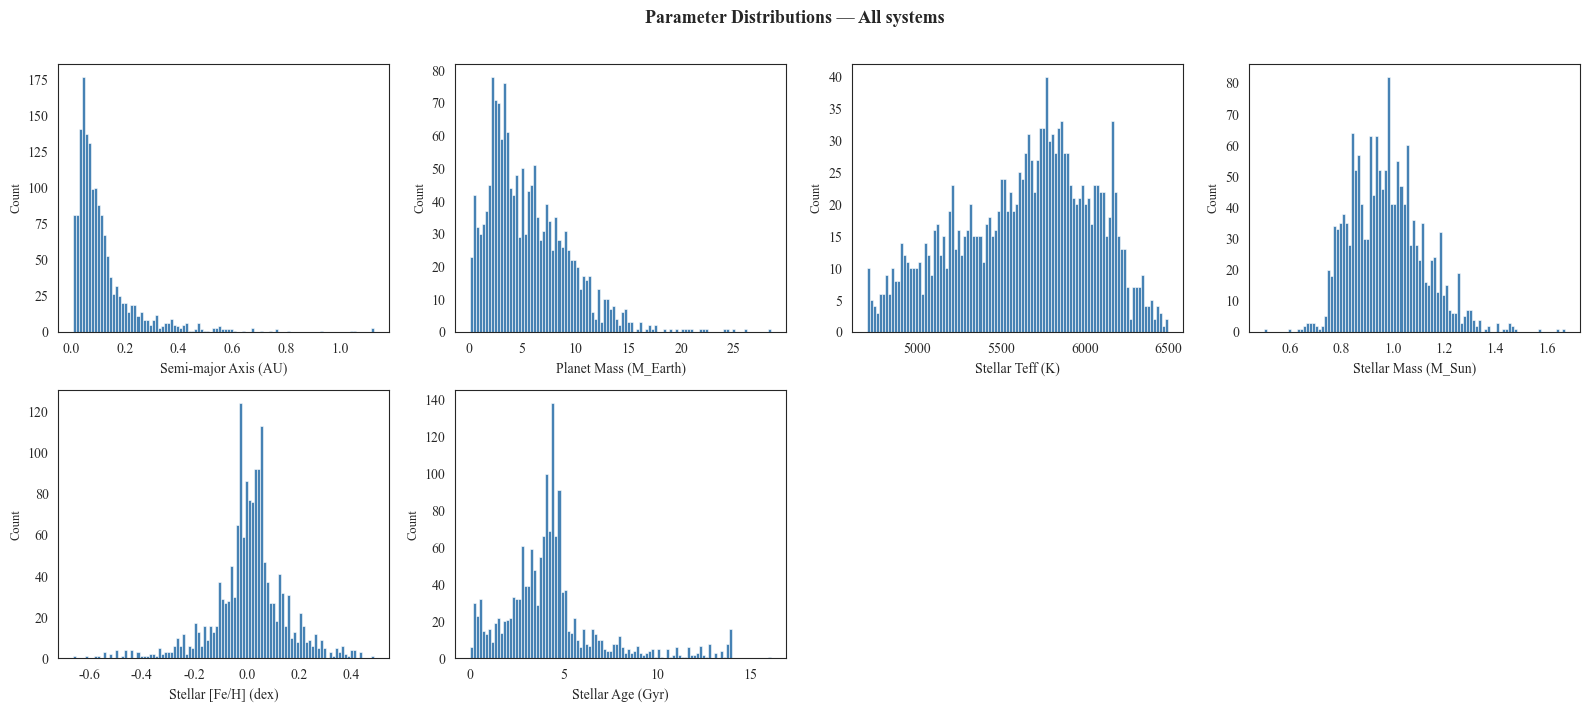

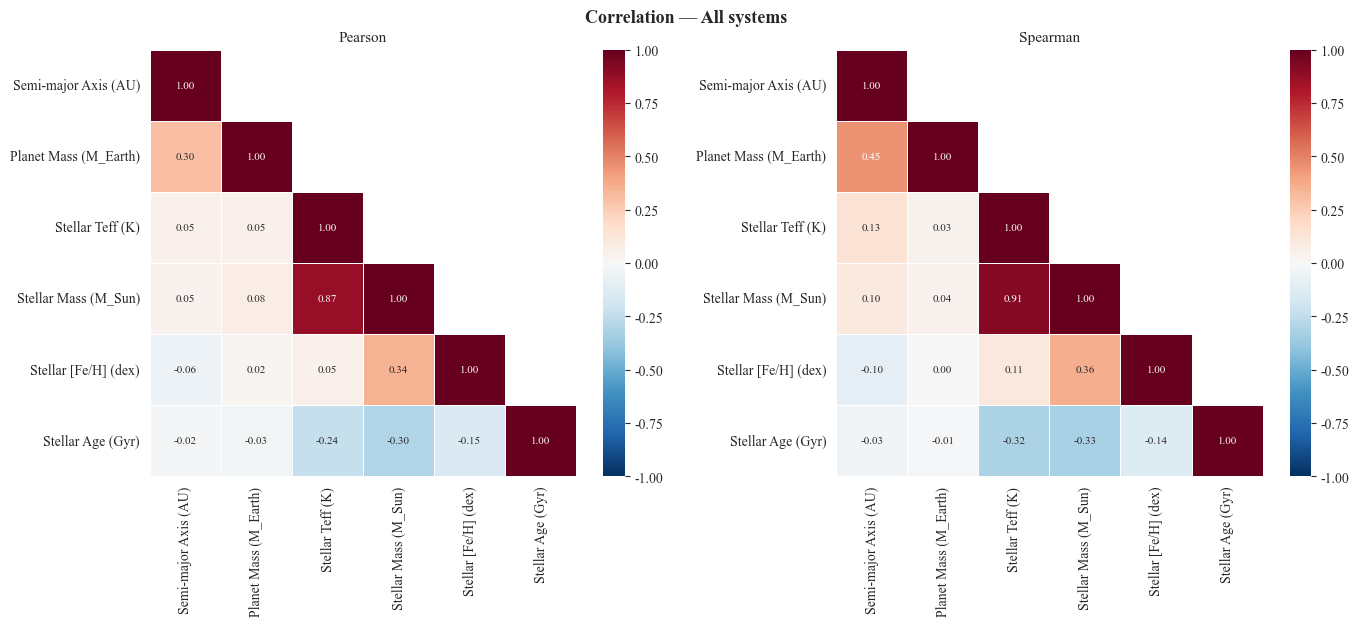


Mutual Information  (raw | binned | kNN), by analysis group

  All systems


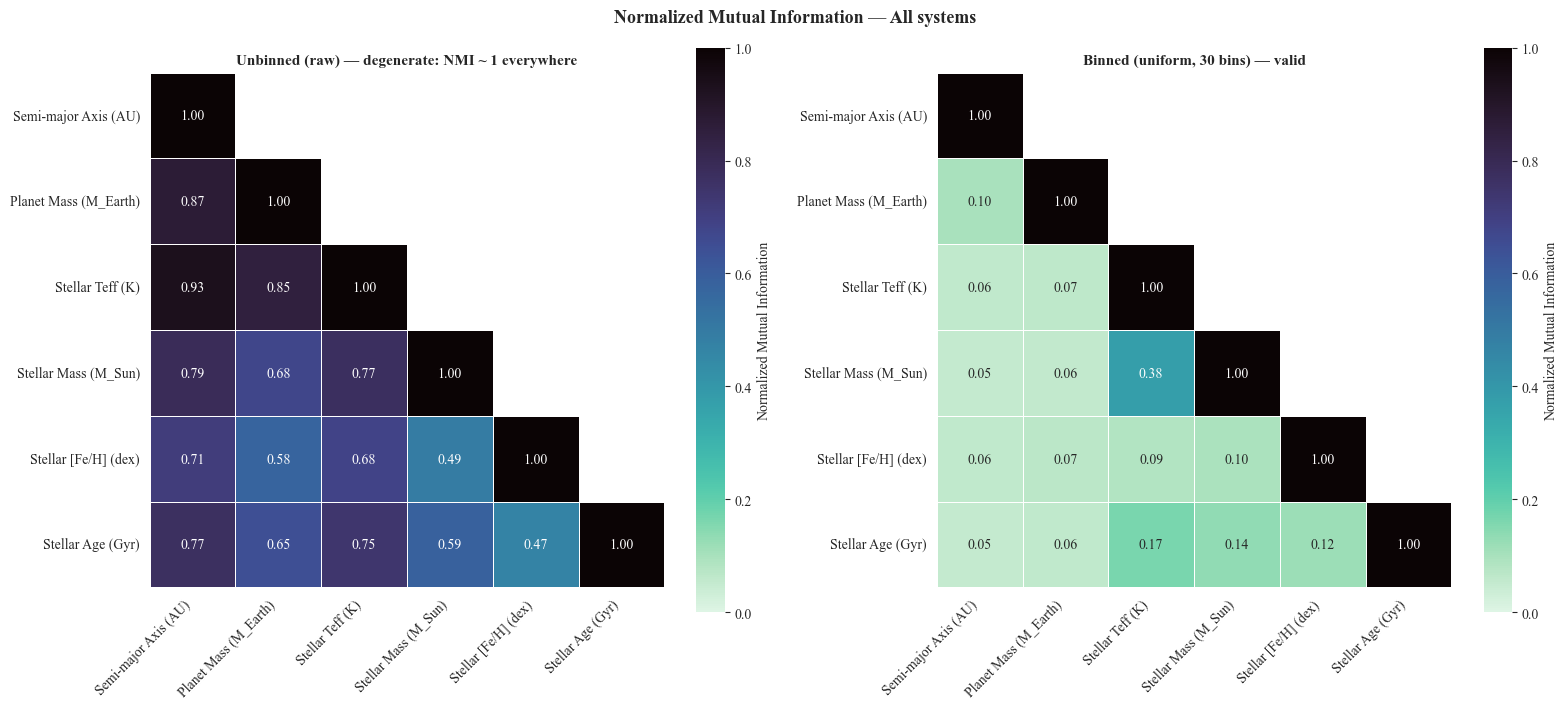

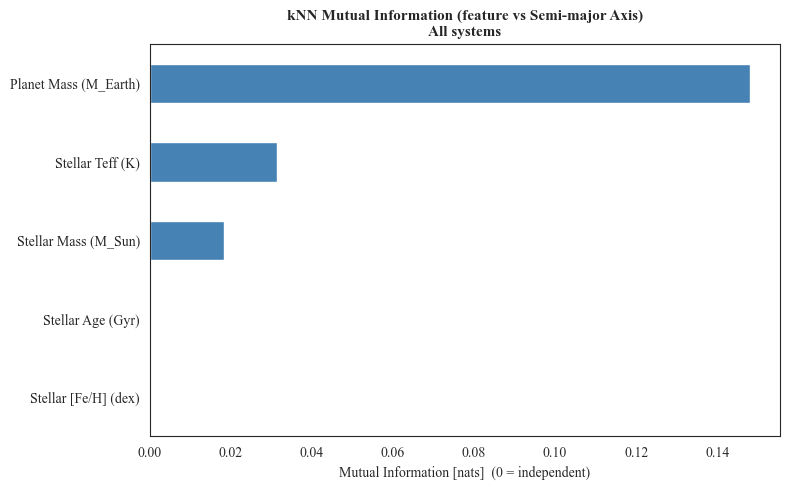

  kNN MI (feature -> semi-major axis):
    Planet Mass (M_Earth)          0.1481
    Stellar Teff (K)               0.0314
    Stellar Mass (M_Sun)           0.0182
    Stellar [Fe/H] (dex)           0.0000
    Stellar Age (Gyr)              0.0000

Five-model analysis — All systems
Systems: 1614 | Target: log10(Semi-major Axis / AU)
Stratified split by inner-boundary semi-major axis

-------------------------------------------------------
  Linear (mass only) — All systems
-------------------------------------------------------
    Tuned           : coef(std)=0.0364
    R2 (log)        : 0.0144   <- primary
    MAE (AU)        : 0.075
    MAPE            : 84.1%
    Within factor-2 : 61.0%
    Median ratio    : 0.988
    1σ training residual: 0.350 dex (multiplicative factor ×2.24)


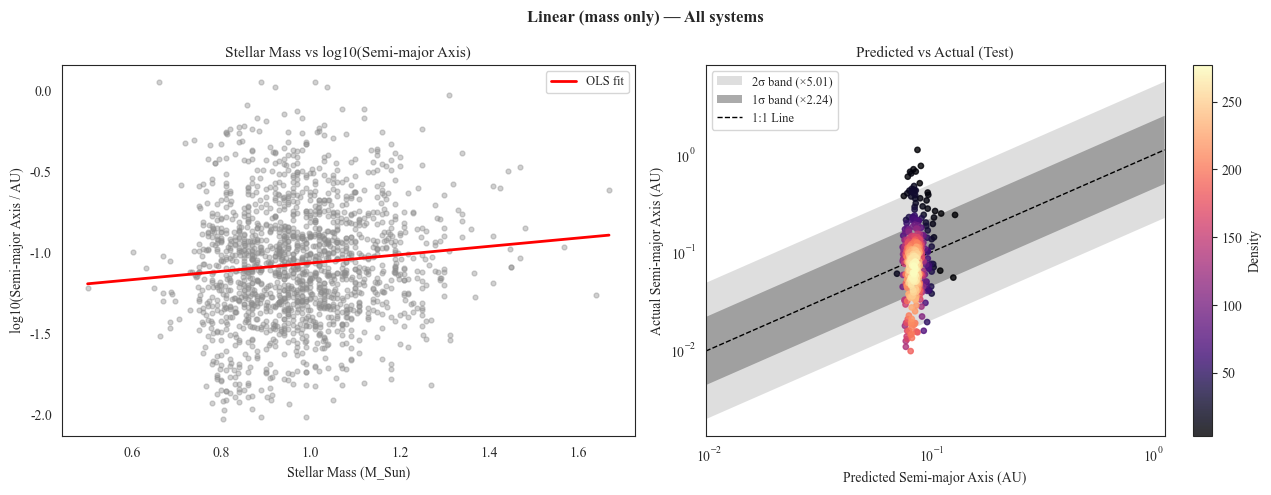


-------------------------------------------------------
  Lasso (all props) — All systems
-------------------------------------------------------
    Tuned           : alpha=8.23e-04
    R2 (log)        : 0.1820   <- primary
    MAE (AU)        : 0.072
    MAPE            : 75.0%
    Within factor-2 : 69.0%
    Median ratio    : 0.975
    1σ training residual: 0.324 dex (multiplicative factor ×2.11)


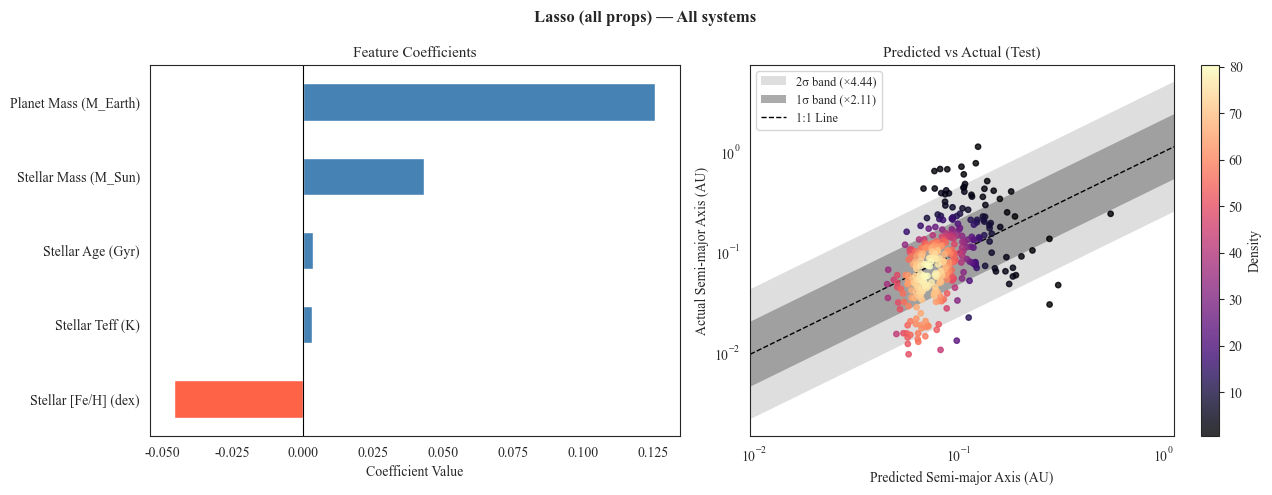


-------------------------------------------------------
  Decision Tree (all props) — All systems
-------------------------------------------------------
  GridSearchCV: 30 combos x 5 folds ...
  Done in 2.7s   Best: {'max_depth': 3, 'min_samples_leaf': 10}
    Tuned           : {'max_depth': 3, 'min_samples_leaf': 10}
    R2 (log)        : 0.2549   <- primary
    MAE (AU)        : 0.068
    MAPE            : 67.2%
    Within factor-2 : 67.2%
    Median ratio    : 0.967
    1σ training residual: 0.306 dex (multiplicative factor ×2.02)
    Train-test R2 gap: -0.009  (OK)


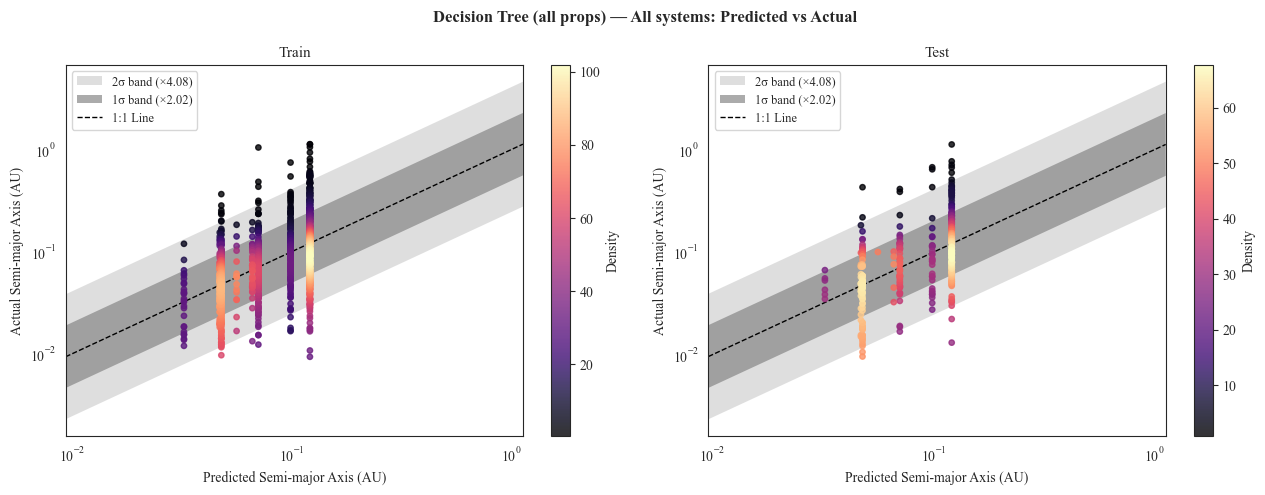

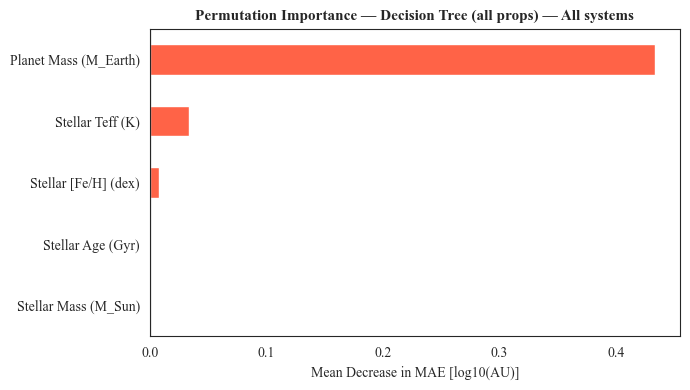


-------------------------------------------------------
  Random Forest (all props) — All systems
-------------------------------------------------------
  GridSearchCV: 80 combos x 5 folds ...
  Done in 98.2s   Best: {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 8, 'n_estimators': 1000}
    Tuned           : {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 8, 'n_estimators': 1000}
    R2 (log)        : 0.2745   <- primary
    MAE (AU)        : 0.067
    MAPE            : 65.3%
    Within factor-2 : 69.3%
    Median ratio    : 0.971
    1σ training residual: 0.290 dex (multiplicative factor ×1.95)
    Train-test R2 gap: 0.045  (OK)


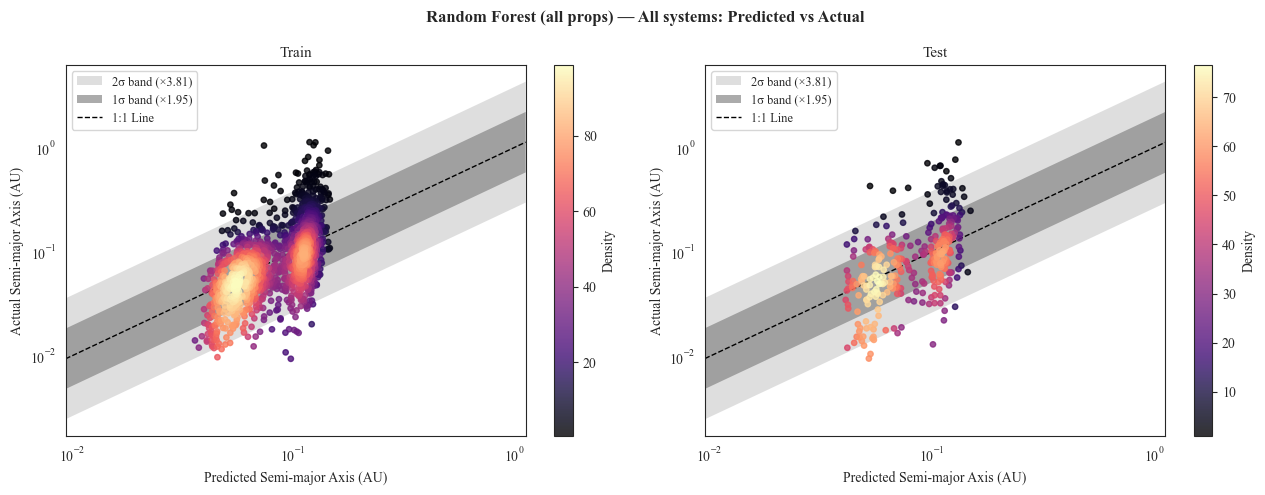

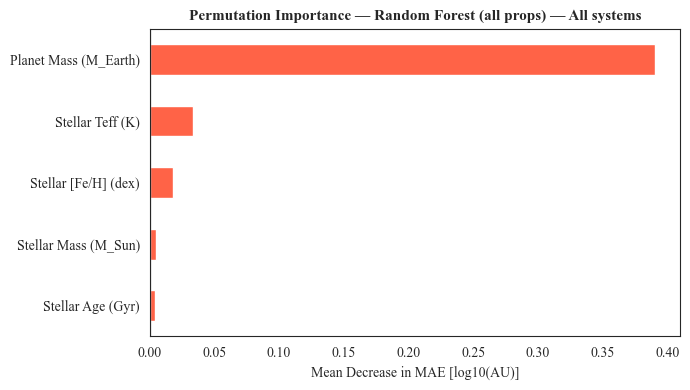

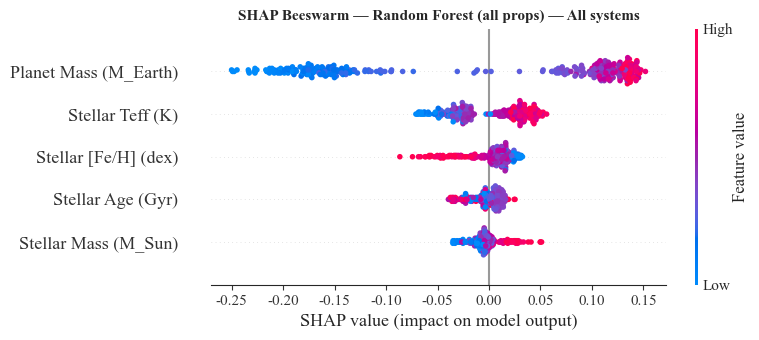


-------------------------------------------------------
  Grad. Boosting (all props) — All systems
-------------------------------------------------------
  GridSearchCV: 27 combos x 5 folds ...
  Done in 2.9s   Best: {'learning_rate': 0.05, 'max_depth': 3, 'max_iter': 200, 'min_samples_leaf': 20}
    Tuned           : {'learning_rate': 0.05, 'max_depth': 3, 'max_iter': 200, 'min_samples_leaf': 20}
    R2 (log)        : 0.2578   <- primary
    MAE (AU)        : 0.068
    MAPE            : 67.3%
    Within factor-2 : 66.3%
    Median ratio    : 0.964
    1σ training residual: 0.277 dex (multiplicative factor ×1.89)
    Train-test R2 gap: 0.123  (OK)


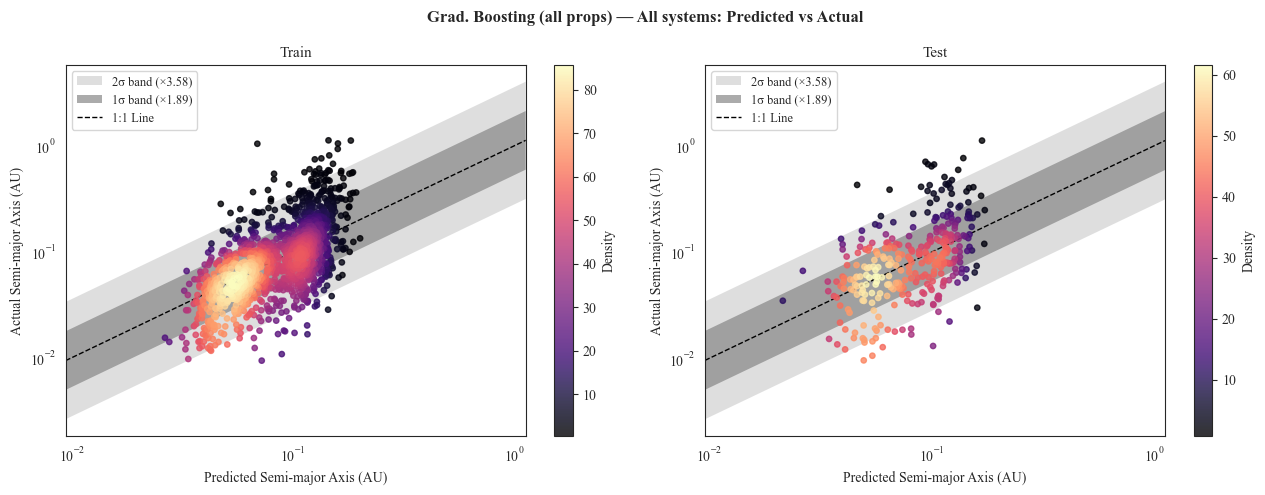

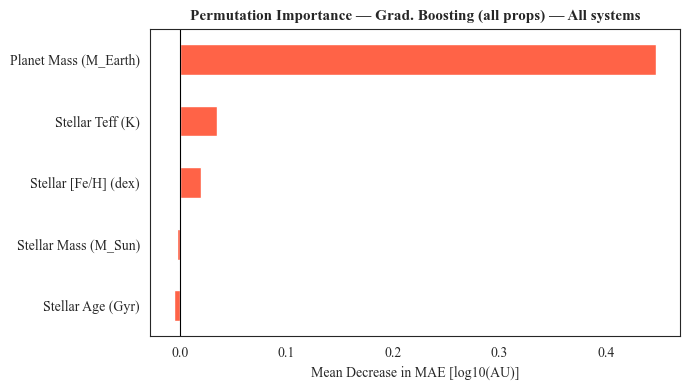

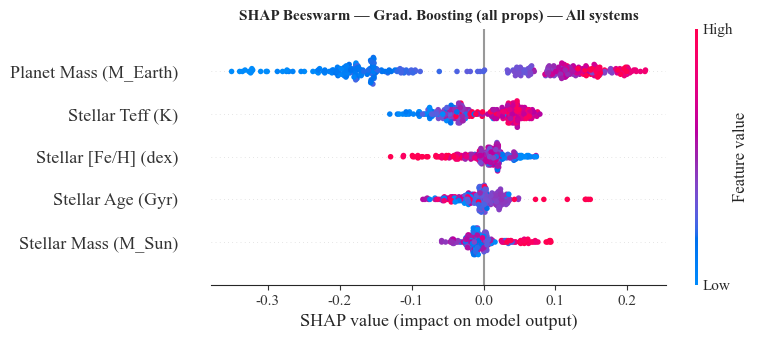


-----------------------------------------------------------------
  Kepler consistency check (RF; A_in -> period) — All systems
-----------------------------------------------------------------
  N = 1614 | R2 (log, days): 0.3012 | MAE (days): 15.0760
  1σ log-period residual: 0.446 dex (multiplicative factor ×2.80)


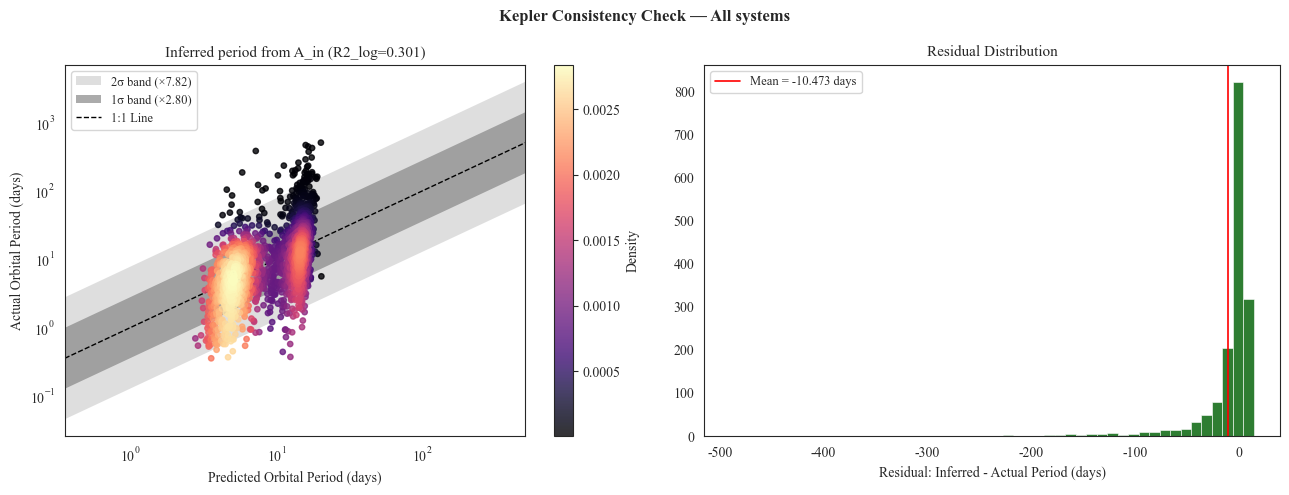


  Running 30 shared stratified splits — All systems

  Stability R2(log) — All systems
  Model                             Mean       Std                 95% CI
  ------------------------------------------------------------------------
  Linear (mass only)              0.0093    0.0104 [0.006, 0.013]
  Linear (all props)              0.1549    0.0281 [0.145, 0.165]
  Decision Tree (all props)       0.2066    0.0292 [0.196, 0.217]
  Random Forest (all props)       0.2389    0.0249 [0.230, 0.248]
  Grad. Boosting (all props)      0.2207    0.0292 [0.210, 0.231]

  Paired t-tests on MAE between model tiers — All systems:
    Linear (mass only)         vs Linear (all props)         t=  9.88  p=8.738e-11 ***
    Linear (all props)         vs Decision Tree (all props)  t= 11.05  p=6.513e-12 ***
    Decision Tree (all props)  vs Random Forest (all props)  t=  9.80  p=1.048e-10 ***
    Random Forest (all props)  vs Grad. Boosting (all props) t= -8.42  p=2.83e-09 ***

Interpretation notes

  T

In [5]:
# ============================================================================
# Exoplanet Inner-Boundary Semi-major Axis — Predictability Analysis
# ============================================================================
#
# Question
# --------
# How well can stellar and planetary properties predict the inner-boundary
# semi-major axis of small-planet systems, and which properties matter?
#
# Approach
# --------
# A five-tier model comparison of increasing complexity, all predicting
# log10(inner-boundary semi-major axis), for the All-systems sample only:
#     1. Linear, stellar mass only          (univariate baseline, "PET 1")
#     2. Linear, all properties             (multivariate linear, Lasso)
#     3. Decision Tree, all properties      (single tree)
#     4. Random Forest, all properties      (bagging ensemble)
#     5. Gradient Boosted Trees, all props  (boosting ensemble, HistGB)
#
# Analysis parameters (six total):
#   Target   : pl_orbsmax -> log10(A_in / AU)
#   Features : pl_bmasse, st_teff, st_mass, st_met, st_age
#   st_lum is excluded so that the ML parameter set matches the main CI model.
# Target   : log10(pl_orbsmax) = log10(A_in / AU) of the inner-boundary planet
# Sample   : small planets (R < 4 R_Earth, M < 30 M_Earth), single-star,
#            main-sequence FGK hosts, from the NASA Exoplanet Archive.
#
# Results
# -------
# All-systems results are computed from the selected catalogue data and
# reported in single-split and repeated-split summaries.
#
# Pipeline sections
# -----------------
#   1-2  Imports & settings
#   3-4  Helpers & parameter labels
#   5-11 Data loading, filtering, inner-edge extraction, cleaning, grouping
#   12-14 Exploratory analysis for All systems
#   15   ML shared utilities & model specifications
#   16-18 Model runners for All systems
#   19   Kepler's-third-law consistency check
#   20-22 Stability evaluation for All systems
# ============================================================================


# ── 1. IMPORTS ──────────────────────────────────────────────────────────────

import time
import warnings
from warnings import simplefilter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import gaussian_kde, ttest_rel
from sklearn.linear_model import LinearRegression, Lasso, LassoCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor,
                              HistGradientBoostingRegressor)
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, mean_absolute_percentage_error,
                             mutual_info_score)
import shap


# ── 2. SETTINGS ─────────────────────────────────────────────────────────────

RANDOM_STATE  = 42
DATA_FILE     = 'PSCompPars_2025.11.11_07.37.00.csv'
SKIP_ROWS     = 191          # NASA Archive header rows
STRATIFY_BINS = 10           # semi-major-axis quantile bins used for stratification
N_RUNS        = 30           # number of random splits in the stability evaluation

simplefilter(action='ignore', category=FutureWarning)
simplefilter(action='ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=matplotlib.MatplotlibDeprecationWarning)
pd.set_option('mode.chained_assignment', None)

sns.set_style('white')
plt.rcParams['font.family']        = 'serif'
plt.rcParams['font.serif']         = ['Times New Roman', 'DejaVu Serif']
plt.rcParams['mathtext.fontset']   = 'custom'
plt.rcParams['mathtext.rm']        = 'Times New Roman'
plt.rcParams['mathtext.it']        = 'Times New Roman:italic'
plt.rcParams['axes.unicode_minus'] = False


# ── 3. PARAMETER LABELS ─────────────────────────────────────────────────────

PARAM_NAMES = {
    'pl_orbper' : 'Orbital Period (days)',
    'pl_orbsmax': 'Semi-major Axis (AU)',
    'pl_bmasse' : 'Planet Mass (M_Earth)',
    'st_teff'   : 'Stellar Teff (K)',
    'st_mass'   : 'Stellar Mass (M_Sun)',
    'st_met'    : 'Stellar [Fe/H] (dex)',
    'st_age'    : 'Stellar Age (Gyr)',
    'sy_pnum'   : 'Planet Count',
}

# Fixed six-parameter ML analysis set: one target plus five predictors.
#
# The ML pipeline now matches the main CI parameter set exactly:
#   - target: log10(pl_orbsmax), corresponding to log_Ain;
#   - predictors: pl_bmasse, st_teff, st_mass, st_met and st_age;
#   - stellar luminosity (st_lum) is deliberately excluded.
#
# The Kepler-specific comparison remains a separate three-variable CI analysis
# (log_Ain, log_Mstar and FeH); system-level overlap with the Archive sample is
# possible, so it is not automatically an independent replication.
#
# In this ML pipeline, the target is log10(pl_orbsmax), corresponding to
# log_Ain in the causal-analysis notation.
ML_FEATURES = [
    'pl_bmasse',
    'st_teff',
    'st_mass',
    'st_met',
    'st_age',
]
ML_TARGET = 'pl_orbsmax'

def label(col):
    """Human-readable axis label for a column name."""
    return PARAM_NAMES.get(col, col)


# ── 4. HELPER ───────────────────────────────────────────────────────────────

def count_summary(df, msg, key='tic_id'):
    n_sys = df[key].nunique() if key in df.columns else df['hostname'].nunique()
    print(f"  [{msg}]  Systems: {n_sys}   Planets: {len(df)}")


# ── 5. DATA LOADING ─────────────────────────────────────────────────────────

print("=" * 60)
print("Data Processing Pipeline")
print("=" * 60)

allp = pd.read_csv(DATA_FILE, skiprows=SKIP_ROWS)
allp = allp.drop(columns='loc_rowid', errors='ignore')
count_summary(allp, 'Raw data', key='hostname')


# ── 6. SAMPLE SELECTION ─────────────────────────────────────────────────────
# Restrict to single-star, main-sequence FGK hosts with small planets.

allp = allp[allp['discoverymethod'].isin(['Transit', 'Radial Velocity'])]
count_summary(allp, 'Transit / RV only', key='hostname')

allp = allp[allp['sy_snum'] == 1]
count_summary(allp, 'Single-star systems', key='hostname')

allp = allp[allp['st_logg'] > 3.8]                      # drop evolved giants
count_summary(allp, 'Main sequence (logg > 3.8)', key='hostname')

allp = allp[(allp['st_teff'] >= 4700) & (allp['st_teff'] <= 6500)]   # FGK
count_summary(allp, 'FGK hosts (4700-6500 K)', key='hostname')

# Small-planet definition applied AFTER inner-boundary extraction:
# First find the true innermost planet of every system (no size restriction),
# then keep only systems whose innermost planet satisfies R < 4 R_Earth AND
# M < 30 M_Earth. Radius is used only for sample selection, not as an ML
# feature or analysis variable.

# ── 7. INNER-BOUNDARY EXTRACTION ────────────────────────────────────────────
# Select columns first, then find the minimum-semi-major-axis planet per system.
# The radius and mass cuts are applied to this inner-boundary planet only;
# radius is not retained as an ML feature.

KEEP = (['tic_id', 'hostname', 'pl_name', 'pl_orbper', ML_TARGET,
         'pl_rade'] + ML_FEATURES +
        ['sy_pnum', 'discoverymethod'])
allp = allp[[c for c in KEEP if c in allp.columns]]

allp = allp.dropna(subset=['pl_orbsmax'])
GROUP_KEY = 'tic_id' if allp['tic_id'].notna().any() else 'hostname'

# Step 1: find the true innermost planet for every system (unrestricted)
inner = allp.loc[allp.groupby(GROUP_KEY)['pl_orbsmax'].idxmin()].copy()
count_summary(inner, 'True inner-boundary planet by minimum semi-major axis (unrestricted)',
              key=GROUP_KEY)

# Step 2: keep only systems where that planet satisfies the small-planet cuts
n_before = len(inner)
inner_small = inner[
    (inner['pl_rade']   < 4.0) &
    (inner['pl_bmasse'] < 30.0)
].copy()
n_after = len(inner_small)
print(f"\n  Inner-boundary radius cut  (pl_rade < 4 R_Earth):  "
      f"removed {(inner['pl_rade'] >= 4.0).sum()} systems")
print(f"  Inner-boundary mass cut   (pl_bmasse < 30 M_Earth): "
      f"removed {n_before - n_after - (inner['pl_rade'] >= 4.0).sum()} additional systems")
print(f"  Systems retained after both cuts: {n_after}")

# Step 3: restrict to these systems (one row per system already)
allp = inner_small.reset_index(drop=True)
# pl_rade is retained only long enough to define the small-planet sample.
# Neither pl_rade nor st_rad enters the final ML dataset.
allp = allp.drop(columns=['pl_rade', 'st_rad'], errors='ignore')
count_summary(allp, 'Inner-boundary planet per system (after small-planet cuts)',
              key=GROUP_KEY)


# ── 8. STRICT CLEANING ──────────────────────────────────────────────────────
# Keep only systems where ALL analysis columns are present.
# Feature set: planet mass and stellar properties, excluding planet radius
# and stellar radius. pl_rade was already used for the sample definition above.
# The missing-value table printed below shows exactly how much is lost.

STRICT_COLS = ['pl_orbper', ML_TARGET] + ML_FEATURES + ['sy_pnum']

print("\n  Missing-value rates before cleaning:")
for c in STRICT_COLS:
    pct = allp[c].isnull().mean() * 100
    print(f"    {c:<12} {pct:5.1f}%")

n0   = len(allp)
allp = allp[allp[STRICT_COLS].notna().all(axis=1)].reset_index(drop=True)
print(f"\n  Dropped {n0 - len(allp)} rows ({(n0 - len(allp)) / n0 * 100:.1f}%); "
      f"final N = {len(allp)}")


# ── 9. ANALYSIS GROUP ───────────────────────────────────────────────────────
# Only the full All-systems sample is analysed below.

small_all   = allp.copy()

ANALYSIS_GROUPS = [
    ('all', 'All systems', small_all),
]
for group_key, group_label, group_df in ANALYSIS_GROUPS:
    vc = group_df['discoverymethod'].value_counts()
    print(f"\n  Group '{group_label}': {len(group_df)} systems "
          f"(Transit {vc.get('Transit', 0)}, RV {vc.get('Radial Velocity', 0)})")

COLOR       = 'steelblue'


# ── 10. PARAMETER DISTRIBUTIONS ─────────────────────────────────────────────

DIST_PARAMS = [ML_TARGET] + ML_FEATURES

def plot_distributions(df, group_label):
    params = [c for c in DIST_PARAMS if c in df.columns]
    ncols  = 4
    nrows  = int(np.ceil(len(params) / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(ncols * 4, nrows * 3.5))
    axes = np.array(axes).flatten()
    fig.suptitle(f'Parameter Distributions — {group_label}',
                 fontsize=13, fontweight='bold', y=1.01)
    for ax, col in zip(axes, params):
        ax.hist(df[col].dropna(), bins=100, color=COLOR,
                edgecolor='white', linewidth=0.4)
        ax.set_xlabel(label(col), fontsize=10)
        ax.set_ylabel('Count', fontsize=9)
    for ax in axes[len(params):]:          # hide unused panels
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

for _, group_label, group_df in ANALYSIS_GROUPS:
    if not group_df.empty:
        plot_distributions(group_df, group_label)


# ── 11. CORRELATION ─────────────────────────────────────────────────────────

CORR_COLS = [ML_TARGET] + ML_FEATURES

def plot_correlation(df, group_label):
    data   = df[CORR_COLS]
    labels = [label(c) for c in CORR_COLS]
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle(f'Correlation — {group_label}', fontsize=13, fontweight='bold')
    for ax, method in [(axes[0], 'pearson'), (axes[1], 'spearman')]:
        corr = data.corr(method=method)
        corr.index = corr.columns = labels
        mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
        sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
                    annot=True, fmt='.2f', annot_kws={'size': 8},
                    linewidths=0.5, square=True, ax=ax)
        ax.set_title(method.capitalize(), fontsize=11)
    plt.tight_layout()
    plt.show()

for _, group_label, group_df in ANALYSIS_GROUPS:
    if not group_df.empty:
        plot_correlation(group_df, group_label)


# ── 12. MUTUAL INFORMATION ──────────────────────────────────────────────────
#
# Mutual information of continuous variables requires either discretisation or
# a continuous estimator. Three views are shown for comparison:
#   (a) raw    : mutual_info_score on raw floats. DEGENERATE — every value is
#                unique, so NMI ~ 1 everywhere. Shown only to demonstrate the
#                pitfall; never use for conclusions.
#   (b) binned : KBinsDiscretizer (30 uniform bins) + mutual_info_score. Valid,
#                but values depend on the bin count.
#   (c) kNN    : mutual_info_regression (KSG estimator). No fixed grid; this is
#                the estimator used for the scientific conclusion below.

def nmi_matrix(df, cols, binned):
    data = df[cols].dropna()
    M = (KBinsDiscretizer(n_bins=30, encode='ordinal', strategy='uniform')
         .fit_transform(data.values)) if binned else data.values
    n = len(cols)
    out = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            denom = np.sqrt(mutual_info_score(M[:, i], M[:, i]) *
                            mutual_info_score(M[:, j], M[:, j]))
            out[i, j] = mutual_info_score(M[:, i], M[:, j]) / denom if denom else 0
    return out

def plot_nmi(df, group_label):
    labels = [label(c) for c in CORR_COLS]
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    fig.suptitle(f'Normalized Mutual Information — {group_label}',
                 fontsize=13, fontweight='bold')
    for ax, binned, title in [
        (axes[0], False, 'Unbinned (raw) — degenerate: NMI ~ 1 everywhere'),
        (axes[1], True,  'Binned (uniform, 30 bins) — valid')]:
        M = nmi_matrix(df, CORR_COLS, binned)
        mask = np.triu(np.ones_like(M, dtype=bool), k=1)
        sns.heatmap(M, mask=mask, xticklabels=labels, yticklabels=labels,
                    annot=True, fmt='.2f', vmin=0, vmax=1, square=True,
                    linewidths=0.5, cmap=sns.color_palette('mako_r', as_cmap=True),
                    cbar_kws={'label': 'Normalized Mutual Information'}, ax=ax)
        ax.set_title(title, fontsize=11, fontweight='bold')
        ax.tick_params(axis='x', rotation=45)
        for t in ax.get_xticklabels():
            t.set_ha('right')
    plt.tight_layout()
    plt.show()

def plot_knn_mi(df, group_label):
    feats = [c for c in CORR_COLS if c != 'pl_orbsmax']
    data  = df[feats + ['pl_orbsmax']].dropna()
    mi = mutual_info_regression(data[feats].values,
                                np.log10(data['pl_orbsmax'].values),
                                random_state=RANDOM_STATE)
    s = pd.Series(mi, index=[label(c) for c in feats]).sort_values()
    fig, ax = plt.subplots(figsize=(8, 5))
    s.plot(kind='barh', ax=ax, color=COLOR)
    ax.set_title(f'kNN Mutual Information (feature vs Semi-major Axis)\n{group_label}',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Mutual Information [nats]  (0 = independent)', fontsize=10)
    plt.tight_layout()
    plt.show()
    return s

print("\n" + "=" * 60)
print("Mutual Information  (raw | binned | kNN), by analysis group")
print("=" * 60)
knn_mi_results = {}
for group_key, group_label, group_df in ANALYSIS_GROUPS:
    if group_df.empty:
        print(f"  Skipping mutual information for empty group: {group_label}")
        continue
    print(f"\n  {group_label}")
    plot_nmi(group_df, group_label)
    knn_mi = plot_knn_mi(group_df, group_label)
    knn_mi_results[group_key] = knn_mi
    print("  kNN MI (feature -> semi-major axis):")
    for k, v in knn_mi.sort_values(ascending=False).items():
        print(f"    {k:<30} {v:.4f}")


# ════════════════════════════════════════════════════════════════════════════
# ── 13. ML — SHARED UTILITIES & MODEL SPECIFICATIONS ────────────────────────
# ════════════════════════════════════════════════════════════════════════════

ALL_FEATURES = ML_FEATURES.copy()
MASS_FEATURE = ['st_mass']
TARGET       = ML_TARGET
TARGET_LABEL = 'Semi-major Axis'
TARGET_UNIT  = 'AU'

# Hyper-parameter grids for the tree-based models
DT_GRID = {'max_depth': [3, 4, 5, 6, 7, 8],
           'min_samples_leaf': [5, 10, 15, 20, 30]}
RF_GRID = {'n_estimators': [1000], 'max_depth': [5, 6, 7, 8],
           'min_samples_leaf': [8, 10, 12, 15],
           'max_features': ['sqrt', 'log2', 0.25, 0.5, None]}
GB_GRID = {'learning_rate': [0.05, 0.1, 0.2], 'max_depth': [3, 4, 5],
           'min_samples_leaf': [10, 20, 30], 'max_iter': [200]}

# Five-tier model comparison. Each spec drives the run loop, the stability
# loop, the summary table and the box plots — add a model by appending here.
MODEL_SPECS = [
    {'key': 'lin_mass',  'label': 'Linear (mass only)',
     'features': MASS_FEATURE, 'kind': 'linear', 'color': '#8c8c8c'},
    {'key': 'lin_multi', 'label': 'Linear (all props)',
     'features': ALL_FEATURES, 'kind': 'lasso',  'color': 'steelblue'},
    {'key': 'dt_multi',  'label': 'Decision Tree (all props)',
     'features': ALL_FEATURES, 'kind': 'dt', 'grid': DT_GRID,
     'shap': False, 'color': '#e6a817'},
    {'key': 'rf_multi',  'label': 'Random Forest (all props)',
     'features': ALL_FEATURES, 'kind': 'rf', 'grid': RF_GRID,
     'shap': True,  'color': '#2e7d32'},
    {'key': 'gb_multi',  'label': 'Grad. Boosting (all props)',
     'features': ALL_FEATURES, 'kind': 'gb', 'grid': GB_GRID,
     'shap': True,  'color': '#8b1a4a'},
]


def prepare_ml_data(df, features):
    """Return X (DataFrame), y = log10(semi-major axis), and feature names."""
    data = df[features + [TARGET]].dropna()
    data = data[data[TARGET] > 0]
    return data[features], np.log10(data[TARGET].values), features


def make_target_bins(y):
    """Choose quantile bins that can be represented in both split portions."""
    n_samples = len(y)
    n_test = int(np.ceil(0.2 * n_samples))
    max_bins = min(STRATIFY_BINS, n_test, n_samples - n_test, n_samples // 2)
    for n_bins in range(max_bins, 1, -1):
        bins = pd.qcut(y, q=n_bins, duplicates='drop')
        counts = pd.Series(bins).value_counts()
        if len(counts) >= 2 and counts.min() >= 2 and len(counts) <= n_test:
            return bins
    raise ValueError(
        f"Not enough systems ({n_samples}) to create a valid stratified "
        "train/test split."
    )


def stratified_split(X, y, seed=RANDOM_STATE):
    """
    Train/test split stratified by inner-boundary semi-major axis.

    Why bin? sklearn's `stratify` treats its argument as discrete CLASS labels
    and matches class proportions between train and test. Passing the raw
    continuous target would create ~N unique "classes" and raise an error.
    Binning into up to 10 quantile groups instead asks for a similar SHAPE of
    the semi-major-axis distribution in train and test. The bin count adapts
    to the available sample size.
    """
    y_bins = make_target_bins(y)
    return train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y_bins)


def base_estimator(kind, seed=RANDOM_STATE):
    return {'dt': DecisionTreeRegressor(random_state=seed),
            'rf': RandomForestRegressor(random_state=seed, n_jobs=-1),
            'gb': HistGradientBoostingRegressor(random_state=seed)}[kind]


def build_model(spec, tuned, seed):
    """Construct a model from its spec and tuned hyper-parameters (for stability runs)."""
    kind, key = spec['kind'], spec['key']
    if kind == 'linear':
        return LinearRegression()
    if kind == 'lasso':
        return Lasso(alpha=tuned[key], max_iter=10000)
    if kind == 'dt':
        return DecisionTreeRegressor(random_state=seed, **tuned[key])
    if kind == 'rf':
        return RandomForestRegressor(random_state=seed, n_jobs=-1, **tuned[key])
    if kind == 'gb':
        return HistGradientBoostingRegressor(random_state=seed, **tuned[key])


def compute_metrics(y_true, y_pred):
    """Metrics in log space (primary) and linear AU, plus accuracy rates."""
    y_t, y_p = 10 ** np.array(y_true), 10 ** np.array(y_pred)
    ratio = y_p / np.clip(y_t, 1e-10, None)
    return {
        'R2_log': r2_score(y_true, y_pred),
        'MAE_log': mean_absolute_error(y_true, y_pred),
        'MAE': mean_absolute_error(y_t, y_p),
        'RMSE': np.sqrt(mean_squared_error(y_t, y_p)),
        'R2': r2_score(y_t, y_p),
        'MAPE': mean_absolute_percentage_error(y_t, y_p),
        'within_20': np.mean(np.abs(ratio - 1) < 0.20),
        'within_30': np.mean(np.abs(ratio - 1) < 0.30),
        'within_50': np.mean(np.abs(ratio - 1) < 0.50),
        'within_f2': np.mean((ratio > 0.5) & (ratio < 2.0)),
        'median_ratio': np.median(ratio),
    }


def residual_sigma(y_true, y_pred):
    """Standard deviation of residuals in log10 target space."""
    residual = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
    return float(np.std(residual, ddof=1))


def print_metrics(m, extra=None):
    if extra:
        print(f"    {'Tuned':<16}: {extra}")
    print(f"    {'R2 (log)':<16}: {m['R2_log']:.4f}   <- primary")
    print(f"    {'MAE (AU)':<16}: {m['MAE']:.3f}")
    print(f"    {'MAPE':<16}: {m['MAPE'] * 100:.1f}%")
    print(f"    {'Within factor-2':<16}: {m['within_f2'] * 100:.1f}%")
    print(f"    {'Median ratio':<16}: {m['median_ratio']:.3f}")


def plot_pred_actual(ax, y_true, y_pred, title, color,
                     x_label=None, y_label=None, sigma_log=None):
    """
    Plot predicted versus actual values with multiplicative 1-sigma and
    2-sigma bands.

    The model is trained in log10 target space. Therefore, if sigma_log is
    the residual standard deviation in that space, the bands are
    actual = predicted * 10^(+/- sigma_log) and
    actual = predicted * 10^(+/- 2 * sigma_log). The default is calculated
    from the plotted data; model plots pass the training-set value explicitly.

    Drawing order is intentional: 2-sigma band, 1-sigma band, 1:1 line,
    and density-colored points.
    """
    yt, yp = 10 ** np.array(y_true), 10 ** np.array(y_pred)
    if sigma_log is None:
        sigma_log = residual_sigma(y_true, y_pred)
    sigma_1_factor = 10 ** sigma_log
    sigma_2_factor = 10 ** (2 * sigma_log)
    lims = [min(yp.min(), yt.min()), max(yp.max(), yt.max())]
    x_band = np.logspace(np.log10(lims[0]), np.log10(lims[1]), 200)
    lower_2sigma = x_band / sigma_2_factor
    upper_2sigma = x_band * sigma_2_factor
    lower_1sigma = x_band / sigma_1_factor
    upper_1sigma = x_band * sigma_1_factor

    # Draw uncertainty bands first, so the 1:1 line and points remain visible.
    ax.fill_between(x_band, lower_2sigma, upper_2sigma,
                    color='#d9d9d9', alpha=0.85, edgecolor='none',
                    label=f'2σ band (×{sigma_2_factor:.2f})', zorder=1)
    ax.fill_between(x_band, lower_1sigma, upper_1sigma,
                    color='#7f7f7f', alpha=0.65, edgecolor='none',
                    label=f'1σ band (×{sigma_1_factor:.2f})', zorder=1)
    ax.plot(lims, lims, 'k--', lw=1, label='1:1 Line', zorder=2)

    # Density points are the top layer and use the magma colormap throughout.
    try:
        z = gaussian_kde(np.vstack([yp, yt]))(np.vstack([yp, yt]))
        idx = z.argsort()
        sc = ax.scatter(yp[idx], yt[idx], c=z[idx], s=15,
                        cmap='magma', alpha=0.8, zorder=3)
        plt.colorbar(sc, ax=ax, label='Density')
    except Exception:
        ax.scatter(yp, yt, s=15, color='#b73779', alpha=0.75, zorder=3)

    ax.set(xscale='log', yscale='log')
    ax.set_xlim(lims)
    ax.set_xlabel(x_label or f'Predicted {TARGET_LABEL} ({TARGET_UNIT})', fontsize=10)
    ax.set_ylabel(y_label or f'Actual {TARGET_LABEL} ({TARGET_UNIT})', fontsize=10)
    ax.set_title(title, fontsize=11)
    ax.legend(fontsize=9)


def plot_perm_importance(model, X_test, y_test, feats, title):
    perm = permutation_importance(model, X_test, y_test, n_repeats=10,
                                  random_state=RANDOM_STATE, n_jobs=-1)
    s = pd.Series(perm.importances_mean, index=[label(f) for f in feats]).sort_values()
    fig, ax = plt.subplots(figsize=(7, 4))
    s.plot(kind='barh', ax=ax, color='tomato')
    ax.axvline(0, color='k', lw=0.8)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('Mean Decrease in MAE [log10(AU)]', fontsize=10)
    plt.tight_layout()
    plt.show()


def plot_shap(model, X_test, feats, title):
    try:
        Xdf = pd.DataFrame(X_test, columns=feats).rename(columns=PARAM_NAMES)
        shap_values = shap.TreeExplainer(model)(Xdf)
        plt.figure(figsize=(8, 5))
        shap.plots.beeswarm(shap_values, max_display=10, show=False)
        plt.title(title, fontsize=11, fontweight='bold')
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"    SHAP skipped: {e}")


# ── 14. MODEL 1 — LINEAR, STELLAR MASS ONLY ─────────────────────────────────

def run_linear_mass(df, group_label):
    print(f"\n{'-' * 55}\n  Linear (mass only) — {group_label}\n{'-' * 55}")
    X, y, feats = prepare_ml_data(df, MASS_FEATURE)
    Xtr, Xte, ytr, yte = stratified_split(X.values, y)
    scaler = StandardScaler().fit(Xtr)
    model  = LinearRegression().fit(scaler.transform(Xtr), ytr)
    pred_tr = model.predict(scaler.transform(Xtr))
    pred_te = model.predict(scaler.transform(Xte))
    sigma_log = residual_sigma(ytr, pred_tr)
    m_test = compute_metrics(yte, pred_te)
    print_metrics(m_test, extra=f"coef(std)={model.coef_[0]:.4f}")
    print(f"    1σ training residual: {sigma_log:.3f} dex "
          f"(multiplicative factor ×{10 ** sigma_log:.2f})")

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle(f'Linear (mass only) — {group_label}', fontsize=12, fontweight='bold')
    axes[0].scatter(X.values[:, 0], y, s=12, alpha=0.4, color='#8c8c8c')
    grid = np.linspace(X.values[:, 0].min(), X.values[:, 0].max(), 100)
    axes[0].plot(grid, model.predict(scaler.transform(grid.reshape(-1, 1))),
                 'r-', lw=2, label='OLS fit')
    axes[0].set_xlabel(label('st_mass'), fontsize=10)
    axes[0].set_ylabel('log10(Semi-major Axis / AU)', fontsize=10)
    axes[0].set_title('Stellar Mass vs log10(Semi-major Axis)', fontsize=11)
    axes[0].legend(fontsize=9)
    plot_pred_actual(axes[1], yte, pred_te,
                     'Predicted vs Actual (Test)', '#8c8c8c',
                     sigma_log=sigma_log)
    plt.tight_layout()
    plt.show()
    return {'metrics_test': m_test, 'feat_names': feats}


# ── 15. MODEL 2 — LASSO, ALL PROPERTIES ─────────────────────────────────────

def run_lasso(df, group_label):
    print(f"\n{'-' * 55}\n  Lasso (all props) — {group_label}\n{'-' * 55}")
    X, y, feats = prepare_ml_data(df, ALL_FEATURES)
    Xtr, Xte, ytr, yte = stratified_split(X.values, y)
    scaler = StandardScaler().fit(Xtr)
    model  = LassoCV(alphas=np.logspace(-4, 2, 60), cv=5, max_iter=10000)
    model.fit(scaler.transform(Xtr), ytr)
    pred_tr = model.predict(scaler.transform(Xtr))
    pred_te = model.predict(scaler.transform(Xte))
    sigma_log = residual_sigma(ytr, pred_tr)
    m_test = compute_metrics(yte, pred_te)
    print_metrics(m_test, extra=f"alpha={model.alpha_:.2e}")
    print(f"    1σ training residual: {sigma_log:.3f} dex "
          f"(multiplicative factor ×{10 ** sigma_log:.2f})")

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle(f'Lasso (all props) — {group_label}', fontsize=12, fontweight='bold')
    coef = pd.Series(model.coef_, index=[label(f) for f in feats]).sort_values()
    coef.plot(kind='barh', ax=axes[0],
              color=['tomato' if v < 0 else 'steelblue' for v in coef])
    axes[0].axvline(0, color='k', lw=0.8)
    axes[0].set_title('Feature Coefficients', fontsize=11)
    axes[0].set_xlabel('Coefficient Value', fontsize=10)
    plot_pred_actual(axes[1], yte, pred_te,
                     'Predicted vs Actual (Test)', 'steelblue',
                     sigma_log=sigma_log)
    plt.tight_layout()
    plt.show()
    return {'metrics_test': m_test, 'best_alpha': model.alpha_, 'feat_names': feats}


# ── 16. MODELS 3-5 — TREE-BASED (Decision Tree / Random Forest / GBT) ───────
# All three share the same workflow, so a single function handles them, driven
# by the spec (which carries the grid and whether to compute SHAP).

def run_tree_model(df, spec, group_label, cv=5):
    print(f"\n{'-' * 55}\n  {spec['label']} — {group_label}\n{'-' * 55}")
    X, y, feats = prepare_ml_data(df, spec['features'])
    Xtr, Xte, ytr, yte = stratified_split(X.values, y)

    n_combos = int(np.prod([len(v) for v in spec['grid'].values()]))
    print(f"  GridSearchCV: {n_combos} combos x {cv} folds ...")
    t0 = time.time()
    grid = GridSearchCV(base_estimator(spec['kind']), spec['grid'], cv=cv,
                        scoring='neg_mean_absolute_error', n_jobs=-1)
    grid.fit(Xtr, ytr)
    model = grid.best_estimator_
    print(f"  Done in {time.time() - t0:.1f}s   Best: {grid.best_params_}")

    pred_tr = model.predict(Xtr)
    pred_te = model.predict(Xte)
    sigma_log = residual_sigma(ytr, pred_tr)
    m_train = compute_metrics(ytr, pred_tr)
    m_test  = compute_metrics(yte, pred_te)
    print_metrics(m_test, extra=str(grid.best_params_))
    print(f"    1σ training residual: {sigma_log:.3f} dex "
          f"(multiplicative factor ×{10 ** sigma_log:.2f})")
    gap = m_train['R2_log'] - m_test['R2_log']
    print(f"    Train-test R2 gap: {gap:.3f}  "
          f"({'overfit' if gap > 0.15 else 'OK'})")

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle(f"{spec['label']} — {group_label}: Predicted vs Actual",
                 fontsize=12, fontweight='bold')
    plot_pred_actual(axes[0], ytr, pred_tr, 'Train', spec['color'],
                     sigma_log=sigma_log)
    plot_pred_actual(axes[1], yte, pred_te, 'Test', spec['color'],
                     sigma_log=sigma_log)
    plt.tight_layout()
    plt.show()

    plot_perm_importance(model, Xte, yte, feats,
                         f"Permutation Importance — {spec['label']} — {group_label}")
    if spec.get('shap'):
        plot_shap(model, Xte, feats,
                  f"SHAP Beeswarm — {spec['label']} — {group_label}")

    return {'metrics_train': m_train, 'metrics_test': m_test,
            'best_params': grid.best_params_, 'feat_names': feats, 'model': model,
            'sigma_log': sigma_log}


# ── 17. RUN THE FIVE MODELS FOR ALL SYSTEMS ─────────────────────────────────

def run_models_for_group(df, group_label):
    if df.empty:
        print(f"\n  {group_label}: empty group; skipping model analysis.")
        return {}

    print("\n" + "=" * 72)
    print(f"Five-model analysis — {group_label}")
    print(f"Systems: {len(df)} | Target: log10({TARGET_LABEL} / {TARGET_UNIT})")
    print("Stratified split by inner-boundary semi-major axis")
    print("=" * 72)

    group_results = {}
    for spec in MODEL_SPECS:
        if spec['kind'] == 'linear':
            group_results[spec['key']] = run_linear_mass(df, group_label)
        elif spec['kind'] == 'lasso':
            group_results[spec['key']] = run_lasso(df, group_label)
        else:
            group_results[spec['key']] = run_tree_model(df, spec, group_label)
    return group_results


results = {
    group_key: run_models_for_group(group_df, group_label)
    for group_key, group_label, group_df in ANALYSIS_GROUPS
}


# ── 19. KEPLER'S-THIRD-LAW CONSISTENCY CHECK (RF) ────────────────────────────
# Predict A_in -> infer orbital period via Kepler's third law -> compare to
# the catalogue value. This is a physical-consistency check, not an independent
# validation, because period, semi-major axis and stellar mass are related.

G, M_SUN, AU, DAY = 6.674e-11, 1.989e30, 1.496e11, 86400


def run_kepler_check(df, rf_res, group_label):
    print(f"\n{'-' * 65}\n  Kepler consistency check (RF; A_in -> period) — "
          f"{group_label}\n{'-' * 65}")
    if not rf_res or 'model' not in rf_res:
        print("  Random Forest result unavailable; skipping.")
        return

    feats = rf_res['feat_names']
    data = df[list(dict.fromkeys(
        feats + ['st_mass', 'pl_orbper', 'pl_orbsmax']
    ))].dropna()
    data = data[(data['st_mass'] > 0) & (data['pl_orbper'] > 0)]
    if data.empty:
        print("  No valid rows for the Kepler consistency check; skipping.")
        return

    a_in_pred = 10 ** rf_res['model'].predict(data[feats].values)
    period_pred = (2 * np.pi * np.sqrt(
        (a_in_pred * AU) ** 3
        / (G * data['st_mass'].values * M_SUN)
    ) / DAY)
    period_true = data['pl_orbper'].values
    r2_log = r2_score(
        np.log10(period_true),
        np.log10(np.clip(period_pred, 1e-6, None)),
    )
    sigma_log_period = residual_sigma(
        np.log10(period_true), np.log10(np.clip(period_pred, 1e-6, None))
    )
    print(f"  N = {len(data)} | R2 (log, days): {r2_log:.4f} | MAE (days): "
          f"{mean_absolute_error(period_true, period_pred):.4f}")
    print(f"  1σ log-period residual: {sigma_log_period:.3f} dex "
          f"(multiplicative factor ×{10 ** sigma_log_period:.2f})")

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle(f'Kepler Consistency Check — {group_label}',
                 fontsize=12, fontweight='bold')
    plot_pred_actual(
        axes[0], np.log10(period_true), np.log10(period_pred),
        f'Inferred period from A_in (R2_log={r2_log:.3f})', '#2e7d32',
        x_label='Predicted Orbital Period (days)',
        y_label='Actual Orbital Period (days)',
        sigma_log=sigma_log_period,
    )
    residual = period_pred - period_true
    axes[1].hist(residual, bins=50, color='#2e7d32', edgecolor='white', lw=0.4)
    axes[1].axvline(np.mean(residual), color='red', lw=1.2,
                    label=f'Mean = {np.mean(residual):.3f} days')
    axes[1].set_xlabel('Residual: Inferred - Actual Period (days)', fontsize=10)
    axes[1].set_title('Residual Distribution', fontsize=11)
    axes[1].legend(fontsize=9)
    plt.tight_layout()
    plt.show()


for group_key, group_label, group_df in ANALYSIS_GROUPS:
    group_result = results.get(group_key, {})
    run_kepler_check(group_df, group_result.get('rf_multi'), group_label)


# ── 20. STABILITY EVALUATION — SEPARATE GROUPS, SAME MODEL SPECIFICATIONS ────

def ci95(arr):
    arr = np.asarray(arr, dtype=float)
    if len(arr) < 2:
        return float(np.mean(arr)), 0.0
    return float(arr.mean()), float(1.96 * arr.std(ddof=1) / np.sqrt(len(arr)))


def tuned_parameters(group_results):
    tuned = {}
    for spec in MODEL_SPECS:
        result = group_results.get(spec['key'])
        if result is None:
            continue
        tuned[spec['key']] = (
            result['best_alpha'] if spec['kind'] == 'lasso'
            else result.get('best_params')
        )
    return tuned


def run_stability(df, group_results, group_label):
    X_all, y, _ = prepare_ml_data(df, ALL_FEATURES)
    keys = ['R2_log', 'MAE', 'MAPE', 'within_20', 'within_30',
            'within_f2', 'median_ratio']
    rec = {spec['key']: {metric: [] for metric in keys}
           for spec in MODEL_SPECS}

    tuned = tuned_parameters(group_results)
    print(f"\n  Running {N_RUNS} shared stratified splits — {group_label}")
    for seed in range(N_RUNS):
        y_bins = make_target_bins(y)
        Xtr, Xte, ytr, yte = train_test_split(
            X_all, y, test_size=0.2, random_state=seed, stratify=y_bins)
        for spec in MODEL_SPECS:
            cols = spec['features']
            scaler = StandardScaler().fit(Xtr[cols].values)
            model = build_model(spec, tuned, seed)
            model.fit(scaler.transform(Xtr[cols].values), ytr)
            pred = model.predict(scaler.transform(Xte[cols].values))
            metrics = compute_metrics(yte, pred)
            for metric in keys:
                rec[spec['key']][metric].append(metrics[metric])

    print(f"\n  Stability R2(log) — {group_label}")
    print(f"  {'Model':<28} {'Mean':>9} {'Std':>9} {'95% CI':>22}")
    print("  " + "-" * 72)
    for spec in MODEL_SPECS:
        values = np.asarray(rec[spec['key']]['R2_log'], dtype=float)
        mean, half_width = ci95(values)
        print(f"  {spec['label']:<28} {mean:>9.4f} "
              f"{np.std(values, ddof=1):>9.4f} "
              f"[{mean - half_width:.3f}, {mean + half_width:.3f}]")

    print(f"\n  Paired t-tests on MAE between model tiers — {group_label}:")
    order = [spec['key'] for spec in MODEL_SPECS]
    for left, right in zip(order[:-1], order[1:]):
        t_stat, p_value = ttest_rel(rec[left]['MAE'], rec[right]['MAE'])
        significance = ('***' if p_value < 0.001 else '**' if p_value < 0.01
                        else '*' if p_value < 0.05 else 'n.s.')
        label_left = next(s['label'] for s in MODEL_SPECS if s['key'] == left)
        label_right = next(s['label'] for s in MODEL_SPECS if s['key'] == right)
        print(f"    {label_left:<26} vs {label_right:<26} "
              f"t={t_stat:>6.2f}  p={p_value:.4g} {significance}")
    return rec


stability_results = {}
for group_key, group_label, group_df in ANALYSIS_GROUPS:
    group_result = results.get(group_key, {})
    if group_result and not group_df.empty:
        stability_results[group_key] = run_stability(
            group_df, group_result, group_label
        )
    else:
        stability_results[group_key] = None


# ── 21. INTERPRETATION NOTES ─────────────────────────────────────────────────

print("\n" + "=" * 72)
print("Interpretation notes")
print("=" * 72)
print("""
  This analysis reports the All-systems sample only. The same five model
  tiers, six-parameter feature set, target transformation and split procedure
  are used throughout.

  Compare R2(log), MAE, the percentage within 30%, and the factor-of-two
  accuracy together. Lower MAE is better; higher R2 and accuracy percentages
  are better. Repeated-split results describe sensitivity to the train/test
  partition and are not independent observations.

  The Kepler third-law check is a physical consistency check, not an
  independent validation, because period, semi-major axis and stellar mass
  are physically related.

  Planet radius is used only to define the sample. Stellar radius and
  stellar luminosity are not predictors in this six-parameter analysis.
""")


In [6]:
# # ============================================================================
# # Exoplanet Inner-Boundary Orbital Period — Causal Discovery
# # ============================================================================
# #
# # Question
# # --------
# # Which stellar and planetary properties causally influence the inner-boundary
# # orbital period, and what are the directions and strengths of those effects?
# #
# # Three complementary methods (each run twice where applicable)
# # -------------------------------------------------------------
# #   1. PC  (constraint-based)
# #      Conditional-independence skeleton + partial directions.
# #      No distributional assumption beyond the chosen independence test.
# #      Run with: Fisher-z (linear) and KCI (non-parametric).
# #
# #   2. DirectLiNGAM  (function-based)
# #      Exploits non-Gaussianity to identify ALL edge directions and magnitudes.
# #      Primary method for quantitative causal coefficients.
# #      Built-in bootstrap assesses edge stability.
# #
# #   3. FCI  (constraint-based, allows latent confounders)
# #      Like PC but explicitly allows unmeasured common causes.
# #      Key output: bidirected edges (<->) signal hidden confounders.
# #      Run with: Fisher-z and KCI.
# #
# # Edge symbols used throughout
# # ----------------------------
# #   -->   directed, no hidden confounder on tail side
# #   <->   bidirected = strong evidence of hidden common cause
# #   o->   partially oriented; tail-side direction uncertain
# #   o-o   both endpoints uncertain
# #   ---   undirected (Markov-equivalent orientations)
# #   none  no edge found (variables are conditionally independent)
# #
# # Variable alignment with ML pipeline (ML_revised.py)
# # ----------------------------------------------------
# #   log_Per   = log10(pl_orbper)   target; strong right-skew
# #   log_Mass  = log10(pl_bmasse)   right-skew, power-law
# #   st_mass   = st_mass (raw)      near-symmetric
# #   FeH       = st_met  (raw)      already log-scale; can be negative
# #   log_Age   = log10(st_age)      mild right-skew; physical log timescale
# #
# # Prerequisites
# # -------------
# #   ML pipeline (ML_revised.py) must have been run first.
# #   small_all must exist in memory (one row per system, inner-boundary planet).
# #   pip install causal-learn
# # ============================================================================


# # ── 1. IMPORTS ──────────────────────────────────────────────────────────────

# import warnings
# from warnings import simplefilter

# import numpy as np
# import pandas as pd
# import matplotlib
# import matplotlib.pyplot as plt
# import matplotlib.patches as mpatches
# import networkx as nx
# import seaborn as sns
# import statsmodels.api as sm

# from scipy.stats import shapiro
# from sklearn.preprocessing import StandardScaler
# from statsmodels.stats.outliers_influence import variance_inflation_factor

# from causallearn.search.ConstraintBased.PC  import pc
# from causallearn.search.ConstraintBased.FCI import fci
# from causallearn.search.FCMBased.lingam import DirectLiNGAM
# from causallearn.search.FCMBased.lingam.utils import make_prior_knowledge
# from causallearn.utils.cit import fisherz, kci
# from causallearn.graph.Endpoint import Endpoint

# simplefilter(action='ignore', category=FutureWarning)
# simplefilter(action='ignore', category=DeprecationWarning)
# warnings.filterwarnings('ignore', category=RuntimeWarning)
# warnings.filterwarnings('ignore', category=UserWarning)


# # ── 2. SETTINGS ─────────────────────────────────────────────────────────────

# ALPHA        = 0.05    # significance level for PC and FCI
# BOOT_N       = 300     # DirectLiNGAM bootstrap iterations
# MIN_EFFECT   = 0.01    # minimum |coefficient| to count an edge as active
# PROB_THR     = 0.7     # bootstrap frequency threshold for LiNGAM plotting
# RANDOM_STATE = 42

# sns.set_style('white')
# plt.rcParams['font.family']        = 'serif'
# plt.rcParams['font.serif']         = ['Times New Roman', 'DejaVu Serif']
# plt.rcParams['mathtext.fontset']   = 'custom'
# plt.rcParams['mathtext.rm']        = 'Times New Roman'
# plt.rcParams['mathtext.it']        = 'Times New Roman:italic'
# plt.rcParams['axes.unicode_minus'] = False
# plt.rcParams['figure.dpi']         = 150


# # ── 3. VARIABLE DEFINITIONS ─────────────────────────────────────────────────

# VAR_COLS = {           # internal name -> source column in small_all
#     'log_Per'  : 'pl_orbper',
#     'log_Mass' : 'pl_bmasse',
#     'st_mass'  : 'st_mass',
#     'FeH'      : 'st_met',
#     'log_Age'  : 'st_age',
# }
# LOG_VARS  = {'log_Per', 'log_Mass', 'log_Age'}
# VAR_ORDER = list(VAR_COLS.keys())   # fixed column order throughout

# LABELS = {
#     'log_Per'  : 'log10(P_inner / days)',
#     'log_Mass' : 'log10(Mp / M_Earth)',
#     'st_mass'  : 'Stellar Mass (M_Sun)',
#     'FeH'      : '[Fe/H] (dex)',
#     'log_Age'  : 'log10(Age / Gyr)',
# }

# def lbl(col):
#     return LABELS.get(col, col)

# # Colour scheme shared across all three methods
# EDGE_COLORS = {
#     'directed'   : '#2e7d32',   # green   -->
#     'bidirected' : '#cc0000',   # red     <->
#     'partial'    : '#e6a817',   # orange  o->
#     'uncertain'  : '#8b1a4a',   # purple  o-o
#     'undirected' : 'grey',      # grey    ---
#     'none'       : 'lightgrey',
# }


# # ── 4. DATA PREPARATION ─────────────────────────────────────────────────────

# def safe_log10(s):
#     s = s.copy().astype(float)
#     s[~(s > 0)] = np.nan
#     return np.log10(s)


# def build_analysis_df(df_in):
#     """Transform small_all into the causal analysis DataFrame."""
#     missing = [c for c in VAR_COLS.values() if c not in df_in.columns]
#     if missing:
#         raise KeyError(f"Source columns missing: {missing}")
#     data = {var: safe_log10(df_in[src]) if var in LOG_VARS
#             else df_in[src].values.astype(float)
#             for var, src in VAR_COLS.items()}
#     df = pd.DataFrame(data, index=df_in.index)
#     return df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)


# # ── 5. DISTRIBUTION & ASSUMPTION CHECKS ─────────────────────────────────────

# def print_distribution_summary(df_raw, df):
#     print('\n' + '='*65)
#     print('  Distribution Summary — Raw vs Transformed')
#     print('='*65)
#     print(f"  {'Variable':<12} {'Transform':<8} "
#           f"{'Skew(raw)':>10} {'Skew(tfm)':>10} "
#           f"{'Kurt(raw)':>10} {'Kurt(tfm)':>10}")
#     print(f"  {'─'*65}")
#     for var, src in VAR_COLS.items():
#         if src not in df_raw.columns:
#             continue
#         raw = pd.to_numeric(df_raw[src], errors='coerce').dropna()
#         tfm = df[var].dropna()
#         print(f"  {var:<12} {'log10' if var in LOG_VARS else 'none':<8} "
#               f"{raw.skew():>10.3f} {tfm.skew():>10.3f} "
#               f"{raw.kurt():>10.3f} {tfm.kurt():>10.3f}")
#     print(f"\n  Skewness closer to 0 after transform confirms log is appropriate.")
#     print('='*65)


# def check_assumptions(df):
#     print('\n' + '='*60)
#     print('  Assumption Checks  (primarily for DirectLiNGAM)')
#     print('='*60)
#     n, p = df.shape
#     print(f"\n  [1] Sample size: {n} obs, {p} vars  (ratio {n/p:.1f})")
#     print(f"      {'OK' if n/p >= 10 else 'WARNING: recommend >= 10 x n_vars'}")
#     print(f"\n  [2] Non-Gaussianity (Shapiro-Wilk, alpha={ALPHA})")
#     print(f"      {'Variable':<14} {'p-value':>10}  {'Skewness':>10}  Result")
#     print(f"      {'─'*50}")
#     for c in df.columns:
#         _, pv = shapiro(df[c])
#         sk    = float(df[c].skew())
#         print(f"      {c:<14} {pv:>10.4f}  {sk:>10.3f}  "
#               f"{'Non-Gaussian OK' if pv < ALPHA else 'Near-Gaussian'}")
#     print(f"\n  [3] Multicollinearity (VIF)")
#     print(f"      {'Variable':<14} {'VIF':>8}  Result")
#     print(f"      {'─'*30}")
#     Xsc  = StandardScaler().fit_transform(df)
#     vifs = [variance_inflation_factor(Xsc, i) for i in range(p)]
#     for c, v in zip(df.columns, vifs):
#         print(f"      {c:<14} {v:>8.2f}  {'WARNING' if v > 10 else 'OK'}")
#     print(f"\n      Max VIF = {max(vifs):.2f}")
#     print('='*60)


# # ── 6. SHARED EDGE DECODING ─────────────────────────────────────────────────

# def _decode_edge(e):
#     """
#     Convert a causal-learn Edge object to a dict with decoded fields.
#     Returns: n1, n2, ep1, ep2, symbol, edge_type, direction
#       direction: 'n1_to_n2', 'n2_to_n1', 'both', 'undirected', 'uncertain'
#     """
#     n1  = e.get_node1().get_name()
#     n2  = e.get_node2().get_name()
#     ep1 = e.get_endpoint1().name   # endpoint at node1
#     ep2 = e.get_endpoint2().name   # endpoint at node2

#     if   ep1 == 'TAIL'   and ep2 == 'ARROW':
#         return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='-->',
#                     edge_type='directed', direction='n1_to_n2')
#     elif ep1 == 'ARROW'  and ep2 == 'TAIL':
#         return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='<--',
#                     edge_type='directed', direction='n2_to_n1')
#     elif ep1 == 'ARROW'  and ep2 == 'ARROW':
#         return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='<->',
#                     edge_type='bidirected', direction='both')
#     elif ep1 == 'CIRCLE' and ep2 == 'ARROW':
#         return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='o->',
#                     edge_type='partial', direction='n1_to_n2')
#     elif ep1 == 'ARROW'  and ep2 == 'CIRCLE':
#         return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='<-o',
#                     edge_type='partial', direction='n2_to_n1')
#     elif ep1 == 'CIRCLE' and ep2 == 'CIRCLE':
#         return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='o-o',
#                     edge_type='uncertain', direction='uncertain')
#     elif ep1 == 'TAIL'   and ep2 == 'TAIL':
#         return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='---',
#                     edge_type='undirected', direction='undirected')
#     else:
#         return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,
#                     symbol=f'{ep1}-{ep2}', edge_type='other',
#                     direction='unknown')


# def build_edge_matrix(decoded_edges, var_order):
#     """
#     Build a p×p matrix where M[i,j] = relationship from var_order[j] to var_order[i].
#     Returns a DataFrame of symbol strings ('-->', 'none', etc.).
#     """
#     p   = len(var_order)
#     idx = {v: i for i, v in enumerate(var_order)}
#     M   = [['none'] * p for _ in range(p)]
#     for d in decoded_edges:
#         i1, i2 = idx.get(d['n1'], -1), idx.get(d['n2'], -1)
#         if i1 < 0 or i2 < 0:
#             continue
#         sym = d['symbol']
#         if d['direction'] == 'n1_to_n2':
#             M[i2][i1] = '-->'          # n1 -> n2  means col i1 causes row i2
#         elif d['direction'] == 'n2_to_n1':
#             M[i1][i2] = '-->'
#         elif d['direction'] == 'both':
#             M[i2][i1] = '<->'; M[i1][i2] = '<->'
#         elif d['direction'] == 'undirected':
#             M[i2][i1] = '---'; M[i1][i2] = '---'
#         elif d['direction'] == 'uncertain':
#             M[i2][i1] = 'o-o'; M[i1][i2] = 'o-o'
#     return pd.DataFrame(M, index=var_order, columns=var_order)


# # ── 7. SHARED TEXT OUTPUT ───────────────────────────────────────────────────

# def print_all_edges_text(decoded_edges, method_name, var_order):
#     """
#     Print a complete text table of ALL found edges (not just those involving log_Per).
#     Sorted by: edges to log_Per first, then all other edges.
#     """
#     if not decoded_edges:
#         print(f"\n  {method_name}: No edges found.")
#         return

#     print(f"\n  {'─'*65}")
#     print(f"  {method_name} — All edges found")
#     print(f"  {'─'*65}")
#     print(f"  {'From (cause)':<18} {'Symbol':<8} {'To (effect)':<18}  Edge type")
#     print(f"  {'─'*65}")

#     # Normalise each edge to (cause -> effect) form for display
#     rows = []
#     for d in decoded_edges:
#         sym = d['symbol']
#         if d['direction'] == 'n1_to_n2':
#             rows.append((d['n1'], sym, d['n2'], d['edge_type']))
#         elif d['direction'] == 'n2_to_n1':
#             rows.append((d['n2'], '-->', d['n1'], d['edge_type']))
#         elif d['direction'] == 'both':
#             rows.append((d['n1'], '<->', d['n2'], d['edge_type']))
#         elif d['direction'] == 'undirected':
#             rows.append((d['n1'], '---', d['n2'], d['edge_type']))
#         else:
#             rows.append((d['n1'], sym, d['n2'], d['edge_type']))

#     # Sort: edges into log_Per first
#     rows.sort(key=lambda r: (0 if r[2] == 'log_Per' else 1, r[0]))
#     for fr, sym, to, et in rows:
#         marker = '  <- involves target' if 'log_Per' in (fr, to) else ''
#         print(f"  {lbl(fr):<18} {sym:<8} {lbl(to):<18}  {et}{marker}")

#     print(f"\n  Total edges: {len(decoded_edges)}")


# def print_edges_to_target(decoded_edges, method_name, var_order,
#                           target='log_Per'):
#     """
#     Print only edges where log_Per is the target (or endpoint).
#     """
#     print(f"\n  {method_name} — Edges involving {lbl(target)}:")
#     print(f"  {'From':<18} {'Symbol':<8} {'Interpretation'}")
#     print(f"  {'─'*60}")
#     found = False
#     for d in decoded_edges:
#         sym = d['symbol']
#         n1, n2 = d['n1'], d['n2']
#         if target not in (n1, n2):
#             continue
#         found = True
#         # Determine who is the cause side for display
#         if d['direction'] == 'n1_to_n2' and n2 == target:
#             fr, interp = n1, f"{lbl(n1)} directly causes {lbl(target)}"
#         elif d['direction'] == 'n2_to_n1' and n1 == target:
#             fr, interp = n2, f"{lbl(n2)} directly causes {lbl(target)}"
#         elif d['direction'] == 'both':
#             fr = n1 if n2 == target else n2
#             interp = f"Hidden confounder between {lbl(fr)} and {lbl(target)}"
#         elif d['direction'] == 'undirected':
#             fr = n1 if n2 == target else n2
#             interp = f"Association (direction ambiguous)"
#         elif d['direction'] == 'uncertain':
#             fr = n1 if n2 == target else n2
#             interp = f"Relation uncertain (possible confounder)"
#         else:
#             fr = n1; interp = f"Unclear ({sym})"
#         print(f"  {lbl(fr):<18} {sym:<8} {interp}")
#     if not found:
#         print(f"  (No edges found involving {lbl(target)})")


# # ── 8. SHARED VISUALISATION ─────────────────────────────────────────────────

# EDGE_TYPE_NUMERIC = {
#     '-->' : 1.0,
#     '<->': 2.0,
#     'o->' : 0.7,
#     'o-o' : 0.4,
#     '---' : 0.3,
#     'none': 0.0,
# }

# EDGE_TYPE_CMAP_COLOR = {
#     '-->' : '#2e7d32',
#     '<->': '#cc0000',
#     'o->' : '#e6a817',
#     'o-o' : '#8b1a4a',
#     '---' : 'grey',
#     'none': '#f0f0f0',
# }


# def plot_adjacency_heatmap(edge_matrix, title, method_name):
#     """
#     Heatmap of the pairwise edge matrix.
#     Colour encodes edge type; cell text shows the symbol.
#     M[i, j] = relationship from column-variable to row-variable.
#     """
#     var_order = list(edge_matrix.index)
#     labels    = [lbl(v) for v in var_order]
#     p         = len(var_order)

#     # Numeric matrix for colour mapping
#     num = edge_matrix.map(lambda s: EDGE_TYPE_NUMERIC.get(s, 0.0))

#     fig, ax = plt.subplots(figsize=(6, 5))
#     # Draw coloured cells manually so we can use discrete colours
#     for i in range(p):
#         for j in range(p):
#             sym = edge_matrix.iloc[i, j]
#             col = EDGE_TYPE_CMAP_COLOR.get(sym, '#f0f0f0')
#             ax.add_patch(plt.Rectangle([j, p-1-i], 1, 1,
#                                         color=col, alpha=0.85))
#             if sym != 'none' and i != j:
#                 ax.text(j + 0.5, p-1-i + 0.5, sym,
#                         ha='center', va='center', fontsize=9,
#                         fontweight='bold', color='white')

#     ax.set_xlim(0, p); ax.set_ylim(0, p)
#     ax.set_xticks(np.arange(p) + 0.5); ax.set_yticks(np.arange(p) + 0.5)
#     ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
#     ax.set_yticklabels(labels[::-1], fontsize=8)
#     ax.set_xlabel('Cause', fontsize=10)
#     ax.set_ylabel('Effect', fontsize=10)
#     ax.set_title(f'{method_name} — Edge Matrix\n{title}', fontsize=11,
#                  fontweight='bold')

#     # Legend
#     legend_handles = [
#         mpatches.Patch(color='#2e7d32', label='--> (directed)'),
#         mpatches.Patch(color='#cc0000', label='<-> (bidirected/confounder)'),
#         mpatches.Patch(color='#e6a817', label='o-> (partial)'),
#         mpatches.Patch(color='#8b1a4a', label='o-o (uncertain)'),
#         mpatches.Patch(color='grey',    label='--- (undirected)'),
#         mpatches.Patch(color='#f0f0f0', label='none (independent)'),
#     ]
#     ax.legend(handles=legend_handles, loc='upper left',
#               bbox_to_anchor=(1.02, 1), fontsize=7.5, framealpha=0.9)
#     plt.tight_layout()
#     plt.show()



# def compute_dag_layout(decoded_edges, var_order, x_sep=3.2, y_sep=2.4):
#     """
#     Assign (x, y) positions using topological levels.
#     Cause nodes placed at the TOP, target (log_Per) at the BOTTOM,
#     matching the reference image style.
#     Handles non-DAG edges (bidirected, undirected) gracefully.
#     """
#     from collections import defaultdict

#     # Build a directed skeleton for level assignment (ignore bidirected/undirected)
#     dag = nx.DiGraph()
#     for v in var_order:
#         dag.add_node(v)
#     for d in decoded_edges:
#         dir_ = d['direction']
#         n1, n2 = d['n1'], d['n2']
#         if dir_ == 'n1_to_n2':
#             dag.add_edge(n1, n2)
#         elif dir_ == 'n2_to_n1':
#             dag.add_edge(n2, n1)
#         # bidirected / undirected / uncertain: skip for level computation

#     levels = {v: 0 for v in var_order}
#     try:
#         for node in nx.topological_sort(dag):
#             for succ in dag.successors(node):
#                 levels[succ] = max(levels[succ], levels[node] + 1)
#     except nx.NetworkXUnfeasible:
#         pass   # cycle: keep default levels

#     level_groups = defaultdict(list)
#     for v, lv in levels.items():
#         level_groups[lv].append(v)

#     max_lv = max(level_groups.keys()) if level_groups else 0
#     pos = {}
#     for lv, nodes in level_groups.items():
#         y = (max_lv - lv) * y_sep    # level 0 = top
#         n = len(nodes)
#         for k, node in enumerate(sorted(nodes)):
#             x = (k - (n - 1) / 2) * x_sep
#             pos[node] = (x, y)

#     # Any node not yet placed (isolated)
#     placed = set(pos)
#     for i, v in enumerate(v for v in var_order if v not in placed):
#         pos[v] = (i * x_sep, -y_sep)

#     return pos


# def _draw_node(ax, x, y, text, w=2.1, h=0.60):
#     """Draw one ellipse node with centred bold label."""
#     from matplotlib.patches import Ellipse
#     ax.add_patch(Ellipse((x, y), width=w, height=h,
#                          facecolor='white', edgecolor='black',
#                          linewidth=1.3, zorder=3))
#     ax.text(x, y, text, ha='center', va='center',
#             fontsize=8.5, fontfamily='serif', fontweight='bold', zorder=4)


# def _draw_edge(ax, pos, n1, n2, coef=None, sym='-->', et='directed', rad=0.08):
#     """Draw one directed/bidirected/undirected edge with a coefficient label."""
#     x1, y1 = pos[n1];  x2, y2 = pos[n2]

#     if coef is not None:
#         col = '#004080' if coef >= 0 else '#cc0000'
#         lw  = round(1.0 + 2.5 * min(1.0, abs(coef)), 2)
#         label_txt = f'{coef:+.2f}'
#     else:
#         col = EDGE_COLORS.get(et, 'black')
#         lw  = 1.5
#         label_txt = sym

#     if et == 'bidirected':
#         arrowstyle = '<->'
#     elif et == 'undirected':
#         arrowstyle = '-'
#     else:
#         arrowstyle = '->'

#     ls = '--' if et == 'uncertain' else '-'

#     ax.annotate(
#         '', xy=(x2, y2), xytext=(x1, y1),
#         arrowprops=dict(
#             arrowstyle=arrowstyle, color=col, lw=lw,
#             shrinkA=17, shrinkB=17, mutation_scale=13,
#             connectionstyle=f'arc3,rad={rad}',
#             linestyle=ls,
#         ), zorder=2,
#     )
#     mx, my = (x1 + x2) / 2, (y1 + y2) / 2
#     ax.text(mx + 0.12, my, label_txt,
#             fontsize=8.5, color=col,
#             ha='left', va='center', fontfamily='serif',
#             bbox=dict(boxstyle='round,pad=0.1', fc='white', alpha=0.85, lw=0),
#             zorder=5)


# def plot_causal_network(decoded_edges, var_order, title, method_name,
#                         prob_thr=None):
#     """
#     Hierarchical causal DAG rendered with Graphviz (dot engine).

#     Style matches the reference lingam make_dot output:
#       - Ellipse nodes, white fill, black border
#       - Top-to-bottom hierarchical layout (dot engine)
#       - Edge labels: coefficient value for LiNGAM; edge symbol for PC/FCI
#       - All nodes shown even if isolated (no edges)
#       - For LiNGAM: only edges with prob >= prob_thr are drawn
#       - For PC/FCI: all decoded edges are drawn; label = edge symbol

#     Requires: graphviz Python package + system graphviz binary
#       pip install graphviz
#     """
#     import graphviz as gv

#     edges_to_draw = [d for d in decoded_edges
#                      if prob_thr is None or d.get('prob', 1.0) >= prob_thr]

#     thr_str = f' (freq >= {prob_thr})' if prob_thr else ''
#     graph_title = f'{method_name} — Causal Network{thr_str}\n{title}'

#     # Build DOT source as a string to avoid splines/xlabel warnings
#     lines = [
#         'digraph {',
#         f'  graph [rankdir=TB nodesep=0.7 ranksep=0.9 splines=polyline'
#         f' fontname="Times New Roman" label="{graph_title}" labelloc=b fontsize=10]',
#         '  node  [shape=ellipse style=filled fillcolor=white'
#         ' fontname="Times New Roman" fontsize=11]',
#         '  edge  [fontname="Times New Roman" fontsize=10 arrowsize=0.8]',
#     ]

#     # All nodes (isolated nodes still appear)
#     for v in var_order:
#         lines.append(f'  "{v}" [label="{lbl(v)}"]')

#     # Edges
#     for d in edges_to_draw:
#         n1, n2 = d['n1'], d['n2']
#         coef   = d.get('mean', None)
#         sym    = d.get('symbol', '-->')
#         dir_   = d['direction']

#         # Edge label: coefficient for LiNGAM, symbol for PC/FCI
#         if coef is not None and abs(coef) >= 0.01:
#             edge_lbl = f'{coef:+.2f}'
#         else:
#             edge_lbl = sym if sym not in ('-->', '<--', 'none') else ''

#         # Extra DOT attributes for non-directed edges
#         extra = ''
#         if d.get('edge_type') == 'bidirected':
#             extra = ' dir=both arrowhead=normal arrowtail=normal'
#         elif d.get('edge_type') == 'undirected':
#             extra = ' dir=none style=dashed'
#         elif d.get('edge_type') == 'uncertain':
#             extra = ' dir=none style=dashed arrowhead=odot arrowtail=odot'
#         elif d.get('edge_type') == 'partial':
#             extra = ' arrowtail=odot dir=both'

#         if dir_ == 'n1_to_n2':
#             lines.append(f'  "{n1}" -> "{n2}" [xlabel="{edge_lbl}"{extra}]')
#         elif dir_ == 'n2_to_n1':
#             lines.append(f'  "{n2}" -> "{n1}" [xlabel="{edge_lbl}"{extra}]')
#         elif dir_ in ('both', 'bidirected'):
#             lines.append(f'  "{n1}" -> "{n2}" [xlabel="{edge_lbl}"{extra}]')
#         elif dir_ in ('undirected', 'uncertain'):
#             lines.append(f'  "{n1}" -> "{n2}" [xlabel="{edge_lbl}"{extra}]')

#     lines.append('}')
#     dot_src = '\n'.join(lines)

#     # Render via the graphviz Python package (uses its own dot search,
#     # more portable than subprocess on macOS / Anaconda environments)
#     import graphviz as _gv
#     import io as _io
#     try:
#         dot_obj = _gv.Source(dot_src)
#         png_bytes = dot_obj.pipe(format='png')
#     except Exception as e:
#         print(f"  Graphviz render failed: {e}")
#         print("  Install system graphviz:  brew install graphviz  (macOS)")
#         print("                        or: conda install graphviz")
#         return

#     import io as _io2
#     img = plt.imread(_io2.BytesIO(png_bytes))
#     fig, ax = plt.subplots(figsize=(7, 6))
#     ax.imshow(img)
#     ax.set_axis_off()
#     plt.tight_layout(pad=0)
#     plt.show()


# def plot_effects_on_target(decoded_edges, target, var_order,
#                            title, method_name,
#                            lingam_edge_df=None, pr2_df=None):
#     """
#     Horizontal bar chart of all variables vs the target (log_Per).
#     For PC / FCI: bars show edge-type category (no coefficient).
#     For LiNGAM:  bars show mean coefficient with 95% CI; right panel shows partial R².

#     decoded_edges entries may carry 'mean', 'prob', 'ci_low', 'ci_high'
#     for LiNGAM; otherwise a default width is used.
#     """
#     sources = [v for v in var_order if v != target]

#     # Build per-source summary
#     rows = []
#     for src in sources:
#         # Find any edge involving this pair
#         rel = 'none'
#         et  = 'none'
#         mean_val = 0.0
#         prob_val = 0.0
#         ci_lo, ci_hi = 0.0, 0.0
#         for d in decoded_edges:
#             if {d['n1'], d['n2']} != {src, target}:
#                 continue
#             rel = d['symbol']
#             et  = d['edge_type']
#             # Does this edge point TO the target?
#             if ((d['direction'] == 'n1_to_n2' and d['n2'] == target) or
#                 (d['direction'] == 'n2_to_n1' and d['n1'] == target)):
#                 pass   # standard cause -> target
#             elif d['direction'] in ('both', 'uncertain', 'undirected'):
#                 pass   # mark as-is
#             else:
#                 rel = 'other'; et = 'other'

#             # LiNGAM fields
#             if lingam_edge_df is not None:
#                 row = lingam_edge_df[lingam_edge_df['from'] == src]
#                 if not row.empty:
#                     mean_val = float(row['mean'].values[0])
#                     prob_val = float(row['prob'].values[0])
#                     ci_lo    = float(row['ci_low'].values[0])
#                     ci_hi    = float(row['ci_high'].values[0])
#             break
#         rows.append(dict(source=src, rel=rel, et=et, mean=mean_val,
#                          prob=prob_val, ci_lo=ci_lo, ci_hi=ci_hi))

#     df_rows = pd.DataFrame(rows)

#     is_lingam = lingam_edge_df is not None
#     has_pr2   = pr2_df is not None and not pr2_df.empty
#     ncols     = 2 if (is_lingam and has_pr2) else 1
#     fig, axes = plt.subplots(1, ncols,
#                              figsize=(10 if ncols == 2 else 6, 4.5))
#     if ncols == 1:
#         axes = [axes]

#     ax = axes[0]

#     if is_lingam:
#         # Sort by mean coefficient
#         df_rows = df_rows.sort_values('mean', ascending=True)
#         colors = [EDGE_COLORS.get('directed' if v > 0 else 'bidirected', 'grey')
#                   for v in df_rows['mean']]
#         # Use LiNGAM colours: blue = positive, red = negative
#         colors = ['#004080' if v >= 0 else '#cc0000' for v in df_rows['mean']]
#         ax.barh(range(len(df_rows)), df_rows['mean'],
#                 color=colors, edgecolor='#333', height=0.55, alpha=0.85)
#         for i, (_, r) in enumerate(df_rows.iterrows()):
#             if r['rel'] != 'none':
#                 ax.errorbar(r['mean'], i,
#                             xerr=[[r['mean'] - r['ci_lo']],
#                                   [r['ci_hi'] - r['mean']]],
#                             fmt='none', color='black', capsize=4, lw=1.2)
#             offset = max(abs(r['mean']), 0.01) * 0.08
#             ha = 'left' if r['mean'] >= 0 else 'right'
#             label_txt = (f"f={r['prob']:.2f}" if r['rel'] != 'none'
#                          else 'no edge')
#             ax.text(r['mean'] + (offset if r['mean'] >= 0 else -offset),
#                     i - 0.05, label_txt, va='center', fontsize=7.5, ha=ha)
#         ax.axvline(0, color='k', lw=0.8)
#         ax.set_xlabel(f"Standardised causal effect on {lbl(target)}",
#                       fontsize=10)
#     else:
#         # PC / FCI: bar width = constant presence indicator, colour = edge type
#         df_rows['bar_val'] = df_rows['et'].map(
#             {'directed': 1.0, 'partial': 0.8, 'bidirected': 0.9,
#              'uncertain': 0.6, 'undirected': 0.5, 'none': 0.0, 'other': 0.0})
#         df_rows = df_rows.sort_values('bar_val', ascending=True)
#         bar_colors = [EDGE_COLORS.get(et, 'lightgrey')
#                       for et in df_rows['et']]
#         ax.barh(range(len(df_rows)), df_rows['bar_val'],
#                 color=bar_colors, edgecolor='#333', height=0.55, alpha=0.85)
#         for i, (_, r) in enumerate(df_rows.iterrows()):
#             if r['rel'] != 'none':
#                 ax.text(r['bar_val'] + 0.02, i - 0.05,
#                         r['rel'], va='center', fontsize=9,
#                         color=EDGE_COLORS.get(r['et'], 'grey'))
#             else:
#                 ax.text(0.02, i - 0.05, 'none',
#                         va='center', fontsize=8, color='grey')
#         ax.set_xlabel('Edge presence (colour = type)', fontsize=10)
#         ax.set_xlim(0, 1.25)
#         ax.set_xticks([])

#     ax.set_yticks(range(len(df_rows)))
#     ax.set_yticklabels([lbl(c) for c in df_rows['source']], fontsize=9)
#     ax.set_title(f'{method_name}\nEdges into {lbl(target)}',
#                  fontsize=11, fontweight='bold')

#     # Right: Partial R² for LiNGAM
#     if is_lingam and has_pr2:
#         ax2 = axes[1]
#         sub = pr2_df.sort_values('partial_R2')
#         # align to same y order as left panel
#         y_order = list(df_rows['source'])
#         pr2_vals = [pr2_df.loc[pr2_df['source'] == s, 'partial_R2'].values[0]
#                     if s in pr2_df['source'].values else 0.0
#                     for s in y_order]
#         ax2.barh(range(len(y_order)), pr2_vals,
#                  color='steelblue', edgecolor='#333', height=0.55)
#         for i, v in enumerate(pr2_vals):
#             if v > 0:
#                 ax2.text(v + 0.002, i - 0.05, f'{v:.3f}',
#                          va='center', fontsize=7.5)
#         ax2.set_yticks(range(len(y_order)))
#         ax2.set_yticklabels([lbl(s) for s in y_order], fontsize=9)
#         ax2.set_xlabel('Partial R²', fontsize=10)
#         ax2.set_title('Partial R² of each variable', fontsize=11,
#                       fontweight='bold')

#     plt.tight_layout()
#     plt.show()


# # ── 9. METHOD 1 — PC ─────────────────────────────────────────────────────────

# def run_pc_full(df, test_name, test_fn, alpha=ALPHA):
#     """
#     Run PC, decode all edges, print full text output, return decoded edges.
#     """
#     X = df[VAR_ORDER].values
#     print(f"\n  Running PC ({test_name}, alpha={alpha}) ...")
#     cg = pc(X, alpha=alpha, indep_test=test_fn,
#             node_names=VAR_ORDER, show_progress=False)
#     raw_edges = cg.G.get_graph_edges()
#     decoded   = [_decode_edge(e) for e in raw_edges]
#     print_all_edges_text(decoded, f'PC ({test_name})', VAR_ORDER)
#     print_edges_to_target(decoded, f'PC ({test_name})', VAR_ORDER)
#     return decoded, cg


# def plot_pc_all(decoded, cg_obj, test_name, title):
#     """Three plots for PC: edge matrix + network + effects bar chart."""
#     emat = build_edge_matrix(decoded, VAR_ORDER)
#     plot_adjacency_heatmap(emat,   title, f'PC ({test_name})')
#     plot_causal_network(decoded, VAR_ORDER, title, f'PC ({test_name})')
#     plot_effects_on_target(decoded, 'log_Per', VAR_ORDER,
#                            title, f'PC ({test_name})')


# # ── 10. METHOD 2 — DIRECTLINGAM ──────────────────────────────────────────────

# def _make_prior(cols):
#     """Force log_Per to be a sink (consistent with ML target variable)."""
#     idx      = {c: i for i, c in enumerate(cols)}
#     no_paths = [(idx['log_Per'], j)
#                 for j in range(len(cols)) if j != idx['log_Per']] \
#                if 'log_Per' in idx else []
#     return make_prior_knowledge(len(cols), no_paths=no_paths)


# def compute_partial_r2(df, lingam_edge_df, freq_thr=PROB_THR):
#     """
#     Partial R²(X -> log_Per) = 1 - RSS_full / RSS_reduced
#     for all edges with prob >= freq_thr.
#     """
#     target  = 'log_Per'
#     parents = lingam_edge_df.loc[
#         lingam_edge_df['prob'] >= freq_thr, 'from'].tolist()
#     if not parents:
#         return pd.DataFrame()
#     sub = df[[target] + parents].dropna()
#     if len(sub) < max(50, 2 * len(parents) + 5):
#         return pd.DataFrame()
#     Xr = (sub[parents] - sub[parents].mean()) / sub[parents].std(ddof=0)
#     yr = (sub[target]  - sub[target].mean())  / sub[target].std(ddof=0)
#     rss_full = ((yr - sm.OLS(yr, sm.add_constant(Xr)).fit().fittedvalues)**2).sum()
#     out = []
#     for src in parents:
#         Xred    = Xr.drop(columns=[src])
#         rss_red = ((yr - sm.OLS(yr, sm.add_constant(Xred)).fit().fittedvalues)**2).sum()
#         out.append({'source': src,
#                     'partial_R2': max(0.0, 1 - rss_full / rss_red)})
#     return pd.DataFrame(out)


# def run_directlingam_full(df):
#     """
#     Fit DirectLiNGAM + Bootstrap.  Decode results into standard edge format.
#     Returns: lingam_edge_df (per-source summary), decoded_edges, B_df, pr2_df
#     """
#     cols = VAR_ORDER
#     X    = StandardScaler().fit_transform(df[cols])
#     pk   = _make_prior(cols)

#     print(f"\n  Fitting DirectLiNGAM ...")
#     model = DirectLiNGAM(prior_knowledge=pk, random_state=RANDOM_STATE)
#     model.fit(X)
#     print(f"  Causal order: {[cols[i] for i in model.causal_order_]}")

#     print(f"  Bootstrap ({BOOT_N} iterations) ...", end='', flush=True)
#     boot_res = model.bootstrap(X, n_sampling=BOOT_N)
#     print(' done.')

#     stack  = np.array(boot_res.adjacency_matrices_)   # (BOOT_N, p, p)
#     mean_B = stack.mean(axis=0)
#     std_B  = stack.std(axis=0)
#     probs  = boot_res.get_probabilities(min_causal_effect=MIN_EFFECT)
#     B_df   = pd.DataFrame(model.adjacency_matrix_, index=cols, columns=cols)

#     # Build edge summary DataFrame
#     target_idx = cols.index('log_Per')
#     rows = []
#     for j, src in enumerate(cols):
#         if j == target_idx:
#             continue
#         m    = mean_B[target_idx, j]
#         s    = std_B[target_idx, j]
#         prob = probs[target_idx, j]
#         rows.append({'from': src, 'to': 'log_Per',
#                      'prob': prob, 'mean': m, 'std': s,
#                      'ci_low': m - 1.96*s, 'ci_high': m + 1.96*s})
#     lingam_edge_df = pd.DataFrame(rows).sort_values('prob', ascending=False)

#     # Print text output
#     print(f"\n  DirectLiNGAM — All edges into log_Per")
#     print(f"  {'Variable':<14} {'Prob':>6} {'Mean':>8} {'95% CI':>22}  "
#           f"{'Active (>={PROB_THR})?'}")
#     print(f"  {'─'*65}")
#     for _, r in lingam_edge_df.iterrows():
#         ci_str = f"[{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]"
#         active = 'Yes' if r['prob'] >= PROB_THR else 'No'
#         print(f"  {r['from']:<14} {r['prob']:>6.2f} {r['mean']:>8.3f} "
#               f"{ci_str:>22}  {active}")

#     # Also print ALL non-zero B matrix edges
#     print(f"\n  DirectLiNGAM — Point-estimate B matrix (non-zero entries):")
#     print(f"  B[i,j] = direct standardised effect of variable j on variable i")
#     print(f"  {'Cause (j)':<14} {'Effect (i)':<14} {'Coeff':>8}")
#     print(f"  {'─'*40}")
#     for i, eff in enumerate(cols):
#         for j, cau in enumerate(cols):
#             if i != j and abs(B_df.iloc[i, j]) > MIN_EFFECT:
#                 print(f"  {lbl(cau):<18} {lbl(eff):<18} {B_df.iloc[i,j]:>8.3f}")

#     # Convert to decoded_edges format for shared plotting
#     decoded = []
#     for _, r in lingam_edge_df.iterrows():
#         if r['prob'] >= PROB_THR:
#             et = 'directed'
#         elif r['prob'] > 0.3:
#             et = 'partial'
#         else:
#             et = 'none'
#         decoded.append(dict(
#             n1=r['from'], n2='log_Per',
#             symbol='-->' if r['prob'] >= PROB_THR else '~',
#             edge_type=et, direction='n1_to_n2',
#             mean=r['mean'], prob=r['prob'],
#             ci_low=r['ci_low'], ci_high=r['ci_high'],
#         ))

#     pr2_df = compute_partial_r2(df, lingam_edge_df)
#     return lingam_edge_df, decoded, B_df, pr2_df


# def plot_lingam_all(lingam_edge_df, decoded, B_df, pr2_df, title):
#     """Three plots for DirectLiNGAM: heatmap + network + effects chart."""
#     # Adjacency heatmap uses the actual B matrix (numeric, not symbol)
#     labels = [lbl(c) for c in B_df.columns]
#     fig, ax = plt.subplots(figsize=(6, 5))
#     sns.heatmap(B_df.values, xticklabels=labels, yticklabels=labels,
#                 cmap='RdBu_r', center=0, annot=True, fmt='.2f',
#                 linewidths=0.5, square=True, ax=ax,
#                 cbar_kws={'label': 'Standardised causal coefficient'})
#     ax.set_title(f'DirectLiNGAM — Adjacency Matrix B\n{title}',
#                  fontsize=11, fontweight='bold')
#     ax.set_xlabel('Cause', fontsize=10)
#     ax.set_ylabel('Effect', fontsize=10)
#     plt.xticks(rotation=45, ha='right', fontsize=8)
#     plt.yticks(rotation=0, fontsize=8)
#     plt.tight_layout()
#     plt.show()

#     # Network: show all edges with freq >= PROB_THR
#     plot_causal_network(decoded, VAR_ORDER, title, 'DirectLiNGAM',
#                         prob_thr=PROB_THR)

#     # Effects bar chart with partial R²
#     plot_effects_on_target(decoded, 'log_Per', VAR_ORDER,
#                            title, 'DirectLiNGAM',
#                            lingam_edge_df=lingam_edge_df, pr2_df=pr2_df)


# # ── 11. METHOD 3 — FCI ───────────────────────────────────────────────────────

# def run_fci_full(df, test_name, test_fn, alpha=ALPHA):
#     """Run FCI, decode all edges, print full text output, return decoded edges."""
#     X = df[VAR_ORDER].values
#     print(f"\n  Running FCI ({test_name}, alpha={alpha}) ...")
#     g, raw_edges = fci(X, test_fn, alpha, verbose=False, show_progress=False,
#                        node_names=VAR_ORDER)
#     decoded = [_decode_edge(e) for e in raw_edges]
#     print_all_edges_text(decoded, f'FCI ({test_name})', VAR_ORDER)
#     print_edges_to_target(decoded, f'FCI ({test_name})', VAR_ORDER)
#     return decoded, g


# def plot_fci_all(decoded, test_name, title):
#     """Three plots for FCI: edge matrix + network + effects bar chart."""
#     emat = build_edge_matrix(decoded, VAR_ORDER)
#     plot_adjacency_heatmap(emat,   title, f'FCI ({test_name})')
#     plot_causal_network(decoded, VAR_ORDER, title, f'FCI ({test_name})')
#     plot_effects_on_target(decoded, 'log_Per', VAR_ORDER,
#                            title, f'FCI ({test_name})')


# # ── 12. CROSS-METHOD COMPARISON TABLE ────────────────────────────────────────

# def print_comparison_table(pc_fz, pc_kci, lingam_edge_df, fci_fz, fci_kci):
#     """
#     Complete comparison table: for every possible (source -> log_Per) pair,
#     show what each method and each test found.
#     """
#     def find_sym(decoded, src, tgt='log_Per'):
#         for d in decoded:
#             if {d['n1'], d['n2']} == {src, tgt}:
#                 return d['symbol']
#         return 'none'

#     print('\n' + '='*90)
#     print(f"  {'Cross-Method Comparison — All relationships with log_Per':^90}")
#     print('='*90)
#     print(f"  {'Source':<16} {'PC-Fz':>8} {'PC-KCI':>8} "
#           f"{'LiNGAM':>8} {'LiNGAM coef':>13} "
#           f"{'FCI-Fz':>8} {'FCI-KCI':>8}  {'Agreement'}")
#     print('  ' + '-'*90)

#     sources = [v for v in VAR_ORDER if v != 'log_Per']
#     for src in sources:
#         pf   = find_sym(pc_fz,  src)
#         pk   = find_sym(pc_kci, src)
#         ff   = find_sym(fci_fz, src)
#         fk   = find_sym(fci_kci,src)
#         lrow = lingam_edge_df[lingam_edge_df['from'] == src]
#         lf   = f"{lrow['prob'].values[0]:.2f}" if not lrow.empty else '—'
#         lc   = f"{lrow['mean'].values[0]:+.3f}" if not lrow.empty else '—'
#         l_active = (not lrow.empty) and lrow['prob'].values[0] >= PROB_THR

#         # Agreement assessment
#         fci_directed  = ff in ('-->', 'o->') and fk in ('-->', 'o->')
#         fci_confound  = '<->' in (ff, fk) or 'o-o' in (ff, fk)
#         if not l_active:
#             agree = 'Not active'
#         elif fci_directed and not fci_confound:
#             agree = 'Consistent'
#         elif fci_confound:
#             agree = 'Check: possible confounder'
#         else:
#             agree = 'Mixed'

#         print(f"  {lbl(src):<16} {pf:>8} {pk:>8} "
#               f"{lf:>8} {lc:>13} "
#               f"{ff:>8} {fk:>8}  {agree}")

#     print('='*90)
#     print("""
#   Symbol guide:
#     -->  directed edge (no hidden confounder on tail side)
#     <->  bidirected = evidence of hidden common cause (latent confounder)
#     o->  partially oriented; uncertainty on tail side
#     o-o  both endpoints uncertain (ambiguous direction)
#     ---  undirected (Markov-equivalent orientations possible)
#     none no edge (conditional independence)

#   Agreement column:
#     Consistent          : LiNGAM active + FCI shows --> or o-> (no confounder signal)
#     Check: confounder   : LiNGAM active + FCI shows <-> or o-o (possible confounding)
#     Mixed               : inconsistent across tests
#     Not active          : LiNGAM bootstrap freq < threshold (edge not robust)
#     """)


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 13. MAIN PIPELINE ────────────────────════════════════════════════════════
# # ══════════════════════════════════════════════════════════════════════════════

# GROUP_TITLE = 'Small — All  (R < 4 R_Earth)'

# print('='*65)
# print('  Causal Discovery — Exoplanet Inner-Boundary Orbital Period')
# print('='*65)
# print(f'  Methods : PC (Fisher-z + KCI) | DirectLiNGAM | FCI (Fisher-z + KCI)')
# print(f'  Target  : log_Per = log10(pl_orbper)')
# print(f'  Sample  : {GROUP_TITLE}  (N = {len(small_all)})')
# print(f'  alpha={ALPHA}  |  Bootstrap N={BOOT_N}  |  Freq thr={PROB_THR}')
# print('='*65)

# # ── Build analysis DataFrame ──────────────────────────────────────────────────
# df = build_analysis_df(small_all)
# print(f"\n  Analysis DataFrame: {len(df)} systems, {df.shape[1]} variables")
# print_distribution_summary(small_all, df)
# check_assumptions(df)


# # ── Method 1: PC ─────────────────────────────────────────────────────────────
# print('\n' + '#'*65)
# print('  METHOD 1 — PC (Peter-Clark)')
# print('#'*65)
# print("""
#   PC identifies conditional-independence relationships and partially
#   orients edges using v-structure (collider) and Meek rules.
#   Outputs a CPDAG: some edges directed (-->), others undirected (---).
#   Does not assume a specific noise distribution.
#   Undirected edges reflect Markov-equivalent orientations.
# """)

# pc_fz_decoded,  pc_fz_cg  = run_pc_full(df, 'Fisher-z', fisherz)
# plot_pc_all(pc_fz_decoded,  pc_fz_cg,  'Fisher-z', GROUP_TITLE)

# pc_kci_decoded, pc_kci_cg = run_pc_full(df, 'KCI', kci)
# plot_pc_all(pc_kci_decoded, pc_kci_cg, 'KCI',      GROUP_TITLE)


# # ── Method 2: DirectLiNGAM ───────────────────────────────────────────────────
# print('\n' + '#'*65)
# print('  METHOD 2 — DirectLiNGAM + Bootstrap')
# print('#'*65)
# print(f"""
#   DirectLiNGAM exploits non-Gaussianity to uniquely identify the full
#   causal order and ALL edge directions (no Markov-equivalent ambiguity).
#   Bootstrap (N={BOOT_N}) assesses edge stability across resamples.
#   Prior constraint: log_Per is forced to be a sink node — it cannot
#   causally influence other variables (consistent with treating orbital
#   period as the outcome in the ML pipeline).
#   Coefficient interpretation: standardised (zero-mean, unit-SD scale).
#   Positive = associated with LONGER inner period; negative = shorter.
# """)

# lingam_edge_df, lingam_decoded, B_df, pr2_df = run_directlingam_full(df)
# plot_lingam_all(lingam_edge_df, lingam_decoded, B_df, pr2_df, GROUP_TITLE)


# # ── Method 3: FCI ────────────────────────────────────────────────────────────
# print('\n' + '#'*65)
# print('  METHOD 3 — FCI (Fast Causal Inference)')
# print('#'*65)
# print("""
#   FCI extends PC to allow latent (unmeasured) confounders.
#   It outputs a PAG (Partial Ancestral Graph) with five edge types:
#     -->  confident causal direction, no hidden confounder on tail
#     <->  bidirected = strong evidence of hidden common cause
#     o->  partially oriented; tail-side may be confounded
#     o-o  both endpoints uncertain
#     ---  undirected (rare)
#   A bidirected edge X <-> log_Per means some unobserved variable
#   (e.g. protoplanetary disc mass) influences both X and log_Per.
#   Compare FCI results with DirectLiNGAM: if LiNGAM finds X --> log_Per
#   but FCI shows X <-> log_Per, the LiNGAM edge may reflect confounding
#   rather than a true direct causal effect.
# """)

# fci_fz_decoded,  fci_fz_g  = run_fci_full(df, 'Fisher-z', fisherz)
# plot_fci_all(fci_fz_decoded,  'Fisher-z', GROUP_TITLE)

# fci_kci_decoded, fci_kci_g = run_fci_full(df, 'KCI', kci)
# plot_fci_all(fci_kci_decoded, 'KCI',      GROUP_TITLE)


# # ── Cross-method comparison ───────────────────────────────────────────────────
# print('\n' + '#'*65)
# print('  CROSS-METHOD COMPARISON')
# print('#'*65)
# print_comparison_table(pc_fz_decoded, pc_kci_decoded,
#                        lingam_edge_df,
#                        fci_fz_decoded, fci_kci_decoded)


# # ── Final interpretation guide ────────────────────────────────────────────────
# print('='*65)
# print('  Interpretation Guide')
# print('='*65)
# print(f"""
#   PC
#     Provides the causal skeleton and partial directions.
#     Fisher-z: appropriate for approximately linear relationships after
#               log-transform.
#     KCI: kernel-based, non-parametric; more sensitive to non-linearities
#          but slower.  Differences between Fisher-z and KCI results
#          indicate non-linear dependencies worth investigating.

#   DirectLiNGAM
#     Primary source of quantitative causal effects.
#     Assumes linear SEM + non-Gaussian noise + no latent confounders.
#     Bootstrap freq >= {PROB_THR} = robust edge.
#     B matrix coefficient: effect of column variable on row variable,
#     both standardised to zero-mean unit-SD.

#   FCI
#     Diagnostic for latent confounders.
#     --> : confident direct effect (consistent with LiNGAM)
#     <-> : hidden common cause (LiNGAM coefficient may be spurious)
#     o-> : uncertain direction (use with caution)
#     Fisher-z vs KCI differences in FCI reveal non-linear confounding.

#   Convergent evidence (most trustworthy):
#     Edge appears in PC (both tests) + LiNGAM (high freq) + FCI (-->)

#   Requires further scrutiny:
#     LiNGAM active but FCI shows <-> or o-o
#     Results differ substantially between Fisher-z and KCI
# """)

In [7]:
# # ============================================================================
# # Exoplanet Inner-Boundary Orbital Period — Causal Discovery
# # ============================================================================
# #
# # Question
# # --------
# # Which stellar and planetary properties causally influence the inner-boundary
# # orbital period, and what are the directions and strengths of those effects?
# # What is the full causal structure among all variables in the system?
# #
# # Three complementary methods
# # ---------------------------
# #   1. PC  (constraint-based, run twice)
# #      Conditional-independence skeleton + partial directions.
# #      Fisher-z : parametric, appropriate for approximately linear relations.
# #      KCI      : kernel-based, non-parametric, captures non-linearities.
# #
# #   2. DirectLiNGAM  (function-based)
# #      Exploits non-Gaussianity to identify ALL edge directions and magnitudes.
# #      Primary method for quantitative causal coefficients.
# #      Built-in bootstrap (N=300) assesses edge stability.
# #      Prior constraint: log_Per is forced to be a sink node.
# #
# #   3. FCI  (constraint-based, run twice, allows latent confounders)
# #      Like PC but explicitly allows unmeasured common causes.
# #      Bidirected edges (<->) signal hidden confounders (e.g. disc mass).
# #
# # Output structure (per method)
# # ------------------------------
# #   (a) Text table     : ALL pairwise edges found
# #   (b) Edge matrix    : p×p colour-coded heatmap of ALL relationships
# #   (c) Causal network : Graphviz DAG of ALL edges
# #   (d) Effects on log_Per : dedicated bar chart for the target variable
# #
# # Variable set — aligned with ML pipeline (ML_revised.py)
# # --------------------------------------------------------
# # Internal name | Source column | Transform | Reason
# # ─────────────────────────────────────────────────────────────────────────
# # log_Per       | pl_orbper     | log10     | target; strong right-skew
# # log_Mass      | pl_bmasse     | log10     | right-skew, power-law dist.
# # pl_rade       | pl_rade       | none      | near-symmetric after R<4 cut
# # st_teff       | st_teff       | none      | near-symmetric (FGK range)
# # st_mass       | st_mass       | none      | near-symmetric
# # st_met        | st_met        | none      | already log-scale; can be neg.
# # st_lum        | st_lum        | none      | raw catalogue value
# # log_Age       | st_age        | log10     | right-skew; physical log timescale
# # log_Rad       | st_rad        | log10     | right-skew
# #
# # Edge symbols
# # ------------
# #   -->   directed, no hidden confounder on tail side
# #   <->   bidirected = strong evidence of hidden common cause
# #   o->   partially oriented; tail-side direction uncertain
# #   o-o   both endpoints uncertain
# #   ---   undirected (Markov-equivalent orientations)
# #   none  no edge (conditional independence)
# #
# # Prerequisites
# # -------------
# #   ML pipeline (ML_revised.py) must have been run first.
# #   small_all must exist in memory (one row per system, inner-boundary planet).
# #   pip install causal-learn graphviz
# # ============================================================================


# # ── 1. IMPORTS ──────────────────────────────────────────────────────────────

# import warnings
# from warnings import simplefilter

# import numpy as np
# import pandas as pd
# import matplotlib
# import matplotlib.pyplot as plt
# import matplotlib.patches as mpatches
# import networkx as nx
# import seaborn as sns
# import statsmodels.api as sm

# from scipy.stats import shapiro
# from sklearn.ensemble import GradientBoostingRegressor
# from sklearn.linear_model import LinearRegression
# from sklearn.metrics import r2_score
# from sklearn.preprocessing import StandardScaler
# from statsmodels.stats.outliers_influence import variance_inflation_factor

# from causallearn.search.ConstraintBased.PC  import pc
# from causallearn.search.ConstraintBased.FCI import fci
# from causallearn.search.FCMBased.lingam import DirectLiNGAM
# from causallearn.search.FCMBased.lingam.utils import make_prior_knowledge
# from causallearn.utils.cit import fisherz, kci
# from causallearn.graph.Endpoint import Endpoint

# simplefilter(action='ignore', category=FutureWarning)
# simplefilter(action='ignore', category=DeprecationWarning)
# warnings.filterwarnings('ignore', category=RuntimeWarning)
# warnings.filterwarnings('ignore', category=UserWarning)


# # ── 2. SETTINGS ─────────────────────────────────────────────────────────────

# ALPHA        = 0.05
# BOOT_N       = 300
# MIN_EFFECT   = 0.01
# PROB_THR     = 0.7     # bootstrap frequency threshold for LiNGAM plotting
# WEAK_THR     = 0.4     # lower bound — edges shown as dashed weak lines
# RANDOM_STATE = 42

# sns.set_style('white')
# plt.rcParams['font.family']        = 'serif'
# plt.rcParams['font.serif']         = ['Times New Roman', 'DejaVu Serif']
# plt.rcParams['mathtext.fontset']   = 'custom'
# plt.rcParams['mathtext.rm']        = 'Times New Roman'
# plt.rcParams['mathtext.it']        = 'Times New Roman:italic'
# plt.rcParams['axes.unicode_minus'] = False
# plt.rcParams['figure.dpi']         = 150


# # ── 3. VARIABLE DEFINITIONS ─────────────────────────────────────────────────

# VAR_DEFS = {                          # internal name -> (source col, transform)
#     'log_Per'  : ('pl_orbper', 'log10'),
#     'log_Mass' : ('pl_bmasse', 'log10'),
#     'pl_rade'  : ('pl_rade',   'none'),
#     'st_teff'  : ('st_teff',   'none'),
#     'st_mass'  : ('st_mass',   'none'),
#     'st_met'   : ('st_met',    'none'),
#     'st_lum'   : ('st_lum',    'none'),
#     'log_Age'  : ('st_age',    'log10'),
#     'log_Rad'  : ('st_rad',    'log10'),
# }

# VAR_ORDER = list(VAR_DEFS.keys())

# LABELS = {
#     'log_Per'  : 'log10(P_inner / days)',
#     'log_Mass' : 'log10(Mp / M_Earth)',
#     'pl_rade'  : 'Planet Radius (R_Earth)',
#     'st_teff'  : 'Stellar Teff (K)',
#     'st_mass'  : 'Stellar Mass (M_Sun)',
#     'st_met'   : '[Fe/H] (dex)',
#     'st_lum'   : 'Stellar Lum (L_Sun)',
#     'log_Age'  : 'log10(Age / Gyr)',
#     'log_Rad'  : 'log10(R_star / R_Sun)',
# }

# def lbl(col):
#     return LABELS.get(col, col)

# EDGE_COLORS = {
#     'directed'   : '#2e7d32',
#     'bidirected' : '#cc0000',
#     'partial'    : '#e6a817',
#     'uncertain'  : '#8b1a4a',
#     'undirected' : 'grey',
#     'none'       : 'lightgrey',
# }

# EDGE_TYPE_COLOR = {
#     '-->' : '#2e7d32',
#     '<->': '#cc0000',
#     'o->' : '#e6a817',
#     'o-o' : '#8b1a4a',
#     '---' : 'grey',
#     'none': '#f0f0f0',
# }


# # ── 4. DATA PREPARATION ─────────────────────────────────────────────────────

# def safe_log10(s):
#     s = s.copy().astype(float)
#     s[~(s > 0)] = np.nan
#     return np.log10(s)


# def build_analysis_df(df_in):
#     """Build CI DataFrame from small_all using transforms in VAR_DEFS."""
#     missing = [src for _, (src, _) in VAR_DEFS.items()
#                if src not in df_in.columns]
#     if missing:
#         raise KeyError(f"Source columns missing from small_all: {missing}")
#     data = {}
#     for var, (src, tfm) in VAR_DEFS.items():
#         data[var] = safe_log10(df_in[src]) if tfm == 'log10' \
#                     else df_in[src].values.astype(float)
#     df = pd.DataFrame(data, index=df_in.index)
#     return df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)


# # ── 5. DISTRIBUTION & ASSUMPTION CHECKS ─────────────────────────────────────

# def print_distribution_summary(df_raw, df):
#     print('\n' + '='*70)
#     print('  Distribution Summary — Raw vs Transformed')
#     print('='*70)
#     print(f"  {'Variable':<12} {'Source':<12} {'Transform':<8} "
#           f"{'Skew(raw)':>10} {'Skew(tfm)':>10}")
#     print(f"  {'─'*56}")
#     for var, (src, tfm) in VAR_DEFS.items():
#         if src not in df_raw.columns:
#             continue
#         raw = pd.to_numeric(df_raw[src], errors='coerce').dropna()
#         print(f"  {var:<12} {src:<12} {tfm:<8} "
#               f"{raw.skew():>10.3f} {df[var].dropna().skew():>10.3f}")
#     print(f"\n  Skewness closer to 0 after transform = log is appropriate.")
#     print('='*70)


# def check_assumptions(df):
#     print('\n' + '='*60)
#     print('  Assumption Checks  (primarily for DirectLiNGAM)')
#     print('='*60)
#     n, p = df.shape
#     print(f"\n  [1] Sample size: {n} obs, {p} vars  (ratio {n/p:.1f})")
#     print(f"      {'OK' if n/p >= 10 else 'WARNING: recommend >= 10 x n_vars'}")

#     print(f"\n  [2] Non-Gaussianity (Shapiro-Wilk, alpha={ALPHA})")
#     print(f"      Note: at N>300 almost always rejects normality — directional only.")
#     print(f"      {'Variable':<14} {'p-value':>10}  {'Skewness':>10}  Result")
#     print(f"      {'─'*50}")
#     for c in df.columns:
#         _, pv = shapiro(df[c])
#         sk    = float(df[c].skew())
#         print(f"      {c:<14} {pv:>10.4f}  {sk:>10.3f}  "
#               f"{'Non-Gaussian OK' if pv < ALPHA else 'Near-Gaussian'}")

#     print(f"\n  [3] Multicollinearity (VIF; <10 acceptable)")
#     print(f"      {'Variable':<14} {'VIF':>8}  Result")
#     print(f"      {'─'*30}")
#     Xsc  = StandardScaler().fit_transform(df)
#     vifs = [variance_inflation_factor(Xsc, i) for i in range(p)]
#     for c, v in zip(df.columns, vifs):
#         print(f"      {c:<14} {v:>8.2f}  {'WARNING' if v > 10 else 'OK'}")
#     print(f"\n      Max VIF = {max(vifs):.2f}")
#     print('='*60)


# def check_linearity(df):
#     """
#     LiNGAM assumes linear structural equations. For each variable, fit a
#     LinearRegression and a GradientBoostingRegressor using all other variables
#     as predictors. A large R² gap (nonlinear - linear) suggests the linearity
#     assumption may be violated for that variable.

#     Interpretation guide:
#       gap < 0.05   : linearity broadly acceptable
#       0.05 - 0.20  : moderate nonlinearity — interpret LiNGAM with caution
#       > 0.20       : strong nonlinearity — LiNGAM linearity assumption at risk
#     """
#     print('\n' + '='*60)
#     print('  [4] Linearity Check  (LinearRegression vs GBT R²)')
#     print('  '
#           'LiNGAM assumes linear SEMs; large gap = linearity may be violated.')
#     print('='*60)
#     print(f"  {'Variable':<14} {'R²_linear':>10} {'R²_GBT':>10} "
#           f"{'gap':>8}  Result")
#     print(f"  {'─'*55}")

#     lin  = LinearRegression()
#     gbt  = GradientBoostingRegressor(random_state=RANDOM_STATE,
#                                      n_estimators=100, max_depth=3)
#     gaps = []
#     for col in df.columns:
#         others = [c for c in df.columns if c != col]
#         X, y   = df[others].values, df[col].values
#         lin.fit(X, y);  r2l = r2_score(y, lin.predict(X))
#         gbt.fit(X, y);  r2g = r2_score(y, gbt.predict(X))
#         gap = r2g - r2l
#         gaps.append(gap)
#         verdict = ('OK'               if gap < 0.05
#                    else 'MILD'        if gap < 0.20
#                    else 'WARNING')
#         print(f"  {col:<14} {r2l:>10.3f} {r2g:>10.3f} {gap:>8.3f}  {verdict}")

#     mean_gap = float(np.mean(gaps))
#     print(f"\n  Mean gap = {mean_gap:.3f}  "
#           f"({'OK — linearity acceptable' if mean_gap < 0.05 else 'MILD — interpret cautiously' if mean_gap < 0.20 else 'WARNING — strong nonlinearity'})")
#     print('='*60)


# def print_structural_equations(mean_B, std_B, probs, cols,
#                                prob_thr=None, effect_thr=MIN_EFFECT):
#     """
#     Express the DirectLiNGAM result as a system of structural equations:
#         Y = b1*X1 + b2*X2 + ... + e_Y
#     where b_i are bootstrap mean coefficients.

#     All active edges (freq >= prob_thr) are shown. Variables with no
#     incoming active edges are shown as  Y = e_Y  (pure noise root nodes).
#     Coefficients are standardised (zero-mean, unit-SD scale).
#     """
#     if prob_thr is None:
#         prob_thr = PROB_THR
#     p = len(cols)
#     print('\n' + '='*70)
#     print('  Structural Equations — DirectLiNGAM  '
#           '(bootstrap mean coefficients, standardised)')
#     print(f'  Active threshold: freq >= {prob_thr}  |  '
#           f'|coeff| > {effect_thr}')
#     print('='*70)
#     for i, eff in enumerate(cols):
#         terms = []
#         for j, cau in enumerate(cols):
#             if i == j:
#                 continue
#             pij   = probs[i, j]
#             coeff = mean_B[i, j]
#             if pij >= prob_thr and abs(coeff) > effect_thr:
#                 ci_lo = coeff - 1.96 * std_B[i, j]
#                 ci_hi = coeff + 1.96 * std_B[i, j]
#                 terms.append((abs(coeff), cau, coeff, pij, ci_lo, ci_hi))
#         # Sort by |coefficient| descending
#         terms.sort(key=lambda t: -t[0])
#         if terms:
#             eq_parts = ' '.join(f'{c:+.3f}·{lbl(cau)}'
#                                 for _, cau, c, *_ in terms)
#             print(f"\n  {lbl(eff)} =")
#             print(f"      {eq_parts} + ε")
#             for _, cau, c, pij, ci_lo, ci_hi in terms:
#                 marker = '***' if 'log_Per' in (eff, cau) else ''
#                 print(f"      [{lbl(cau)}: coeff={c:+.3f}, "
#                       f"95% CI=[{ci_lo:+.3f},{ci_hi:+.3f}], "
#                       f"freq={pij:.2f}] {marker}")
#         else:
#             print(f"\n  {lbl(eff)} = ε  (no active causal parents)")
#     print('\n' + '='*70)


# # ── 6. EDGE DECODING ────────────────────────────────────────────────────────

# def _decode_edge(e):
#     """Convert a causal-learn Edge to a standardised dict."""
#     n1  = e.get_node1().get_name()
#     n2  = e.get_node2().get_name()
#     ep1 = e.get_endpoint1().name
#     ep2 = e.get_endpoint2().name
#     if   ep1=='TAIL'   and ep2=='ARROW':  return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='-->',edge_type='directed',  direction='n1_to_n2')
#     elif ep1=='ARROW'  and ep2=='TAIL':   return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='<--',edge_type='directed',  direction='n2_to_n1')
#     elif ep1=='ARROW'  and ep2=='ARROW':  return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='<->',edge_type='bidirected',direction='both')
#     elif ep1=='CIRCLE' and ep2=='ARROW':  return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='o->',edge_type='partial',   direction='n1_to_n2')
#     elif ep1=='ARROW'  and ep2=='CIRCLE': return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='<-o',edge_type='partial',   direction='n2_to_n1')
#     elif ep1=='CIRCLE' and ep2=='CIRCLE': return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='o-o',edge_type='uncertain', direction='uncertain')
#     elif ep1=='TAIL'   and ep2=='TAIL':   return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='---',edge_type='undirected',direction='undirected')
#     else: return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol=f'{ep1}-{ep2}',edge_type='other',direction='unknown')


# def build_edge_matrix(decoded_edges, var_order):
#     """p×p DataFrame: M[i,j] = symbol of edge from col-variable to row-variable."""
#     idx = {v: i for i, v in enumerate(var_order)}
#     M   = [['none']*len(var_order) for _ in range(len(var_order))]
#     for d in decoded_edges:
#         i1=idx.get(d['n1'],-1); i2=idx.get(d['n2'],-1)
#         if i1<0 or i2<0: continue
#         if   d['direction']=='n1_to_n2':  M[i2][i1]='-->'
#         elif d['direction']=='n2_to_n1':  M[i1][i2]='-->'
#         elif d['direction']=='both':       M[i2][i1]='<->'; M[i1][i2]='<->'
#         elif d['direction']=='undirected': M[i2][i1]='---'; M[i1][i2]='---'
#         elif d['direction']=='uncertain':  M[i2][i1]='o-o'; M[i1][i2]='o-o'
#     return pd.DataFrame(M, index=var_order, columns=var_order)


# # ── 7. TEXT OUTPUT — ALL EDGES ───────────────────────────────────────────────

# def print_all_edges_text(decoded_edges, method_name):
#     """
#     Print ALL pairwise edges found by the method in readable form.
#     Edges involving log_Per are marked; all others are shown too.
#     """
#     if not decoded_edges:
#         print(f"\n  {method_name}: No edges found.")
#         return
#     print(f"\n  {'─'*70}")
#     print(f"  {method_name} — ALL edges found  (total: {len(decoded_edges)})")
#     print(f"  {'─'*70}")
#     print(f"  {'From (cause)':<22} {'Symbol':<8} {'To (effect)':<22}  Edge type")
#     print(f"  {'─'*70}")

#     rows = []
#     for d in decoded_edges:
#         sym = d['symbol']
#         if   d['direction']=='n1_to_n2':  rows.append((d['n1'],sym,   d['n2'],d['edge_type']))
#         elif d['direction']=='n2_to_n1':  rows.append((d['n2'],'-->',  d['n1'],d['edge_type']))
#         elif d['direction']=='both':       rows.append((d['n1'],'<->',  d['n2'],d['edge_type']))
#         elif d['direction']=='undirected': rows.append((d['n1'],'---',  d['n2'],d['edge_type']))
#         else:                              rows.append((d['n1'],sym,   d['n2'],d['edge_type']))

#     # Sort: edges involving log_Per first, then alphabetical
#     rows.sort(key=lambda r: (0 if 'log_Per' in (r[0],r[2]) else 1, r[0], r[2]))
#     for fr, sym, to, et in rows:
#         marker = '  *** involves target ***' if 'log_Per' in (fr,to) else ''
#         print(f"  {lbl(fr):<22} {sym:<8} {lbl(to):<22}  {et}{marker}")


# def print_lingam_all_edges(B_df, mean_B, std_B, probs, cols):
#     """
#     Print the complete DirectLiNGAM B matrix as a directed edge list.
#     Shows ALL edges (not just those into log_Per) with coefficient,
#     bootstrap frequency, and 95% CI.
#     """
#     p = len(cols)
#     print(f"\n  {'─'*80}")
#     print(f"  DirectLiNGAM — ALL directed edges  "
#           f"(B[i,j] = effect of variable j on variable i)")
#     print(f"  {'─'*80}")
#     print(f"  {'Cause':<18} {'Effect':<18} {'Coeff':>8} {'Freq':>6} "
#           f"{'95% CI':>22}  Active?")
#     print(f"  {'─'*80}")

#     rows = []
#     for i in range(p):
#         for j in range(p):
#             if i == j:
#                 continue
#             coeff = B_df.iloc[i, j]
#             if abs(coeff) < MIN_EFFECT and probs[i, j] < 0.1:
#                 continue      # skip truly zero edges
#             m   = mean_B[i, j]
#             s   = std_B[i, j]
#             pij = probs[i, j]
#             ci  = f"[{m-1.96*s:+.3f}, {m+1.96*s:+.3f}]"
#             rows.append((pij, cols[j], cols[i], coeff, pij, ci))

#     # Sort by frequency descending, then by cause name
#     rows.sort(key=lambda r: (-r[0], r[1]))
#     for _, cau, eff, coeff, pij, ci in rows:
#         active = 'Yes' if pij >= PROB_THR else 'No'
#         marker = '  *** target ***' if eff == 'log_Per' else ''
#         print(f"  {lbl(cau):<18} {lbl(eff):<18} {coeff:>8.3f} {pij:>6.2f} "
#               f"{ci:>22}  {active}{marker}")


# # ── 8. SHARED VISUALISATION ─────────────────────────────────────────────────

# def plot_adjacency_heatmap(edge_matrix, title, method_name):
#     """
#     p×p colour-coded edge matrix showing ALL pairwise relationships.
#     Used for PC and FCI (symbol-based).
#     DirectLiNGAM uses a separate numeric heatmap in plot_lingam_all().
#     """
#     var_order = list(edge_matrix.index)
#     p         = len(var_order)
#     labels    = [lbl(v) for v in var_order]

#     fig, ax = plt.subplots(figsize=(8, 7))
#     for i in range(p):
#         for j in range(p):
#             sym = edge_matrix.iloc[i, j]
#             col = EDGE_TYPE_COLOR.get(sym, '#f0f0f0')
#             ax.add_patch(plt.Rectangle([j, p-1-i], 1, 1, color=col, alpha=0.85))
#             if sym != 'none' and i != j:
#                 ax.text(j+0.5, p-1-i+0.5, sym,
#                         ha='center', va='center', fontsize=8,
#                         fontweight='bold', color='white')

#     ax.set_xlim(0,p); ax.set_ylim(0,p)
#     ax.set_xticks(np.arange(p)+0.5); ax.set_yticks(np.arange(p)+0.5)
#     ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
#     ax.set_yticklabels(labels[::-1], fontsize=8)
#     ax.set_xlabel('Cause', fontsize=10); ax.set_ylabel('Effect', fontsize=10)
#     ax.set_title(f'{method_name} — Edge Matrix (all relationships)\n{title}',
#                  fontsize=11, fontweight='bold')
#     legend_handles = [
#         mpatches.Patch(color='#2e7d32', label='--> (directed)'),
#         mpatches.Patch(color='#cc0000', label='<-> (bidirected / confounder)'),
#         mpatches.Patch(color='#e6a817', label='o-> (partial)'),
#         mpatches.Patch(color='#8b1a4a', label='o-o (uncertain)'),
#         mpatches.Patch(color='grey',    label='--- (undirected)'),
#         mpatches.Patch(color='#f0f0f0', label='none (independent)'),
#     ]
#     ax.legend(handles=legend_handles, loc='upper left',
#               bbox_to_anchor=(1.02, 1), fontsize=7.5, framealpha=0.9)
#     plt.tight_layout()
#     plt.show()


# def plot_causal_network(decoded_edges, var_order, title, method_name,
#                         prob_thr=None):
#     """
#     Graphviz DAG of ALL edges (or those above prob_thr for LiNGAM).
#     log_Per at the bottom (sink); cause variables above.
#     Edge labels: coefficient for LiNGAM; edge symbol for PC/FCI.
#     """
#     import graphviz as gv, io as _io

#     # Split into strong (solid) and weak (dashed grey) edges
#     # For PC/FCI (no prob field), all edges are treated as strong
#     strong_edges = [d for d in decoded_edges
#                     if prob_thr is None or d.get('prob', 1.0) >= prob_thr]
#     weak_edges   = [d for d in decoded_edges
#                     if prob_thr is not None
#                     and WEAK_THR <= d.get('prob', 1.0) < prob_thr]

#     thr_str     = f' (solid>={prob_thr}, dashed>={WEAK_THR})' if prob_thr else ''
#     graph_title = f'{method_name} — Causal Network{thr_str}\\n{title}'

#     lines = [
#         'digraph {',
#         f'  graph [rankdir=TB nodesep=0.6 ranksep=0.8 splines=polyline'
#         f' fontname="Times New Roman" label="{graph_title}" labelloc=b fontsize=10]',
#         '  node  [shape=ellipse style=filled fillcolor=white'
#         ' fontname="Times New Roman" fontsize=10]',
#         '  edge  [fontname="Times New Roman" fontsize=9 arrowsize=0.8]',
#     ]
#     # Place log_Per at the bottom rank
#     lines.append('  { rank=sink; "log_Per" }')
#     for v in var_order:
#         lines.append(f'  "{v}" [label="{lbl(v)}"]')

#     def _edge_dot(d, weak=False):
#         n1, n2 = d['n1'], d['n2']
#         coef   = d.get('mean', None)
#         sym    = d.get('symbol', '-->')
#         dir_   = d['direction']
#         edge_lbl = (f'{coef:+.2f}' if coef is not None and abs(coef) >= MIN_EFFECT
#                     else (sym if sym not in ('-->', '<--', 'none') else ''))
#         ws = ' style=dashed color=grey fontcolor=grey' if weak else ''
#         extra = ws
#         if d.get('edge_type') == 'bidirected':
#             extra = f' dir=both arrowhead=normal arrowtail=normal{ws}'
#         elif d.get('edge_type') in ('undirected', 'uncertain'):
#             extra = f' dir=none style=dashed{" color=grey fontcolor=grey" if weak else ""}'
#         elif d.get('edge_type') == 'partial':
#             extra = f' arrowtail=odot dir=both{ws}'
#         if   dir_ == 'n1_to_n2': lines.append(f'  "{n1}" -> "{n2}" [xlabel="{edge_lbl}"{extra}]')
#         elif dir_ == 'n2_to_n1': lines.append(f'  "{n2}" -> "{n1}" [xlabel="{edge_lbl}"{extra}]')
#         else:                     lines.append(f'  "{n1}" -> "{n2}" [xlabel="{edge_lbl}"{extra}]')

#     for d in strong_edges:
#         _edge_dot(d, weak=False)
#     for d in weak_edges:
#         _edge_dot(d, weak=True)

#     lines.append('}')
#     dot_src = '\n'.join(lines)

#     try:
#         png_bytes = gv.Source(dot_src).pipe(format='png')
#     except Exception as e:
#         print(f"  Graphviz render failed: {e}")
#         print("  Install: conda install -c conda-forge graphviz")
#         return

#     img = plt.imread(_io.BytesIO(png_bytes))
#     fig, ax = plt.subplots(figsize=(8, 7))
#     ax.imshow(img); ax.set_axis_off()
#     plt.tight_layout(pad=0)
#     plt.show()


# def plot_effects_on_target(decoded_edges, target, var_order,
#                            title, method_name,
#                            lingam_edge_df=None, mean_B=None,
#                            std_B=None, probs=None, pr2_df=None):
#     """
#     Dedicated bar chart for the target variable (log_Per) only.
#     LiNGAM: shows mean coefficient + 95% CI for ALL source variables,
#              regardless of PROB_THR, sorted by coefficient value.
#              Right panel: partial R² for active edges.
#     PC/FCI: shows edge-type indicator for all variables.
#     """
#     sources = [v for v in var_order if v != target]

#     if lingam_edge_df is not None and mean_B is not None:
#         # Build rows for all sources from the full B matrix
#         cols   = var_order
#         ti     = cols.index(target)
#         rows   = []
#         for src in sources:
#             si  = cols.index(src)
#             m   = mean_B[ti, si]
#             s   = std_B[ti, si]
#             p   = probs[ti, si]
#             rows.append(dict(source=src, mean=m, ci_lo=m-1.96*s,
#                              ci_hi=m+1.96*s, prob=p,
#                              active=p >= PROB_THR))
#         df_rows = pd.DataFrame(rows).sort_values('mean', ascending=True)

#         has_pr2 = pr2_df is not None and not pr2_df.empty
#         ncols   = 2 if has_pr2 else 1
#         fig, axes = plt.subplots(1, ncols, figsize=(10 if ncols==2 else 6.5, 5))
#         if ncols == 1: axes = [axes]

#         ax = axes[0]
#         colors = ['#004080' if v >= 0 else '#cc0000' for v in df_rows['mean']]
#         ax.barh(range(len(df_rows)), df_rows['mean'],
#                 color=colors, edgecolor='#333', height=0.6, alpha=0.85)
#         for i, (_, r) in enumerate(df_rows.iterrows()):
#             ax.errorbar(r['mean'], i,
#                         xerr=[[r['mean']-r['ci_lo']], [r['ci_hi']-r['mean']]],
#                         fmt='none', color='black', capsize=4, lw=1.2)
#             offset = max(abs(r['mean']), 0.01) * 0.08
#             ha     = 'left' if r['mean'] >= 0 else 'right'
#             flag   = '*' if r['active'] else ''
#             ax.text(r['mean'] + (offset if r['mean']>=0 else -offset),
#                     i - 0.05, f"f={r['prob']:.2f}{flag}",
#                     va='center', fontsize=7.5, ha=ha)
#         ax.axvline(0, color='k', lw=0.8)
#         ax.set_yticks(range(len(df_rows)))
#         ax.set_yticklabels([lbl(c) for c in df_rows['source']], fontsize=9)
#         ax.set_xlabel(f"Standardised causal effect on {lbl(target)}", fontsize=10)
#         ax.set_title(f'{method_name}\nAll variables → {lbl(target)}'
#                      f'  (* = freq >= {PROB_THR})', fontsize=11, fontweight='bold')

#         if has_pr2:
#             ax2 = axes[1]
#             y_order  = list(df_rows['source'])
#             pr2_vals = [pr2_df.loc[pr2_df['source']==s,'partial_R2'].values[0]
#                         if s in pr2_df['source'].values else 0.0
#                         for s in y_order]
#             ax2.barh(range(len(y_order)), pr2_vals,
#                      color='steelblue', edgecolor='#333', height=0.6)
#             for i, v in enumerate(pr2_vals):
#                 if v > 0:
#                     ax2.text(v+0.002, i-0.05, f'{v:.3f}', va='center', fontsize=7.5)
#             ax2.set_yticks(range(len(y_order)))
#             ax2.set_yticklabels([lbl(s) for s in y_order], fontsize=9)
#             ax2.set_xlabel('Partial R²', fontsize=10)
#             ax2.set_title('Partial R² of causal parents', fontsize=11, fontweight='bold')

#     else:
#         # PC / FCI: colour-coded presence indicator
#         rows = []
#         for src in sources:
#             rel='none'; et='none'
#             for d in decoded_edges:
#                 if {d['n1'],d['n2']} == {src,target}:
#                     rel=d['symbol']; et=d['edge_type']; break
#             rows.append(dict(source=src, rel=rel, et=et,
#                              bar_val={'directed':1.0,'partial':0.8,
#                                       'bidirected':0.9,'uncertain':0.6,
#                                       'undirected':0.5,'none':0.0}.get(et,0.0)))
#         df_rows = pd.DataFrame(rows).sort_values('bar_val', ascending=True)

#         fig, ax = plt.subplots(figsize=(6.5, 5))
#         bar_colors = [EDGE_COLORS.get(et,'lightgrey') for et in df_rows['et']]
#         ax.barh(range(len(df_rows)), df_rows['bar_val'],
#                 color=bar_colors, edgecolor='#333', height=0.6, alpha=0.85)
#         for i, (_, r) in enumerate(df_rows.iterrows()):
#             txt = r['rel'] if r['rel']!='none' else 'none'
#             col = EDGE_COLORS.get(r['et'], 'grey')
#             ax.text(r['bar_val']+0.02 if r['bar_val']>0 else 0.02,
#                     i-0.05, txt, va='center', fontsize=9, color=col)
#         ax.set_xlabel('Edge presence (colour = type)', fontsize=10)
#         ax.set_xlim(0, 1.3); ax.set_xticks([])
#         ax.set_yticks(range(len(df_rows)))
#         ax.set_yticklabels([lbl(c) for c in df_rows['source']], fontsize=9)
#         ax.set_title(f'{method_name}\nAll variables → {lbl(target)}',
#                      fontsize=11, fontweight='bold')

#     plt.tight_layout()
#     plt.show()


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 9. METHOD 1 — PC ─────────────────────────────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════

# def run_pc_full(df, test_name, test_fn, alpha=ALPHA):
#     X  = df[VAR_ORDER].values
#     print(f"\n  Running PC ({test_name}, alpha={alpha}) ...")
#     cg = pc(X, alpha=alpha, indep_test=test_fn,
#             node_names=VAR_ORDER, show_progress=False)
#     decoded = [_decode_edge(e) for e in cg.G.get_graph_edges()]
#     print_all_edges_text(decoded, f'PC ({test_name})')
#     return decoded, cg


# def plot_pc_all(decoded, test_name, title):
#     """Edge matrix (all) + causal network (all) + effects on log_Per."""
#     emat = build_edge_matrix(decoded, VAR_ORDER)
#     plot_adjacency_heatmap(emat,   title, f'PC ({test_name})')
#     plot_causal_network(decoded, VAR_ORDER, title, f'PC ({test_name})')
#     plot_effects_on_target(decoded, 'log_Per', VAR_ORDER,
#                            title, f'PC ({test_name})')


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 10. METHOD 2 — DIRECTLINGAM ──────────────────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════

# def _make_prior(cols):
#     idx      = {c: i for i, c in enumerate(cols)}
#     no_paths = [(idx['log_Per'], j)
#                 for j in range(len(cols)) if j != idx['log_Per']] \
#                if 'log_Per' in idx else []
#     return make_prior_knowledge(len(cols), no_paths=no_paths)


# def compute_partial_r2(df, active_sources, target='log_Per', freq_thr=PROB_THR):
#     """Partial R² for each active causal parent of log_Per."""
#     if not active_sources:
#         return pd.DataFrame()
#     sub = df[[target] + active_sources].dropna()
#     if len(sub) < max(50, 2*len(active_sources)+5):
#         return pd.DataFrame()
#     Xr = (sub[active_sources]-sub[active_sources].mean()) / sub[active_sources].std(ddof=0)
#     yr = (sub[target]-sub[target].mean()) / sub[target].std(ddof=0)
#     rss_full = ((yr - sm.OLS(yr, sm.add_constant(Xr)).fit().fittedvalues)**2).sum()
#     out = []
#     for src in active_sources:
#         Xred    = Xr.drop(columns=[src])
#         rss_red = ((yr - sm.OLS(yr, sm.add_constant(Xred)).fit().fittedvalues)**2).sum()
#         out.append({'source': src, 'partial_R2': max(0.0, 1-rss_full/rss_red)})
#     return pd.DataFrame(out)


# def run_directlingam_full(df):
#     """
#     Fit DirectLiNGAM + Bootstrap.
#     Returns: mean_B, std_B, probs, B_df, pr2_df, decoded_all
#     """
#     cols = VAR_ORDER
#     X    = StandardScaler().fit_transform(df[cols])
#     pk   = _make_prior(cols)

#     print(f"\n  Fitting DirectLiNGAM ...")
#     model = DirectLiNGAM(prior_knowledge=pk, random_state=RANDOM_STATE)
#     model.fit(X)
#     print(f"  Causal order: {[cols[i] for i in model.causal_order_]}")

#     print(f"  Bootstrap ({BOOT_N} iterations) ...", end='', flush=True)
#     boot_res = model.bootstrap(X, n_sampling=BOOT_N)
#     print(' done.')

#     stack  = np.array(boot_res.adjacency_matrices_)
#     mean_B = stack.mean(axis=0)
#     std_B  = stack.std(axis=0)
#     probs  = boot_res.get_probabilities(min_causal_effect=MIN_EFFECT)
#     B_df   = pd.DataFrame(model.adjacency_matrix_, index=cols, columns=cols)

#     # Print all edges
#     print_lingam_all_edges(B_df, mean_B, std_B, probs, cols)

#     # Active sources into log_Per (for partial R²)
#     ti = cols.index('log_Per')
#     active_sources = [cols[j] for j in range(len(cols))
#                       if j != ti and probs[ti, j] >= PROB_THR]
#     pr2_df = compute_partial_r2(df, active_sources)

#     # Build decoded_all: ALL edges with non-trivial B coefficient or frequency
#     decoded_all = []
#     for i in range(len(cols)):
#         for j in range(len(cols)):
#             if i == j: continue
#             coeff = B_df.iloc[i, j]
#             pij   = probs[i, j]
#             if abs(coeff) < MIN_EFFECT and pij < 0.1:
#                 continue
#             m = mean_B[i, j]; s = std_B[i, j]
#             et = 'directed' if pij >= PROB_THR else ('partial' if pij > 0.3 else 'none')
#             decoded_all.append(dict(
#                 n1=cols[j], n2=cols[i],
#                 symbol='-->' if pij >= PROB_THR else '~',
#                 edge_type=et, direction='n1_to_n2',
#                 mean=m, prob=pij, ci_low=m-1.96*s, ci_high=m+1.96*s,
#             ))

#     return mean_B, std_B, probs, B_df, pr2_df, decoded_all


# def plot_lingam_all(mean_B, std_B, probs, B_df, decoded_all,
#                     pr2_df, title):
#     """
#     Three plots for DirectLiNGAM:
#       (a) Numeric adjacency matrix heatmap (ALL variable pairs)
#       (b) Causal network — edges with freq >= PROB_THR
#       (c) Effects on log_Per — ALL variables shown, active ones marked
#     """
#     # (a) Numeric B matrix heatmap — all pairs
#     labels = [lbl(c) for c in B_df.columns]
#     fig, ax = plt.subplots(figsize=(9, 8))
#     sns.heatmap(B_df.values, xticklabels=labels, yticklabels=labels,
#                 cmap='RdBu_r', center=0, annot=True, fmt='.2f',
#                 linewidths=0.5, square=True, ax=ax,
#                 cbar_kws={'label': 'Standardised causal coefficient'})
#     ax.set_title(f'DirectLiNGAM — Adjacency Matrix B (all pairs)\n{title}',
#                  fontsize=11, fontweight='bold')
#     ax.set_xlabel('Cause', fontsize=10); ax.set_ylabel('Effect', fontsize=10)
#     plt.xticks(rotation=45, ha='right', fontsize=8)
#     plt.yticks(rotation=0, fontsize=8)
#     plt.tight_layout()
#     plt.show()

#     # (b) Causal network — active edges (freq >= PROB_THR)
#     plot_causal_network(decoded_all, VAR_ORDER, title, 'DirectLiNGAM',
#                         prob_thr=PROB_THR)

#     # (c) Effects on log_Per — all variables, sorted by coefficient
#     plot_effects_on_target(decoded_all, 'log_Per', VAR_ORDER,
#                            title, 'DirectLiNGAM',
#                            lingam_edge_df=None,
#                            mean_B=mean_B, std_B=std_B, probs=probs,
#                            pr2_df=pr2_df)


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 11. METHOD 3 — FCI ───────────────────────────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════

# def run_fci_full(df, test_name, test_fn, alpha=ALPHA):
#     X = df[VAR_ORDER].values
#     print(f"\n  Running FCI ({test_name}, alpha={alpha}) ...")
#     g, raw_edges = fci(X, test_fn, alpha, verbose=False, show_progress=False,
#                        node_names=VAR_ORDER)
#     decoded = [_decode_edge(e) for e in raw_edges]
#     print_all_edges_text(decoded, f'FCI ({test_name})')
#     return decoded, g


# def plot_fci_all(decoded, test_name, title):
#     """Edge matrix (all) + causal network (all) + effects on log_Per."""
#     emat = build_edge_matrix(decoded, VAR_ORDER)
#     plot_adjacency_heatmap(emat,   title, f'FCI ({test_name})')
#     plot_causal_network(decoded, VAR_ORDER, title, f'FCI ({test_name})')
#     plot_effects_on_target(decoded, 'log_Per', VAR_ORDER,
#                            title, f'FCI ({test_name})')


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 12. CROSS-METHOD COMPARISON TABLE ────────────────────────────────════════
# # ══════════════════════════════════════════════════════════════════════════════

# def print_comparison_table(pc_fz, pc_kci, mean_B, std_B, probs,
#                            fci_fz, fci_kci):
#     """
#     One row per ordered pair (source, target) where either source or
#     target is log_Per, or a significant edge exists in any method.
#     Shows what each method found across all variable pairs.
#     """
#     def find_sym_decoded(decoded, src, tgt):
#         for d in decoded:
#             if {d['n1'],d['n2']} == {src,tgt}:
#                 return d['symbol']
#         return 'none'

#     cols = VAR_ORDER
#     ti   = cols.index('log_Per')

#     # Collect all pairs that have at least one non-trivial result
#     pairs = set()
#     for d in pc_fz + pc_kci + fci_fz + fci_kci:
#         pairs.add((d['n1'], d['n2']))
#         pairs.add((d['n2'], d['n1']))
#     for i in range(len(cols)):
#         for j in range(len(cols)):
#             if i!=j and (probs[i,j] > 0.1 or probs[j,i] > 0.1):
#                 pairs.add((cols[j], cols[i]))

#     # Only show directed pairs (cause -> effect), de-duplicate
#     seen = set(); directed_pairs = []
#     for (cau, eff) in sorted(pairs):
#         key = tuple(sorted([cau,eff]))
#         if key not in seen:
#             seen.add(key)
#             directed_pairs.append((cau, eff))

#     print('\n' + '='*100)
#     print(f"  {'Cross-Method Comparison — All variable pairs':^100}")
#     print('='*100)
#     print(f"  {'Pair (cause -> effect)':<36} {'PC-Fz':>7} {'PC-KCI':>7} "
#           f"{'LiNGAM':>8} {'coef':>7} {'FCI-Fz':>8} {'FCI-KCI':>8}  Agreement")
#     print('  ' + '-'*100)

#     # Sort: log_Per pairs first, then alpha
#     directed_pairs.sort(key=lambda p: (0 if 'log_Per' in p else 1, p))

#     for cau, eff in directed_pairs:
#         if cau not in cols or eff not in cols:
#             continue
#         ci_idx = cols.index(cau); ei_idx = cols.index(eff)
#         pf   = find_sym_decoded(pc_fz,  cau, eff)
#         pk   = find_sym_decoded(pc_kci, cau, eff)
#         ff   = find_sym_decoded(fci_fz, cau, eff)
#         fk   = find_sym_decoded(fci_kci,cau, eff)
#         coef = B_df.iloc[ei_idx, ci_idx]    # B[effect, cause]
#         pij  = probs[ei_idx, ci_idx]
#         lf   = f"{pij:.2f}"
#         lc   = f"{coef:+.3f}"
#         l_active = pij >= PROB_THR

#         fci_confound = '<->' in (ff,fk) or 'o-o' in (ff,fk)
#         if not l_active and pf=='none' and pk=='none' and ff=='none' and fk=='none':
#             continue   # skip completely empty rows
#         if   not l_active:               agree = 'Weak / not active'
#         elif fci_confound:               agree = 'Check: possible confounder'
#         elif ff in ('-->','o->') and fk in ('-->','o->'): agree = 'Consistent'
#         else:                            agree = 'Mixed'

#         pair_str = f"{lbl(cau)} -> {lbl(eff)}"
#         marker   = ' ***' if 'log_Per' in (cau,eff) else ''
#         print(f"  {pair_str+marker:<36} {pf:>7} {pk:>7} "
#               f"{lf:>8} {lc:>7} {ff:>8} {fk:>8}  {agree}")

#     print('='*100)
#     print("""
#   Edge symbols:
#     -->  directed     <->  bidirected (hidden confounder)
#     o->  partial      o-o  uncertain     ---  undirected     none  absent

#   Agreement column:
#     Consistent           : LiNGAM active + FCI shows --> or o->
#     Check: confounder    : LiNGAM active + FCI shows <-> or o-o
#     Weak / not active    : bootstrap freq < threshold or no edge in any method
#     Mixed                : inconsistent across independence tests
#     *** marks pairs involving the target variable log_Per
#     """)


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 13. MAIN PIPELINE ────────────────────────────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════

# GROUP_TITLE = 'Small — All  (R < 4 R_Earth)'

# print('='*65)
# print('  Causal Discovery — Exoplanet Inner-Boundary Orbital Period')
# print('='*65)
# print(f'  Methods : PC (Fisher-z + KCI) | DirectLiNGAM | FCI (Fisher-z + KCI)')
# print(f'  Target  : log_Per = log10(pl_orbper)')
# print(f'  Sample  : {GROUP_TITLE}  (N = {len(small_all)})')
# print(f'  alpha={ALPHA}  |  Bootstrap N={BOOT_N}  |  Freq thr={PROB_THR}')
# print()
# print('  Variable transforms:')
# for var, (src, tfm) in VAR_DEFS.items():
#     print(f'    {var:<12} <- {src:<12}  transform={tfm}')
# print('='*65)

# # Build analysis DataFrame
# df = build_analysis_df(small_all)
# print(f"\n  Analysis DataFrame: {len(df)} systems, {df.shape[1]} variables")
# print_distribution_summary(small_all, df)
# check_assumptions(df)


# # ── Method 1: PC ─────────────────────────────────────────────────────────────
# print('\n' + '#'*65)
# print('  METHOD 1 — PC (Peter-Clark)')
# print('#'*65)
# print("""
#   Outputs a CPDAG: directed edges (-->) where v-structures and Meek
#   rules determine direction; undirected (---) otherwise.
#   ALL edges between any pair of variables are shown.
# """)
# pc_fz_decoded,  _ = run_pc_full(df, 'Fisher-z', fisherz)
# plot_pc_all(pc_fz_decoded,  'Fisher-z', GROUP_TITLE)

# pc_kci_decoded, _ = run_pc_full(df, 'KCI', kci)
# plot_pc_all(pc_kci_decoded, 'KCI',      GROUP_TITLE)


# # ── Method 2: DirectLiNGAM ───────────────────────────────────────────────────
# print('\n' + '#'*65)
# print('  METHOD 2 — DirectLiNGAM + Bootstrap')
# print('#'*65)
# print(f"""
#   ALL directed edges shown. B[i,j] = standardised effect of j on i.
#   Bootstrap freq >= {PROB_THR} = robust (marked * in effects plot).
#   Prior: log_Per cannot cause other variables.
# """)
# mean_B, std_B, probs, B_df, pr2_df, lingam_decoded_all = run_directlingam_full(df)
# plot_lingam_all(mean_B, std_B, probs, B_df, lingam_decoded_all,
#                 pr2_df, GROUP_TITLE)


# # ── Method 3: FCI ────────────────────────────────────────────────────────────
# print('\n' + '#'*65)
# print('  METHOD 3 — FCI (Fast Causal Inference)')
# print('#'*65)
# print("""
#   Allows latent confounders. ALL edges between any pair of variables shown.
#   <-> = bidirected = strong evidence of hidden common cause.
# """)
# fci_fz_decoded,  _ = run_fci_full(df, 'Fisher-z', fisherz)
# plot_fci_all(fci_fz_decoded,  'Fisher-z', GROUP_TITLE)

# fci_kci_decoded, _ = run_fci_full(df, 'KCI', kci)
# plot_fci_all(fci_kci_decoded, 'KCI',      GROUP_TITLE)


# # ── Cross-method comparison ───────────────────────────────────────────────────
# print('\n' + '#'*65)
# print('  CROSS-METHOD COMPARISON — ALL VARIABLE PAIRS')
# print('#'*65)
# print_comparison_table(pc_fz_decoded, pc_kci_decoded,
#                        mean_B, std_B, probs,
#                        fci_fz_decoded, fci_kci_decoded)


# # ── Interpretation guide ──────────────────────────────────────────────────────
# print('='*65)
# print('  Interpretation Guide')
# print('='*65)
# print(f"""
#   PC
#     Causal skeleton + partial orientations across all variable pairs.
#     Fisher-z vs KCI differences reveal non-linear dependencies.

#   DirectLiNGAM
#     Complete directed graph with standardised coefficients.
#     B[i,j]: direct effect of j on i (standardised to zero-mean, unit-SD).
#     Bootstrap freq >= {PROB_THR} = robust edge (marked * in effects plot).
#     Positive coefficient -> longer inner period; negative -> shorter.
#     ALL variable pairs reported; target (log_Per) edges additionally
#     shown with partial R² to indicate explained variance.

#   FCI
#     Complete PAG across all variable pairs.
#     <-> between any two variables = hidden common cause for that pair.
#     Compare with LiNGAM: if LiNGAM finds X -> Y but FCI shows X <-> Y,
#     the LiNGAM edge may reflect a latent confounder.

#   Most trustworthy edges:
#     Appear in PC (both tests) AND LiNGAM (high freq) AND FCI (-->)
#     across all variable pairs, not just those involving log_Per.
# """)


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 14. MULTI-PLANET SUBGROUP ANALYSIS ───────────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════
# #
# # Restricts to systems with sy_pnum > 1 (confirmed multi-planet systems).
# # Rationale: single-planet systems may have undetected companions; multi-planet
# # systems have constrained mutual inclinations and more reliable inner-boundary
# # identification. A different causal structure here would suggest that system
# # architecture moderates the causal relationships found in the All group.
# #
# # small_multi is defined by ML_revised.py (sy_pnum > 1 subset of small_all).

# print('\n' + '='*65)
# print('  MULTI-PLANET SUBGROUP ANALYSIS')
# print('='*65)

# _n_multi = len(small_multi) if 'small_multi' in dir() else 0
# if _n_multi < 30:
#     print(f"  small_multi not available or too small (N={_n_multi}); skipping.")
# else:
#     GROUP_TITLE_MULTI = (f'Small — Multi-planet  '
#                          f'(sy_pnum > 1,  N = {len(small_multi)})')
#     print(f"  {GROUP_TITLE_MULTI}")
#     print(f"  Re-running all three methods on the multi-planet subgroup.")
#     print(f"  Compare with All-systems results to assess whether system")
#     print(f"  multiplicity moderates the causal structure.\n")

#     df_multi = build_analysis_df(small_multi)
#     print(f"  Multi-planet CI DataFrame: {len(df_multi)} systems, "
#           f"{df_multi.shape[1]} variables")
#     if len(df_multi) < 30:
#         print("  WARNING: fewer than 30 systems — results may be unstable.")

#     print_distribution_summary(small_multi, df_multi)
#     check_assumptions(df_multi)
#     check_linearity(df_multi)

#     # ── PC (multi) ────────────────────────────────────────────────────────────
#     print('\n' + '#'*65)
#     print('  METHOD 1 — PC  (Multi-planet subgroup)')
#     print('#'*65)
#     pc_fz_m,  _ = run_pc_full(df_multi, 'Fisher-z', fisherz)
#     plot_pc_all(pc_fz_m,  'Fisher-z', GROUP_TITLE_MULTI)
#     pc_kci_m, _ = run_pc_full(df_multi, 'KCI', kci)
#     plot_pc_all(pc_kci_m, 'KCI',      GROUP_TITLE_MULTI)

#     # ── DirectLiNGAM (multi) ─────────────────────────────────────────────────
#     print('\n' + '#'*65)
#     print('  METHOD 2 — DirectLiNGAM  (Multi-planet subgroup)')
#     print('#'*65)
#     mean_B_m, std_B_m, probs_m, B_df_m, pr2_df_m, decoded_m = (
#         run_directlingam_full(df_multi))
#     plot_lingam_all(mean_B_m, std_B_m, probs_m, B_df_m, decoded_m,
#                     pr2_df_m, GROUP_TITLE_MULTI)
#     print_structural_equations(mean_B_m, std_B_m, probs_m, VAR_ORDER)

#     # ── FCI (multi) ───────────────────────────────────────────────────────────
#     print('\n' + '#'*65)
#     print('  METHOD 3 — FCI  (Multi-planet subgroup)')
#     print('#'*65)
#     fci_fz_m,  _ = run_fci_full(df_multi, 'Fisher-z', fisherz)
#     plot_fci_all(fci_fz_m,  'Fisher-z', GROUP_TITLE_MULTI)
#     fci_kci_m, _ = run_fci_full(df_multi, 'KCI', kci)
#     plot_fci_all(fci_kci_m, 'KCI',      GROUP_TITLE_MULTI)

#     # ── Cross-method comparison (multi) ───────────────────────────────────────
#     print('\n' + '#'*65)
#     print('  CROSS-METHOD COMPARISON  (Multi-planet subgroup)')
#     print('#'*65)
#     print_comparison_table(pc_fz_m, pc_kci_m,
#                            mean_B_m, std_B_m, probs_m,
#                            fci_fz_m, fci_kci_m)

#     # ── All vs Multi comparison ───────────────────────────────────────────────
#     print('\n' + '='*75)
#     print('  All-systems vs Multi-planet — DirectLiNGAM coefficient comparison')
#     print('='*75)
#     print(f"  {'Pair (cause -> effect)':<32} {'All coef':>9} {'All freq':>9} "
#           f"{'Multi coef':>11} {'Multi freq':>11}  Change")
#     print('  ' + '-'*75)
#     for i, eff in enumerate(VAR_ORDER):
#         for j, cau in enumerate(VAR_ORDER):
#             if i == j:
#                 continue
#             c_a = mean_B[i, j];   p_a = probs[i, j]
#             c_m = mean_B_m[i, j]; p_m = probs_m[i, j]
#             if max(p_a, p_m) < 0.3:
#                 continue
#             both_active = p_a >= PROB_THR and p_m >= PROB_THR
#             marker = ' ***' if 'log_Per' in (eff, cau) else ''
#             if   both_active and (c_a * c_m > 0): change = 'consistent'
#             elif both_active:                      change = 'sign flip (!)'
#             elif p_a >= PROB_THR:                  change = 'active in All only'
#             elif p_m >= PROB_THR:                  change = 'active in Multi only'
#             else:                                  change = 'both weak'
#             pair = f"{lbl(cau)} -> {lbl(eff)}"
#             print(f"  {pair+marker:<32} {c_a:>9.3f} {p_a:>9.2f} "
#                   f"{c_m:>11.3f} {p_m:>11.2f}  {change}")
#     print('='*75)
#     print()
#     print("  Interpretation:")
#     print("    consistent     : edge robust across both samples")
#     print("    active in All  : edge weakens in multi-planet systems")
#     print("    active in Multi: edge only emerges in multi-planet systems")
#     print("    sign flip (!)  : direction reversal — warrants scrutiny")
#     print("    *** marks pairs involving the causal target log_Per")

In [8]:
# # ============================================================================
# # Exoplanet Inner-Boundary Semi-major Axis — Causal Discovery
# # ============================================================================
# #
# # Question
# # --------
# # Which stellar and planetary properties causally influence the inner-boundary
# # semi-major axis, and what are the directions and strengths of those effects?
# # What is the full causal structure among all variables in the system?
# #
# # Three complementary methods
# # ---------------------------
# #   1. PC  (constraint-based, run twice)
# #      Conditional-independence skeleton + partial directions.
# #      Fisher-z : parametric, appropriate for approximately linear relations.
# #      KCI      : kernel-based, non-parametric, captures non-linearities.
# #
# #   2. DirectLiNGAM  (function-based)
# #      Exploits non-Gaussianity to identify ALL edge directions and magnitudes.
# #      Primary method for quantitative causal coefficients.
# #      Built-in bootstrap (N=300) assesses edge stability.
# #      Prior constraint: log_Ain is forced to be a sink node.
# #
# #   3. FCI  (constraint-based, run twice, allows latent confounders)
# #      Like PC but explicitly allows unmeasured common causes.
# #      Bidirected edges (<->) signal hidden confounders (e.g. disc mass).
# #
# # Output structure (per method)
# # ------------------------------
# #   (a) Text table     : ALL pairwise edges found
# #   (b) Edge matrix    : p×p colour-coded heatmap of ALL relationships
# #   (c) Causal network : Graphviz DAG of ALL edges
# #   (d) Effects on log_Ain : dedicated bar chart for the target variable
# #
# # Variable set — aligned with the current ML pipeline (ML.py)
# # --------------------------------------------------------
# # Internal name | Source column | Transform | Reason
# # ─────────────────────────────────────────────────────────────────────────
# # log_Ain       | pl_orbsmax     | log10     | ML target; A_in in AU
# # pl_bmasse     | pl_bmasse      | none      | ML feature; M_Earth
# # st_teff       | st_teff        | none      | ML feature; FGK range
# # st_mass       | st_mass        | none      | ML feature; M_Sun
# # st_met        | st_met         | none      | ML feature; [Fe/H]
# # st_lum        | st_lum         | none      | ML feature; L_Sun
# # st_age        | st_age         | none      | ML feature; Gyr
# #
# # Edge symbols
# # ------------
# #   -->   directed, no hidden confounder on tail side
# #   <->   bidirected = strong evidence of hidden common cause
# #   o->   partially oriented; tail-side direction uncertain
# #   o-o   both endpoints uncertain
# #   ---   undirected (Markov-equivalent orientations)
# #   none  no edge (conditional independence)
# #
# # Prerequisites
# # -------------
# #   ML pipeline (ML.py) must have been run first.
# #   small_all must exist in memory (one row per system, inner-boundary planet).
# #   pip install causal-learn graphviz
# # ============================================================================


# # ── 1. IMPORTS ──────────────────────────────────────────────────────────────

# import warnings
# from warnings import simplefilter

# import numpy as np
# import pandas as pd
# import matplotlib
# import matplotlib.pyplot as plt
# import matplotlib.patches as mpatches
# import networkx as nx
# import seaborn as sns
# import statsmodels.api as sm

# from scipy.stats import shapiro
# from sklearn.ensemble import GradientBoostingRegressor
# from sklearn.linear_model import LinearRegression
# from sklearn.metrics import r2_score
# from sklearn.preprocessing import StandardScaler
# from statsmodels.stats.outliers_influence import variance_inflation_factor

# from causallearn.search.ConstraintBased.PC  import pc
# from causallearn.search.ConstraintBased.FCI import fci
# from causallearn.search.FCMBased.lingam import DirectLiNGAM
# from causallearn.search.FCMBased.lingam.utils import make_prior_knowledge
# from causallearn.utils.cit import fisherz, kci
# from causallearn.graph.Endpoint import Endpoint

# simplefilter(action='ignore', category=FutureWarning)
# simplefilter(action='ignore', category=DeprecationWarning)
# warnings.filterwarnings('ignore', category=RuntimeWarning)
# warnings.filterwarnings('ignore', category=UserWarning)


# # ── 2. SETTINGS ─────────────────────────────────────────────────────────────

# ALPHA        = 0.05
# BOOT_N       = 300
# MIN_EFFECT   = 0.01
# PROB_THR     = 0.7     # bootstrap frequency threshold for LiNGAM plotting
# WEAK_THR     = 0.4     # lower bound — edges shown as dashed weak lines
# RANDOM_STATE = 42

# sns.set_style('white')
# plt.rcParams['font.family']        = 'serif'
# plt.rcParams['font.serif']         = ['Times New Roman', 'DejaVu Serif']
# plt.rcParams['mathtext.fontset']   = 'custom'
# plt.rcParams['mathtext.rm']        = 'Times New Roman'
# plt.rcParams['mathtext.it']        = 'Times New Roman:italic'
# plt.rcParams['axes.unicode_minus'] = False
# plt.rcParams['figure.dpi']         = 150


# # ── 3. VARIABLE DEFINITIONS ─────────────────────────────────────────────────
# # The feature columns and their transforms match ML.py exactly: the six ML
# # predictors remain on their catalogue scales, while only the A_in target is
# # transformed to log10, as in the ML target construction.

# VAR_DEFS = {                          # internal name -> (source col, transform)
#     'log_Ain'   : ('pl_orbsmax', 'log10'),
#     'pl_bmasse' : ('pl_bmasse', 'none'),
#     'st_teff'   : ('st_teff',   'none'),
#     'st_mass'   : ('st_mass',   'none'),
#     'st_met'    : ('st_met',    'none'),
#     'st_lum'    : ('st_lum',    'none'),
#     'st_age'    : ('st_age',    'none'),
# }

# VAR_ORDER = list(VAR_DEFS.keys())

# LABELS = {
#     'log_Ain'   : 'log10(A_in / AU)',
#     'pl_bmasse' : 'Planet Mass (M_Earth)',
#     'st_teff'   : 'Stellar Teff (K)',
#     'st_mass'   : 'Stellar Mass (M_Sun)',
#     'st_met'    : '[Fe/H] (dex)',
#     'st_lum'    : 'Stellar Lum (L_Sun)',
#     'st_age'    : 'Stellar Age (Gyr)',
# }

# def lbl(col):
#     return LABELS.get(col, col)

# EDGE_COLORS = {
#     'directed'   : '#2e7d32',
#     'bidirected' : '#cc0000',
#     'partial'    : '#e6a817',
#     'uncertain'  : '#8b1a4a',
#     'undirected' : 'grey',
#     'none'       : 'lightgrey',
# }

# EDGE_TYPE_COLOR = {
#     '-->' : '#2e7d32',
#     '<->': '#cc0000',
#     'o->' : '#e6a817',
#     'o-o' : '#8b1a4a',
#     '---' : 'grey',
#     'none': '#f0f0f0',
# }


# # ── 4. DATA PREPARATION ─────────────────────────────────────────────────────

# def safe_log10(s):
#     s = s.copy().astype(float)
#     s[~(s > 0)] = np.nan
#     return np.log10(s)


# def build_analysis_df(df_in):
#     """Build CI DataFrame from small_all using transforms in VAR_DEFS."""
#     missing = [src for _, (src, _) in VAR_DEFS.items()
#                if src not in df_in.columns]
#     if missing:
#         raise KeyError(f"Source columns missing from small_all: {missing}")
#     data = {}
#     for var, (src, tfm) in VAR_DEFS.items():
#         data[var] = safe_log10(df_in[src]) if tfm == 'log10' \
#                     else df_in[src].values.astype(float)
#     df = pd.DataFrame(data, index=df_in.index)
#     return df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)


# # ── 5. DISTRIBUTION & ASSUMPTION CHECKS ─────────────────────────────────────

# def print_distribution_summary(df_raw, df):
#     print('\n' + '='*70)
#     print('  Distribution Summary — Raw vs Transformed')
#     print('='*70)
#     print(f"  {'Variable':<12} {'Source':<12} {'Transform':<8} "
#           f"{'Skew(raw)':>10} {'Skew(tfm)':>10}")
#     print(f"  {'─'*56}")
#     for var, (src, tfm) in VAR_DEFS.items():
#         if src not in df_raw.columns:
#             continue
#         raw = pd.to_numeric(df_raw[src], errors='coerce').dropna()
#         print(f"  {var:<12} {src:<12} {tfm:<8} "
#               f"{raw.skew():>10.3f} {df[var].dropna().skew():>10.3f}")
#     print(f"\n  Only variables configured with log10 are transformed; compare skewness accordingly.")
#     print('='*70)


# def check_assumptions(df):
#     print('\n' + '='*60)
#     print('  Assumption Checks  (primarily for DirectLiNGAM)')
#     print('='*60)
#     n, p = df.shape
#     print(f"\n  [1] Sample size: {n} obs, {p} vars  (ratio {n/p:.1f})")
#     print(f"      {'OK' if n/p >= 10 else 'WARNING: recommend >= 10 x n_vars'}")

#     print(f"\n  [2] Non-Gaussianity (Shapiro-Wilk, alpha={ALPHA})")
#     print(f"      Note: at N>300 almost always rejects normality — directional only.")
#     print(f"      {'Variable':<14} {'p-value':>10}  {'Skewness':>10}  Result")
#     print(f"      {'─'*50}")
#     for c in df.columns:
#         _, pv = shapiro(df[c])
#         sk    = float(df[c].skew())
#         print(f"      {c:<14} {pv:>10.4f}  {sk:>10.3f}  "
#               f"{'Non-Gaussian OK' if pv < ALPHA else 'Near-Gaussian'}")

#     print(f"\n  [3] Multicollinearity (VIF; <10 acceptable)")
#     print(f"      {'Variable':<14} {'VIF':>8}  Result")
#     print(f"      {'─'*30}")
#     Xsc  = StandardScaler().fit_transform(df)
#     vifs = [variance_inflation_factor(Xsc, i) for i in range(p)]
#     for c, v in zip(df.columns, vifs):
#         print(f"      {c:<14} {v:>8.2f}  {'WARNING' if v > 10 else 'OK'}")
#     print(f"\n      Max VIF = {max(vifs):.2f}")
#     print('='*60)


# def check_linearity(df):
#     """
#     LiNGAM assumes linear structural equations. For each variable, fit a
#     LinearRegression and a GradientBoostingRegressor using all other variables
#     as predictors. A large R² gap (nonlinear - linear) suggests the linearity
#     assumption may be violated for that variable.

#     Interpretation guide:
#       gap < 0.05   : linearity broadly acceptable
#       0.05 - 0.20  : moderate nonlinearity — interpret LiNGAM with caution
#       > 0.20       : strong nonlinearity — LiNGAM linearity assumption at risk
#     """
#     print('\n' + '='*60)
#     print('  [4] Linearity Check  (LinearRegression vs GBT R²)')
#     print('  '
#           'LiNGAM assumes linear SEMs; large gap = linearity may be violated.')
#     print('='*60)
#     print(f"  {'Variable':<14} {'R²_linear':>10} {'R²_GBT':>10} "
#           f"{'gap':>8}  Result")
#     print(f"  {'─'*55}")

#     lin  = LinearRegression()
#     gbt  = GradientBoostingRegressor(random_state=RANDOM_STATE,
#                                      n_estimators=100, max_depth=3)
#     gaps = []
#     for col in df.columns:
#         others = [c for c in df.columns if c != col]
#         X, y   = df[others].values, df[col].values
#         lin.fit(X, y);  r2l = r2_score(y, lin.predict(X))
#         gbt.fit(X, y);  r2g = r2_score(y, gbt.predict(X))
#         gap = r2g - r2l
#         gaps.append(gap)
#         verdict = ('OK'               if gap < 0.05
#                    else 'MILD'        if gap < 0.20
#                    else 'WARNING')
#         print(f"  {col:<14} {r2l:>10.3f} {r2g:>10.3f} {gap:>8.3f}  {verdict}")

#     mean_gap = float(np.mean(gaps))
#     print(f"\n  Mean gap = {mean_gap:.3f}  "
#           f"({'OK — linearity acceptable' if mean_gap < 0.05 else 'MILD — interpret cautiously' if mean_gap < 0.20 else 'WARNING — strong nonlinearity'})")
#     print('='*60)


# def print_structural_equations(mean_B, std_B, probs, cols,
#                                prob_thr=None, effect_thr=MIN_EFFECT):
#     """
#     Express the DirectLiNGAM result as a system of structural equations:
#         Y = b1*X1 + b2*X2 + ... + e_Y
#     where b_i are bootstrap mean coefficients.

#     All active edges (freq >= prob_thr) are shown. Variables with no
#     incoming active edges are shown as  Y = e_Y  (pure noise root nodes).
#     Coefficients are standardised (zero-mean, unit-SD scale).
#     """
#     if prob_thr is None:
#         prob_thr = PROB_THR
#     p = len(cols)
#     print('\n' + '='*70)
#     print('  Structural Equations — DirectLiNGAM  '
#           '(bootstrap mean coefficients, standardised)')
#     print(f'  Active threshold: freq >= {prob_thr}  |  '
#           f'|coeff| > {effect_thr}')
#     print('='*70)
#     for i, eff in enumerate(cols):
#         terms = []
#         for j, cau in enumerate(cols):
#             if i == j:
#                 continue
#             pij   = probs[i, j]
#             coeff = mean_B[i, j]
#             if pij >= prob_thr and abs(coeff) > effect_thr:
#                 ci_lo = coeff - 1.96 * std_B[i, j]
#                 ci_hi = coeff + 1.96 * std_B[i, j]
#                 terms.append((abs(coeff), cau, coeff, pij, ci_lo, ci_hi))
#         # Sort by |coefficient| descending
#         terms.sort(key=lambda t: -t[0])
#         if terms:
#             eq_parts = ' '.join(f'{c:+.3f}·{lbl(cau)}'
#                                 for _, cau, c, *_ in terms)
#             print(f"\n  {lbl(eff)} =")
#             print(f"      {eq_parts} + ε")
#             for _, cau, c, pij, ci_lo, ci_hi in terms:
#                 marker = '***' if 'log_Ain' in (eff, cau) else ''
#                 print(f"      [{lbl(cau)}: coeff={c:+.3f}, "
#                       f"95% CI=[{ci_lo:+.3f},{ci_hi:+.3f}], "
#                       f"freq={pij:.2f}] {marker}")
#         else:
#             print(f"\n  {lbl(eff)} = ε  (no active causal parents)")
#     print('\n' + '='*70)


# # ── 6. EDGE DECODING ────────────────────────────────────────────────────────

# def _decode_edge(e):
#     """Convert a causal-learn Edge to a standardised dict."""
#     n1  = e.get_node1().get_name()
#     n2  = e.get_node2().get_name()
#     ep1 = e.get_endpoint1().name
#     ep2 = e.get_endpoint2().name
#     if   ep1=='TAIL'   and ep2=='ARROW':  return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='-->',edge_type='directed',  direction='n1_to_n2')
#     elif ep1=='ARROW'  and ep2=='TAIL':   return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='<--',edge_type='directed',  direction='n2_to_n1')
#     elif ep1=='ARROW'  and ep2=='ARROW':  return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='<->',edge_type='bidirected',direction='both')
#     elif ep1=='CIRCLE' and ep2=='ARROW':  return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='o->',edge_type='partial',   direction='n1_to_n2')
#     elif ep1=='ARROW'  and ep2=='CIRCLE': return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='<-o',edge_type='partial',   direction='n2_to_n1')
#     elif ep1=='CIRCLE' and ep2=='CIRCLE': return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='o-o',edge_type='uncertain', direction='uncertain')
#     elif ep1=='TAIL'   and ep2=='TAIL':   return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='---',edge_type='undirected',direction='undirected')
#     else: return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol=f'{ep1}-{ep2}',edge_type='other',direction='unknown')


# def build_edge_matrix(decoded_edges, var_order):
#     """p×p DataFrame: M[i,j] = symbol of edge from col-variable to row-variable."""
#     idx = {v: i for i, v in enumerate(var_order)}
#     M   = [['none']*len(var_order) for _ in range(len(var_order))]
#     for d in decoded_edges:
#         i1=idx.get(d['n1'],-1); i2=idx.get(d['n2'],-1)
#         if i1<0 or i2<0: continue
#         if   d['direction']=='n1_to_n2':  M[i2][i1]='-->'
#         elif d['direction']=='n2_to_n1':  M[i1][i2]='-->'
#         elif d['direction']=='both':       M[i2][i1]='<->'; M[i1][i2]='<->'
#         elif d['direction']=='undirected': M[i2][i1]='---'; M[i1][i2]='---'
#         elif d['direction']=='uncertain':  M[i2][i1]='o-o'; M[i1][i2]='o-o'
#     return pd.DataFrame(M, index=var_order, columns=var_order)


# # ── 7. TEXT OUTPUT — ALL EDGES ───────────────────────────────────────────────

# def print_all_edges_text(decoded_edges, method_name):
#     """
#     Print ALL pairwise edges found by the method in readable form.
#     Edges involving log_Ain are marked; all others are shown too.
#     """
#     if not decoded_edges:
#         print(f"\n  {method_name}: No edges found.")
#         return
#     print(f"\n  {'─'*70}")
#     print(f"  {method_name} — ALL edges found  (total: {len(decoded_edges)})")
#     print(f"  {'─'*70}")
#     print(f"  {'From (cause)':<22} {'Symbol':<8} {'To (effect)':<22}  Edge type")
#     print(f"  {'─'*70}")

#     rows = []
#     for d in decoded_edges:
#         sym = d['symbol']
#         if   d['direction']=='n1_to_n2':  rows.append((d['n1'],sym,   d['n2'],d['edge_type']))
#         elif d['direction']=='n2_to_n1':  rows.append((d['n2'],'-->',  d['n1'],d['edge_type']))
#         elif d['direction']=='both':       rows.append((d['n1'],'<->',  d['n2'],d['edge_type']))
#         elif d['direction']=='undirected': rows.append((d['n1'],'---',  d['n2'],d['edge_type']))
#         else:                              rows.append((d['n1'],sym,   d['n2'],d['edge_type']))

#     # Sort: edges involving log_Ain first, then alphabetical
#     rows.sort(key=lambda r: (0 if 'log_Ain' in (r[0],r[2]) else 1, r[0], r[2]))
#     for fr, sym, to, et in rows:
#         marker = '  *** involves target ***' if 'log_Ain' in (fr,to) else ''
#         print(f"  {lbl(fr):<22} {sym:<8} {lbl(to):<22}  {et}{marker}")


# def print_lingam_all_edges(B_df, mean_B, std_B, probs, cols):
#     """
#     Print the complete DirectLiNGAM B matrix as a directed edge list.
#     Shows ALL edges (not just those into log_Ain) with coefficient,
#     bootstrap frequency, and 95% CI.
#     """
#     p = len(cols)
#     print(f"\n  {'─'*80}")
#     print(f"  DirectLiNGAM — ALL directed edges  "
#           f"(B[i,j] = effect of variable j on variable i)")
#     print(f"  {'─'*80}")
#     print(f"  {'Cause':<18} {'Effect':<18} {'Coeff':>8} {'Freq':>6} "
#           f"{'95% CI':>22}  Active?")
#     print(f"  {'─'*80}")

#     rows = []
#     for i in range(p):
#         for j in range(p):
#             if i == j:
#                 continue
#             coeff = B_df.iloc[i, j]
#             if abs(coeff) < MIN_EFFECT and probs[i, j] < 0.1:
#                 continue      # skip truly zero edges
#             m   = mean_B[i, j]
#             s   = std_B[i, j]
#             pij = probs[i, j]
#             ci  = f"[{m-1.96*s:+.3f}, {m+1.96*s:+.3f}]"
#             rows.append((pij, cols[j], cols[i], coeff, pij, ci))

#     # Sort by frequency descending, then by cause name
#     rows.sort(key=lambda r: (-r[0], r[1]))
#     for _, cau, eff, coeff, pij, ci in rows:
#         active = 'Yes' if pij >= PROB_THR else 'No'
#         marker = '  *** target ***' if eff == 'log_Ain' else ''
#         print(f"  {lbl(cau):<18} {lbl(eff):<18} {coeff:>8.3f} {pij:>6.2f} "
#               f"{ci:>22}  {active}{marker}")


# # ── 8. SHARED VISUALISATION ─────────────────────────────────────────────────

# def plot_adjacency_heatmap(edge_matrix, title, method_name):
#     """
#     p×p colour-coded edge matrix showing ALL pairwise relationships.
#     Used for PC and FCI (symbol-based).
#     DirectLiNGAM uses a separate numeric heatmap in plot_lingam_all().
#     """
#     var_order = list(edge_matrix.index)
#     p         = len(var_order)
#     labels    = [lbl(v) for v in var_order]

#     fig, ax = plt.subplots(figsize=(8, 7))
#     for i in range(p):
#         for j in range(p):
#             sym = edge_matrix.iloc[i, j]
#             col = EDGE_TYPE_COLOR.get(sym, '#f0f0f0')
#             ax.add_patch(plt.Rectangle([j, p-1-i], 1, 1, color=col, alpha=0.85))
#             if sym != 'none' and i != j:
#                 ax.text(j+0.5, p-1-i+0.5, sym,
#                         ha='center', va='center', fontsize=8,
#                         fontweight='bold', color='white')

#     ax.set_xlim(0,p); ax.set_ylim(0,p)
#     ax.set_xticks(np.arange(p)+0.5); ax.set_yticks(np.arange(p)+0.5)
#     ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
#     ax.set_yticklabels(labels[::-1], fontsize=8)
#     ax.set_xlabel('Cause', fontsize=10); ax.set_ylabel('Effect', fontsize=10)
#     ax.set_title(f'{method_name} — Edge Matrix (all relationships)\n{title}',
#                  fontsize=11, fontweight='bold')
#     legend_handles = [
#         mpatches.Patch(color='#2e7d32', label='--> (directed)'),
#         mpatches.Patch(color='#cc0000', label='<-> (bidirected / confounder)'),
#         mpatches.Patch(color='#e6a817', label='o-> (partial)'),
#         mpatches.Patch(color='#8b1a4a', label='o-o (uncertain)'),
#         mpatches.Patch(color='grey',    label='--- (undirected)'),
#         mpatches.Patch(color='#f0f0f0', label='none (independent)'),
#     ]
#     ax.legend(handles=legend_handles, loc='upper left',
#               bbox_to_anchor=(1.02, 1), fontsize=7.5, framealpha=0.9)
#     plt.tight_layout()
#     plt.show()


# def plot_causal_network(decoded_edges, var_order, title, method_name,
#                         prob_thr=None):
#     """
#     Graphviz DAG of ALL edges (or those above prob_thr for LiNGAM).
#     log_Ain at the bottom (sink); cause variables above.
#     Edge labels: coefficient for LiNGAM; edge symbol for PC/FCI.
#     """
#     import graphviz as gv, io as _io

#     # Split into strong (solid) and weak (dashed grey) edges
#     # For PC/FCI (no prob field), all edges are treated as strong
#     strong_edges = [d for d in decoded_edges
#                     if prob_thr is None or d.get('prob', 1.0) >= prob_thr]
#     weak_edges   = [d for d in decoded_edges
#                     if prob_thr is not None
#                     and WEAK_THR <= d.get('prob', 1.0) < prob_thr]

#     thr_str     = f' (solid>={prob_thr}, dashed>={WEAK_THR})' if prob_thr else ''
#     graph_title = f'{method_name} — Causal Network{thr_str}\\n{title}'

#     lines = [
#         'digraph {',
#         f'  graph [rankdir=TB nodesep=0.6 ranksep=0.8 splines=polyline'
#         f' fontname="Times New Roman" label="{graph_title}" labelloc=b fontsize=10]',
#         '  node  [shape=ellipse style=filled fillcolor=white'
#         ' fontname="Times New Roman" fontsize=10]',
#         '  edge  [fontname="Times New Roman" fontsize=9 arrowsize=0.8]',
#     ]
#     # Place log_Ain at the bottom rank
#     lines.append('  { rank=sink; "log_Ain" }')
#     for v in var_order:
#         lines.append(f'  "{v}" [label="{lbl(v)}"]')

#     def _edge_dot(d, weak=False):
#         n1, n2 = d['n1'], d['n2']
#         coef   = d.get('mean', None)
#         sym    = d.get('symbol', '-->')
#         dir_   = d['direction']
#         edge_lbl = (f'{coef:+.2f}' if coef is not None and abs(coef) >= MIN_EFFECT
#                     else (sym if sym not in ('-->', '<--', 'none') else ''))
#         ws = ' style=dashed color=grey fontcolor=grey' if weak else ''
#         extra = ws
#         if d.get('edge_type') == 'bidirected':
#             extra = f' dir=both arrowhead=normal arrowtail=normal{ws}'
#         elif d.get('edge_type') in ('undirected', 'uncertain'):
#             extra = f' dir=none style=dashed{" color=grey fontcolor=grey" if weak else ""}'
#         elif d.get('edge_type') == 'partial':
#             extra = f' arrowtail=odot dir=both{ws}'
#         if   dir_ == 'n1_to_n2': lines.append(f'  "{n1}" -> "{n2}" [xlabel="{edge_lbl}"{extra}]')
#         elif dir_ == 'n2_to_n1': lines.append(f'  "{n2}" -> "{n1}" [xlabel="{edge_lbl}"{extra}]')
#         else:                     lines.append(f'  "{n1}" -> "{n2}" [xlabel="{edge_lbl}"{extra}]')

#     for d in strong_edges:
#         _edge_dot(d, weak=False)
#     for d in weak_edges:
#         _edge_dot(d, weak=True)

#     lines.append('}')
#     dot_src = '\n'.join(lines)

#     try:
#         png_bytes = gv.Source(dot_src).pipe(format='png')
#     except Exception as e:
#         print(f"  Graphviz render failed: {e}")
#         print("  Install: conda install -c conda-forge graphviz")
#         return

#     img = plt.imread(_io.BytesIO(png_bytes))
#     fig, ax = plt.subplots(figsize=(8, 7))
#     ax.imshow(img); ax.set_axis_off()
#     plt.tight_layout(pad=0)
#     plt.show()


# def plot_effects_on_target(decoded_edges, target, var_order,
#                            title, method_name,
#                            lingam_edge_df=None, mean_B=None,
#                            std_B=None, probs=None, pr2_df=None):
#     """
#     Dedicated bar chart for the target variable (log_Ain) only.
#     LiNGAM: shows mean coefficient + 95% CI for ALL source variables,
#              regardless of PROB_THR, sorted by coefficient value.
#              Right panel: partial R² for active edges.
#     PC/FCI: shows edge-type indicator for all variables.
#     """
#     sources = [v for v in var_order if v != target]

#     if lingam_edge_df is not None and mean_B is not None:
#         # Build rows for all sources from the full B matrix
#         cols   = var_order
#         ti     = cols.index(target)
#         rows   = []
#         for src in sources:
#             si  = cols.index(src)
#             m   = mean_B[ti, si]
#             s   = std_B[ti, si]
#             p   = probs[ti, si]
#             rows.append(dict(source=src, mean=m, ci_lo=m-1.96*s,
#                              ci_hi=m+1.96*s, prob=p,
#                              active=p >= PROB_THR))
#         df_rows = pd.DataFrame(rows).sort_values('mean', ascending=True)

#         has_pr2 = pr2_df is not None and not pr2_df.empty
#         ncols   = 2 if has_pr2 else 1
#         fig, axes = plt.subplots(1, ncols, figsize=(10 if ncols==2 else 6.5, 5))
#         if ncols == 1: axes = [axes]

#         ax = axes[0]
#         colors = ['#004080' if v >= 0 else '#cc0000' for v in df_rows['mean']]
#         ax.barh(range(len(df_rows)), df_rows['mean'],
#                 color=colors, edgecolor='#333', height=0.6, alpha=0.85)
#         for i, (_, r) in enumerate(df_rows.iterrows()):
#             ax.errorbar(r['mean'], i,
#                         xerr=[[r['mean']-r['ci_lo']], [r['ci_hi']-r['mean']]],
#                         fmt='none', color='black', capsize=4, lw=1.2)
#             offset = max(abs(r['mean']), 0.01) * 0.08
#             ha     = 'left' if r['mean'] >= 0 else 'right'
#             flag   = '*' if r['active'] else ''
#             ax.text(r['mean'] + (offset if r['mean']>=0 else -offset),
#                     i - 0.05, f"f={r['prob']:.2f}{flag}",
#                     va='center', fontsize=7.5, ha=ha)
#         ax.axvline(0, color='k', lw=0.8)
#         ax.set_yticks(range(len(df_rows)))
#         ax.set_yticklabels([lbl(c) for c in df_rows['source']], fontsize=9)
#         ax.set_xlabel(f"Standardised causal effect on {lbl(target)}", fontsize=10)
#         ax.set_title(f'{method_name}\nAll variables → {lbl(target)}'
#                      f'  (* = freq >= {PROB_THR})', fontsize=11, fontweight='bold')

#         if has_pr2:
#             ax2 = axes[1]
#             y_order  = list(df_rows['source'])
#             pr2_vals = [pr2_df.loc[pr2_df['source']==s,'partial_R2'].values[0]
#                         if s in pr2_df['source'].values else 0.0
#                         for s in y_order]
#             ax2.barh(range(len(y_order)), pr2_vals,
#                      color='steelblue', edgecolor='#333', height=0.6)
#             for i, v in enumerate(pr2_vals):
#                 if v > 0:
#                     ax2.text(v+0.002, i-0.05, f'{v:.3f}', va='center', fontsize=7.5)
#             ax2.set_yticks(range(len(y_order)))
#             ax2.set_yticklabels([lbl(s) for s in y_order], fontsize=9)
#             ax2.set_xlabel('Partial R²', fontsize=10)
#             ax2.set_title('Partial R² of causal parents', fontsize=11, fontweight='bold')

#     else:
#         # PC / FCI: colour-coded presence indicator
#         rows = []
#         for src in sources:
#             rel='none'; et='none'
#             for d in decoded_edges:
#                 if {d['n1'],d['n2']} == {src,target}:
#                     rel=d['symbol']; et=d['edge_type']; break
#             rows.append(dict(source=src, rel=rel, et=et,
#                              bar_val={'directed':1.0,'partial':0.8,
#                                       'bidirected':0.9,'uncertain':0.6,
#                                       'undirected':0.5,'none':0.0}.get(et,0.0)))
#         df_rows = pd.DataFrame(rows).sort_values('bar_val', ascending=True)

#         fig, ax = plt.subplots(figsize=(6.5, 5))
#         bar_colors = [EDGE_COLORS.get(et,'lightgrey') for et in df_rows['et']]
#         ax.barh(range(len(df_rows)), df_rows['bar_val'],
#                 color=bar_colors, edgecolor='#333', height=0.6, alpha=0.85)
#         for i, (_, r) in enumerate(df_rows.iterrows()):
#             txt = r['rel'] if r['rel']!='none' else 'none'
#             col = EDGE_COLORS.get(r['et'], 'grey')
#             ax.text(r['bar_val']+0.02 if r['bar_val']>0 else 0.02,
#                     i-0.05, txt, va='center', fontsize=9, color=col)
#         ax.set_xlabel('Edge presence (colour = type)', fontsize=10)
#         ax.set_xlim(0, 1.3); ax.set_xticks([])
#         ax.set_yticks(range(len(df_rows)))
#         ax.set_yticklabels([lbl(c) for c in df_rows['source']], fontsize=9)
#         ax.set_title(f'{method_name}\nAll variables → {lbl(target)}',
#                      fontsize=11, fontweight='bold')

#     plt.tight_layout()
#     plt.show()


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 9. METHOD 1 — PC ─────────────────────────────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════

# def run_pc_full(df, test_name, test_fn, alpha=ALPHA):
#     X  = df[VAR_ORDER].values
#     print(f"\n  Running PC ({test_name}, alpha={alpha}) ...")
#     cg = pc(X, alpha=alpha, indep_test=test_fn,
#             node_names=VAR_ORDER, show_progress=False)
#     decoded = [_decode_edge(e) for e in cg.G.get_graph_edges()]
#     print_all_edges_text(decoded, f'PC ({test_name})')
#     return decoded, cg


# def plot_pc_all(decoded, test_name, title):
#     """Edge matrix (all) + causal network (all) + effects on log_Ain."""
#     emat = build_edge_matrix(decoded, VAR_ORDER)
#     plot_adjacency_heatmap(emat,   title, f'PC ({test_name})')
#     plot_causal_network(decoded, VAR_ORDER, title, f'PC ({test_name})')
#     plot_effects_on_target(decoded, 'log_Ain', VAR_ORDER,
#                            title, f'PC ({test_name})')


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 10. METHOD 2 — DIRECTLINGAM ──────────────────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════

# def _make_prior(cols):
#     idx      = {c: i for i, c in enumerate(cols)}
#     no_paths = [(idx['log_Ain'], j)
#                 for j in range(len(cols)) if j != idx['log_Ain']] \
#                if 'log_Ain' in idx else []
#     return make_prior_knowledge(len(cols), no_paths=no_paths)


# def compute_partial_r2(df, active_sources, target='log_Ain', freq_thr=PROB_THR):
#     """Partial R² for each active causal parent of log_Ain."""
#     if not active_sources:
#         return pd.DataFrame()
#     sub = df[[target] + active_sources].dropna()
#     if len(sub) < max(50, 2*len(active_sources)+5):
#         return pd.DataFrame()
#     Xr = (sub[active_sources]-sub[active_sources].mean()) / sub[active_sources].std(ddof=0)
#     yr = (sub[target]-sub[target].mean()) / sub[target].std(ddof=0)
#     rss_full = ((yr - sm.OLS(yr, sm.add_constant(Xr)).fit().fittedvalues)**2).sum()
#     out = []
#     for src in active_sources:
#         Xred    = Xr.drop(columns=[src])
#         rss_red = ((yr - sm.OLS(yr, sm.add_constant(Xred)).fit().fittedvalues)**2).sum()
#         out.append({'source': src, 'partial_R2': max(0.0, 1-rss_full/rss_red)})
#     return pd.DataFrame(out)


# def run_directlingam_full(df):
#     """
#     Fit DirectLiNGAM + Bootstrap.
#     Returns: mean_B, std_B, probs, B_df, pr2_df, decoded_all
#     """
#     cols = VAR_ORDER
#     X    = StandardScaler().fit_transform(df[cols])
#     pk   = _make_prior(cols)

#     print(f"\n  Fitting DirectLiNGAM ...")
#     model = DirectLiNGAM(prior_knowledge=pk, random_state=RANDOM_STATE)
#     model.fit(X)
#     print(f"  Causal order: {[cols[i] for i in model.causal_order_]}")

#     print(f"  Bootstrap ({BOOT_N} iterations) ...", end='', flush=True)
#     boot_res = model.bootstrap(X, n_sampling=BOOT_N)
#     print(' done.')

#     stack  = np.array(boot_res.adjacency_matrices_)
#     mean_B = stack.mean(axis=0)
#     std_B  = stack.std(axis=0)
#     probs  = boot_res.get_probabilities(min_causal_effect=MIN_EFFECT)
#     B_df   = pd.DataFrame(model.adjacency_matrix_, index=cols, columns=cols)

#     # Print all edges
#     print_lingam_all_edges(B_df, mean_B, std_B, probs, cols)

#     # Active sources into log_Ain (for partial R²)
#     ti = cols.index('log_Ain')
#     active_sources = [cols[j] for j in range(len(cols))
#                       if j != ti and probs[ti, j] >= PROB_THR]
#     pr2_df = compute_partial_r2(df, active_sources)

#     # Build decoded_all: ALL edges with non-trivial B coefficient or frequency
#     decoded_all = []
#     for i in range(len(cols)):
#         for j in range(len(cols)):
#             if i == j: continue
#             coeff = B_df.iloc[i, j]
#             pij   = probs[i, j]
#             if abs(coeff) < MIN_EFFECT and pij < 0.1:
#                 continue
#             m = mean_B[i, j]; s = std_B[i, j]
#             et = 'directed' if pij >= PROB_THR else ('partial' if pij > 0.3 else 'none')
#             decoded_all.append(dict(
#                 n1=cols[j], n2=cols[i],
#                 symbol='-->' if pij >= PROB_THR else '~',
#                 edge_type=et, direction='n1_to_n2',
#                 mean=m, prob=pij, ci_low=m-1.96*s, ci_high=m+1.96*s,
#             ))

#     return mean_B, std_B, probs, B_df, pr2_df, decoded_all


# def plot_lingam_all(mean_B, std_B, probs, B_df, decoded_all,
#                     pr2_df, title):
#     """
#     Three plots for DirectLiNGAM:
#       (a) Numeric adjacency matrix heatmap (ALL variable pairs)
#       (b) Causal network — edges with freq >= PROB_THR
#       (c) Effects on log_Ain — ALL variables shown, active ones marked
#     """
#     # (a) Numeric B matrix heatmap — all pairs
#     labels = [lbl(c) for c in B_df.columns]
#     fig, ax = plt.subplots(figsize=(9, 8))
#     sns.heatmap(B_df.values, xticklabels=labels, yticklabels=labels,
#                 cmap='RdBu_r', center=0, annot=True, fmt='.2f',
#                 linewidths=0.5, square=True, ax=ax,
#                 cbar_kws={'label': 'Standardised causal coefficient'})
#     ax.set_title(f'DirectLiNGAM — Adjacency Matrix B (all pairs)\n{title}',
#                  fontsize=11, fontweight='bold')
#     ax.set_xlabel('Cause', fontsize=10); ax.set_ylabel('Effect', fontsize=10)
#     plt.xticks(rotation=45, ha='right', fontsize=8)
#     plt.yticks(rotation=0, fontsize=8)
#     plt.tight_layout()
#     plt.show()

#     # (b) Causal network — active edges (freq >= PROB_THR)
#     plot_causal_network(decoded_all, VAR_ORDER, title, 'DirectLiNGAM',
#                         prob_thr=PROB_THR)

#     # (c) Effects on log_Ain — all variables, sorted by coefficient
#     plot_effects_on_target(decoded_all, 'log_Ain', VAR_ORDER,
#                            title, 'DirectLiNGAM',
#                            lingam_edge_df=None,
#                            mean_B=mean_B, std_B=std_B, probs=probs,
#                            pr2_df=pr2_df)


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 11. METHOD 3 — FCI ───────────────────────────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════

# def run_fci_full(df, test_name, test_fn, alpha=ALPHA):
#     X = df[VAR_ORDER].values
#     print(f"\n  Running FCI ({test_name}, alpha={alpha}) ...")
#     g, raw_edges = fci(X, test_fn, alpha, verbose=False, show_progress=False,
#                        node_names=VAR_ORDER)
#     decoded = [_decode_edge(e) for e in raw_edges]
#     print_all_edges_text(decoded, f'FCI ({test_name})')
#     return decoded, g


# def plot_fci_all(decoded, test_name, title):
#     """Edge matrix (all) + causal network (all) + effects on log_Ain."""
#     emat = build_edge_matrix(decoded, VAR_ORDER)
#     plot_adjacency_heatmap(emat,   title, f'FCI ({test_name})')
#     plot_causal_network(decoded, VAR_ORDER, title, f'FCI ({test_name})')
#     plot_effects_on_target(decoded, 'log_Ain', VAR_ORDER,
#                            title, f'FCI ({test_name})')


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 12. CROSS-METHOD COMPARISON TABLE ────────────────────────────────════════
# # ══════════════════════════════════════════════════════════════════════════════

# def print_comparison_table(pc_fz, pc_kci, mean_B, std_B, probs,
#                            fci_fz, fci_kci):
#     """
#     One row per ordered pair (source, target) where either source or
#     target is log_Ain, or a significant edge exists in any method.
#     Shows what each method found across all variable pairs.
#     """
#     def find_sym_decoded(decoded, src, tgt):
#         for d in decoded:
#             if {d['n1'],d['n2']} == {src,tgt}:
#                 return d['symbol']
#         return 'none'

#     cols = VAR_ORDER
#     ti   = cols.index('log_Ain')

#     # Collect all pairs that have at least one non-trivial result
#     pairs = set()
#     for d in pc_fz + pc_kci + fci_fz + fci_kci:
#         pairs.add((d['n1'], d['n2']))
#         pairs.add((d['n2'], d['n1']))
#     for i in range(len(cols)):
#         for j in range(len(cols)):
#             if i!=j and (probs[i,j] > 0.1 or probs[j,i] > 0.1):
#                 pairs.add((cols[j], cols[i]))

#     # Only show directed pairs (cause -> effect), de-duplicate
#     seen = set(); directed_pairs = []
#     for (cau, eff) in sorted(pairs):
#         key = tuple(sorted([cau,eff]))
#         if key not in seen:
#             seen.add(key)
#             directed_pairs.append((cau, eff))

#     print('\n' + '='*100)
#     print(f"  {'Cross-Method Comparison — All variable pairs':^100}")
#     print('='*100)
#     print(f"  {'Pair (cause -> effect)':<36} {'PC-Fz':>7} {'PC-KCI':>7} "
#           f"{'LiNGAM':>8} {'coef':>7} {'FCI-Fz':>8} {'FCI-KCI':>8}  Agreement")
#     print('  ' + '-'*100)

#     # Sort: log_Ain pairs first, then alpha
#     directed_pairs.sort(key=lambda p: (0 if 'log_Ain' in p else 1, p))

#     for cau, eff in directed_pairs:
#         if cau not in cols or eff not in cols:
#             continue
#         ci_idx = cols.index(cau); ei_idx = cols.index(eff)
#         pf   = find_sym_decoded(pc_fz,  cau, eff)
#         pk   = find_sym_decoded(pc_kci, cau, eff)
#         ff   = find_sym_decoded(fci_fz, cau, eff)
#         fk   = find_sym_decoded(fci_kci,cau, eff)
#         coef = B_df.iloc[ei_idx, ci_idx]    # B[effect, cause]
#         pij  = probs[ei_idx, ci_idx]
#         lf   = f"{pij:.2f}"
#         lc   = f"{coef:+.3f}"
#         l_active = pij >= PROB_THR

#         fci_confound = '<->' in (ff,fk) or 'o-o' in (ff,fk)
#         if not l_active and pf=='none' and pk=='none' and ff=='none' and fk=='none':
#             continue   # skip completely empty rows
#         if   not l_active:               agree = 'Weak / not active'
#         elif fci_confound:               agree = 'Check: possible confounder'
#         elif ff in ('-->','o->') and fk in ('-->','o->'): agree = 'Consistent'
#         else:                            agree = 'Mixed'

#         pair_str = f"{lbl(cau)} -> {lbl(eff)}"
#         marker   = ' ***' if 'log_Ain' in (cau,eff) else ''
#         print(f"  {pair_str+marker:<36} {pf:>7} {pk:>7} "
#               f"{lf:>8} {lc:>7} {ff:>8} {fk:>8}  {agree}")

#     print('='*100)
#     print("""
#   Edge symbols:
#     -->  directed     <->  bidirected (hidden confounder)
#     o->  partial      o-o  uncertain     ---  undirected     none  absent

#   Agreement column:
#     Consistent           : LiNGAM active + FCI shows --> or o->
#     Check: confounder    : LiNGAM active + FCI shows <-> or o-o
#     Weak / not active    : bootstrap freq < threshold or no edge in any method
#     Mixed                : inconsistent across independence tests
#     *** marks pairs involving the target variable log_Ain
#     """)


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 13. MAIN PIPELINE ────────────────────────────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════

# GROUP_TITLE = 'Small — All  (R < 4 R_Earth)'

# print('='*65)
# print('  Causal Discovery — Exoplanet Inner-Boundary Semi-major Axis')
# print('='*65)
# print(f'  Methods : PC (Fisher-z + KCI) | DirectLiNGAM | FCI (Fisher-z + KCI)')
# print(f'  Target  : log_Ain = log10(pl_orbsmax)')
# print(f'  Sample  : {GROUP_TITLE}  (N = {len(small_all)})')
# print(f'  alpha={ALPHA}  |  Bootstrap N={BOOT_N}  |  Freq thr={PROB_THR}')
# print()
# print('  Variable transforms:')
# for var, (src, tfm) in VAR_DEFS.items():
#     print(f'    {var:<12} <- {src:<12}  transform={tfm}')
# print('='*65)

# # Build analysis DataFrame
# df = build_analysis_df(small_all)
# print(f"\n  Analysis DataFrame: {len(df)} systems, {df.shape[1]} variables")
# print_distribution_summary(small_all, df)
# check_assumptions(df)


# # ── Method 1: PC ─────────────────────────────────────────────────────────────
# print('\n' + '#'*65)
# print('  METHOD 1 — PC (Peter-Clark)')
# print('#'*65)
# print("""
#   Outputs a CPDAG: directed edges (-->) where v-structures and Meek
#   rules determine direction; undirected (---) otherwise.
#   ALL edges between any pair of variables are shown.
# """)
# pc_fz_decoded,  _ = run_pc_full(df, 'Fisher-z', fisherz)
# plot_pc_all(pc_fz_decoded,  'Fisher-z', GROUP_TITLE)

# pc_kci_decoded, _ = run_pc_full(df, 'KCI', kci)
# plot_pc_all(pc_kci_decoded, 'KCI',      GROUP_TITLE)


# # ── Method 2: DirectLiNGAM ───────────────────────────────────────────────────
# print('\n' + '#'*65)
# print('  METHOD 2 — DirectLiNGAM + Bootstrap')
# print('#'*65)
# print(f"""
#   ALL directed edges shown. B[i,j] = standardised effect of j on i.
#   Bootstrap freq >= {PROB_THR} = robust (marked * in effects plot).
#   Prior: log_Ain cannot cause other variables.
# """)
# mean_B, std_B, probs, B_df, pr2_df, lingam_decoded_all = run_directlingam_full(df)
# plot_lingam_all(mean_B, std_B, probs, B_df, lingam_decoded_all,
#                 pr2_df, GROUP_TITLE)


# # ── Method 3: FCI ────────────────────────────────────────────────────────────
# print('\n' + '#'*65)
# print('  METHOD 3 — FCI (Fast Causal Inference)')
# print('#'*65)
# print("""
#   Allows latent confounders. ALL edges between any pair of variables shown.
#   <-> = bidirected = strong evidence of hidden common cause.
# """)
# fci_fz_decoded,  _ = run_fci_full(df, 'Fisher-z', fisherz)
# plot_fci_all(fci_fz_decoded,  'Fisher-z', GROUP_TITLE)

# fci_kci_decoded, _ = run_fci_full(df, 'KCI', kci)
# plot_fci_all(fci_kci_decoded, 'KCI',      GROUP_TITLE)


# # ── Cross-method comparison ───────────────────────────────────────────────────
# print('\n' + '#'*65)
# print('  CROSS-METHOD COMPARISON — ALL VARIABLE PAIRS')
# print('#'*65)
# print_comparison_table(pc_fz_decoded, pc_kci_decoded,
#                        mean_B, std_B, probs,
#                        fci_fz_decoded, fci_kci_decoded)


# # ── Interpretation guide ──────────────────────────────────────────────────────
# print('='*65)
# print('  Interpretation Guide')
# print('='*65)
# print(f"""
#   PC
#     Causal skeleton + partial orientations across all variable pairs.
#     Fisher-z vs KCI differences reveal non-linear dependencies.

#   DirectLiNGAM
#     Complete directed graph with standardised coefficients.
#     B[i,j]: direct effect of j on i (standardised to zero-mean, unit-SD).
#     Bootstrap freq >= {PROB_THR} = robust edge (marked * in effects plot).
#     Positive coefficient -> larger inner semi-major axis; negative -> smaller.
#     ALL variable pairs reported; target (log_Ain) edges additionally
#     shown with partial R² to indicate explained variance.

#   FCI
#     Complete PAG across all variable pairs.
#     <-> between any two variables = hidden common cause for that pair.
#     Compare with LiNGAM: if LiNGAM finds X -> Y but FCI shows X <-> Y,
#     the LiNGAM edge may reflect a latent confounder.

#   Most trustworthy edges:
#     Appear in PC (both tests) AND LiNGAM (high freq) AND FCI (-->)
#     across all variable pairs, not just those involving log_Ain.
# """)


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 14. MULTI-PLANET SUBGROUP ANALYSIS ───────────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════
# #
# # Restricts to systems with sy_pnum > 1 (confirmed multi-planet systems).
# # Rationale: single-planet systems may have undetected companions; multi-planet
# # systems have constrained mutual inclinations and more reliable inner-boundary
# # identification. A different causal structure here would suggest that system
# # architecture moderates the causal relationships found in the All group.
# #
# # small_multi is defined by ML.py (sy_pnum > 1 subset of small_all).

# print('\n' + '='*65)
# print('  MULTI-PLANET SUBGROUP ANALYSIS')
# print('='*65)

# _n_multi = len(small_multi) if 'small_multi' in dir() else 0
# if _n_multi < 30:
#     print(f"  small_multi not available or too small (N={_n_multi}); skipping.")
# else:
#     GROUP_TITLE_MULTI = (f'Small — Multi-planet  '
#                          f'(sy_pnum > 1,  N = {len(small_multi)})')
#     print(f"  {GROUP_TITLE_MULTI}")
#     print(f"  Re-running all three methods on the multi-planet subgroup.")
#     print(f"  Compare with All-systems results to assess whether system")
#     print(f"  multiplicity moderates the causal structure.\n")

#     df_multi = build_analysis_df(small_multi)
#     print(f"  Multi-planet CI DataFrame: {len(df_multi)} systems, "
#           f"{df_multi.shape[1]} variables")
#     if len(df_multi) < 30:
#         print("  WARNING: fewer than 30 systems — results may be unstable.")

#     print_distribution_summary(small_multi, df_multi)
#     check_assumptions(df_multi)
#     check_linearity(df_multi)

#     # ── PC (multi) ────────────────────────────────────────────────────────────
#     print('\n' + '#'*65)
#     print('  METHOD 1 — PC  (Multi-planet subgroup)')
#     print('#'*65)
#     pc_fz_m,  _ = run_pc_full(df_multi, 'Fisher-z', fisherz)
#     plot_pc_all(pc_fz_m,  'Fisher-z', GROUP_TITLE_MULTI)
#     pc_kci_m, _ = run_pc_full(df_multi, 'KCI', kci)
#     plot_pc_all(pc_kci_m, 'KCI',      GROUP_TITLE_MULTI)

#     # ── DirectLiNGAM (multi) ─────────────────────────────────────────────────
#     print('\n' + '#'*65)
#     print('  METHOD 2 — DirectLiNGAM  (Multi-planet subgroup)')
#     print('#'*65)
#     mean_B_m, std_B_m, probs_m, B_df_m, pr2_df_m, decoded_m = (
#         run_directlingam_full(df_multi))
#     plot_lingam_all(mean_B_m, std_B_m, probs_m, B_df_m, decoded_m,
#                     pr2_df_m, GROUP_TITLE_MULTI)
#     print_structural_equations(mean_B_m, std_B_m, probs_m, VAR_ORDER)

#     # ── FCI (multi) ───────────────────────────────────────────────────────────
#     print('\n' + '#'*65)
#     print('  METHOD 3 — FCI  (Multi-planet subgroup)')
#     print('#'*65)
#     fci_fz_m,  _ = run_fci_full(df_multi, 'Fisher-z', fisherz)
#     plot_fci_all(fci_fz_m,  'Fisher-z', GROUP_TITLE_MULTI)
#     fci_kci_m, _ = run_fci_full(df_multi, 'KCI', kci)
#     plot_fci_all(fci_kci_m, 'KCI',      GROUP_TITLE_MULTI)

#     # ── Cross-method comparison (multi) ───────────────────────────────────────
#     print('\n' + '#'*65)
#     print('  CROSS-METHOD COMPARISON  (Multi-planet subgroup)')
#     print('#'*65)
#     print_comparison_table(pc_fz_m, pc_kci_m,
#                            mean_B_m, std_B_m, probs_m,
#                            fci_fz_m, fci_kci_m)

#     # ── All vs Multi comparison ───────────────────────────────────────────────
#     print('\n' + '='*75)
#     print('  All-systems vs Multi-planet — DirectLiNGAM coefficient comparison')
#     print('='*75)
#     print(f"  {'Pair (cause -> effect)':<32} {'All coef':>9} {'All freq':>9} "
#           f"{'Multi coef':>11} {'Multi freq':>11}  Change")
#     print('  ' + '-'*75)
#     for i, eff in enumerate(VAR_ORDER):
#         for j, cau in enumerate(VAR_ORDER):
#             if i == j:
#                 continue
#             c_a = mean_B[i, j];   p_a = probs[i, j]
#             c_m = mean_B_m[i, j]; p_m = probs_m[i, j]
#             if max(p_a, p_m) < 0.3:
#                 continue
#             both_active = p_a >= PROB_THR and p_m >= PROB_THR
#             marker = ' ***' if 'log_Ain' in (eff, cau) else ''
#             if   both_active and (c_a * c_m > 0): change = 'consistent'
#             elif both_active:                      change = 'sign flip (!)'
#             elif p_a >= PROB_THR:                  change = 'active in All only'
#             elif p_m >= PROB_THR:                  change = 'active in Multi only'
#             else:                                  change = 'both weak'
#             pair = f"{lbl(cau)} -> {lbl(eff)}"
#             print(f"  {pair+marker:<32} {c_a:>9.3f} {p_a:>9.2f} "
#                   f"{c_m:>11.3f} {p_m:>11.2f}  {change}")
#     print('='*75)
#     print()
#     print("  Interpretation:")
#     print("    consistent     : edge robust across both samples")
#     print("    active in All  : edge weakens in multi-planet systems")
#     print("    active in Multi: edge only emerges in multi-planet systems")
#     print("    sign flip (!)  : direction reversal — warrants scrutiny")
#     print("    *** marks pairs involving the causal target log_Ain")


In [9]:
# # ============================================================================
# # Exoplanet Inner-Boundary Semi-major Axis — Causal Discovery
# # ============================================================================
# #
# # Question
# # --------
# # Which stellar and planetary properties causally influence the inner-boundary
# # semi-major axis, and what are the directions and strengths of those effects?
# # What is the full causal structure among all variables in the system?
# #
# # Three complementary methods
# # ---------------------------
# #   1. PC  (constraint-based, run twice)
# #      Conditional-independence skeleton + partial directions.
# #      Fisher-z : parametric, appropriate for approximately linear relations.
# #      KCI      : kernel-based, non-parametric, captures non-linearities.
# #
# #   2. DirectLiNGAM  (function-based)
# #      Exploits non-Gaussianity to identify ALL edge directions and magnitudes.
# #      Primary method for quantitative causal coefficients.
# #      Built-in bootstrap (N=300) assesses edge stability.
# #      Prior constraint: log_Ain is forced to be a sink node.
# #
# #   3. FCI  (constraint-based, run twice, allows latent confounders)
# #      Like PC but explicitly allows unmeasured common causes.
# #      Bidirected edges (<->) can be consistent with latent confounding under
# #      the FCI assumptions; they do not identify a specific hidden variable.
# #
# # Analysis groups
# # ---------------
# #   All systems and the Multi-planet subgroup use the same six-variable model.
# #
# # Output structure (per method and sample group)
# # ------------------------------
# #   (a) Text table     : ALL pairwise edges found
# #   (b) Edge matrix    : p×p colour-coded heatmap of ALL relationships
# #   (c) Causal network : Graphviz DAG of ALL edges
# #   (d) Effects on log_Ain : dedicated bar chart for the target variable
# #
# # Variable set — aligned with the current ML pipeline (ML.py)
# # --------------------------------------------------------
# # Internal name | Source column | Transform | Reason
# # ─────────────────────────────────────────────────────────────────────────
# # log_Ain       | pl_orbsmax     | log10     | ML target; A_in in AU
# # pl_bmasse     | pl_bmasse      | none      | ML feature; M_Earth
# # st_teff       | st_teff        | none      | ML feature; FGK range
# # st_mass       | st_mass        | none      | ML feature; M_Sun
# # st_met        | st_met         | none      | ML feature; [Fe/H]
# # st_age        | st_age         | none      | ML feature; Gyr
# #
# # Edge symbols
# # ------------
# #   -->   directed, no hidden confounder on tail side
# #   <->   bidirected = strong evidence of hidden common cause
# #   o->   partially oriented; tail-side direction uncertain
# #   o-o   both endpoints uncertain
# #   ---   undirected (Markov-equivalent orientations)
# #   none  no edge (conditional independence)
# #
# # Prerequisites
# # -------------
# #   ML pipeline (ML.py) must have been run first.
# #   small_all must exist in memory (one row per system, inner-boundary planet).
# #   pip install causal-learn graphviz
# # ============================================================================

# # ── 1. IMPORTS ──────────────────────────────────────────────────────────────

# import warnings
# from warnings import simplefilter

# import numpy as np
# import pandas as pd
# import matplotlib
# import matplotlib.pyplot as plt
# import matplotlib.patches as mpatches
# import networkx as nx
# import seaborn as sns
# import statsmodels.api as sm

# from scipy.stats import shapiro
# from sklearn.ensemble import GradientBoostingRegressor
# from sklearn.linear_model import LinearRegression
# from sklearn.metrics import r2_score
# from sklearn.preprocessing import StandardScaler
# from statsmodels.stats.outliers_influence import variance_inflation_factor

# from causallearn.search.ConstraintBased.PC  import pc
# from causallearn.search.ConstraintBased.FCI import fci
# from causallearn.search.FCMBased.lingam import DirectLiNGAM
# from causallearn.search.FCMBased.lingam.utils import make_prior_knowledge
# from causallearn.utils.cit import fisherz, kci
# from causallearn.graph.Endpoint import Endpoint

# simplefilter(action='ignore', category=FutureWarning)
# simplefilter(action='ignore', category=DeprecationWarning)
# warnings.filterwarnings('ignore', category=RuntimeWarning)
# warnings.filterwarnings('ignore', category=UserWarning)


# # ── 2. SETTINGS ─────────────────────────────────────────────────────────────

# ALPHA        = 0.05
# BOOT_N       = 300
# MIN_EFFECT   = 0.01
# PROB_THR     = 0.7     # bootstrap frequency threshold for LiNGAM plotting
# WEAK_THR     = 0.4     # lower bound — edges shown as dashed weak lines
# RANDOM_STATE = 42

# sns.set_style('white')
# plt.rcParams['font.family']        = 'serif'
# plt.rcParams['font.serif']         = ['Times New Roman', 'DejaVu Serif']
# plt.rcParams['mathtext.fontset']   = 'custom'
# plt.rcParams['mathtext.rm']        = 'Times New Roman'
# plt.rcParams['mathtext.it']        = 'Times New Roman:italic'
# plt.rcParams['axes.unicode_minus'] = False
# plt.rcParams['figure.dpi']         = 150


# # ── 3. VARIABLE DEFINITIONS ─────────────────────────────────────────────────
# # The feature columns and their transforms match ML.py exactly: the six ML
# # predictors remain on their catalogue scales, while only the A_in target is
# # transformed to log10, as in the ML target construction.

# MAIN_VAR_DEFS = {                    # ML-aligned six-variable causal model
#     'log_Ain'   : ('pl_orbsmax', 'log10'),
#     'pl_bmasse' : ('pl_bmasse', 'none'),
#     'st_teff'   : ('st_teff',   'none'),
#     'st_mass'   : ('st_mass',   'none'),
#     'st_met'    : ('st_met',    'none'),
#     'st_age'    : ('st_age',    'none'),
# }

# # The same variable definitions are used for All and Multi analyses.
# VAR_DEFS  = MAIN_VAR_DEFS.copy()
# VAR_ORDER = list(VAR_DEFS.keys())

# LABELS = {
#     'log_Ain'   : 'log10(A_in / AU)',
#     'pl_bmasse' : 'Planet Mass (M_Earth)',
#     'st_teff'   : 'Stellar Teff (K)',
#     'st_mass'   : 'Stellar Mass (M_Sun)',
#     'st_met'    : '[Fe/H] (dex)',
#     'st_age'    : 'Stellar Age (Gyr)',
# }

# def lbl(col):
#     return LABELS.get(col, col)

# EDGE_COLORS = {
#     'directed'   : '#2e7d32',
#     'bidirected' : '#cc0000',
#     'partial'    : '#e6a817',
#     'uncertain'  : '#8b1a4a',
#     'undirected' : 'grey',
#     'none'       : 'lightgrey',
# }

# EDGE_TYPE_COLOR = {
#     '-->' : '#2e7d32',
#     '<->': '#cc0000',
#     'o->' : '#e6a817',
#     'o-o' : '#8b1a4a',
#     '---' : 'grey',
#     'none': '#f0f0f0',
# }


# # ── 4. DATA PREPARATION ─────────────────────────────────────────────────────

# def safe_log10(s):
#     s = s.copy().astype(float)
#     s[~(s > 0)] = np.nan
#     return np.log10(s)


# def build_analysis_df(df_in):
#     """Build CI DataFrame from small_all using transforms in VAR_DEFS."""
#     missing = [src for _, (src, _) in VAR_DEFS.items()
#                if src not in df_in.columns]
#     if missing:
#         raise KeyError(f"Source columns missing from small_all: {missing}")
#     data = {}
#     for var, (src, tfm) in VAR_DEFS.items():
#         data[var] = safe_log10(df_in[src]) if tfm == 'log10' \
#                     else df_in[src].values.astype(float)
#     df = pd.DataFrame(data, index=df_in.index)
#     return df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)


# # ── 5. DISTRIBUTION & ASSUMPTION CHECKS ─────────────────────────────────────

# def print_distribution_summary(df_raw, df):
#     print('\n' + '='*70)
#     print('  Distribution Summary — Raw vs Transformed')
#     print('='*70)
#     print(f"  {'Variable':<12} {'Source':<12} {'Transform':<8} "
#           f"{'Skew(raw)':>10} {'Skew(tfm)':>10}")
#     print(f"  {'─'*56}")
#     for var, (src, tfm) in VAR_DEFS.items():
#         if src not in df_raw.columns:
#             continue
#         raw = pd.to_numeric(df_raw[src], errors='coerce').dropna()
#         print(f"  {var:<12} {src:<12} {tfm:<8} "
#               f"{raw.skew():>10.3f} {df[var].dropna().skew():>10.3f}")
#     print(f"\n  Only variables configured with log10 are transformed; compare skewness accordingly.")
#     print('='*70)


# def check_assumptions(df):
#     print('\n' + '='*60)
#     print('  Assumption Checks  (primarily for DirectLiNGAM)')
#     print('='*60)
#     n, p = df.shape
#     print(f"\n  [1] Sample size: {n} obs, {p} vars  (ratio {n/p:.1f})")
#     print(f"      {'OK' if n/p >= 10 else 'WARNING: recommend >= 10 x n_vars'}")

#     print(f"\n  [2] Non-Gaussianity (Shapiro-Wilk, alpha={ALPHA})")
#     print(f"      Note: at N>300 almost always rejects normality — directional only.")
#     print(f"      {'Variable':<14} {'p-value':>10}  {'Skewness':>10}  Result")
#     print(f"      {'─'*50}")
#     for c in df.columns:
#         _, pv = shapiro(df[c])
#         sk    = float(df[c].skew())
#         print(f"      {c:<14} {pv:>10.4f}  {sk:>10.3f}  "
#               f"{'Non-Gaussian OK' if pv < ALPHA else 'Near-Gaussian'}")

#     print(f"\n  [3] Multicollinearity (VIF; <10 acceptable)")
#     print(f"      {'Variable':<14} {'VIF':>8}  Result")
#     print(f"      {'─'*30}")
#     Xsc  = StandardScaler().fit_transform(df)
#     vifs = [variance_inflation_factor(Xsc, i) for i in range(p)]
#     for c, v in zip(df.columns, vifs):
#         print(f"      {c:<14} {v:>8.2f}  {'WARNING' if v > 10 else 'OK'}")
#     print(f"\n      Max VIF = {max(vifs):.2f}")
#     print('='*60)


# def check_linearity(df):
#     """
#     LiNGAM assumes linear structural equations. For each variable, fit a
#     LinearRegression and a GradientBoostingRegressor using all other variables
#     as predictors. A large R² gap (nonlinear - linear) suggests the linearity
#     assumption may be violated for that variable.

#     Interpretation guide:
#       gap < 0.05   : linearity broadly acceptable
#       0.05 - 0.20  : moderate nonlinearity — interpret LiNGAM with caution
#       > 0.20       : strong nonlinearity — LiNGAM linearity assumption at risk
#     """
#     print('\n' + '='*60)
#     print('  [4] Linearity Check  (LinearRegression vs GBT R²)')
#     print('  '
#           'LiNGAM assumes linear SEMs; large gap = linearity may be violated.')
#     print('='*60)
#     print(f"  {'Variable':<14} {'R²_linear':>10} {'R²_GBT':>10} "
#           f"{'gap':>8}  Result")
#     print(f"  {'─'*55}")

#     lin  = LinearRegression()
#     gbt  = GradientBoostingRegressor(random_state=RANDOM_STATE,
#                                      n_estimators=100, max_depth=3)
#     gaps = []
#     for col in df.columns:
#         others = [c for c in df.columns if c != col]
#         X, y   = df[others].values, df[col].values
#         lin.fit(X, y);  r2l = r2_score(y, lin.predict(X))
#         gbt.fit(X, y);  r2g = r2_score(y, gbt.predict(X))
#         gap = r2g - r2l
#         gaps.append(gap)
#         verdict = ('OK'               if gap < 0.05
#                    else 'MILD'        if gap < 0.20
#                    else 'WARNING')
#         print(f"  {col:<14} {r2l:>10.3f} {r2g:>10.3f} {gap:>8.3f}  {verdict}")

#     mean_gap = float(np.mean(gaps))
#     print(f"\n  Mean gap = {mean_gap:.3f}  "
#           f"({'OK — linearity acceptable' if mean_gap < 0.05 else 'MILD — interpret cautiously' if mean_gap < 0.20 else 'WARNING — strong nonlinearity'})")
#     print('='*60)


# def print_structural_equations(mean_B, ci_low_B, ci_high_B, probs, cols,
#                                prob_thr=None, effect_thr=MIN_EFFECT):
#     """
#     Express the DirectLiNGAM result as a system of structural equations:
#         Y = b1*X1 + b2*X2 + ... + e_Y
#     where b_i are bootstrap mean coefficients.

#     All active edges (freq >= prob_thr) are shown. Variables with no
#     incoming active edges are shown as having no detected active parents.
#     Coefficients are standardised (zero-mean, unit-SD scale).
#     """
#     if prob_thr is None:
#         prob_thr = PROB_THR
#     p = len(cols)
#     print('\n' + '='*70)
#     print('  Structural Equations — DirectLiNGAM  '
#           '(bootstrap mean coefficients, standardised)')
#     print(f'  Active threshold: freq >= {prob_thr}  |  '
#           f'|coeff| > {effect_thr}')
#     print('='*70)
#     for i, eff in enumerate(cols):
#         terms = []
#         for j, cau in enumerate(cols):
#             if i == j:
#                 continue
#             pij   = probs[i, j]
#             coeff = mean_B[i, j]
#             if pij >= prob_thr and abs(coeff) > effect_thr:
#                 ci_lo = ci_low_B[i, j]
#                 ci_hi = ci_high_B[i, j]
#                 terms.append((abs(coeff), cau, coeff, pij, ci_lo, ci_hi))
#         # Sort by |coefficient| descending
#         terms.sort(key=lambda t: -t[0])
#         if terms:
#             eq_parts = ' '.join(f'{c:+.3f}·{lbl(cau)}'
#                                 for _, cau, c, *_ in terms)
#             print(f"\n  {lbl(eff)} =")
#             print(f"      {eq_parts} + ε")
#             for _, cau, c, pij, ci_lo, ci_hi in terms:
#                 marker = '***' if 'log_Ain' in (eff, cau) else ''
#                 print(f"      [{lbl(cau)}: coeff={c:+.3f}, "
#                       f"95% CI=[{ci_lo:+.3f},{ci_hi:+.3f}], "
#                       f"freq={pij:.2f}] {marker}")
#         else:
#             print(f"\n  {lbl(eff)} = ε  (no active causal parents)")
#     print('\n' + '='*70)


# # ── 6. EDGE DECODING ────────────────────────────────────────────────────────

# def _decode_edge(e):
#     """Convert a causal-learn Edge to a standardised dict."""
#     n1  = e.get_node1().get_name()
#     n2  = e.get_node2().get_name()
#     ep1 = e.get_endpoint1().name
#     ep2 = e.get_endpoint2().name
#     if   ep1=='TAIL'   and ep2=='ARROW':  return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='-->',edge_type='directed',  direction='n1_to_n2')
#     elif ep1=='ARROW'  and ep2=='TAIL':   return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='<--',edge_type='directed',  direction='n2_to_n1')
#     elif ep1=='ARROW'  and ep2=='ARROW':  return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='<->',edge_type='bidirected',direction='both')
#     elif ep1=='CIRCLE' and ep2=='ARROW':  return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='o->',edge_type='partial',   direction='n1_to_n2')
#     elif ep1=='ARROW'  and ep2=='CIRCLE': return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='<-o',edge_type='partial',   direction='n2_to_n1')
#     elif ep1=='CIRCLE' and ep2=='CIRCLE': return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='o-o',edge_type='uncertain', direction='uncertain')
#     elif ep1=='TAIL'   and ep2=='TAIL':   return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='---',edge_type='undirected',direction='undirected')
#     else: return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol=f'{ep1}-{ep2}',edge_type='other',direction='unknown')


# def build_edge_matrix(decoded_edges, var_order):
#     """p×p DataFrame: M[i,j] = symbol of edge from col-variable to row-variable."""
#     idx = {v: i for i, v in enumerate(var_order)}
#     M   = [['none']*len(var_order) for _ in range(len(var_order))]
#     for d in decoded_edges:
#         i1=idx.get(d['n1'],-1); i2=idx.get(d['n2'],-1)
#         if i1<0 or i2<0: continue
#         if   d['direction']=='n1_to_n2':  M[i2][i1]='-->'
#         elif d['direction']=='n2_to_n1':  M[i1][i2]='-->'
#         elif d['direction']=='both':       M[i2][i1]='<->'; M[i1][i2]='<->'
#         elif d['direction']=='undirected': M[i2][i1]='---'; M[i1][i2]='---'
#         elif d['direction']=='uncertain':  M[i2][i1]='o-o'; M[i1][i2]='o-o'
#     return pd.DataFrame(M, index=var_order, columns=var_order)


# # ── 7. TEXT OUTPUT — ALL EDGES ───────────────────────────────────────────────

# def print_all_edges_text(decoded_edges, method_name):
#     """
#     Print ALL pairwise edges found by the method in readable form.
#     Edges involving log_Ain are marked; all others are shown too.
#     """
#     if not decoded_edges:
#         print(f"\n  {method_name}: No edges found.")
#         return
#     print(f"\n  {'─'*70}")
#     print(f"  {method_name} — ALL edges found  (total: {len(decoded_edges)})")
#     print(f"  {'─'*70}")
#     print(f"  {'From (cause)':<22} {'Symbol':<8} {'To (effect)':<22}  Edge type")
#     print(f"  {'─'*70}")

#     rows = []
#     for d in decoded_edges:
#         sym = d['symbol']
#         if   d['direction']=='n1_to_n2':  rows.append((d['n1'],sym,   d['n2'],d['edge_type']))
#         elif d['direction']=='n2_to_n1':  rows.append((d['n2'],'-->',  d['n1'],d['edge_type']))
#         elif d['direction']=='both':       rows.append((d['n1'],'<->',  d['n2'],d['edge_type']))
#         elif d['direction']=='undirected': rows.append((d['n1'],'---',  d['n2'],d['edge_type']))
#         else:                              rows.append((d['n1'],sym,   d['n2'],d['edge_type']))

#     # Sort: edges involving log_Ain first, then alphabetical
#     rows.sort(key=lambda r: (0 if 'log_Ain' in (r[0],r[2]) else 1, r[0], r[2]))
#     for fr, sym, to, et in rows:
#         marker = '  *** involves target ***' if 'log_Ain' in (fr,to) else ''
#         print(f"  {lbl(fr):<22} {sym:<8} {lbl(to):<22}  {et}{marker}")


# def print_lingam_all_edges(mean_B, ci_low_B, ci_high_B, probs, cols):
#     """
#     Print the complete DirectLiNGAM B matrix as a directed edge list.
#     Shows ALL edges (not just those into log_Ain) with coefficient,
#     bootstrap frequency, and 95% CI.
#     """
#     p = len(cols)
#     print(f"\n  {'─'*80}")
#     print(f"  DirectLiNGAM — ALL directed edges  "
#           f"(bootstrap-mean B[i,j] = effect of variable j on variable i)")
#     print(f"  {'─'*80}")
#     print(f"  {'Cause':<18} {'Effect':<18} {'Boot mean':>10} {'Freq':>6} "
#           f"{'95% bootstrap CI':>25} {'Freq≥thr?':>10} {'CI excludes 0?':>15}")
#     print(f"  {'─'*80}")

#     rows = []
#     for i in range(p):
#         for j in range(p):
#             if i == j:
#                 continue
#             coeff = mean_B[i, j]
#             if abs(coeff) < MIN_EFFECT and probs[i, j] < 0.1:
#                 continue      # skip truly zero edges
#             pij = probs[i, j]
#             ci  = f"[{ci_low_B[i,j]:+.3f}, {ci_high_B[i,j]:+.3f}]"
#             rows.append((pij, cols[j], cols[i], coeff, pij, ci))

#     # Sort by frequency descending, then by cause name
#     rows.sort(key=lambda r: (-r[0], r[1]))
#     for _, cau, eff, coeff, pij, ci in rows:
#         freq_active = 'Yes' if pij >= PROB_THR else 'No'
#         lo, hi = ci_low_B[cols.index(eff), cols.index(cau)], \
#                  ci_high_B[cols.index(eff), cols.index(cau)]
#         ci_excludes_zero = 'Yes' if lo > 0 or hi < 0 else 'No'
#         marker = '  *** target ***' if eff == 'log_Ain' else ''
#         print(f"  {lbl(cau):<18} {lbl(eff):<18} {coeff:>10.3f} {pij:>6.2f} "
#               f"{ci:>25} {freq_active:>10} {ci_excludes_zero:>15}{marker}")


# # ── 8. SHARED VISUALISATION ─────────────────────────────────────────────────

# def plot_adjacency_heatmap(edge_matrix, title, method_name):
#     """
#     p×p colour-coded edge matrix showing ALL pairwise relationships.
#     Used for PC and FCI (symbol-based).
#     DirectLiNGAM uses a separate numeric heatmap in plot_lingam_all().
#     """
#     var_order = list(edge_matrix.index)
#     p         = len(var_order)
#     labels    = [lbl(v) for v in var_order]

#     fig, ax = plt.subplots(figsize=(4, 3.5))
#     for i in range(p):
#         for j in range(p):
#             sym = edge_matrix.iloc[i, j]
#             col = EDGE_TYPE_COLOR.get(sym, '#f0f0f0')
#             ax.add_patch(plt.Rectangle([j, p-1-i], 1, 1, color=col, alpha=0.85))
#             if sym != 'none' and i != j:
#                 ax.text(j+0.5, p-1-i+0.5, sym,
#                         ha='center', va='center', fontsize=8,
#                         fontweight='bold', color='white')

#     ax.set_xlim(0,p); ax.set_ylim(0,p)
#     ax.set_xticks(np.arange(p)+0.5); ax.set_yticks(np.arange(p)+0.5)
#     ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
#     ax.set_yticklabels(labels[::-1], fontsize=8)
#     ax.set_xlabel('Cause', fontsize=10); ax.set_ylabel('Effect', fontsize=10)
#     ax.set_title(f'{method_name} — Edge Matrix (all relationships)\n{title}',
#                  fontsize=11, fontweight='bold')
#     legend_handles = [
#         mpatches.Patch(color='#2e7d32', label='--> (directed)'),
#         mpatches.Patch(color='#cc0000', label='<-> (bidirected / confounder)'),
#         mpatches.Patch(color='#e6a817', label='o-> (partial)'),
#         mpatches.Patch(color='#8b1a4a', label='o-o (uncertain)'),
#         mpatches.Patch(color='grey',    label='--- (undirected)'),
#         mpatches.Patch(color='#f0f0f0', label='none (independent)'),
#     ]
#     ax.legend(handles=legend_handles, loc='upper left',
#               bbox_to_anchor=(1.02, 1), fontsize=7.5, framealpha=0.9)
#     plt.tight_layout()
#     plt.show()


# def plot_causal_network(decoded_edges, var_order, title, method_name,
#                         prob_thr=None):
#     """
#     Graphviz DAG of ALL edges (or those above prob_thr for LiNGAM).
#     log_Ain at the bottom (sink); cause variables above.
#     Edge labels: coefficient for LiNGAM; edge symbol for PC/FCI.
#     """
#     import graphviz as gv, io as _io

#     # Split into strong (solid) and weak (dashed grey) edges
#     # For PC/FCI (no prob field), all edges are treated as strong
#     strong_edges = [d for d in decoded_edges
#                     if prob_thr is None or d.get('prob', 1.0) >= prob_thr]
#     weak_edges   = [d for d in decoded_edges
#                     if prob_thr is not None
#                     and WEAK_THR <= d.get('prob', 1.0) < prob_thr]

#     thr_str     = f' (solid>={prob_thr}, dashed>={WEAK_THR})' if prob_thr else ''
#     graph_title = f'{method_name} — Causal Network{thr_str}\\n{title}'

#     lines = [
#         'digraph {',
#         f'  graph [rankdir=TB nodesep=0.6 ranksep=0.8 splines=polyline'
#         f' fontname="Times New Roman" label="{graph_title}" labelloc=b fontsize=10]',
#         '  node  [shape=ellipse style=filled fillcolor=white'
#         ' fontname="Times New Roman" fontsize=10]',
#         '  edge  [fontname="Times New Roman" fontsize=9 arrowsize=0.8]',
#     ]
#     # Place log_Ain at the bottom rank
#     lines.append('  { rank=sink; "log_Ain" }')
#     for v in var_order:
#         lines.append(f'  "{v}" [label="{lbl(v)}"]')

#     def _edge_dot(d, weak=False):
#         n1, n2 = d['n1'], d['n2']
#         coef   = d.get('mean', None)
#         sym    = d.get('symbol', '-->')
#         dir_   = d['direction']
#         edge_lbl = (f'{coef:+.2f}' if coef is not None and abs(coef) >= MIN_EFFECT
#                     else (sym if sym not in ('-->', '<--', 'none') else ''))
#         ws = ' style=dashed color=grey fontcolor=grey' if weak else ''
#         extra = ws
#         if d.get('edge_type') == 'bidirected':
#             extra = f' dir=both arrowhead=normal arrowtail=normal{ws}'
#         elif d.get('edge_type') in ('undirected', 'uncertain'):
#             extra = f' dir=none style=dashed{" color=grey fontcolor=grey" if weak else ""}'
#         elif d.get('edge_type') == 'partial':
#             extra = f' arrowtail=odot dir=both{ws}'
#         if   dir_ == 'n1_to_n2': lines.append(f'  "{n1}" -> "{n2}" [xlabel="{edge_lbl}"{extra}]')
#         elif dir_ == 'n2_to_n1': lines.append(f'  "{n2}" -> "{n1}" [xlabel="{edge_lbl}"{extra}]')
#         else:                     lines.append(f'  "{n1}" -> "{n2}" [xlabel="{edge_lbl}"{extra}]')

#     for d in strong_edges:
#         _edge_dot(d, weak=False)
#     for d in weak_edges:
#         _edge_dot(d, weak=True)

#     lines.append('}')
#     dot_src = '\n'.join(lines)

#     try:
#         png_bytes = gv.Source(dot_src).pipe(format='png')
#     except Exception as e:
#         print(f"  Graphviz render failed: {e}")
#         print("  Install: conda install -c conda-forge graphviz")
#         return

#     img = plt.imread(_io.BytesIO(png_bytes))
#     fig, ax = plt.subplots(figsize=(4, 3.5))
#     ax.imshow(img); ax.set_axis_off()
#     plt.tight_layout(pad=0)
#     plt.show()


# def plot_effects_on_target(decoded_edges, target, var_order,
#                            title, method_name,
#                            lingam_edge_df=None, mean_B=None,
#                            ci_low_B=None, ci_high_B=None,
#                            probs=None, pr2_df=None):
#     """
#     Dedicated bar chart for the target variable (log_Ain) only.
#     LiNGAM: shows mean coefficient + 95% CI for ALL source variables,
#              regardless of PROB_THR, sorted by coefficient value.
#              Right panel: partial R² for active edges.
#     PC/FCI: shows edge-type indicator for all variables.
#     """
#     sources = [v for v in var_order if v != target]

#     if mean_B is not None:
#         # Build rows for all sources from the bootstrap-mean B matrix.
#         cols   = var_order
#         ti     = cols.index(target)
#         rows   = []
#         for src in sources:
#             si  = cols.index(src)
#             m   = mean_B[ti, si]
#             p   = probs[ti, si]
#             rows.append(dict(source=src, mean=m,
#                              ci_lo=ci_low_B[ti, si],
#                              ci_hi=ci_high_B[ti, si], prob=p,
#                              active=p >= PROB_THR))
#         df_rows = pd.DataFrame(rows).sort_values('mean', ascending=True)

#         has_pr2 = pr2_df is not None and not pr2_df.empty
#         ncols   = 2 if has_pr2 else 1
#         fig, axes = plt.subplots(1, ncols,
#                                  figsize=(5 if ncols==2 else 3.25, 2.5))
#         if ncols == 1: axes = [axes]

#         ax = axes[0]
#         colors = ['#004080' if v >= 0 else '#cc0000' for v in df_rows['mean']]
#         ax.barh(range(len(df_rows)), df_rows['mean'],
#                 color=colors, edgecolor='#333', height=0.6, alpha=0.85)
#         for i, (_, r) in enumerate(df_rows.iterrows()):
#             # A percentile interval need not contain the bootstrap mean.
#             # Draw the interval directly instead of using asymmetric xerr.
#             ax.hlines(i, r['ci_lo'], r['ci_hi'], color='black', lw=1.2)
#             ax.vlines([r['ci_lo'], r['ci_hi']], i - 0.08, i + 0.08,
#                       color='black', lw=1.0)
#             offset = max(abs(r['mean']), 0.01) * 0.08
#             ha     = 'left' if r['mean'] >= 0 else 'right'
#             flag   = '*' if r['active'] else ''
#             ax.text(r['mean'] + (offset if r['mean']>=0 else -offset),
#                     i - 0.05, f"f={r['prob']:.2f}{flag}",
#                     va='center', fontsize=7.5, ha=ha)
#         ax.axvline(0, color='k', lw=0.8)
#         ax.set_yticks(range(len(df_rows)))
#         ax.set_yticklabels([lbl(c) for c in df_rows['source']], fontsize=9)
#         ax.set_xlabel(f"Standardised causal effect on {lbl(target)}", fontsize=10)
#         ax.set_title(f'{method_name}\nAll variables → {lbl(target)}'
#                      f'  (* = freq >= {PROB_THR})', fontsize=11, fontweight='bold')

#         if has_pr2:
#             ax2 = axes[1]
#             y_order  = list(df_rows['source'])
#             pr2_vals = [pr2_df.loc[pr2_df['source']==s,'partial_R2'].values[0]
#                         if s in pr2_df['source'].values else 0.0
#                         for s in y_order]
#             ax2.barh(range(len(y_order)), pr2_vals,
#                      color='steelblue', edgecolor='#333', height=0.6)
#             for i, v in enumerate(pr2_vals):
#                 if v > 0:
#                     ax2.text(v+0.002, i-0.05, f'{v:.3f}', va='center', fontsize=7.5)
#             ax2.set_yticks(range(len(y_order)))
#             ax2.set_yticklabels([lbl(s) for s in y_order], fontsize=9)
#             ax2.set_xlabel('Partial R²', fontsize=10)
#             ax2.set_title('Partial R² of causal parents', fontsize=11, fontweight='bold')

#     else:
#         # PC / FCI: colour-coded presence indicator
#         rows = []
#         for src in sources:
#             rel='none'; et='none'
#             for d in decoded_edges:
#                 if {d['n1'],d['n2']} == {src,target}:
#                     rel=d['symbol']; et=d['edge_type']; break
#             rows.append(dict(source=src, rel=rel, et=et,
#                              bar_val={'directed':1.0,'partial':0.8,
#                                       'bidirected':0.9,'uncertain':0.6,
#                                       'undirected':0.5,'none':0.0}.get(et,0.0)))
#         df_rows = pd.DataFrame(rows).sort_values('bar_val', ascending=True)

#         fig, ax = plt.subplots(figsize=(3.25, 2.5))
#         bar_colors = [EDGE_COLORS.get(et,'lightgrey') for et in df_rows['et']]
#         ax.barh(range(len(df_rows)), df_rows['bar_val'],
#                 color=bar_colors, edgecolor='#333', height=0.6, alpha=0.85)
#         for i, (_, r) in enumerate(df_rows.iterrows()):
#             txt = r['rel'] if r['rel']!='none' else 'none'
#             col = EDGE_COLORS.get(r['et'], 'grey')
#             ax.text(r['bar_val']+0.02 if r['bar_val']>0 else 0.02,
#                     i-0.05, txt, va='center', fontsize=9, color=col)
#         ax.set_xlabel('Edge presence (colour = type)', fontsize=10)
#         ax.set_xlim(0, 1.3); ax.set_xticks([])
#         ax.set_yticks(range(len(df_rows)))
#         ax.set_yticklabels([lbl(c) for c in df_rows['source']], fontsize=9)
#         ax.set_title(f'{method_name}\nAll variables → {lbl(target)}',
#                      fontsize=11, fontweight='bold')

#     plt.tight_layout()
#     plt.show()


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 9. METHOD 1 — PC ─────────────────────────────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════

# def run_pc_full(df, test_name, test_fn, alpha=ALPHA):
#     X  = df[VAR_ORDER].values
#     if test_name.lower() == 'kci':
#         # KCI is scale-sensitive; the variables use heterogeneous units.
#         X = StandardScaler().fit_transform(X)
#     print(f"\n  Running PC ({test_name}, alpha={alpha}) ...")
#     cg = pc(X, alpha=alpha, indep_test=test_fn,
#             node_names=VAR_ORDER, show_progress=False)
#     decoded = [_decode_edge(e) for e in cg.G.get_graph_edges()]
#     print_all_edges_text(decoded, f'PC ({test_name})')
#     return decoded, cg


# def plot_pc_all(decoded, test_name, title):
#     """Edge matrix (all) + causal network (all) + effects on log_Ain."""
#     emat = build_edge_matrix(decoded, VAR_ORDER)
#     plot_adjacency_heatmap(emat,   title, f'PC ({test_name})')
#     plot_causal_network(decoded, VAR_ORDER, title, f'PC ({test_name})')
#     plot_effects_on_target(decoded, 'log_Ain', VAR_ORDER,
#                            title, f'PC ({test_name})')


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 10. METHOD 2 — DIRECTLINGAM ──────────────────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════

# def _make_prior(cols):
#     idx      = {c: i for i, c in enumerate(cols)}
#     no_paths = [(idx['log_Ain'], j)
#                 for j in range(len(cols)) if j != idx['log_Ain']] \
#                if 'log_Ain' in idx else []
#     return make_prior_knowledge(len(cols), no_paths=no_paths)


# def compute_partial_r2(df, active_sources, target='log_Ain', freq_thr=PROB_THR):
#     """Partial R² for each active causal parent of log_Ain."""
#     if not active_sources:
#         return pd.DataFrame()
#     sub = df[[target] + active_sources].dropna()
#     if len(sub) < max(50, 2*len(active_sources)+5):
#         return pd.DataFrame()
#     Xr = (sub[active_sources]-sub[active_sources].mean()) / sub[active_sources].std(ddof=0)
#     yr = (sub[target]-sub[target].mean()) / sub[target].std(ddof=0)
#     rss_full = ((yr - sm.OLS(yr, sm.add_constant(Xr)).fit().fittedvalues)**2).sum()
#     out = []
#     for src in active_sources:
#         Xred    = Xr.drop(columns=[src])
#         rss_red = ((yr - sm.OLS(yr, sm.add_constant(Xred)).fit().fittedvalues)**2).sum()
#         out.append({'source': src, 'partial_R2': max(0.0, 1-rss_full/rss_red)})
#     return pd.DataFrame(out)


# def run_directlingam_full(df):
#     """
#     Fit DirectLiNGAM + Bootstrap.
#     Returns bootstrap-mean B, percentile CI bounds, frequencies, and outputs.
#     """
#     cols = VAR_ORDER
#     X    = StandardScaler().fit_transform(df[cols])
#     pk   = _make_prior(cols)

#     print(f"\n  Fitting DirectLiNGAM ...")
#     model = DirectLiNGAM(prior_knowledge=pk, random_state=RANDOM_STATE)
#     model.fit(X)
#     print(f"  Causal order: {[cols[i] for i in model.causal_order_]}")

#     print(f"  Bootstrap ({BOOT_N} iterations) ...", end='', flush=True)
#     boot_res = model.bootstrap(X, n_sampling=BOOT_N)
#     print(' done.')

#     stack  = np.asarray(boot_res.adjacency_matrices_)
#     mean_B = stack.mean(axis=0)
#     ci_low_B, ci_high_B = np.percentile(stack, [2.5, 97.5], axis=0)
#     probs  = boot_res.get_probabilities(min_causal_effect=MIN_EFFECT)
#     B_df   = pd.DataFrame(mean_B, index=cols, columns=cols)

#     # Report one consistent bootstrap-based estimate, interval, and frequency.
#     print_lingam_all_edges(mean_B, ci_low_B, ci_high_B, probs, cols)

#     # Active sources into log_Ain (for partial R²)
#     ti = cols.index('log_Ain')
#     active_sources = [cols[j] for j in range(len(cols))
#                       if j != ti and probs[ti, j] >= PROB_THR]
#     pr2_df = compute_partial_r2(df, active_sources)

#     # Build decoded_all: ALL edges with non-trivial B coefficient or frequency
#     decoded_all = []
#     for i in range(len(cols)):
#         for j in range(len(cols)):
#             if i == j: continue
#             coeff = mean_B[i, j]
#             pij   = probs[i, j]
#             if abs(coeff) < MIN_EFFECT and pij < 0.1:
#                 continue
#             et = 'directed' if pij >= PROB_THR else ('partial' if pij > 0.3 else 'none')
#             decoded_all.append(dict(
#                 n1=cols[j], n2=cols[i],
#                 symbol='-->' if pij >= PROB_THR else '~',
#                 edge_type=et, direction='n1_to_n2',
#                 mean=mean_B[i, j], prob=pij,
#                 ci_low=ci_low_B[i, j], ci_high=ci_high_B[i, j],
#             ))

#     return mean_B, ci_low_B, ci_high_B, probs, B_df, pr2_df, decoded_all


# def plot_lingam_all(mean_B, ci_low_B, ci_high_B, probs, B_df, decoded_all,
#                     pr2_df, title):
#     """
#     Three plots for DirectLiNGAM:
#       (a) Numeric adjacency matrix heatmap (ALL variable pairs)
#       (b) Causal network — edges with freq >= PROB_THR
#       (c) Effects on log_Ain — ALL variables shown, active ones marked
#     """
#     # (a) Bootstrap-mean B matrix heatmap — all pairs
#     labels = [lbl(c) for c in B_df.columns]
#     fig, ax = plt.subplots(figsize=(4.5, 4))
#     sns.heatmap(B_df.values, xticklabels=labels, yticklabels=labels,
#                 cmap='RdBu_r', center=0, annot=True, fmt='.2f',
#                 linewidths=0.5, square=True, ax=ax,
#                 cbar_kws={'label': 'Standardised causal coefficient'})
#     ax.set_title(f'DirectLiNGAM — Bootstrap-mean B (all pairs)\n{title}',
#                  fontsize=11, fontweight='bold')
#     ax.set_xlabel('Cause', fontsize=10); ax.set_ylabel('Effect', fontsize=10)
#     plt.xticks(rotation=45, ha='right', fontsize=8)
#     plt.yticks(rotation=0, fontsize=8)
#     plt.tight_layout()
#     plt.show()

#     # (b) Causal network — active edges (freq >= PROB_THR)
#     plot_causal_network(decoded_all, VAR_ORDER, title, 'DirectLiNGAM',
#                         prob_thr=PROB_THR)

#     # (c) Effects on log_Ain — all variables, sorted by coefficient
#     plot_effects_on_target(decoded_all, 'log_Ain', VAR_ORDER,
#                            title, 'DirectLiNGAM',
#                            lingam_edge_df=None,
#                            mean_B=mean_B,
#                            ci_low_B=ci_low_B, ci_high_B=ci_high_B,
#                            probs=probs,
#                            pr2_df=pr2_df)


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 11. METHOD 3 — FCI ───────────────────────────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════

# def run_fci_full(df, test_name, test_fn, alpha=ALPHA):
#     X = df[VAR_ORDER].values
#     if test_name.lower() == 'kci':
#         X = StandardScaler().fit_transform(X)
#     print(f"\n  Running FCI ({test_name}, alpha={alpha}) ...")
#     g, raw_edges = fci(X, test_fn, alpha, verbose=False, show_progress=False,
#                        node_names=VAR_ORDER)
#     decoded = [_decode_edge(e) for e in raw_edges]
#     print_all_edges_text(decoded, f'FCI ({test_name})')
#     return decoded, g


# def plot_fci_all(decoded, test_name, title):
#     """Edge matrix (all) + causal network (all) + effects on log_Ain."""
#     emat = build_edge_matrix(decoded, VAR_ORDER)
#     plot_adjacency_heatmap(emat,   title, f'FCI ({test_name})')
#     plot_causal_network(decoded, VAR_ORDER, title, f'FCI ({test_name})')
#     plot_effects_on_target(decoded, 'log_Ain', VAR_ORDER,
#                            title, f'FCI ({test_name})')


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 12. CONSOLIDATED CROSS-METHOD COMPARISON ──────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════

# def print_comparison_table(all_results, multi_results):
#     """Compare all five CI variants side-by-side for All and Multi samples."""
#     method_keys = ('pc_fz', 'pc_kci', 'lingam', 'fci_fz', 'fci_kci')
#     method_names = ('PC-Fz', 'PC-KCI', 'DirectLiNGAM', 'FCI-Fz', 'FCI-KCI')
#     groups = (
#         ('All', all_results),
#         ('Multi' if multi_results is not None else 'Multi (skipped)',
#          multi_results),
#     )

#     reverse_symbol = {
#         '-->': '<--', '<--': '-->',
#         'o->': '<-o', '<-o': 'o->',
#         '<->': '<->', 'o-o': 'o-o', '---': '---',
#     }

#     def edge_symbol(decoded_edges, first, second):
#         for edge in decoded_edges or []:
#             n1, n2 = edge['n1'], edge['n2']
#             if (n1, n2) == (first, second):
#                 return edge['symbol']
#             if (n1, n2) == (second, first):
#                 return reverse_symbol.get(edge['symbol'], edge['symbol'])
#         return '—'

#     def lingam_result(results, first, second):
#         if results is None:
#             return '—'
#         means = results['mean_B']
#         ci_lows, ci_highs = results['ci_low_B'], results['ci_high_B']
#         frequencies = results['probs']
#         i, j = VAR_ORDER.index(first), VAR_ORDER.index(second)
#         candidates = (
#             (first, second, means[j, i], frequencies[j, i]),
#             (second, first, means[i, j], frequencies[i, j]),
#         )
#         shown = []
#         for cause, effect, coefficient, frequency in candidates:
#             if frequency >= 0.1:
#                 star = '*' if frequency >= PROB_THR else ''
#                 lo = ci_lows[VAR_ORDER.index(effect), VAR_ORDER.index(cause)]
#                 hi = ci_highs[VAR_ORDER.index(effect), VAR_ORDER.index(cause)]
#                 shown.append(
#                     f'{cause}→{effect} {coefficient:+.2f}'
#                     f'[{lo:+.2f},{hi:+.2f}]@{frequency:.2f}{star}')
#         return '; '.join(shown) if shown else '—'

#     # Always include every relationship with the target, plus any other pair
#     # reported by at least one method in either sample.
#     pair_set = {('log_Ain', var) for var in VAR_ORDER if var != 'log_Ain'}
#     for _, results in groups:
#         if results is None:
#             continue
#         for key in ('pc_fz', 'pc_kci', 'fci_fz', 'fci_kci'):
#             for edge in results[key] or []:
#                 a, b = edge['n1'], edge['n2']
#                 if a in VAR_ORDER and b in VAR_ORDER and a != b:
#                     pair_set.add(tuple(sorted((a, b), key=VAR_ORDER.index)))
#         frequencies = results['probs']
#         for i, first in enumerate(VAR_ORDER):
#             for j in range(i + 1, len(VAR_ORDER)):
#                 second = VAR_ORDER[j]
#                 if max(frequencies[j, i], frequencies[i, j]) >= 0.1:
#                     pair_set.add((first, second))

#     ordered_pairs = [
#         (VAR_ORDER[i], VAR_ORDER[j])
#         for i in range(len(VAR_ORDER))
#         for j in range(i + 1, len(VAR_ORDER))
#         if (VAR_ORDER[i], VAR_ORDER[j]) in pair_set
#     ]

#     rows = []
#     for first, second in ordered_pairs:
#         for group_name, results in groups:
#             row = {'Sample': group_name, 'Variable pair': f'{first} — {second}'}
#             for key, name in zip(method_keys, method_names):
#                 if results is None:
#                     value = '—'
#                 elif key == 'lingam':
#                     value = lingam_result(results, first, second)
#                 else:
#                     value = edge_symbol(results[key], first, second)
#                 row[name] = value
#             rows.append(row)

#     print('\n' + '=' * 150)
#     print('  CONSOLIDATED COMPARISON — ALL vs MULTI; FIVE CI VARIANTS')
#     print('=' * 150)
#     print(pd.DataFrame(rows).to_string(index=False))
#     print('\n  PC/FCI cells show endpoint patterns; — means no edge reported.')
#     print(f'  DirectLiNGAM cells show bootstrap-mean β[95% percentile CI]@frequency; '
#           f'* means frequency ≥ {PROB_THR:.2f}.')
#     print('  KCI is a nonlinear conditional-independence test; its result is '
#           'evidence about dependence, not by itself proof of a causal effect.')
#     print('  All includes the Multi subgroup, so All/Multi are overlapping, '
#           'descriptive comparisons rather than independent replications.')
#     print('  *** target-related pairs are shown by including all log_Ain pairs.')
#     print('=' * 150)
# # ══════════════════════════════════════════════════════════════════════════════
# # ── 13. MAIN PIPELINE ────────────────────────────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════

# GROUP_TITLE = 'Small — All  (R < 4 R_Earth)'

# print('='*65)
# print('  SIX-VARIABLE CAUSAL MODEL (without st_lum)')
# print('  Causal Discovery — Exoplanet Inner-Boundary Semi-major Axis')
# print('='*65)
# print(f'  Methods : PC (Fisher-z + KCI) | DirectLiNGAM | FCI (Fisher-z + KCI)')
# print(f'  Target  : log_Ain = log10(pl_orbsmax)')
# print(f'  Sample  : {GROUP_TITLE}  (N = {len(small_all)})')
# print(f'  alpha={ALPHA}  |  Bootstrap N={BOOT_N}  |  Freq thr={PROB_THR}')
# print()
# print('  Variable transforms:')
# for var, (src, tfm) in VAR_DEFS.items():
#     print(f'    {var:<12} <- {src:<12}  transform={tfm}')
# print('='*65)

# # Build analysis DataFrame
# df = build_analysis_df(small_all)
# print(f"\n  Analysis DataFrame: {len(df)} systems, {df.shape[1]} variables")
# print_distribution_summary(small_all, df)
# check_assumptions(df)
# check_linearity(df)


# # ── Method 1: PC ─────────────────────────────────────────────────────────────
# print('\n' + '#'*65)
# print('  METHOD 1 — PC (Peter-Clark)')
# print('#'*65)
# print("""
#   Outputs a CPDAG: directed edges (-->) where v-structures and Meek
#   rules determine direction; undirected (---) otherwise.
#   ALL edges between any pair of variables are shown.
# """)
# pc_fz_decoded,  _ = run_pc_full(df, 'Fisher-z', fisherz)
# plot_pc_all(pc_fz_decoded,  'Fisher-z', GROUP_TITLE)

# pc_kci_decoded, _ = run_pc_full(df, 'KCI', kci)
# plot_pc_all(pc_kci_decoded, 'KCI',      GROUP_TITLE)


# # ── Method 2: DirectLiNGAM ───────────────────────────────────────────────────
# print('\n' + '#'*65)
# print('  METHOD 2 — DirectLiNGAM + Bootstrap')
# print('#'*65)
# print(f"""
#   ALL directed edges shown. B[i,j] = standardised effect of j on i.
#   Bootstrap freq >= {PROB_THR} = stable under resampling (marked *).
#   Prior: log_Ain cannot cause other variables.
# """)
# mean_B, ci_low_B, ci_high_B, probs, B_df, pr2_df, lingam_decoded_all = (
#     run_directlingam_full(df))
# plot_lingam_all(mean_B, ci_low_B, ci_high_B, probs, B_df, lingam_decoded_all,
#                 pr2_df, GROUP_TITLE)
# print_structural_equations(mean_B, ci_low_B, ci_high_B, probs, VAR_ORDER)


# # ── Method 3: FCI ────────────────────────────────────────────────────────────
# print('\n' + '#'*65)
# print('  METHOD 3 — FCI (Fast Causal Inference)')
# print('#'*65)
# print("""
#   Allows latent confounders. ALL edges between any pair of variables shown.
#   <-> = compatible with latent confounding under FCI assumptions; not proof.
# """)
# fci_fz_decoded,  _ = run_fci_full(df, 'Fisher-z', fisherz)
# plot_fci_all(fci_fz_decoded,  'Fisher-z', GROUP_TITLE)

# fci_kci_decoded, _ = run_fci_full(df, 'KCI', kci)
# plot_fci_all(fci_kci_decoded, 'KCI',      GROUP_TITLE)


# # ── Save All-sample results for the consolidated comparison ──────────────────
# all_method_results = {
#     'pc_fz': pc_fz_decoded,
#     'pc_kci': pc_kci_decoded,
#     'mean_B': mean_B,
#     'ci_low_B': ci_low_B,
#     'ci_high_B': ci_high_B,
#     'probs': probs,
#     'fci_fz': fci_fz_decoded,
#     'fci_kci': fci_kci_decoded,
# }
# # ── Interpretation guide ──────────────────────────────────────────────────────
# print('='*65)
# print('  Interpretation Guide')
# print('='*65)
# print(f"""
#   PC
#     Causal skeleton + partial orientations across all variable pairs.
#     Fisher-z vs KCI differences reveal non-linear dependencies.

#   DirectLiNGAM
#     Complete directed graph with standardised coefficients.
#     B[i,j]: direct effect of j on i (standardised to zero-mean, unit-SD).
#     Bootstrap freq >= {PROB_THR} = stable under resampling (marked *).
#     Positive coefficient -> larger inner semi-major axis; negative -> smaller.
#     ALL variable pairs reported; target (log_Ain) edges additionally
#     shown with partial R² to indicate explained variance.

#   FCI
#     Complete PAG across all variable pairs.
#     <-> is compatible with latent confounding for that pair under FCI
#     assumptions; it does not identify a specific hidden common cause.
#     Compare with LiNGAM: if LiNGAM finds X -> Y but FCI shows X <-> Y,
#     the LiNGAM edge may reflect a latent confounder.

#   Most trustworthy edges:
#     Appear in PC (both tests) AND LiNGAM (high freq) AND FCI (-->)
#     across all variable pairs, not just those involving log_Ain.
# """)


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 14. MULTI-PLANET SUBGROUP ANALYSIS ───────────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════
# #
# # Restricts to systems with sy_pnum > 1 (confirmed multi-planet systems).
# # Rationale: single-planet systems may have undetected companions; multi-planet
# # systems have constrained mutual inclinations and more reliable inner-boundary
# # identification. A different causal structure here would suggest that system
# # architecture moderates the causal relationships found in the All group.
# #
# # small_multi is defined by ML.py (sy_pnum > 1 subset of small_all).

# print('\n' + '='*65)
# print('  MULTI-PLANET SUBGROUP ANALYSIS')
# print('='*65)

# multi_method_results = None  # remains None when Multi analysis is skipped
# _n_multi = len(small_multi) if 'small_multi' in dir() else 0
# if _n_multi < 30:
#     print(f"  small_multi not available or too small (N={_n_multi}); skipping.")
# else:
#     GROUP_TITLE_MULTI = (f'Small — Multi-planet  '
#                          f'(sy_pnum > 1,  N = {len(small_multi)})')
#     print(f"  {GROUP_TITLE_MULTI}")
#     print(f"  Re-running all three methods on the multi-planet subgroup.")
#     print(f"  Compare with All-systems results to assess whether system")
#     print(f"  multiplicity moderates the causal structure.\n")

#     df_multi = build_analysis_df(small_multi)
#     print(f"  Multi-planet CI DataFrame: {len(df_multi)} systems, "
#           f"{df_multi.shape[1]} variables")
#     if len(df_multi) < 30:
#         print("  WARNING: fewer than 30 systems — results may be unstable.")

#     print_distribution_summary(small_multi, df_multi)
#     check_assumptions(df_multi)
#     check_linearity(df_multi)

#     # ── PC (multi) ────────────────────────────────────────────────────────────
#     print('\n' + '#'*65)
#     print('  METHOD 1 — PC  (Multi-planet subgroup)')
#     print('#'*65)
#     pc_fz_m,  _ = run_pc_full(df_multi, 'Fisher-z', fisherz)
#     plot_pc_all(pc_fz_m,  'Fisher-z', GROUP_TITLE_MULTI)
#     pc_kci_m, _ = run_pc_full(df_multi, 'KCI', kci)
#     plot_pc_all(pc_kci_m, 'KCI',      GROUP_TITLE_MULTI)

#     # ── DirectLiNGAM (multi) ─────────────────────────────────────────────────
#     print('\n' + '#'*65)
#     print('  METHOD 2 — DirectLiNGAM  (Multi-planet subgroup)')
#     print('#'*65)
#     mean_B_m, ci_low_B_m, ci_high_B_m, probs_m, B_df_m, pr2_df_m, decoded_m = (
#         run_directlingam_full(df_multi))
#     plot_lingam_all(mean_B_m, ci_low_B_m, ci_high_B_m, probs_m,
#                     B_df_m, decoded_m,
#                     pr2_df_m, GROUP_TITLE_MULTI)
#     print_structural_equations(mean_B_m, ci_low_B_m, ci_high_B_m,
#                                probs_m, VAR_ORDER)

#     # ── FCI (multi) ───────────────────────────────────────────────────────────
#     print('\n' + '#'*65)
#     print('  METHOD 3 — FCI  (Multi-planet subgroup)')
#     print('#'*65)
#     fci_fz_m,  _ = run_fci_full(df_multi, 'Fisher-z', fisherz)
#     plot_fci_all(fci_fz_m,  'Fisher-z', GROUP_TITLE_MULTI)
#     fci_kci_m, _ = run_fci_full(df_multi, 'KCI', kci)
#     plot_fci_all(fci_kci_m, 'KCI',      GROUP_TITLE_MULTI)

#     # ── Save Multi-sample results for the consolidated comparison ─────────────
#     multi_method_results = {
#         'pc_fz': pc_fz_m,
#         'pc_kci': pc_kci_m,
#         'mean_B': mean_B_m,
#         'ci_low_B': ci_low_B_m,
#         'ci_high_B': ci_high_B_m,
#         'probs': probs_m,
#         'fci_fz': fci_fz_m,
#         'fci_kci': fci_kci_m,
#     }


# # ══════════════════════════════════════════════════════════════════════════════
# # ── 15. CONSOLIDATED ALL-vs-MULTI RESULTS ────────────────────────────────────
# # ══════════════════════════════════════════════════════════════════════════════
# print_comparison_table(all_method_results, multi_method_results)


  SIX-VARIABLE CAUSAL MODEL (without st_lum)
  Causal Discovery — Exoplanet Inner-Boundary Semi-major Axis
  Methods : PC (Fisher-z + KCI) | DirectLiNGAM | FCI (Fisher-z + KCI)
  Target  : log_Ain = log10(pl_orbsmax)
  Sample  : Small — All  (R < 4 R_Earth)  (N = 1614)
  alpha=0.05  |  Bootstrap N=300  |  Freq thr=0.7

  Variable transforms:
    log_Ain      <- pl_orbsmax    transform=log10
    pl_bmasse    <- pl_bmasse     transform=none
    st_teff      <- st_teff       transform=none
    st_mass      <- st_mass       transform=none
    st_met       <- st_met        transform=none
    st_age       <- st_age        transform=none

  Analysis DataFrame: 1614 systems, 6 variables

  Distribution Summary — Raw vs Transformed
  Variable     Source       Transform  Skew(raw)  Skew(tfm)
  ────────────────────────────────────────────────────────
  log_Ain      pl_orbsmax   log10         3.332      0.165
  pl_bmasse    pl_bmasse    none          1.294      1.294
  st_teff      st_teff      no

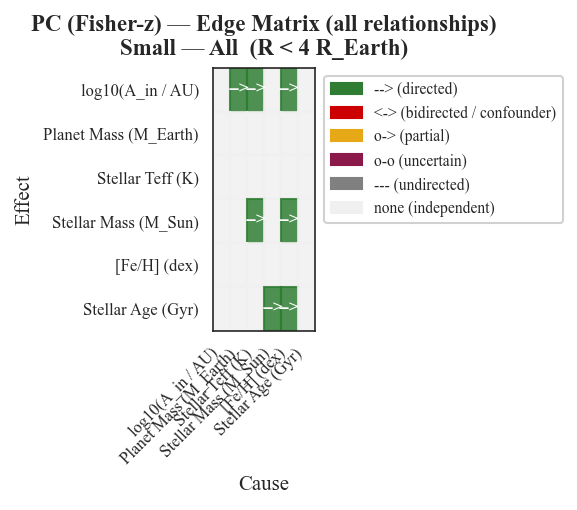

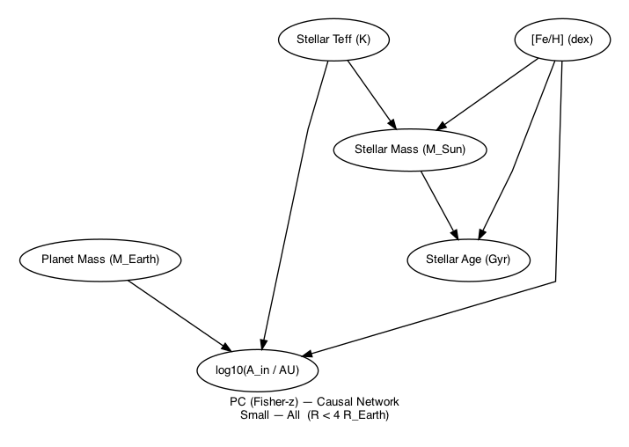

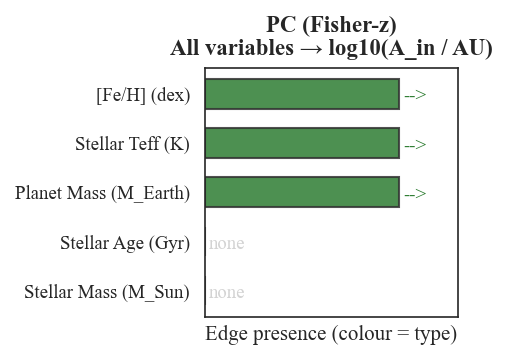


  Running PC (KCI, alpha=0.05) ...

  ──────────────────────────────────────────────────────────────────────
  PC (KCI) — ALL edges found  (total: 8)
  ──────────────────────────────────────────────────────────────────────
  From (cause)           Symbol   To (effect)             Edge type
  ──────────────────────────────────────────────────────────────────────
  Planet Mass (M_Earth)  -->      log10(A_in / AU)        directed  *** involves target ***
  [Fe/H] (dex)           -->      log10(A_in / AU)        directed  *** involves target ***
  Stellar Mass (M_Sun)   ---      Stellar Age (Gyr)       undirected
  Stellar Mass (M_Sun)   ---      [Fe/H] (dex)            undirected
  [Fe/H] (dex)           ---      Stellar Age (Gyr)       undirected
  Stellar Teff (K)       ---      Stellar Age (Gyr)       undirected
  Stellar Teff (K)       ---      Stellar Mass (M_Sun)    undirected
  Stellar Teff (K)       ---      [Fe/H] (dex)            undirected


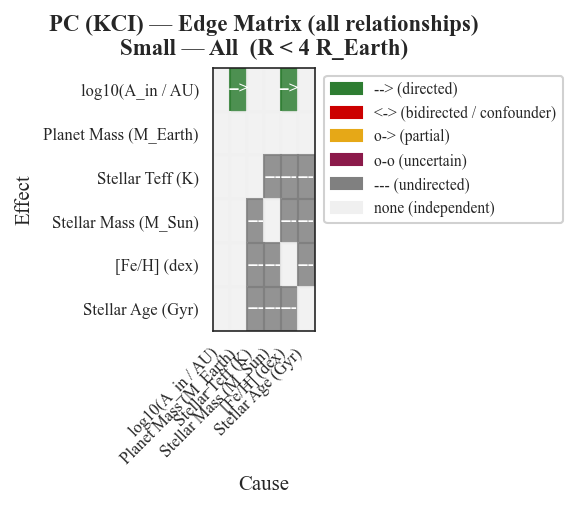

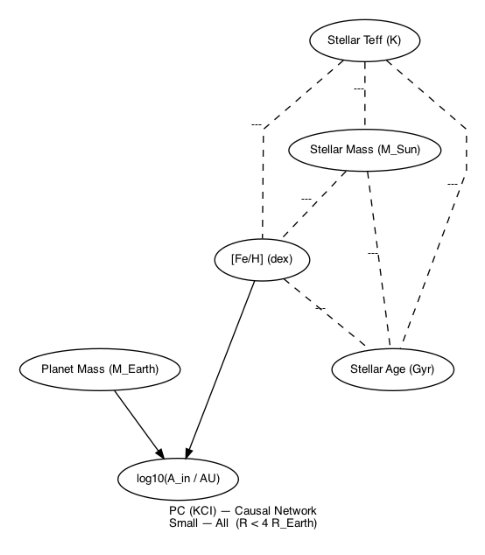

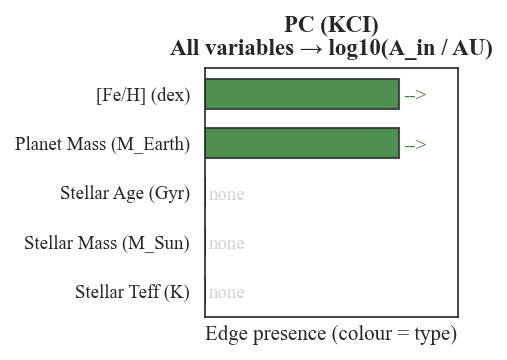


#################################################################
  METHOD 2 — DirectLiNGAM + Bootstrap
#################################################################

  ALL directed edges shown. B[i,j] = standardised effect of j on i.
  Bootstrap freq >= 0.7 = stable under resampling (marked *).
  Prior: log_Ain cannot cause other variables.


  Fitting DirectLiNGAM ...
  Causal order: ['st_met', 'st_age', 'st_teff', 'st_mass', 'pl_bmasse', 'log_Ain']
  Bootstrap (300 iterations) ... done.

  ────────────────────────────────────────────────────────────────────────────────
  DirectLiNGAM — ALL directed edges  (bootstrap-mean B[i,j] = effect of variable j on variable i)
  ────────────────────────────────────────────────────────────────────────────────
  Cause              Effect              Boot mean   Freq          95% bootstrap CI  Freq≥thr?  CI excludes 0?
  ────────────────────────────────────────────────────────────────────────────────
  Stellar Age (Gyr)  Stellar Teff (K)    

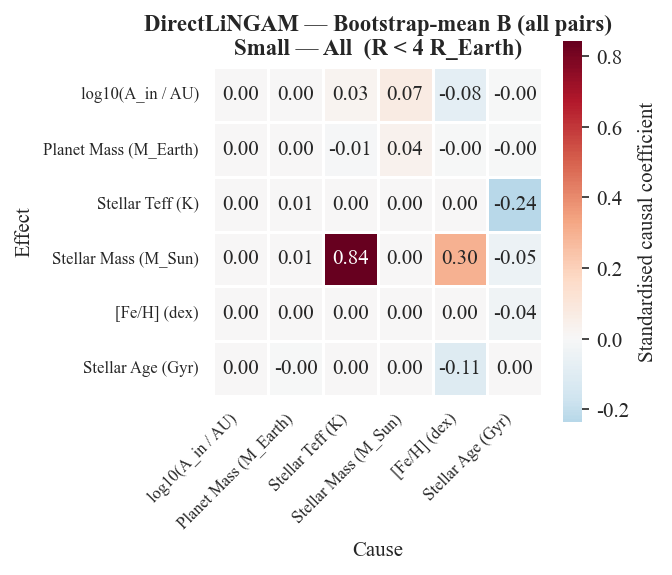

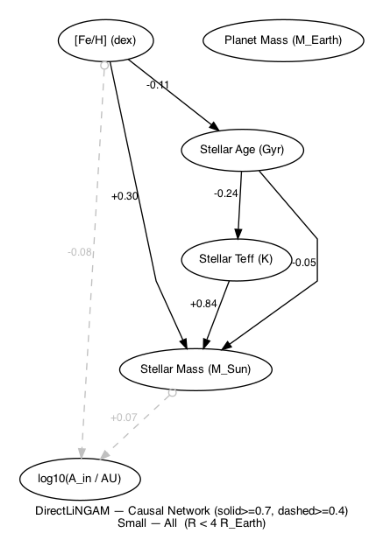

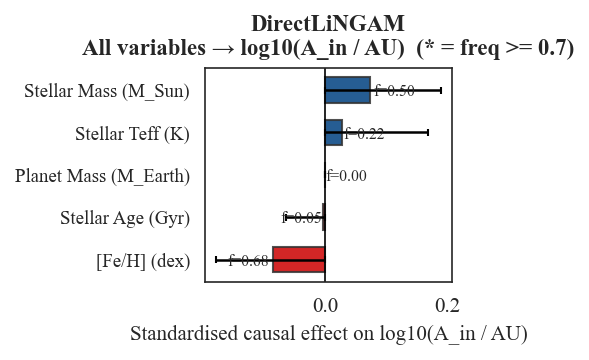


  Structural Equations — DirectLiNGAM  (bootstrap mean coefficients, standardised)
  Active threshold: freq >= 0.7  |  |coeff| > 0.01

  log10(A_in / AU) = ε  (no active causal parents)

  Planet Mass (M_Earth) = ε  (no active causal parents)

  Stellar Teff (K) =
      -0.237·Stellar Age (Gyr) + ε
      [Stellar Age (Gyr): coeff=-0.237, 95% CI=[-0.290,-0.187], freq=1.00] 

  Stellar Mass (M_Sun) =
      +0.843·Stellar Teff (K) +0.299·[Fe/H] (dex) -0.049·Stellar Age (Gyr) + ε
      [Stellar Teff (K): coeff=+0.843, 95% CI=[+0.822,+0.865], freq=1.00] 
      [[Fe/H] (dex): coeff=+0.299, 95% CI=[+0.273,+0.321], freq=1.00] 
      [Stellar Age (Gyr): coeff=-0.049, 95% CI=[-0.070,-0.028], freq=0.99] 

  [Fe/H] (dex) = ε  (no active causal parents)

  Stellar Age (Gyr) =
      -0.107·[Fe/H] (dex) + ε
      [[Fe/H] (dex): coeff=-0.107, 95% CI=[-0.204,+0.000], freq=0.73] 


#################################################################
  METHOD 3 — FCI (Fast Causal Inference)
###############

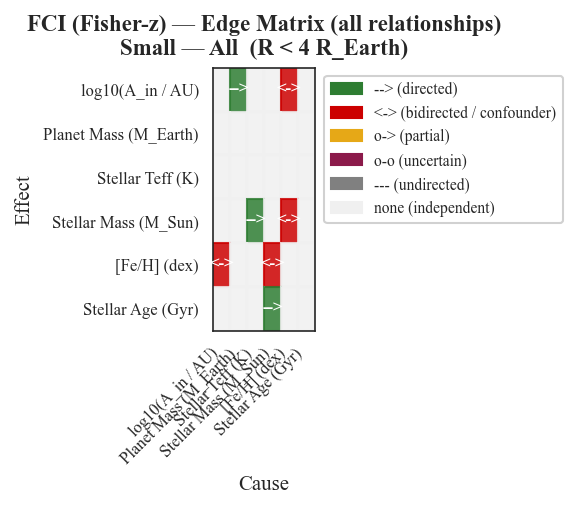

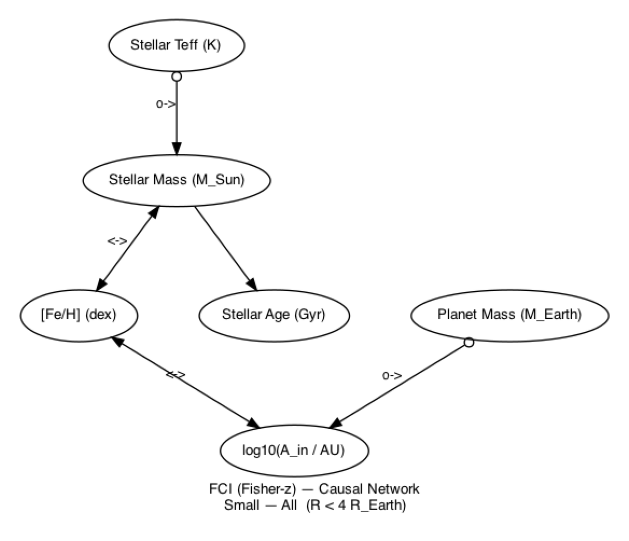

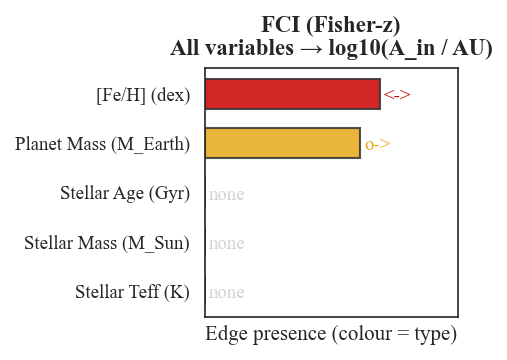


  Running FCI (KCI, alpha=0.05) ...
st_met --> st_teff
st_met --> st_age

  ──────────────────────────────────────────────────────────────────────
  FCI (KCI) — ALL edges found  (total: 8)
  ──────────────────────────────────────────────────────────────────────
  From (cause)           Symbol   To (effect)             Edge type
  ──────────────────────────────────────────────────────────────────────
  log10(A_in / AU)       <->      [Fe/H] (dex)            bidirected  *** involves target ***
  Planet Mass (M_Earth)  o->      log10(A_in / AU)        partial  *** involves target ***
  Stellar Mass (M_Sun)   -->      Stellar Age (Gyr)       directed
  Stellar Mass (M_Sun)   o->      [Fe/H] (dex)            partial
  Stellar Mass (M_Sun)   -->      Stellar Teff (K)        directed
  [Fe/H] (dex)           -->      Stellar Age (Gyr)       directed
  [Fe/H] (dex)           -->      Stellar Teff (K)        directed
  Stellar Teff (K)       o-o      Stellar Age (Gyr)       uncertain


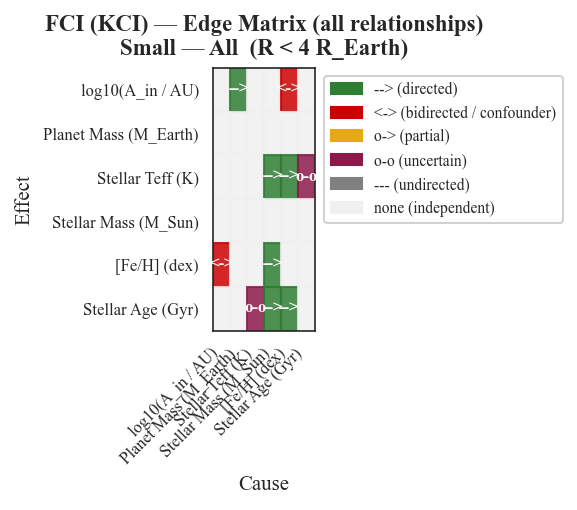

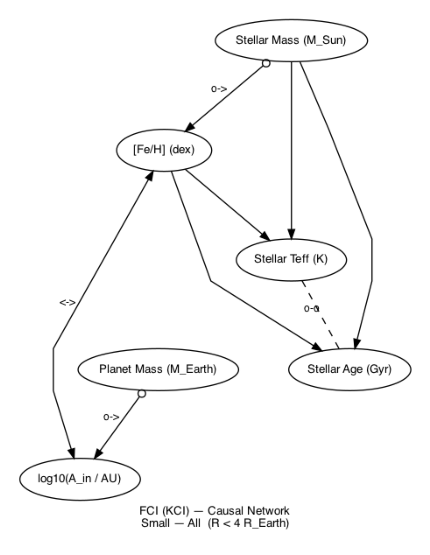

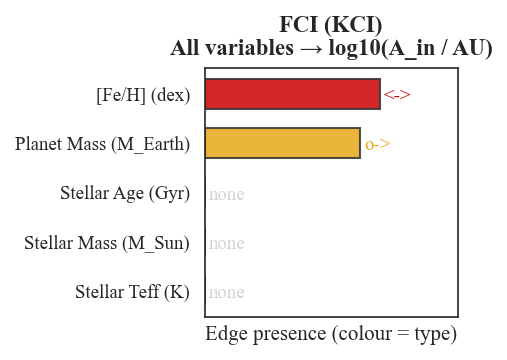

  Interpretation Guide

  PC
    Causal skeleton + partial orientations across all variable pairs.
    Fisher-z vs KCI differences reveal non-linear dependencies.

  DirectLiNGAM
    Complete directed graph with standardised coefficients.
    B[i,j]: direct effect of j on i (standardised to zero-mean, unit-SD).
    Bootstrap freq >= 0.7 = stable under resampling (marked *).
    Positive coefficient -> larger inner semi-major axis; negative -> smaller.
    ALL variable pairs reported; target (log_Ain) edges additionally
    shown with partial R² to indicate explained variance.

  FCI
    Complete PAG across all variable pairs.
    <-> is compatible with latent confounding for that pair under FCI
    assumptions; it does not identify a specific hidden common cause.
    Compare with LiNGAM: if LiNGAM finds X -> Y but FCI shows X <-> Y,
    the LiNGAM edge may reflect a latent confounder.

  Most trustworthy edges:
    Appear in PC (both tests) AND LiNGAM (high freq) AND FCI (-->)
    acro

In [10]:
# ============================================================================
# Exoplanet Inner-Boundary Semi-major Axis — Causal Discovery
# ============================================================================
#
# Question
# --------
# Which stellar and planetary properties causally influence the inner-boundary
# semi-major axis, and what are the directions and strengths of those effects?
# What is the full causal structure among all variables in the system?
#
# Three complementary methods
# ---------------------------
#   1. PC  (constraint-based, run twice)
#      Conditional-independence skeleton + partial directions.
#      Fisher-z : parametric, appropriate for approximately linear relations.
#      KCI      : kernel-based, non-parametric, captures non-linearities.
#
#   2. DirectLiNGAM  (function-based)
#      Exploits non-Gaussianity to identify ALL edge directions and magnitudes.
#      Primary method for quantitative causal coefficients.
#      Built-in bootstrap (N=300) assesses edge stability.
#      Prior constraint: log_Ain is forced to be a sink node.
#
#   3. FCI  (constraint-based, run twice, allows latent confounders)
#      Like PC but explicitly allows unmeasured common causes.
#      Bidirected edges (<->) can be consistent with latent confounding under
#      the FCI assumptions; they do not identify a specific hidden variable.
#
# Analysis sample
# ---------------
#   All retained systems; no multiplicity-based subgroup analysis.
#
# Output structure (All-systems sample, per method)
# ------------------------------
#   (a) Text table     : ALL pairwise edges found
#   (b) Edge matrix    : p×p colour-coded heatmap of ALL relationships
#   (c) Causal network : Graphviz DAG of ALL edges
#   (d) Effects on log_Ain : dedicated bar chart for the target variable
#
# Variable set — aligned with the All-systems ML pipeline (ML_all.py)
# --------------------------------------------------------
# Internal name | Source column | Transform | Reason
# ─────────────────────────────────────────────────────────────────────────
# log_Ain       | pl_orbsmax     | log10     | ML target; A_in in AU
# pl_bmasse     | pl_bmasse      | none      | ML feature; M_Earth
# st_teff       | st_teff        | none      | ML feature; FGK range
# st_mass       | st_mass        | none      | ML feature; M_Sun
# st_met        | st_met         | none      | ML feature; [Fe/H]
# st_age        | st_age         | none      | ML feature; Gyr
#
# Edge symbols
# ------------
#   -->   directed, no hidden confounder on tail side
#   <->   bidirected = strong evidence of hidden common cause
#   o->   partially oriented; tail-side direction uncertain
#   o-o   both endpoints uncertain
#   ---   undirected (Markov-equivalent orientations)
#   none  no edge (conditional independence)
#
# Prerequisites
# -------------
#   ML_all.py pipeline must have been run first.
#   small_all must exist in memory (one row per system, inner-boundary planet).
#   pip install causal-learn graphviz
# ============================================================================

# ── 1. IMPORTS ──────────────────────────────────────────────────────────────

import warnings
from warnings import simplefilter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
import seaborn as sns
import statsmodels.api as sm

from scipy.stats import shapiro
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

from causallearn.search.ConstraintBased.PC  import pc
from causallearn.search.ConstraintBased.FCI import fci
from causallearn.search.FCMBased.lingam import DirectLiNGAM
from causallearn.search.FCMBased.lingam.utils import make_prior_knowledge
from causallearn.utils.cit import fisherz, kci
from causallearn.graph.Endpoint import Endpoint

simplefilter(action='ignore', category=FutureWarning)
simplefilter(action='ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=UserWarning)


# ── 2. SETTINGS ─────────────────────────────────────────────────────────────

ALPHA        = 0.05
BOOT_N       = 300
MIN_EFFECT   = 0.01
PROB_THR     = 0.7     # bootstrap frequency threshold for LiNGAM plotting
WEAK_THR     = 0.4     # lower bound — edges shown as dashed weak lines
RANDOM_STATE = 42

sns.set_style('white')
plt.rcParams['font.family']        = 'serif'
plt.rcParams['font.serif']         = ['Times New Roman', 'DejaVu Serif']
plt.rcParams['mathtext.fontset']   = 'custom'
plt.rcParams['mathtext.rm']        = 'Times New Roman'
plt.rcParams['mathtext.it']        = 'Times New Roman:italic'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi']         = 150


# ── 3. VARIABLE DEFINITIONS ─────────────────────────────────────────────────
# The feature columns and their transforms match ML.py exactly: the six ML
# predictors remain on their catalogue scales, while only the A_in target is
# transformed to log10, as in the ML target construction.

MAIN_VAR_DEFS = {                    # ML-aligned six-variable causal model
    'log_Ain'   : ('pl_orbsmax', 'log10'),
    'pl_bmasse' : ('pl_bmasse', 'none'),
    'st_teff'   : ('st_teff',   'none'),
    'st_mass'   : ('st_mass',   'none'),
    'st_met'    : ('st_met',    'none'),
    'st_age'    : ('st_age',    'none'),
}

# This file analyses the All-systems sample only.
VAR_DEFS  = MAIN_VAR_DEFS.copy()
VAR_ORDER = list(VAR_DEFS.keys())

LABELS = {
    'log_Ain'   : 'log10(A_in / AU)',
    'pl_bmasse' : 'Planet Mass (M_Earth)',
    'st_teff'   : 'Stellar Teff (K)',
    'st_mass'   : 'Stellar Mass (M_Sun)',
    'st_met'    : '[Fe/H] (dex)',
    'st_age'    : 'Stellar Age (Gyr)',
}

def lbl(col):
    return LABELS.get(col, col)

EDGE_COLORS = {
    'directed'   : '#2e7d32',
    'bidirected' : '#cc0000',
    'partial'    : '#e6a817',
    'uncertain'  : '#8b1a4a',
    'undirected' : 'grey',
    'none'       : 'lightgrey',
}

EDGE_TYPE_COLOR = {
    '-->' : '#2e7d32',
    '<->': '#cc0000',
    'o->' : '#e6a817',
    'o-o' : '#8b1a4a',
    '---' : 'grey',
    'none': '#f0f0f0',
}


# ── 4. DATA PREPARATION ─────────────────────────────────────────────────────

def safe_log10(s):
    s = s.copy().astype(float)
    s[~(s > 0)] = np.nan
    return np.log10(s)


def build_analysis_df(df_in):
    """Build CI DataFrame from small_all using transforms in VAR_DEFS."""
    missing = [src for _, (src, _) in VAR_DEFS.items()
               if src not in df_in.columns]
    if missing:
        raise KeyError(f"Source columns missing from small_all: {missing}")
    data = {}
    for var, (src, tfm) in VAR_DEFS.items():
        data[var] = safe_log10(df_in[src]) if tfm == 'log10' \
                    else df_in[src].values.astype(float)
    df = pd.DataFrame(data, index=df_in.index)
    return df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)


# ── 5. DISTRIBUTION & ASSUMPTION CHECKS ─────────────────────────────────────

def print_distribution_summary(df_raw, df):
    print('\n' + '='*70)
    print('  Distribution Summary — Raw vs Transformed')
    print('='*70)
    print(f"  {'Variable':<12} {'Source':<12} {'Transform':<8} "
          f"{'Skew(raw)':>10} {'Skew(tfm)':>10}")
    print(f"  {'─'*56}")
    for var, (src, tfm) in VAR_DEFS.items():
        if src not in df_raw.columns:
            continue
        raw = pd.to_numeric(df_raw[src], errors='coerce').dropna()
        print(f"  {var:<12} {src:<12} {tfm:<8} "
              f"{raw.skew():>10.3f} {df[var].dropna().skew():>10.3f}")
    print(f"\n  Only variables configured with log10 are transformed; compare skewness accordingly.")
    print('='*70)


def check_assumptions(df):
    print('\n' + '='*60)
    print('  Assumption Checks  (primarily for DirectLiNGAM)')
    print('='*60)
    n, p = df.shape
    print(f"\n  [1] Sample size: {n} obs, {p} vars  (ratio {n/p:.1f})")
    print(f"      {'OK' if n/p >= 10 else 'WARNING: recommend >= 10 x n_vars'}")

    print(f"\n  [2] Non-Gaussianity (Shapiro-Wilk, alpha={ALPHA})")
    print(f"      Note: at N>300 almost always rejects normality — directional only.")
    print(f"      {'Variable':<14} {'p-value':>10}  {'Skewness':>10}  Result")
    print(f"      {'─'*50}")
    for c in df.columns:
        _, pv = shapiro(df[c])
        sk    = float(df[c].skew())
        print(f"      {c:<14} {pv:>10.4f}  {sk:>10.3f}  "
              f"{'Non-Gaussian OK' if pv < ALPHA else 'Near-Gaussian'}")

    print(f"\n  [3] Multicollinearity (VIF; <10 acceptable)")
    print(f"      {'Variable':<14} {'VIF':>8}  Result")
    print(f"      {'─'*30}")
    Xsc  = StandardScaler().fit_transform(df)
    vifs = [variance_inflation_factor(Xsc, i) for i in range(p)]
    for c, v in zip(df.columns, vifs):
        print(f"      {c:<14} {v:>8.2f}  {'WARNING' if v > 10 else 'OK'}")
    print(f"\n      Max VIF = {max(vifs):.2f}")
    print('='*60)


def check_linearity(df):
    """
    LiNGAM assumes linear structural equations. For each variable, fit a
    LinearRegression and a GradientBoostingRegressor using all other variables
    as predictors. A large R² gap (nonlinear - linear) suggests the linearity
    assumption may be violated for that variable.

    Interpretation guide:
      gap < 0.05   : linearity broadly acceptable
      0.05 - 0.20  : moderate nonlinearity — interpret LiNGAM with caution
      > 0.20       : strong nonlinearity — LiNGAM linearity assumption at risk
    """
    print('\n' + '='*60)
    print('  [4] Linearity Check  (LinearRegression vs GBT R²)')
    print('  '
          'LiNGAM assumes linear SEMs; large gap = linearity may be violated.')
    print('='*60)
    print(f"  {'Variable':<14} {'R²_linear':>10} {'R²_GBT':>10} "
          f"{'gap':>8}  Result")
    print(f"  {'─'*55}")

    lin  = LinearRegression()
    gbt  = GradientBoostingRegressor(random_state=RANDOM_STATE,
                                     n_estimators=100, max_depth=3)
    gaps = []
    for col in df.columns:
        others = [c for c in df.columns if c != col]
        X, y   = df[others].values, df[col].values
        lin.fit(X, y);  r2l = r2_score(y, lin.predict(X))
        gbt.fit(X, y);  r2g = r2_score(y, gbt.predict(X))
        gap = r2g - r2l
        gaps.append(gap)
        verdict = ('OK'               if gap < 0.05
                   else 'MILD'        if gap < 0.20
                   else 'WARNING')
        print(f"  {col:<14} {r2l:>10.3f} {r2g:>10.3f} {gap:>8.3f}  {verdict}")

    mean_gap = float(np.mean(gaps))
    print(f"\n  Mean gap = {mean_gap:.3f}  "
          f"({'OK — linearity acceptable' if mean_gap < 0.05 else 'MILD — interpret cautiously' if mean_gap < 0.20 else 'WARNING — strong nonlinearity'})")
    print('='*60)


def print_structural_equations(mean_B, ci_low_B, ci_high_B, probs, cols,
                               prob_thr=None, effect_thr=MIN_EFFECT):
    """
    Express the DirectLiNGAM result as a system of structural equations:
        Y = b1*X1 + b2*X2 + ... + e_Y
    where b_i are bootstrap mean coefficients.

    All active edges (freq >= prob_thr) are shown. Variables with no
    incoming active edges are shown as having no detected active parents.
    Coefficients are standardised (zero-mean, unit-SD scale).
    """
    if prob_thr is None:
        prob_thr = PROB_THR
    p = len(cols)
    print('\n' + '='*70)
    print('  Structural Equations — DirectLiNGAM  '
          '(bootstrap mean coefficients, standardised)')
    print(f'  Active threshold: freq >= {prob_thr}  |  '
          f'|coeff| > {effect_thr}')
    print('='*70)
    for i, eff in enumerate(cols):
        terms = []
        for j, cau in enumerate(cols):
            if i == j:
                continue
            pij   = probs[i, j]
            coeff = mean_B[i, j]
            if pij >= prob_thr and abs(coeff) > effect_thr:
                ci_lo = ci_low_B[i, j]
                ci_hi = ci_high_B[i, j]
                terms.append((abs(coeff), cau, coeff, pij, ci_lo, ci_hi))
        # Sort by |coefficient| descending
        terms.sort(key=lambda t: -t[0])
        if terms:
            eq_parts = ' '.join(f'{c:+.3f}·{lbl(cau)}'
                                for _, cau, c, *_ in terms)
            print(f"\n  {lbl(eff)} =")
            print(f"      {eq_parts} + ε")
            for _, cau, c, pij, ci_lo, ci_hi in terms:
                marker = '***' if 'log_Ain' in (eff, cau) else ''
                print(f"      [{lbl(cau)}: coeff={c:+.3f}, "
                      f"95% CI=[{ci_lo:+.3f},{ci_hi:+.3f}], "
                      f"freq={pij:.2f}] {marker}")
        else:
            print(f"\n  {lbl(eff)} = ε  (no active causal parents)")
    print('\n' + '='*70)


# ── 6. EDGE DECODING ────────────────────────────────────────────────────────

def _decode_edge(e):
    """Convert a causal-learn Edge to a standardised dict."""
    n1  = e.get_node1().get_name()
    n2  = e.get_node2().get_name()
    ep1 = e.get_endpoint1().name
    ep2 = e.get_endpoint2().name
    if   ep1=='TAIL'   and ep2=='ARROW':  return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='-->',edge_type='directed',  direction='n1_to_n2')
    elif ep1=='ARROW'  and ep2=='TAIL':   return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='<--',edge_type='directed',  direction='n2_to_n1')
    elif ep1=='ARROW'  and ep2=='ARROW':  return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='<->',edge_type='bidirected',direction='both')
    elif ep1=='CIRCLE' and ep2=='ARROW':  return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='o->',edge_type='partial',   direction='n1_to_n2')
    elif ep1=='ARROW'  and ep2=='CIRCLE': return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='<-o',edge_type='partial',   direction='n2_to_n1')
    elif ep1=='CIRCLE' and ep2=='CIRCLE': return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='o-o',edge_type='uncertain', direction='uncertain')
    elif ep1=='TAIL'   and ep2=='TAIL':   return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol='---',edge_type='undirected',direction='undirected')
    else: return dict(n1=n1,n2=n2,ep1=ep1,ep2=ep2,symbol=f'{ep1}-{ep2}',edge_type='other',direction='unknown')


def build_edge_matrix(decoded_edges, var_order):
    """p×p DataFrame: M[i,j] = symbol of edge from col-variable to row-variable."""
    idx = {v: i for i, v in enumerate(var_order)}
    M   = [['none']*len(var_order) for _ in range(len(var_order))]
    for d in decoded_edges:
        i1=idx.get(d['n1'],-1); i2=idx.get(d['n2'],-1)
        if i1<0 or i2<0: continue
        if   d['direction']=='n1_to_n2':  M[i2][i1]='-->'
        elif d['direction']=='n2_to_n1':  M[i1][i2]='-->'
        elif d['direction']=='both':       M[i2][i1]='<->'; M[i1][i2]='<->'
        elif d['direction']=='undirected': M[i2][i1]='---'; M[i1][i2]='---'
        elif d['direction']=='uncertain':  M[i2][i1]='o-o'; M[i1][i2]='o-o'
    return pd.DataFrame(M, index=var_order, columns=var_order)


# ── 7. TEXT OUTPUT — ALL EDGES ───────────────────────────────────────────────

def print_all_edges_text(decoded_edges, method_name):
    """
    Print ALL pairwise edges found by the method in readable form.
    Edges involving log_Ain are marked; all others are shown too.
    """
    if not decoded_edges:
        print(f"\n  {method_name}: No edges found.")
        return
    print(f"\n  {'─'*70}")
    print(f"  {method_name} — ALL edges found  (total: {len(decoded_edges)})")
    print(f"  {'─'*70}")
    print(f"  {'From (cause)':<22} {'Symbol':<8} {'To (effect)':<22}  Edge type")
    print(f"  {'─'*70}")

    rows = []
    for d in decoded_edges:
        sym = d['symbol']
        if   d['direction']=='n1_to_n2':  rows.append((d['n1'],sym,   d['n2'],d['edge_type']))
        elif d['direction']=='n2_to_n1':  rows.append((d['n2'],'-->',  d['n1'],d['edge_type']))
        elif d['direction']=='both':       rows.append((d['n1'],'<->',  d['n2'],d['edge_type']))
        elif d['direction']=='undirected': rows.append((d['n1'],'---',  d['n2'],d['edge_type']))
        else:                              rows.append((d['n1'],sym,   d['n2'],d['edge_type']))

    # Sort: edges involving log_Ain first, then alphabetical
    rows.sort(key=lambda r: (0 if 'log_Ain' in (r[0],r[2]) else 1, r[0], r[2]))
    for fr, sym, to, et in rows:
        marker = '  *** involves target ***' if 'log_Ain' in (fr,to) else ''
        print(f"  {lbl(fr):<22} {sym:<8} {lbl(to):<22}  {et}{marker}")


def print_lingam_all_edges(mean_B, ci_low_B, ci_high_B, probs, cols):
    """
    Print the complete DirectLiNGAM B matrix as a directed edge list.
    Shows ALL edges (not just those into log_Ain) with coefficient,
    bootstrap frequency, and 95% CI.
    """
    p = len(cols)
    print(f"\n  {'─'*80}")
    print(f"  DirectLiNGAM — ALL directed edges  "
          f"(bootstrap-mean B[i,j] = effect of variable j on variable i)")
    print(f"  {'─'*80}")
    print(f"  {'Cause':<18} {'Effect':<18} {'Boot mean':>10} {'Freq':>6} "
          f"{'95% bootstrap CI':>25} {'Freq≥thr?':>10} {'CI excludes 0?':>15}")
    print(f"  {'─'*80}")

    rows = []
    for i in range(p):
        for j in range(p):
            if i == j:
                continue
            coeff = mean_B[i, j]
            if abs(coeff) < MIN_EFFECT and probs[i, j] < 0.1:
                continue      # skip truly zero edges
            pij = probs[i, j]
            ci  = f"[{ci_low_B[i,j]:+.3f}, {ci_high_B[i,j]:+.3f}]"
            rows.append((pij, cols[j], cols[i], coeff, pij, ci))

    # Sort by frequency descending, then by cause name
    rows.sort(key=lambda r: (-r[0], r[1]))
    for _, cau, eff, coeff, pij, ci in rows:
        freq_active = 'Yes' if pij >= PROB_THR else 'No'
        lo, hi = ci_low_B[cols.index(eff), cols.index(cau)], \
                 ci_high_B[cols.index(eff), cols.index(cau)]
        ci_excludes_zero = 'Yes' if lo > 0 or hi < 0 else 'No'
        marker = '  *** target ***' if eff == 'log_Ain' else ''
        print(f"  {lbl(cau):<18} {lbl(eff):<18} {coeff:>10.3f} {pij:>6.2f} "
              f"{ci:>25} {freq_active:>10} {ci_excludes_zero:>15}{marker}")


# ── 8. SHARED VISUALISATION ─────────────────────────────────────────────────

def plot_adjacency_heatmap(edge_matrix, title, method_name):
    """
    p×p colour-coded edge matrix showing ALL pairwise relationships.
    Used for PC and FCI (symbol-based).
    DirectLiNGAM uses a separate numeric heatmap in plot_lingam_all().
    """
    var_order = list(edge_matrix.index)
    p         = len(var_order)
    labels    = [lbl(v) for v in var_order]

    fig, ax = plt.subplots(figsize=(4, 3.5))
    for i in range(p):
        for j in range(p):
            sym = edge_matrix.iloc[i, j]
            col = EDGE_TYPE_COLOR.get(sym, '#f0f0f0')
            ax.add_patch(plt.Rectangle([j, p-1-i], 1, 1, color=col, alpha=0.85))
            if sym != 'none' and i != j:
                ax.text(j+0.5, p-1-i+0.5, sym,
                        ha='center', va='center', fontsize=8,
                        fontweight='bold', color='white')

    ax.set_xlim(0,p); ax.set_ylim(0,p)
    ax.set_xticks(np.arange(p)+0.5); ax.set_yticks(np.arange(p)+0.5)
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
    ax.set_yticklabels(labels[::-1], fontsize=8)
    ax.set_xlabel('Cause', fontsize=10); ax.set_ylabel('Effect', fontsize=10)
    ax.set_title(f'{method_name} — Edge Matrix (all relationships)\n{title}',
                 fontsize=11, fontweight='bold')
    legend_handles = [
        mpatches.Patch(color='#2e7d32', label='--> (directed)'),
        mpatches.Patch(color='#cc0000', label='<-> (bidirected / confounder)'),
        mpatches.Patch(color='#e6a817', label='o-> (partial)'),
        mpatches.Patch(color='#8b1a4a', label='o-o (uncertain)'),
        mpatches.Patch(color='grey',    label='--- (undirected)'),
        mpatches.Patch(color='#f0f0f0', label='none (independent)'),
    ]
    ax.legend(handles=legend_handles, loc='upper left',
              bbox_to_anchor=(1.02, 1), fontsize=7.5, framealpha=0.9)
    plt.tight_layout()
    plt.show()


def plot_causal_network(decoded_edges, var_order, title, method_name,
                        prob_thr=None):
    """
    Graphviz DAG of ALL edges (or those above prob_thr for LiNGAM).
    log_Ain at the bottom (sink); cause variables above.
    Edge labels: coefficient for LiNGAM; edge symbol for PC/FCI.
    """
    import graphviz as gv, io as _io

    # Split into strong (solid) and weak (dashed grey) edges
    # For PC/FCI (no prob field), all edges are treated as strong
    strong_edges = [d for d in decoded_edges
                    if prob_thr is None or d.get('prob', 1.0) >= prob_thr]
    weak_edges   = [d for d in decoded_edges
                    if prob_thr is not None
                    and WEAK_THR <= d.get('prob', 1.0) < prob_thr]

    thr_str     = f' (solid>={prob_thr}, dashed>={WEAK_THR})' if prob_thr else ''
    graph_title = f'{method_name} — Causal Network{thr_str}\\n{title}'

    lines = [
        'digraph {',
        f'  graph [rankdir=TB nodesep=0.6 ranksep=0.8 splines=polyline'
        f' fontname="Times New Roman" label="{graph_title}" labelloc=b fontsize=10]',
        '  node  [shape=ellipse style=filled fillcolor=white'
        ' fontname="Times New Roman" fontsize=10]',
        '  edge  [fontname="Times New Roman" fontsize=9 arrowsize=0.8]',
    ]
    # Place log_Ain at the bottom rank
    lines.append('  { rank=sink; "log_Ain" }')
    for v in var_order:
        lines.append(f'  "{v}" [label="{lbl(v)}"]')

    def _edge_dot(d, weak=False):
        n1, n2 = d['n1'], d['n2']
        coef   = d.get('mean', None)
        sym    = d.get('symbol', '-->')
        dir_   = d['direction']
        edge_lbl = (f'{coef:+.2f}' if coef is not None and abs(coef) >= MIN_EFFECT
                    else (sym if sym not in ('-->', '<--', 'none') else ''))
        ws = ' style=dashed color=grey fontcolor=grey' if weak else ''
        extra = ws
        if d.get('edge_type') == 'bidirected':
            extra = f' dir=both arrowhead=normal arrowtail=normal{ws}'
        elif d.get('edge_type') in ('undirected', 'uncertain'):
            extra = f' dir=none style=dashed{" color=grey fontcolor=grey" if weak else ""}'
        elif d.get('edge_type') == 'partial':
            extra = f' arrowtail=odot dir=both{ws}'
        if   dir_ == 'n1_to_n2': lines.append(f'  "{n1}" -> "{n2}" [xlabel="{edge_lbl}"{extra}]')
        elif dir_ == 'n2_to_n1': lines.append(f'  "{n2}" -> "{n1}" [xlabel="{edge_lbl}"{extra}]')
        else:                     lines.append(f'  "{n1}" -> "{n2}" [xlabel="{edge_lbl}"{extra}]')

    for d in strong_edges:
        _edge_dot(d, weak=False)
    for d in weak_edges:
        _edge_dot(d, weak=True)

    lines.append('}')
    dot_src = '\n'.join(lines)

    try:
        png_bytes = gv.Source(dot_src).pipe(format='png')
    except Exception as e:
        print(f"  Graphviz render failed: {e}")
        print("  Install: conda install -c conda-forge graphviz")
        return

    img = plt.imread(_io.BytesIO(png_bytes))
    fig, ax = plt.subplots(figsize=(4, 3.5))
    ax.imshow(img); ax.set_axis_off()
    plt.tight_layout(pad=0)
    plt.show()


def plot_effects_on_target(decoded_edges, target, var_order,
                           title, method_name,
                           lingam_edge_df=None, mean_B=None,
                           ci_low_B=None, ci_high_B=None,
                           probs=None, pr2_df=None):
    """
    Dedicated bar chart for the target variable (log_Ain) only.
    LiNGAM: shows mean coefficient + 95% CI for ALL source variables,
             regardless of PROB_THR, sorted by coefficient value.
             Right panel: partial R² for active edges.
    PC/FCI: shows edge-type indicator for all variables.
    """
    sources = [v for v in var_order if v != target]

    if mean_B is not None:
        # Build rows for all sources from the bootstrap-mean B matrix.
        cols   = var_order
        ti     = cols.index(target)
        rows   = []
        for src in sources:
            si  = cols.index(src)
            m   = mean_B[ti, si]
            p   = probs[ti, si]
            rows.append(dict(source=src, mean=m,
                             ci_lo=ci_low_B[ti, si],
                             ci_hi=ci_high_B[ti, si], prob=p,
                             active=p >= PROB_THR))
        df_rows = pd.DataFrame(rows).sort_values('mean', ascending=True)

        has_pr2 = pr2_df is not None and not pr2_df.empty
        ncols   = 2 if has_pr2 else 1
        fig, axes = plt.subplots(1, ncols,
                                 figsize=(5 if ncols==2 else 3.25, 2.5))
        if ncols == 1: axes = [axes]

        ax = axes[0]
        colors = ['#004080' if v >= 0 else '#cc0000' for v in df_rows['mean']]
        ax.barh(range(len(df_rows)), df_rows['mean'],
                color=colors, edgecolor='#333', height=0.6, alpha=0.85)
        for i, (_, r) in enumerate(df_rows.iterrows()):
            # A percentile interval need not contain the bootstrap mean.
            # Draw the interval directly instead of using asymmetric xerr.
            ax.hlines(i, r['ci_lo'], r['ci_hi'], color='black', lw=1.2)
            ax.vlines([r['ci_lo'], r['ci_hi']], i - 0.08, i + 0.08,
                      color='black', lw=1.0)
            offset = max(abs(r['mean']), 0.01) * 0.08
            ha     = 'left' if r['mean'] >= 0 else 'right'
            flag   = '*' if r['active'] else ''
            ax.text(r['mean'] + (offset if r['mean']>=0 else -offset),
                    i - 0.05, f"f={r['prob']:.2f}{flag}",
                    va='center', fontsize=7.5, ha=ha)
        ax.axvline(0, color='k', lw=0.8)
        ax.set_yticks(range(len(df_rows)))
        ax.set_yticklabels([lbl(c) for c in df_rows['source']], fontsize=9)
        ax.set_xlabel(f"Standardised causal effect on {lbl(target)}", fontsize=10)
        ax.set_title(f'{method_name}\nAll variables → {lbl(target)}'
                     f'  (* = freq >= {PROB_THR})', fontsize=11, fontweight='bold')

        if has_pr2:
            ax2 = axes[1]
            y_order  = list(df_rows['source'])
            pr2_vals = [pr2_df.loc[pr2_df['source']==s,'partial_R2'].values[0]
                        if s in pr2_df['source'].values else 0.0
                        for s in y_order]
            ax2.barh(range(len(y_order)), pr2_vals,
                     color='steelblue', edgecolor='#333', height=0.6)
            for i, v in enumerate(pr2_vals):
                if v > 0:
                    ax2.text(v+0.002, i-0.05, f'{v:.3f}', va='center', fontsize=7.5)
            ax2.set_yticks(range(len(y_order)))
            ax2.set_yticklabels([lbl(s) for s in y_order], fontsize=9)
            ax2.set_xlabel('Partial R²', fontsize=10)
            ax2.set_title('Partial R² of causal parents', fontsize=11, fontweight='bold')

    else:
        # PC / FCI: colour-coded presence indicator
        rows = []
        for src in sources:
            rel='none'; et='none'
            for d in decoded_edges:
                if {d['n1'],d['n2']} == {src,target}:
                    rel=d['symbol']; et=d['edge_type']; break
            rows.append(dict(source=src, rel=rel, et=et,
                             bar_val={'directed':1.0,'partial':0.8,
                                      'bidirected':0.9,'uncertain':0.6,
                                      'undirected':0.5,'none':0.0}.get(et,0.0)))
        df_rows = pd.DataFrame(rows).sort_values('bar_val', ascending=True)

        fig, ax = plt.subplots(figsize=(3.25, 2.5))
        bar_colors = [EDGE_COLORS.get(et,'lightgrey') for et in df_rows['et']]
        ax.barh(range(len(df_rows)), df_rows['bar_val'],
                color=bar_colors, edgecolor='#333', height=0.6, alpha=0.85)
        for i, (_, r) in enumerate(df_rows.iterrows()):
            txt = r['rel'] if r['rel']!='none' else 'none'
            col = EDGE_COLORS.get(r['et'], 'grey')
            ax.text(r['bar_val']+0.02 if r['bar_val']>0 else 0.02,
                    i-0.05, txt, va='center', fontsize=9, color=col)
        ax.set_xlabel('Edge presence (colour = type)', fontsize=10)
        ax.set_xlim(0, 1.3); ax.set_xticks([])
        ax.set_yticks(range(len(df_rows)))
        ax.set_yticklabels([lbl(c) for c in df_rows['source']], fontsize=9)
        ax.set_title(f'{method_name}\nAll variables → {lbl(target)}',
                     fontsize=11, fontweight='bold')

    plt.tight_layout()
    plt.show()


# ══════════════════════════════════════════════════════════════════════════════
# ── 9. METHOD 1 — PC ─────────────────────────────────────────────────────────
# ══════════════════════════════════════════════════════════════════════════════

def run_pc_full(df, test_name, test_fn, alpha=ALPHA):
    X  = df[VAR_ORDER].values
    if test_name.lower() == 'kci':
        # KCI is scale-sensitive; the variables use heterogeneous units.
        X = StandardScaler().fit_transform(X)
    print(f"\n  Running PC ({test_name}, alpha={alpha}) ...")
    cg = pc(X, alpha=alpha, indep_test=test_fn,
            node_names=VAR_ORDER, show_progress=False)
    decoded = [_decode_edge(e) for e in cg.G.get_graph_edges()]
    print_all_edges_text(decoded, f'PC ({test_name})')
    return decoded, cg


def plot_pc_all(decoded, test_name, title):
    """Edge matrix (all) + causal network (all) + effects on log_Ain."""
    emat = build_edge_matrix(decoded, VAR_ORDER)
    plot_adjacency_heatmap(emat,   title, f'PC ({test_name})')
    plot_causal_network(decoded, VAR_ORDER, title, f'PC ({test_name})')
    plot_effects_on_target(decoded, 'log_Ain', VAR_ORDER,
                           title, f'PC ({test_name})')


# ══════════════════════════════════════════════════════════════════════════════
# ── 10. METHOD 2 — DIRECTLINGAM ──────────────────────────────────────────────
# ══════════════════════════════════════════════════════════════════════════════

def _make_prior(cols):
    idx      = {c: i for i, c in enumerate(cols)}
    no_paths = [(idx['log_Ain'], j)
                for j in range(len(cols)) if j != idx['log_Ain']] \
               if 'log_Ain' in idx else []
    return make_prior_knowledge(len(cols), no_paths=no_paths)


def compute_partial_r2(df, active_sources, target='log_Ain', freq_thr=PROB_THR):
    """Partial R² for each active causal parent of log_Ain."""
    if not active_sources:
        return pd.DataFrame()
    sub = df[[target] + active_sources].dropna()
    if len(sub) < max(50, 2*len(active_sources)+5):
        return pd.DataFrame()
    Xr = (sub[active_sources]-sub[active_sources].mean()) / sub[active_sources].std(ddof=0)
    yr = (sub[target]-sub[target].mean()) / sub[target].std(ddof=0)
    rss_full = ((yr - sm.OLS(yr, sm.add_constant(Xr)).fit().fittedvalues)**2).sum()
    out = []
    for src in active_sources:
        Xred    = Xr.drop(columns=[src])
        rss_red = ((yr - sm.OLS(yr, sm.add_constant(Xred)).fit().fittedvalues)**2).sum()
        out.append({'source': src, 'partial_R2': max(0.0, 1-rss_full/rss_red)})
    return pd.DataFrame(out)


def run_directlingam_full(df):
    """
    Fit DirectLiNGAM + Bootstrap.
    Returns bootstrap-mean B, percentile CI bounds, frequencies, and outputs.
    """
    cols = VAR_ORDER
    X    = StandardScaler().fit_transform(df[cols])
    pk   = _make_prior(cols)

    print(f"\n  Fitting DirectLiNGAM ...")
    model = DirectLiNGAM(prior_knowledge=pk, random_state=RANDOM_STATE)
    model.fit(X)
    print(f"  Causal order: {[cols[i] for i in model.causal_order_]}")

    print(f"  Bootstrap ({BOOT_N} iterations) ...", end='', flush=True)
    boot_res = model.bootstrap(X, n_sampling=BOOT_N)
    print(' done.')

    stack  = np.asarray(boot_res.adjacency_matrices_)
    mean_B = stack.mean(axis=0)
    ci_low_B, ci_high_B = np.percentile(stack, [2.5, 97.5], axis=0)
    probs  = boot_res.get_probabilities(min_causal_effect=MIN_EFFECT)
    B_df   = pd.DataFrame(mean_B, index=cols, columns=cols)

    # Report one consistent bootstrap-based estimate, interval, and frequency.
    print_lingam_all_edges(mean_B, ci_low_B, ci_high_B, probs, cols)

    # Active sources into log_Ain (for partial R²)
    ti = cols.index('log_Ain')
    active_sources = [cols[j] for j in range(len(cols))
                      if j != ti and probs[ti, j] >= PROB_THR]
    pr2_df = compute_partial_r2(df, active_sources)

    # Build decoded_all: ALL edges with non-trivial B coefficient or frequency
    decoded_all = []
    for i in range(len(cols)):
        for j in range(len(cols)):
            if i == j: continue
            coeff = mean_B[i, j]
            pij   = probs[i, j]
            if abs(coeff) < MIN_EFFECT and pij < 0.1:
                continue
            et = 'directed' if pij >= PROB_THR else ('partial' if pij > 0.3 else 'none')
            decoded_all.append(dict(
                n1=cols[j], n2=cols[i],
                symbol='-->' if pij >= PROB_THR else '~',
                edge_type=et, direction='n1_to_n2',
                mean=mean_B[i, j], prob=pij,
                ci_low=ci_low_B[i, j], ci_high=ci_high_B[i, j],
            ))

    return mean_B, ci_low_B, ci_high_B, probs, B_df, pr2_df, decoded_all


def plot_lingam_all(mean_B, ci_low_B, ci_high_B, probs, B_df, decoded_all,
                    pr2_df, title):
    """
    Three plots for DirectLiNGAM:
      (a) Numeric adjacency matrix heatmap (ALL variable pairs)
      (b) Causal network — edges with freq >= PROB_THR
      (c) Effects on log_Ain — ALL variables shown, active ones marked
    """
    # (a) Bootstrap-mean B matrix heatmap — all pairs
    labels = [lbl(c) for c in B_df.columns]
    fig, ax = plt.subplots(figsize=(4.5, 4))
    sns.heatmap(B_df.values, xticklabels=labels, yticklabels=labels,
                cmap='RdBu_r', center=0, annot=True, fmt='.2f',
                linewidths=0.5, square=True, ax=ax,
                cbar_kws={'label': 'Standardised causal coefficient'})
    ax.set_title(f'DirectLiNGAM — Bootstrap-mean B (all pairs)\n{title}',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Cause', fontsize=10); ax.set_ylabel('Effect', fontsize=10)
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.yticks(rotation=0, fontsize=8)
    plt.tight_layout()
    plt.show()

    # (b) Causal network — active edges (freq >= PROB_THR)
    plot_causal_network(decoded_all, VAR_ORDER, title, 'DirectLiNGAM',
                        prob_thr=PROB_THR)

    # (c) Effects on log_Ain — all variables, sorted by coefficient
    plot_effects_on_target(decoded_all, 'log_Ain', VAR_ORDER,
                           title, 'DirectLiNGAM',
                           lingam_edge_df=None,
                           mean_B=mean_B,
                           ci_low_B=ci_low_B, ci_high_B=ci_high_B,
                           probs=probs,
                           pr2_df=pr2_df)


# ══════════════════════════════════════════════════════════════════════════════
# ── 11. METHOD 3 — FCI ───────────────────────────────────────────────────────
# ══════════════════════════════════════════════════════════════════════════════

def run_fci_full(df, test_name, test_fn, alpha=ALPHA):
    X = df[VAR_ORDER].values
    if test_name.lower() == 'kci':
        X = StandardScaler().fit_transform(X)
    print(f"\n  Running FCI ({test_name}, alpha={alpha}) ...")
    g, raw_edges = fci(X, test_fn, alpha, verbose=False, show_progress=False,
                       node_names=VAR_ORDER)
    decoded = [_decode_edge(e) for e in raw_edges]
    print_all_edges_text(decoded, f'FCI ({test_name})')
    return decoded, g


def plot_fci_all(decoded, test_name, title):
    """Edge matrix (all) + causal network (all) + effects on log_Ain."""
    emat = build_edge_matrix(decoded, VAR_ORDER)
    plot_adjacency_heatmap(emat,   title, f'FCI ({test_name})')
    plot_causal_network(decoded, VAR_ORDER, title, f'FCI ({test_name})')
    plot_effects_on_target(decoded, 'log_Ain', VAR_ORDER,
                           title, f'FCI ({test_name})')


# ══════════════════════════════════════════════════════════════════════════════
# ── 12. MAIN PIPELINE — ALL SYSTEMS ──────────────────────────────────────────
# ══════════════════════════════════════════════════════════════════════════════

GROUP_TITLE = 'Small — All  (R < 4 R_Earth)'

print('='*65)
print('  SIX-VARIABLE CAUSAL MODEL (without st_lum)')
print('  Causal Discovery — Exoplanet Inner-Boundary Semi-major Axis')
print('='*65)
print(f'  Methods : PC (Fisher-z + KCI) | DirectLiNGAM | FCI (Fisher-z + KCI)')
print(f'  Target  : log_Ain = log10(pl_orbsmax)')
print(f'  Sample  : {GROUP_TITLE}  (N = {len(small_all)})')
print(f'  alpha={ALPHA}  |  Bootstrap N={BOOT_N}  |  Freq thr={PROB_THR}')
print()
print('  Variable transforms:')
for var, (src, tfm) in VAR_DEFS.items():
    print(f'    {var:<12} <- {src:<12}  transform={tfm}')
print('='*65)

# Build analysis DataFrame
df = build_analysis_df(small_all)
print(f"\n  Analysis DataFrame: {len(df)} systems, {df.shape[1]} variables")
print_distribution_summary(small_all, df)
check_assumptions(df)
check_linearity(df)


# ── Method 1: PC ─────────────────────────────────────────────────────────────
print('\n' + '#'*65)
print('  METHOD 1 — PC (Peter-Clark)')
print('#'*65)
print("""
  Outputs a CPDAG: directed edges (-->) where v-structures and Meek
  rules determine direction; undirected (---) otherwise.
  ALL edges between any pair of variables are shown.
""")
pc_fz_decoded,  _ = run_pc_full(df, 'Fisher-z', fisherz)
plot_pc_all(pc_fz_decoded,  'Fisher-z', GROUP_TITLE)

pc_kci_decoded, _ = run_pc_full(df, 'KCI', kci)
plot_pc_all(pc_kci_decoded, 'KCI',      GROUP_TITLE)


# ── Method 2: DirectLiNGAM ───────────────────────────────────────────────────
print('\n' + '#'*65)
print('  METHOD 2 — DirectLiNGAM + Bootstrap')
print('#'*65)
print(f"""
  ALL directed edges shown. B[i,j] = standardised effect of j on i.
  Bootstrap freq >= {PROB_THR} = stable under resampling (marked *).
  Prior: log_Ain cannot cause other variables.
""")
mean_B, ci_low_B, ci_high_B, probs, B_df, pr2_df, lingam_decoded_all = (
    run_directlingam_full(df))
plot_lingam_all(mean_B, ci_low_B, ci_high_B, probs, B_df, lingam_decoded_all,
                pr2_df, GROUP_TITLE)
print_structural_equations(mean_B, ci_low_B, ci_high_B, probs, VAR_ORDER)


# ── Method 3: FCI ────────────────────────────────────────────────────────────
print('\n' + '#'*65)
print('  METHOD 3 — FCI (Fast Causal Inference)')
print('#'*65)
print("""
  Allows latent confounders. ALL edges between any pair of variables shown.
  <-> = compatible with latent confounding under FCI assumptions; not proof.
""")
fci_fz_decoded,  _ = run_fci_full(df, 'Fisher-z', fisherz)
plot_fci_all(fci_fz_decoded,  'Fisher-z', GROUP_TITLE)

fci_kci_decoded, _ = run_fci_full(df, 'KCI', kci)
plot_fci_all(fci_kci_decoded, 'KCI',      GROUP_TITLE)


# ── Interpretation guide ──────────────────────────────────────────────────────
print('='*65)
print('  Interpretation Guide')
print('='*65)
print(f"""
  PC
    Causal skeleton + partial orientations across all variable pairs.
    Fisher-z vs KCI differences reveal non-linear dependencies.

  DirectLiNGAM
    Complete directed graph with standardised coefficients.
    B[i,j]: direct effect of j on i (standardised to zero-mean, unit-SD).
    Bootstrap freq >= {PROB_THR} = stable under resampling (marked *).
    Positive coefficient -> larger inner semi-major axis; negative -> smaller.
    ALL variable pairs reported; target (log_Ain) edges additionally
    shown with partial R² to indicate explained variance.

  FCI
    Complete PAG across all variable pairs.
    <-> is compatible with latent confounding for that pair under FCI
    assumptions; it does not identify a specific hidden common cause.
    Compare with LiNGAM: if LiNGAM finds X -> Y but FCI shows X <-> Y,
    the LiNGAM edge may reflect a latent confounder.

  Most trustworthy edges:
    Appear in PC (both tests) AND LiNGAM (high freq) AND FCI (-->)
    across all variable pairs, not just those involving log_Ain.
""")


In [11]:
# # ============================================================================
# # Kepler Inner-Boundary Orbital Period — Causal Discovery (Kepler Sample)
# # ============================================================================
# #
# # Purpose
# # -------
# # Independent causal analysis using the Kepler DR25 / Berger / PAST2 sample.
# # Serves as a cross-validation reference for the NASA Archive CI analysis
# # (causal_inference.py): if the same causal edges appear in both independent
# # datasets, confidence in the findings is substantially increased.
# #
# # Key design choices (intentionally fixed)
# # -----------------------------------------
# #   Data source : Kepler DR25 + Berger stellar parameters + PAST2 metallicity
# #                 (independent from NASA Exoplanet Archive used in ML/CI)
# #   Variables   : log_Ain  = log10(inner semi-major axis / AU)   [target]
# #                 log_Mstar = log10(stellar mass / M_Sun)
# #                 FeH       = stellar [Fe/H] (dex, raw)
# #   Method      : DirectLiNGAM + bootstrap only
# #                 (PC and FCI omitted to keep this file focused)
# #   Groups      : All retained systems  +  Multi-planet subgroup
# #
# # Alignment with causal_inference.py
# # ------------------------------------
# #   Variable correspondences (approximate):
# #     log_Ain   <->  log_Per   (both measure inner-boundary orbit)
# #     log_Mstar <->  st_mass   (stellar mass)
# #     FeH       <->  st_met    (metallicity)
# #
# #   Output structure mirrors causal_inference.py:
# #     (a) Text edge table       — all directed edges, sorted
# #     (b) Adjacency matrix      — p×p heatmap of B coefficients
# #     (c) Causal network        — Graphviz DAG (strong + weak edges)
# #     (d) Effects on target     — bar chart of all variables → log_Ain
# #     (e) Structural equations  — full SEM in equation form
# #     (f) All vs Multi compare  — coefficient comparison table
# #
# # Prerequisites
# # -------------
# #   pip install lingam graphviz
# #   conda install -c conda-forge graphviz   (system binary)
# #   Data files in working directory:
# #     q1_q17_dr25_koi_2025.06.15_14.55.35.csv
# #     GKSPCPapTable1_Final.txt
# #     GKSPCPapTable2_Final.txt
# #     PAST2_LAMOST-Gaia-Kepler_kinematic_catalog.txt
# # ============================================================================


# # ── 1. IMPORTS ──────────────────────────────────────────────────────────────

# import io
# import warnings
# from collections import defaultdict

# import matplotlib.pyplot as plt
# import matplotlib.patches as mpatches
# import networkx as nx
# import numpy as np
# import pandas as pd
# import lingam
# import seaborn as sns
# import statsmodels.api as sm

# from lingam.utils import make_prior_knowledge
# from scipy.stats import kurtosis, normaltest, shapiro
# from sklearn.ensemble import GradientBoostingRegressor
# from sklearn.linear_model import LinearRegression
# from sklearn.metrics import r2_score
# from sklearn.preprocessing import StandardScaler
# from statsmodels.stats.outliers_influence import variance_inflation_factor

# warnings.filterwarnings('ignore', category=FutureWarning)
# warnings.filterwarnings('ignore', category=RuntimeWarning)
# warnings.filterwarnings('ignore', category=UserWarning)
# pd.set_option('mode.chained_assignment', None)


# # ── 2. SETTINGS ─────────────────────────────────────────────────────────────

# RANDOM_STATE  = 42
# PROB_THR      = 0.70     # bootstrap frequency for strong edges (solid lines)
# WEAK_THR      = 0.40     # bootstrap frequency for weak edges (dashed lines)
# BOOT_N        = 500      # bootstrap iterations (matches original CI_Kepler)
# MIN_EFFECT    = 0.01     # minimum |coefficient| to count an edge as active
# ALPHA         = 0.05     # significance level for assumption checks

# KEPLER_FILE      = 'q1_q17_dr25_koi_2025.06.15_14.55.35.csv'
# KEPLER_SKIP_ROWS = 144
# BERGER_TABLE_1   = 'GKSPCPapTable1_Final.txt'
# BERGER_TABLE_2   = 'GKSPCPapTable2_Final.txt'
# PAST2_FILE       = 'PAST2_LAMOST-Gaia-Kepler_kinematic_catalog.txt'
# PAST2_SKIP_ROWS  = 55

# SAVE_INTERMEDIATE_TABLES = True
# BERGER_OUTPUT = 'berger.csv'
# PAST2_OUTPUT  = 'past.csv'

# RUN_ALL_SYSTEMS        = True
# RUN_MULTIPLANET_SYSTEMS = True
# RUN_SINGLE_PLANET_SYSTEMS = False

# plt.rcParams.update({
#     'font.family'       : 'serif',
#     'font.serif'        : ['Times New Roman', 'DejaVu Serif'],
#     'axes.edgecolor'    : 'black',
#     'axes.linewidth'    : 1.2,
#     'figure.dpi'        : 150,
#     'mathtext.fontset'  : 'custom',
#     'mathtext.rm'       : 'Times New Roman',
#     'mathtext.it'       : 'Times New Roman:italic',
#     'mathtext.bf'       : 'Times New Roman:bold',
#     'axes.unicode_minus': False,
# })


# # ── 3. VARIABLE DEFINITIONS ─────────────────────────────────────────────────

# # Three causal variables (intentionally minimal — mirrors the original Kepler CI)
# COLUMNS = ['log_Ain', 'log_Mstar', 'FeH']

# LABELS = {
#     'log_Ain'  : 'log10(Ain / AU)',
#     'log_Mstar': 'log10(Mstar / M_Sun)',
#     'FeH'      : '[Fe/H] (dex)',
# }

# def lbl(col):
#     return LABELS.get(col, col)


# # ── 4. DATA LOADING ─────────────────────────────────────────────────────────

# def print_shape(name, df):
#     n = df['kepid'].nunique() if 'kepid' in df.columns else 'n/a'
#     print(f'  {name}: {df.shape[0]} rows, {n} systems')


# def load_catalogues():
#     """
#     Read and merge Kepler DR25, Berger and PAST2 catalogues.
#     Identical to the original CI_Kepler.py — data source unchanged.
#     """
#     print('=' * 65)
#     print('  Loading Kepler DR25 / Berger / PAST2 catalogues')
#     print('=' * 65)

#     kdr25 = pd.read_csv(KEPLER_FILE, skiprows=KEPLER_SKIP_ROWS)
#     kdr25 = kdr25.dropna(axis=1, how='all')
#     print_shape('Kepler DR25', kdr25)

#     ber1 = pd.read_table(BERGER_TABLE_1, sep='&')
#     ber1 = ber1.rename(columns=lambda c: c.replace('\\', ''))
#     if 'evstate' in ber1.columns:
#         ber1['evstate'] = ber1['evstate'].astype(str).str.replace('\\', '', regex=False)
#     print_shape('Berger table 1', ber1)

#     ber2 = pd.read_table(BERGER_TABLE_2, sep='&')
#     ber2 = ber2.rename(columns=lambda c: c.replace('\\', ''))
#     if 'TAMS' in ber2.columns:
#         ber2['TAMS'] = ber2['TAMS'].astype(str).str.replace('\\', '', regex=False)
#     print_shape('Berger table 2', ber2)

#     berger = pd.merge(ber1, ber2, on=['KIC']).dropna(axis=1, how='all')
#     if SAVE_INTERMEDIATE_TABLES:
#         berger.to_csv(BERGER_OUTPUT, index=False)
#     print_shape('Berger merged', berger)

#     past_cols = [
#         'GaiaDR2','LAMOST','KIC','RAdeg','DEdeg','Par','e_Par',
#         'pmRA','e_pmRA','pmDE','e_pmDE','Gmag','Kepmag','Teff','e_Teff',
#         'logg','e_logg','Fe/H','e_Fe/H','a/Fe','e_a/Fe','vr','e_vr',
#         'Np','R','theta','Z','VR','Vt','Vz','U','e_U','V','e_V','W','e_W',
#         'TD/D','TD/H','Her/D','Her/TD','Comp1','Comp2',
#     ]
#     past = pd.read_table(PAST2_FILE, skiprows=PAST2_SKIP_ROWS,
#                          names=past_cols, sep=r'\s+')
#     past['Comp'] = past['Comp1'].astype(str) + ' ' + past['Comp2'].astype(str)
#     past = past.drop(columns=['Comp1','Comp2'])
#     past = past[past['Fe/H'] > -10].dropna(axis=1, how='all')
#     if SAVE_INTERMEDIATE_TABLES:
#         past.to_csv(PAST2_OUTPUT, index=False)
#     print_shape('PAST2', past)

#     pls = pd.merge(kdr25, berger, left_on='kepid', right_on='KIC',
#                    suffixes=('','_ber')).drop(columns=['KIC'], errors='ignore')
#     print_shape('Kepler + Berger', pls)

#     pls = pd.merge(pls, past, left_on='kepid', right_on='KIC',
#                    suffixes=('','_past')).drop(columns=['KIC'], errors='ignore')
#     print_shape('Kepler + Berger + PAST2', pls)

#     if 'koi_disposition' not in pls.columns:
#         raise KeyError("Merged table missing 'koi_disposition'.")
#     pls = pls.loc[pls['koi_disposition'] != 'FALSE POSITIVE'].copy()
#     print_shape('After false-positive removal', pls)
#     return pls


# # ── 5. SAMPLE SELECTION ─────────────────────────────────────────────────────

# def _step(label, pls):
#     print(f'  [{label}]  Systems: {pls["kepid"].nunique()}   Rows: {len(pls)}')


# def select_sample(pls):
#     """
#     Apply system-level and planet-level selection cuts.
#     Identical to the original CI_Kepler.py — selection logic unchanged.
#     """
#     print('\n' + '='*65)
#     print('  Sample Selection')
#     print('='*65)
#     pls = pls.copy()

#     pls = pls.loc[pls['RUWE'] < 1.2].copy()
#     _step('After binary removal (RUWE < 1.2)', pls)

#     pls['log_iso_rad'] = np.log10(pls['iso_rad'])
#     pls['new_iso_teff'] = 0.00035 * (pls['iso_teff'] - 4500) + 0.15
#     pls = pls.loc[pls['log_iso_rad'] < pls['new_iso_teff']].copy()
#     pls = pls.drop(columns=['log_iso_rad', 'new_iso_teff'])
#     _step('After giant removal', pls)

#     pls['usp'] = (~pls.groupby('kepid')['koi_period']
#                   .transform(lambda v: (v > 1).all())).astype(int)
#     pls = pls.loc[pls['usp'] != 1].copy()
#     _step('After excluding USP systems (period <= 1 day)', pls)

#     pls['koi_prad'] = pls['koi_ror'] * pls['iso_rad'] * 110
#     pls['sp'] = (pls.groupby('kepid')['koi_prad']
#                  .transform(lambda v: ~(v < 4).all())).astype(int)
#     pls = pls.loc[pls['sp'] != 1].copy()
#     _step('After excluding large-planet systems (R >= 4 R_Earth)', pls)

#     pls = pls.loc[pls['koi_model_snr'] > 7.1].copy()
#     _step('After SNR > 7.1 cut', pls)

#     counts = pls['kepid'].value_counts()
#     pls['mp'] = pls['kepid'].map(counts)
#     plsamul = pls.loc[pls['mp'] > 1].copy()
#     plssin  = pls.loc[pls['mp'] == 1].copy()

#     plsa         = _select_inner_edge(pls)
#     plsamul_inner = _select_inner_edge(plsamul)
#     plsasin      = _select_inner_edge(plssin)

#     print(f'\n  All systems inner-edge table    : {len(plsa)} rows')
#     print(f'  Multi-planet inner-edge table   : {len(plsamul_inner)} rows')
#     print(f'  Single-planet inner-edge table  : {len(plsasin)} rows')

#     return dict(pls=pls, plsa=plsa,
#                 plsamul=plsamul, plsamul_inner=plsamul_inner,
#                 plssin=plssin, plsasin=plsasin)


# def _select_inner_edge(pls):
#     """One row per system: minimum koi_sma (inner semi-major axis)."""
#     if pls.empty:
#         return pls.copy()
#     min_sma = pls.groupby('kepid')['koi_sma'].min().rename('koi_sma')
#     return pls.merge(min_sma.reset_index(), on=['kepid','koi_sma'], how='inner')


# # ── 6. BUILD ANALYSIS DATAFRAME ─────────────────────────────────────────────

# def safe_log10(s):
#     s = s.copy().astype(float)
#     s[~(s > 0)] = np.nan
#     return np.log10(s)


# def _pick_met_col(df):
#     for c in ['Fe/H','feh','st_met','[Fe/H]','FeH']:
#         if c in df.columns:
#             return c
#     raise KeyError("No metallicity column found.")


# def build_system_df(pls):
#     """
#     One row per system: inner semi-major axis, stellar mass, metallicity.
#     Unchanged from original CI_Kepler.py.
#     """
#     met_col = _pick_met_col(pls)
#     valid   = pls.dropna(subset=['koi_sma']).copy()
#     inner   = valid.loc[valid.groupby('kepid')['koi_sma'].idxmin(),
#                         ['kepid','koi_sma']].rename(columns={'koi_sma':'Ain'})
#     stars   = pls.groupby('kepid').agg(
#         Mstar=(  'iso_mass', 'median'),
#         FeH  =(met_col,     'median'),
#     ).reset_index()
#     sys_df = inner.merge(stars, on='kepid', how='inner')
#     sys_df = sys_df.replace([np.inf,-np.inf], np.nan)
#     return sys_df.dropna(subset=['Ain','Mstar','FeH']).reset_index(drop=True)


# def build_lingam_df(sys_df):
#     """Three-variable CI DataFrame: log_Ain, log_Mstar, FeH."""
#     df = pd.DataFrame({
#         'log_Ain'  : safe_log10(sys_df['Ain']),
#         'log_Mstar': safe_log10(sys_df['Mstar']),
#         'FeH'      : sys_df['FeH'].values.astype(float),
#     })
#     return df.replace([np.inf,-np.inf], np.nan).dropna().reset_index(drop=True)


# # ── 7. ASSUMPTION CHECKS ────────────────────────────────────────────────────

# def check_assumptions(df):
#     """
#     Three checks aligned with causal_inference.py:
#       [1] Sample size ratio
#       [2] Non-Gaussianity (Shapiro-Wilk)
#       [3] Multicollinearity (VIF)
#     """
#     print('\n' + '='*60)
#     print('  Assumption Checks  (DirectLiNGAM)')
#     print('='*60)
#     n, p = df.shape
#     print(f"\n  [1] Sample size: {n} obs, {p} vars  (ratio {n/p:.1f})")
#     print(f"      {'OK' if n/p >= 10 else 'WARNING: recommend >= 10 x n_vars'}")

#     print(f"\n  [2] Non-Gaussianity (Shapiro-Wilk, alpha={ALPHA})")
#     print(f"      {'Variable':<14} {'p-value':>10}  {'Skewness':>10}  Result")
#     print(f"      {'─'*50}")
#     for c in df.columns:
#         _, pv = shapiro(df[c])
#         sk    = float(df[c].skew())
#         print(f"      {c:<14} {pv:>10.4f}  {sk:>10.3f}  "
#               f"{'Non-Gaussian OK' if pv < ALPHA else 'Near-Gaussian'}")

#     print(f"\n  [3] Multicollinearity (VIF; <10 acceptable)")
#     print(f"      {'Variable':<14} {'VIF':>8}  Result")
#     print(f"      {'─'*30}")
#     Xsc  = StandardScaler().fit_transform(df)
#     vifs = [variance_inflation_factor(Xsc, i) for i in range(p)]
#     for c, v in zip(df.columns, vifs):
#         print(f"      {c:<14} {v:>8.2f}  {'WARNING' if v > 10 else 'OK'}")
#     print(f"\n      Max VIF = {max(vifs):.2f}")
#     print('='*60)


# def check_linearity(df):
#     """
#     [4] Linearity check: LinearRegression vs GBT R² per variable.
#     A large gap suggests the linearity assumption may be violated.
#     """
#     print('\n' + '='*60)
#     print('  [4] Linearity Check  (LinearRegression vs GBT R²)')
#     print('='*60)
#     print(f"  {'Variable':<14} {'R²_linear':>10} {'R²_GBT':>10} "
#           f"{'gap':>8}  Result")
#     print(f"  {'─'*55}")
#     lin  = LinearRegression()
#     gbt  = GradientBoostingRegressor(random_state=RANDOM_STATE,
#                                      n_estimators=100, max_depth=3)
#     gaps = []
#     for col in df.columns:
#         others = [c for c in df.columns if c != col]
#         X, y   = df[others].values, df[col].values
#         lin.fit(X, y);  r2l = r2_score(y, lin.predict(X))
#         gbt.fit(X, y);  r2g = r2_score(y, gbt.predict(X))
#         gap = r2g - r2l; gaps.append(gap)
#         verdict = 'OK' if gap < 0.05 else ('MILD' if gap < 0.20 else 'WARNING')
#         print(f"  {col:<14} {r2l:>10.3f} {r2g:>10.3f} {gap:>8.3f}  {verdict}")
#     mean_gap = float(np.mean(gaps))
#     print(f"\n  Mean gap = {mean_gap:.3f}  "
#           f"({'OK' if mean_gap < 0.05 else 'MILD — interpret cautiously' if mean_gap < 0.20 else 'WARNING — strong nonlinearity'})")
#     print('='*60)


# # ── 8. DIRECTLINGAM + BOOTSTRAP ─────────────────────────────────────────────

# def _bootstrap_ci(vals, n_boot=2000):
#     rng  = np.random.default_rng(RANDOM_STATE)
#     vals = np.asarray(vals, float)
#     if not len(vals):
#         return np.nan, np.nan, np.nan
#     boot = rng.choice(vals, (n_boot, len(vals)), replace=True).mean(axis=1)
#     lo, hi = np.percentile(boot, [2.5, 97.5])
#     p = 2 * min((boot <= 0).mean(), (boot >= 0).mean())
#     return lo, hi, float(p)


# def _make_prior(cols):
#     """Force log_Ain to be a sink node (cannot cause other variables)."""
#     idx      = {c: i for i, c in enumerate(cols)}
#     no_paths = [(idx['log_Ain'], j)
#                 for j in range(len(cols)) if j != idx['log_Ain']] \
#                if 'log_Ain' in idx else []
#     return make_prior_knowledge(len(cols), no_paths=no_paths)


# def run_lingam_bootstrap(df):
#     """
#     Fit DirectLiNGAM on standardised data + manual bootstrap loop.
#     Returns: mean_B, std_B, probs, B_df, edge_df
#       mean_B  : (p,p) mean adjacency matrix over bootstrap samples
#       std_B   : (p,p) std  adjacency matrix
#       probs   : (p,p) bootstrap frequency P[|coeff|>MIN_EFFECT]
#       B_df    : point-estimate adjacency DataFrame
#       edge_df : long-format edge table (from, to, mean, freq, ci_low, ci_high, pval, sig)
#     """
#     cols   = COLUMNS
#     X      = StandardScaler().fit_transform(df[cols])
#     prior  = _make_prior(cols)
#     rng    = np.random.default_rng(RANDOM_STATE)

#     model  = lingam.DirectLiNGAM(prior_knowledge=prior, random_state=RANDOM_STATE)
#     model.fit(X)
#     print(f"  Causal order: {[cols[i] for i in model.causal_order_]}")

#     print(f"  Bootstrap ({BOOT_N} iterations) ...", end='', flush=True)
#     edge_stats = defaultdict(list)
#     boot_mats  = []
#     for run in range(BOOT_N):
#         idx  = rng.choice(len(df), len(df), replace=True)
#         bm   = lingam.DirectLiNGAM(prior_knowledge=prior,
#                                     random_state=RANDOM_STATE + run + 1)
#         bm.fit(X[idx])
#         boot_mats.append(bm.adjacency_matrix_.copy())
#         for ti, tgt in enumerate(cols):
#             for si, src in enumerate(cols):
#                 if ti != si:
#                     edge_stats[(src, tgt)].append(bm.adjacency_matrix_[ti, si])
#     print(' done.')

#     stack  = np.array(boot_mats)          # (BOOT_N, p, p)
#     mean_B = stack.mean(axis=0)
#     std_B  = stack.std(axis=0)
#     p      = len(cols)
#     probs  = np.zeros((p, p))
#     for i in range(p):
#         for j in range(p):
#             if i != j:
#                 probs[i, j] = np.mean(np.abs(stack[:, i, j]) > MIN_EFFECT)

#     rows = []
#     for (src, tgt), vals in edge_stats.items():
#         vals = np.asarray(vals, float)
#         mean = float(vals.mean())
#         freq = float(np.mean(np.abs(vals) > MIN_EFFECT))
#         lo, hi, pv = _bootstrap_ci(vals)
#         sig = (lo > 0) or (hi < 0)
#         rows.append([src, tgt, mean, freq, lo, hi, pv, sig])

#     edge_df = pd.DataFrame(rows,
#                            columns=['from','to','mean','freq',
#                                     'ci_low','ci_high','pval','sig'])
#     B_df = pd.DataFrame(model.adjacency_matrix_, index=cols, columns=cols)
#     return mean_B, std_B, probs, B_df, edge_df


# # ── 9. TEXT OUTPUT ──────────────────────────────────────────────────────────

# def print_all_edges_text(edge_df):
#     """
#     Print ALL edges (all variable pairs) sorted by frequency.
#     Edges into log_Ain are marked with ***.
#     Mirrors causal_inference.py print_lingam_all_edges style.
#     """
#     print(f"\n  {'─'*70}")
#     print(f"  DirectLiNGAM — ALL edges  (freq = P[|coeff| > {MIN_EFFECT}])")
#     print(f"  {'─'*70}")
#     print(f"  {'Cause':<16} {'Effect':<16} {'Coeff':>8} {'Freq':>6} "
#           f"{'95% CI':>22}  Active?")
#     print(f"  {'─'*70}")
#     sub = edge_df.copy()
#     sub['abs_mean'] = sub['mean'].abs()
#     sub = sub.sort_values(['freq','abs_mean'], ascending=False)
#     for _, r in sub.iterrows():
#         ci  = f"[{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]"
#         act = 'Yes' if r['freq'] >= PROB_THR else 'No'
#         mkr = '  *** target ***' if r['to'] == 'log_Ain' else ''
#         print(f"  {lbl(r['from']):<16} {lbl(r['to']):<16} {r['mean']:>8.3f} "
#               f"{r['freq']:>6.2f} {ci:>22}  {act}{mkr}")


# def print_structural_equations(mean_B, std_B, probs, prob_thr=None):
#     """
#     Express LiNGAM result as a system of structural equations.
#     Mirrors causal_inference.py print_structural_equations style.
#     """
#     if prob_thr is None:
#         prob_thr = PROB_THR
#     cols = COLUMNS
#     print('\n' + '='*70)
#     print(f'  Structural Equations — DirectLiNGAM  '
#           f'(freq >= {prob_thr}, |coeff| > {MIN_EFFECT})')
#     print('='*70)
#     for i, eff in enumerate(cols):
#         terms = []
#         for j, cau in enumerate(cols):
#             if i == j: continue
#             pij   = probs[i, j]
#             coeff = mean_B[i, j]
#             if pij >= prob_thr and abs(coeff) > MIN_EFFECT:
#                 ci_lo = coeff - 1.96 * std_B[i, j]
#                 ci_hi = coeff + 1.96 * std_B[i, j]
#                 terms.append((abs(coeff), cau, coeff, pij, ci_lo, ci_hi))
#         terms.sort(key=lambda t: -t[0])
#         if terms:
#             eq = ' '.join(f'{c:+.3f}·{lbl(cau)}' for _, cau, c, *_ in terms)
#             print(f"\n  {lbl(eff)} =")
#             print(f"      {eq} + ε")
#             for _, cau, c, pij, ci_lo, ci_hi in terms:
#                 mkr = '***' if eff == 'log_Ain' else ''
#                 print(f"      [{lbl(cau)}: coeff={c:+.3f}, "
#                       f"95% CI=[{ci_lo:+.3f},{ci_hi:+.3f}], freq={pij:.2f}] {mkr}")
#         else:
#             print(f"\n  {lbl(eff)} = ε  (no active causal parents)")
#     print('\n' + '='*70)


# # ── 10. VISUALISATION ───────────────────────────────────────────────────────

# def plot_adjacency_heatmap(B_df, title):
#     """
#     Numeric B matrix heatmap (RdBu_r).
#     B[i,j] = standardised direct effect of variable j on variable i.
#     Mirrors causal_inference.py plot_lingam_all heatmap.
#     """
#     labels = [lbl(c) for c in B_df.columns]
#     fig, ax = plt.subplots(figsize=(5, 4))
#     sns.heatmap(B_df.values, xticklabels=labels, yticklabels=labels,
#                 cmap='RdBu_r', center=0, annot=True, fmt='.3f',
#                 linewidths=0.5, square=True, ax=ax,
#                 cbar_kws={'label': 'Standardised causal coefficient'})
#     ax.set_title(f'DirectLiNGAM — Adjacency Matrix B\n{title}',
#                  fontsize=11, fontweight='bold')
#     ax.set_xlabel('Cause', fontsize=10)
#     ax.set_ylabel('Effect', fontsize=10)
#     plt.xticks(rotation=45, ha='right', fontsize=9)
#     plt.yticks(rotation=0, fontsize=9)
#     plt.tight_layout()
#     plt.show()


# def plot_causal_network(mean_B, std_B, probs, title):
#     """
#     Graphviz DAG with strong (solid) and weak (dashed grey) edges.
#     log_Ain at the bottom (sink).  Mirrors causal_inference.py style.

#     Strong : freq >= PROB_THR  — solid line with coefficient label
#     Weak   : WEAK_THR <= freq < PROB_THR — grey dashed line
#     """
#     import graphviz as gv

#     cols = COLUMNS
#     graph_title = f'DirectLiNGAM — Causal Network\\n{title}'
#     lines = [
#         'digraph {',
#         f'  graph [rankdir=TB nodesep=0.8 ranksep=1.0 splines=polyline'
#         f' fontname="Times New Roman" label="{graph_title}" labelloc=b fontsize=10]',
#         '  node  [shape=ellipse style=filled fillcolor=white'
#         ' fontname="Times New Roman" fontsize=11]',
#         '  edge  [fontname="Times New Roman" fontsize=10 arrowsize=0.9]',
#         '  { rank=sink; "log_Ain" }',
#     ]
#     for v in cols:
#         lines.append(f'  "{v}" [label="{lbl(v)}"]')

#     p = len(cols)
#     for i in range(p):
#         for j in range(p):
#             if i == j: continue
#             pij   = probs[i, j]
#             coeff = mean_B[i, j]
#             if pij < WEAK_THR or abs(coeff) < MIN_EFFECT:
#                 continue
#             cau, eff = cols[j], cols[i]
#             weak     = pij < PROB_THR
#             style    = ' style=dashed color=grey fontcolor=grey' if weak else ''
#             edge_lbl = f'{coeff:+.2f}' if not weak else f'{coeff:+.2f}?'
#             lines.append(f'  "{cau}" -> "{eff}" [xlabel="{edge_lbl}"{style}]')

#     lines.append('}')
#     dot_src = '\n'.join(lines)

#     try:
#         png_bytes = gv.Source(dot_src).pipe(format='png')
#     except Exception as e:
#         print(f"  Graphviz render failed: {e}")
#         print("  Install: conda install -c conda-forge graphviz")
#         return

#     img = plt.imread(io.BytesIO(png_bytes))
#     fig, ax = plt.subplots(figsize=(6, 5))
#     ax.imshow(img); ax.set_axis_off()
#     plt.tight_layout(pad=0)
#     plt.show()


# def plot_effects_on_target(mean_B, std_B, probs, title, target='log_Ain'):
#     """
#     Bar chart of all variables → log_Ain.
#     All variables shown; active edges (freq >= PROB_THR) marked with *.
#     Mirrors causal_inference.py plot_effects_on_target for LiNGAM.
#     """
#     cols    = COLUMNS
#     ti      = cols.index(target)
#     sources = [c for c in cols if c != target]
#     rows    = []
#     for src in sources:
#         si  = cols.index(src)
#         m   = mean_B[ti, si]
#         s   = std_B[ti, si]
#         p   = probs[ti, si]
#         rows.append(dict(source=src, mean=m,
#                          ci_lo=m-1.96*s, ci_hi=m+1.96*s, prob=p,
#                          active=p >= PROB_THR))
#     df_r = pd.DataFrame(rows).sort_values('mean', ascending=True)

#     fig, ax = plt.subplots(figsize=(6, 3.5))
#     colors = ['#004080' if v >= 0 else '#cc0000' for v in df_r['mean']]
#     ax.barh(range(len(df_r)), df_r['mean'],
#             color=colors, edgecolor='#333', height=0.55, alpha=0.85)
#     for i, (_, r) in enumerate(df_r.iterrows()):
#         ax.errorbar(r['mean'], i,
#                     xerr=[[r['mean']-r['ci_lo']], [r['ci_hi']-r['mean']]],
#                     fmt='none', color='black', capsize=4, lw=1.2)
#         offset = max(abs(r['mean']), 0.01) * 0.08
#         ha     = 'left' if r['mean'] >= 0 else 'right'
#         flag   = '*' if r['active'] else ''
#         ax.text(r['mean'] + (offset if r['mean'] >= 0 else -offset),
#                 i - 0.05, f"f={r['prob']:.2f}{flag}",
#                 va='center', fontsize=8, ha=ha)
#     ax.axvline(0, color='k', lw=0.8)
#     ax.set_yticks(range(len(df_r)))
#     ax.set_yticklabels([lbl(c) for c in df_r['source']], fontsize=10)
#     ax.set_xlabel(f"Standardised causal effect on {lbl(target)}", fontsize=10)
#     ax.set_title(f'DirectLiNGAM\nAll variables → {lbl(target)}'
#                  f'  (* = freq >= {PROB_THR})\n{title}',
#                  fontsize=11, fontweight='bold')
#     plt.tight_layout()
#     plt.show()


# # ── 11. ANALYSIS RUNNER ─────────────────────────────────────────────────────

# def run_analysis(pls_subset, label):
#     """
#     Full DirectLiNGAM analysis for one group (All or Multi-planet).

#     Outputs (in order):
#       1. Assumption checks (sample size, non-Gaussianity, VIF, linearity)
#       2. All edges text table
#       3. Adjacency matrix heatmap
#       4. Causal network (Graphviz, strong + weak edges)
#       5. Effects on log_Ain bar chart
#       6. Structural equations
#     """
#     if pls_subset.empty:
#         print(f'\n  {label}: empty subset, skipping.')
#         return None

#     print('\n' + '#'*65)
#     print(f'  DirectLiNGAM — {label}')
#     print('#'*65)
#     print(f'  Planet rows: {len(pls_subset)}'
#           f'   Systems: {pls_subset["kepid"].nunique()}')

#     sys_df = build_system_df(pls_subset)
#     print(f'  Systems after CI cleaning: {len(sys_df)}')
#     if len(sys_df) < 30:
#         print('  WARNING: fewer than 30 systems — results may be unstable.')

#     df = build_lingam_df(sys_df)
#     print(f'  LiNGAM DataFrame: {len(df)} rows, variables: {COLUMNS}')
#     if df.empty:
#         print('  No complete rows remain — skipping.')
#         return None

#     check_assumptions(df)
#     check_linearity(df)

#     print(f'\n  Fitting DirectLiNGAM + Bootstrap ...')
#     mean_B, std_B, probs, B_df, edge_df = run_lingam_bootstrap(df)

#     print_all_edges_text(edge_df)

#     plot_adjacency_heatmap(B_df, label)
#     plot_causal_network(mean_B, std_B, probs, label)
#     plot_effects_on_target(mean_B, std_B, probs, label)
#     print_structural_equations(mean_B, std_B, probs)

#     return dict(sys_df=sys_df, df=df,
#                 mean_B=mean_B, std_B=std_B, probs=probs,
#                 B_df=B_df, edge_df=edge_df, label=label)


# # ── 12. ALL vs MULTI COMPARISON TABLE ───────────────────────────────────────

# def print_comparison_table(res_all, res_multi):
#     """
#     Compare DirectLiNGAM coefficients between All and Multi-planet groups.
#     Mirrors causal_inference.py Section 14 comparison table.
#     """
#     if res_all is None or res_multi is None:
#         print("  Comparison skipped (one group not available).")
#         return

#     print('\n' + '='*75)
#     print('  All-systems vs Multi-planet — DirectLiNGAM coefficient comparison')
#     print('='*75)
#     print(f"  {'Pair (cause -> effect)':<30} {'All coef':>9} {'All freq':>9} "
#           f"{'Multi coef':>11} {'Multi freq':>11}  Change")
#     print('  ' + '-'*75)

#     cols = COLUMNS
#     for i, eff in enumerate(cols):
#         for j, cau in enumerate(cols):
#             if i == j: continue
#             c_a = res_all['mean_B'][i, j];   p_a = res_all['probs'][i, j]
#             c_m = res_multi['mean_B'][i, j]; p_m = res_multi['probs'][i, j]
#             if max(p_a, p_m) < 0.3: continue
#             both_active = p_a >= PROB_THR and p_m >= PROB_THR
#             mkr = ' ***' if eff == 'log_Ain' else ''
#             if   both_active and (c_a * c_m > 0): change = 'consistent'
#             elif both_active:                      change = 'sign flip (!)'
#             elif p_a >= PROB_THR:                  change = 'active in All only'
#             elif p_m >= PROB_THR:                  change = 'active in Multi only'
#             else:                                  change = 'both weak'
#             pair = f"{lbl(cau)} -> {lbl(eff)}"
#             print(f"  {pair+mkr:<30} {c_a:>9.3f} {p_a:>9.2f} "
#                   f"{c_m:>11.3f} {p_m:>11.2f}  {change}")

#     print('='*75)
#     print("""
#   Interpretation:
#     consistent       : edge robust across both samples
#     active in All    : edge weakens in multi-planet systems
#     active in Multi  : edge only emerges in multi-planet systems
#     sign flip (!)    : direction reversal — warrants scrutiny
#     *** marks pairs involving the causal target log_Ain
#     """)


# # ── 13. MAIN ────────────────────────────────────────────────────────────────

# print('='*65)
# print('  Causal Discovery — Kepler Sample')
# print('  (Cross-validation reference for causal_inference.py)')
# print('='*65)
# print(f'  Method    : DirectLiNGAM + Bootstrap (N={BOOT_N})')
# print(f'  Variables : {COLUMNS}')
# print(f'  Target    : log_Ain = log10(inner semi-major axis / AU)')
# print(f'  Alignment : log_Ain <-> log_Per  |  log_Mstar <-> st_mass  |  FeH <-> st_met')
# print(f'  Freq thr  : strong={PROB_THR} (solid), weak={WEAK_THR} (dashed)')
# print('='*65)

# merged_planets = load_catalogues()
# selected       = select_sample(merged_planets)

# results = {}

# if RUN_ALL_SYSTEMS:
#     results['all'] = run_analysis(selected['pls'], 'All retained systems')

# if RUN_MULTIPLANET_SYSTEMS:
#     results['multi'] = run_analysis(selected['plsamul'], 'Multi-planet systems')

# if RUN_SINGLE_PLANET_SYSTEMS:
#     run_analysis(selected['plssin'], 'Single-planet systems')

# # Cross-group comparison
# if RUN_ALL_SYSTEMS and RUN_MULTIPLANET_SYSTEMS:
#     print('\n' + '#'*65)
#     print('  ALL vs MULTI-PLANET COMPARISON')
#     print('#'*65)
#     print_comparison_table(results.get('all'), results.get('multi'))

# # Interpretation guide
# print('='*65)
# print('  Interpretation Guide')
# print('='*65)
# print(f"""
#   This file provides an independent cross-validation of the causal
#   structure found in causal_inference.py using the NASA Archive sample.

#   Variable correspondences (approximate):
#     log_Ain   <->  log_Per    (inner-boundary orbital position)
#     log_Mstar <->  st_mass    (stellar mass)
#     FeH       <->  st_met     (metallicity)

#   Convergent evidence (most trustworthy):
#     An edge that appears with the SAME direction and sign in both
#     the NASA Archive analysis (causal_inference.py) and this Kepler
#     analysis is supported by two independent datasets and selection
#     pipelines.

#   Divergent results:
#     Differences may arise from sample selection (Kepler transit-only
#     vs Archive Transit+RV), stellar parameter sources (Berger vs
#     archive values), or genuine astrophysical subpopulation effects.

#   Structural equation format:
#     Y = b1*X1 + b2*X2 + ε
#     Coefficients are standardised (zero-mean, unit-SD).
#     Positive = associated with larger log_Ain (longer inner orbit).
#     Negative = associated with smaller log_Ain (shorter inner orbit).

#   Bootstrap frequency (freq):
#     >= {PROB_THR}  : robust edge (solid in network plot)
#     {WEAK_THR}-{PROB_THR} : weak edge (dashed grey in network plot)
#     < {WEAK_THR}  : not shown
# """)

In [12]:
# # ============================================================================
# # Kepler Inner-Boundary Orbital Period — Causal Discovery (Kepler Sample)
# # ============================================================================
# #
# # Purpose
# # -------
# # Kepler-specific causal analysis using the DR25 / Berger / PAST2 sample.
# # This is a separate selection and measurement pipeline, but not guaranteed
# # to represent an independent population: the NASA Archive may include these
# # same systems. Treat agreement as robustness, not automatically replication.
# #
# # Key design choices (intentionally fixed)
# # -----------------------------------------
# #   Data source : Kepler DR25 + Berger stellar parameters + PAST2 metallicity
# #                 (separate catalogue pipeline; system-level overlap is possible)
# #   Variables   : log_Ain  = log10(inner semi-major axis / AU)   [target]
# #                 log_Mstar = log10(stellar mass / M_Sun)
# #                 FeH       = stellar [Fe/H] (dex, raw)
# #   Method      : DirectLiNGAM + bootstrap only
# #                 (PC and FCI omitted to keep this file focused)
# #   Groups      : All retained systems  +  Multi-planet subgroup
# #
# # Alignment with CI.py
# # ------------------------------------
# #   Variable correspondences (approximate):
# #     log_Ain   <->  log_Ain  (both measure inner-boundary semi-major axis)
# #     log_Mstar <->  st_mass   (stellar mass)
# #     FeH       <->  st_met    (metallicity)
# #
# #   Output structure mirrors causal_inference.py:
# #     (a) Text edge table       — all directed edges, sorted
# #     (b) Adjacency matrix      — p×p heatmap of B coefficients
# #     (c) Causal network        — Graphviz DAG (strong + weak edges)
# #     (d) Effects on target     — bar chart of all variables → log_Ain
# #     (e) Structural equations  — full SEM in equation form
# #     (f) All vs Multi compare  — coefficient comparison table
# #
# # Prerequisites
# # -------------
# #   pip install lingam graphviz
# #   conda install -c conda-forge graphviz   (system binary)
# #   Data files in working directory:
# #     q1_q17_dr25_koi_2025.06.15_14.55.35.csv
# #     GKSPCPapTable1_Final.txt
# #     GKSPCPapTable2_Final.txt
# #     PAST2_LAMOST-Gaia-Kepler_kinematic_catalog.txt
# # ============================================================================


# # ── 1. IMPORTS ──────────────────────────────────────────────────────────────

# import io
# import warnings

# import matplotlib.pyplot as plt
# import matplotlib.patches as mpatches
# import networkx as nx
# import numpy as np
# import pandas as pd
# import lingam
# import seaborn as sns
# import statsmodels.api as sm

# from lingam.utils import make_prior_knowledge
# from scipy.stats import kurtosis, normaltest, shapiro
# from sklearn.ensemble import GradientBoostingRegressor
# from sklearn.linear_model import LinearRegression
# from sklearn.metrics import r2_score
# from sklearn.preprocessing import StandardScaler
# from statsmodels.stats.outliers_influence import variance_inflation_factor

# warnings.filterwarnings('ignore', category=FutureWarning)
# warnings.filterwarnings('ignore', category=RuntimeWarning)
# warnings.filterwarnings('ignore', category=UserWarning)
# pd.set_option('mode.chained_assignment', None)


# # ── 2. SETTINGS ─────────────────────────────────────────────────────────────

# RANDOM_STATE  = 42
# PROB_THR      = 0.70     # bootstrap frequency for strong edges (solid lines)
# WEAK_THR      = 0.40     # bootstrap frequency for weak edges (dashed lines)
# BOOT_N        = 500      # bootstrap iterations (matches original CI_Kepler)
# MIN_EFFECT    = 0.01     # minimum |coefficient| to count an edge as active
# ALPHA         = 0.05     # significance level for assumption checks
# FIGURE_SCALE = 0.5    # result figures are rendered at half of the original size

# KEPLER_FILE      = 'q1_q17_dr25_koi_2025.06.15_14.55.35.csv'
# KEPLER_SKIP_ROWS = 144
# BERGER_TABLE_1   = 'GKSPCPapTable1_Final.txt'
# BERGER_TABLE_2   = 'GKSPCPapTable2_Final.txt'
# PAST2_FILE       = 'PAST2_LAMOST-Gaia-Kepler_kinematic_catalog.txt'
# PAST2_SKIP_ROWS  = 55

# SAVE_INTERMEDIATE_TABLES = True
# BERGER_OUTPUT = 'berger.csv'
# PAST2_OUTPUT  = 'past.csv'

# RUN_ALL_SYSTEMS        = True
# RUN_MULTIPLANET_SYSTEMS = True
# RUN_SINGLE_PLANET_SYSTEMS = False

# plt.rcParams.update({
#     'font.family'       : 'serif',
#     'font.serif'        : ['Times New Roman', 'DejaVu Serif'],
#     'axes.edgecolor'    : 'black',
#     'axes.linewidth'    : 1.2,
#     'figure.dpi'        : 150,
#     'mathtext.fontset'  : 'custom',
#     'mathtext.rm'       : 'Times New Roman',
#     'mathtext.it'       : 'Times New Roman:italic',
#     'mathtext.bf'       : 'Times New Roman:bold',
#     'axes.unicode_minus': False,
# })


# def scaled_figsize(width, height):
#     """Return a result-figure size scaled by FIGURE_SCALE."""
#     return (width * FIGURE_SCALE, height * FIGURE_SCALE)


# # ── 3. VARIABLE DEFINITIONS ─────────────────────────────────────────────────

# # Three causal variables (intentionally minimal — mirrors the original Kepler CI)
# # Caveat: the KOI catalogue defines koi_sma from period and a KOI stellar-mass
# # estimate. This analysis uses Berger iso_mass, which may differ; the
# # Ain–Mstar relationship can still be mathematically coupled and needs cautious
# # causal wording.
# COLUMNS = ['log_Ain', 'log_Mstar', 'FeH']

# LABELS = {
#     'log_Ain'  : 'log10(Ain / AU)',
#     'log_Mstar': 'log10(Mstar / M_Sun)',
#     'FeH'      : '[Fe/H] (dex)',
# }

# def lbl(col):
#     return LABELS.get(col, col)


# # ── 4. DATA LOADING ─────────────────────────────────────────────────────────

# def print_shape(name, df):
#     n = df['kepid'].nunique() if 'kepid' in df.columns else 'n/a'
#     print(f'  {name}: {df.shape[0]} rows, {n} systems')


# def load_catalogues():
#     """
#     Read and merge Kepler DR25, Berger and PAST2 catalogues.
#     Identical to the original CI_Kepler.py — data source unchanged.
#     """
#     print('=' * 65)
#     print('  Loading Kepler DR25 / Berger / PAST2 catalogues')
#     print('=' * 65)

#     kdr25 = pd.read_csv(KEPLER_FILE, skiprows=KEPLER_SKIP_ROWS)
#     kdr25 = kdr25.dropna(axis=1, how='all')
#     print_shape('Kepler DR25', kdr25)

#     ber1 = pd.read_table(BERGER_TABLE_1, sep='&')
#     ber1 = ber1.rename(columns=lambda c: c.replace('\\', ''))
#     if 'evstate' in ber1.columns:
#         ber1['evstate'] = ber1['evstate'].astype(str).str.replace('\\', '', regex=False)
#     print_shape('Berger table 1', ber1)

#     ber2 = pd.read_table(BERGER_TABLE_2, sep='&')
#     ber2 = ber2.rename(columns=lambda c: c.replace('\\', ''))
#     if 'TAMS' in ber2.columns:
#         ber2['TAMS'] = ber2['TAMS'].astype(str).str.replace('\\', '', regex=False)
#     print_shape('Berger table 2', ber2)

#     berger = pd.merge(ber1, ber2, on=['KIC']).dropna(axis=1, how='all')
#     if SAVE_INTERMEDIATE_TABLES:
#         berger.to_csv(BERGER_OUTPUT, index=False)
#     print_shape('Berger merged', berger)

#     past_cols = [
#         'GaiaDR2','LAMOST','KIC','RAdeg','DEdeg','Par','e_Par',
#         'pmRA','e_pmRA','pmDE','e_pmDE','Gmag','Kepmag','Teff','e_Teff',
#         'logg','e_logg','Fe/H','e_Fe/H','a/Fe','e_a/Fe','vr','e_vr',
#         'Np','R','theta','Z','VR','Vt','Vz','U','e_U','V','e_V','W','e_W',
#         'TD/D','TD/H','Her/D','Her/TD','Comp1','Comp2',
#     ]
#     past = pd.read_table(PAST2_FILE, skiprows=PAST2_SKIP_ROWS,
#                          names=past_cols, sep=r'\s+')
#     past['Comp'] = past['Comp1'].astype(str) + ' ' + past['Comp2'].astype(str)
#     past = past.drop(columns=['Comp1','Comp2'])
#     past = past[past['Fe/H'] > -10].dropna(axis=1, how='all')
#     if SAVE_INTERMEDIATE_TABLES:
#         past.to_csv(PAST2_OUTPUT, index=False)
#     print_shape('PAST2', past)

#     pls = pd.merge(kdr25, berger, left_on='kepid', right_on='KIC',
#                    suffixes=('','_ber')).drop(columns=['KIC'], errors='ignore')
#     print_shape('Kepler + Berger', pls)

#     pls = pd.merge(pls, past, left_on='kepid', right_on='KIC',
#                    suffixes=('','_past')).drop(columns=['KIC'], errors='ignore')
#     print_shape('Kepler + Berger + PAST2', pls)

#     if 'koi_disposition' not in pls.columns:
#         raise KeyError("Merged table missing 'koi_disposition'.")
#     pls = pls.loc[pls['koi_disposition'] != 'FALSE POSITIVE'].copy()
#     print_shape('After false-positive removal', pls)
#     return pls


# # ── 5. SAMPLE SELECTION ─────────────────────────────────────────────────────

# def _step(label, pls):
#     print(f'  [{label}]  Systems: {pls["kepid"].nunique()}   Rows: {len(pls)}')


# def select_sample(pls):
#     """
#     Apply system-level and planet-level selection cuts.
#     Identical to the original CI_Kepler.py — selection logic unchanged.
#     """
#     print('\n' + '='*65)
#     print('  Sample Selection')
#     print('='*65)
#     pls = pls.copy()

#     pls = pls.loc[pls['RUWE'] < 1.2].copy()
#     _step('After binary removal (RUWE < 1.2)', pls)

#     pls['log_iso_rad'] = np.log10(pls['iso_rad'])
#     pls['new_iso_teff'] = 0.00035 * (pls['iso_teff'] - 4500) + 0.15
#     pls = pls.loc[pls['log_iso_rad'] < pls['new_iso_teff']].copy()
#     pls = pls.drop(columns=['log_iso_rad', 'new_iso_teff'])
#     _step('After giant removal', pls)

#     pls['usp'] = (~pls.groupby('kepid')['koi_period']
#                   .transform(lambda v: (v > 1).all())).astype(int)
#     pls = pls.loc[pls['usp'] != 1].copy()
#     _step('After excluding USP systems (period <= 1 day)', pls)

#     pls['koi_prad'] = pls['koi_ror'] * pls['iso_rad'] * 110
#     pls['sp'] = (pls.groupby('kepid')['koi_prad']
#                  .transform(lambda v: ~(v < 4).all())).astype(int)
#     pls = pls.loc[pls['sp'] != 1].copy()
#     _step('After excluding large-planet systems (R >= 4 R_Earth)', pls)

#     pls = pls.loc[pls['koi_model_snr'] > 7.1].copy()
#     _step('After SNR > 7.1 cut', pls)

#     counts = pls['kepid'].value_counts()
#     pls['mp'] = pls['kepid'].map(counts)
#     plsamul = pls.loc[pls['mp'] > 1].copy()
#     plssin  = pls.loc[pls['mp'] == 1].copy()

#     plsa         = _select_inner_edge(pls)
#     plsamul_inner = _select_inner_edge(plsamul)
#     plsasin      = _select_inner_edge(plssin)

#     print(f'\n  All systems inner-edge table    : {len(plsa)} rows')
#     print(f'  Multi-planet inner-edge table   : {len(plsamul_inner)} rows')
#     print(f'  Single-planet inner-edge table  : {len(plsasin)} rows')

#     return dict(pls=pls, plsa=plsa,
#                 plsamul=plsamul, plsamul_inner=plsamul_inner,
#                 plssin=plssin, plsasin=plsasin)


# def _select_inner_edge(pls):
#     """One row per system: minimum koi_sma (inner semi-major axis)."""
#     if pls.empty:
#         return pls.copy()
#     min_sma = pls.groupby('kepid')['koi_sma'].min().rename('koi_sma')
#     return pls.merge(min_sma.reset_index(), on=['kepid','koi_sma'], how='inner')


# # ── 6. BUILD ANALYSIS DATAFRAME ─────────────────────────────────────────────

# def safe_log10(s):
#     s = s.copy().astype(float)
#     s[~(s > 0)] = np.nan
#     return np.log10(s)


# def _pick_met_col(df):
#     for c in ['Fe/H','feh','st_met','[Fe/H]','FeH']:
#         if c in df.columns:
#             return c
#     raise KeyError("No metallicity column found.")


# def build_system_df(pls):
#     """
#     One row per system: inner semi-major axis, stellar mass, metallicity.
#     Unchanged from original CI_Kepler.py.
#     """
#     met_col = _pick_met_col(pls)
#     valid   = pls.dropna(subset=['koi_sma']).copy()
#     inner   = valid.loc[valid.groupby('kepid')['koi_sma'].idxmin(),
#                         ['kepid','koi_sma']].rename(columns={'koi_sma':'Ain'})
#     stars   = pls.groupby('kepid').agg(
#         Mstar=(  'iso_mass', 'median'),
#         FeH  =(met_col,     'median'),
#     ).reset_index()
#     sys_df = inner.merge(stars, on='kepid', how='inner')
#     sys_df = sys_df.replace([np.inf,-np.inf], np.nan)
#     return sys_df.dropna(subset=['Ain','Mstar','FeH']).reset_index(drop=True)


# def build_lingam_df(sys_df):
#     """Three-variable CI DataFrame: log_Ain, log_Mstar, FeH."""
#     df = pd.DataFrame({
#         'log_Ain'  : safe_log10(sys_df['Ain']),
#         'log_Mstar': safe_log10(sys_df['Mstar']),
#         'FeH'      : sys_df['FeH'].values.astype(float),
#     })
#     return df.replace([np.inf,-np.inf], np.nan).dropna().reset_index(drop=True)


# # ── 7. ASSUMPTION CHECKS ────────────────────────────────────────────────────

# def check_assumptions(df):
#     """
#     Three checks aligned with causal_inference.py:
#       [1] Sample size ratio
#       [2] Non-Gaussianity (Shapiro-Wilk)
#       [3] Multicollinearity (VIF)
#     """
#     print('\n' + '='*60)
#     print('  Assumption Checks  (DirectLiNGAM)')
#     print('='*60)
#     n, p = df.shape
#     print(f"\n  [1] Sample size: {n} obs, {p} vars  (ratio {n/p:.1f})")
#     print(f"      {'OK' if n/p >= 10 else 'WARNING: recommend >= 10 x n_vars'}")

#     print(f"\n  [2] Non-Gaussianity (Shapiro-Wilk, alpha={ALPHA})")
#     print(f"      {'Variable':<14} {'p-value':>10}  {'Skewness':>10}  Result")
#     print(f"      {'─'*50}")
#     for c in df.columns:
#         _, pv = shapiro(df[c])
#         sk    = float(df[c].skew())
#         print(f"      {c:<14} {pv:>10.4f}  {sk:>10.3f}  "
#               f"{'Non-Gaussian OK' if pv < ALPHA else 'Near-Gaussian'}")

#     print(f"\n  [3] Multicollinearity (VIF; <10 acceptable)")
#     print(f"      {'Variable':<14} {'VIF':>8}  Result")
#     print(f"      {'─'*30}")
#     Xsc  = StandardScaler().fit_transform(df)
#     vifs = [variance_inflation_factor(Xsc, i) for i in range(p)]
#     for c, v in zip(df.columns, vifs):
#         print(f"      {c:<14} {v:>8.2f}  {'WARNING' if v > 10 else 'OK'}")
#     print(f"\n      Max VIF = {max(vifs):.2f}")
#     print('='*60)


# def check_linearity(df):
#     """
#     [4] Linearity check: LinearRegression vs GBT R² per variable.
#     A large gap suggests the linearity assumption may be violated.
#     """
#     print('\n' + '='*60)
#     print('  [4] Linearity Check  (LinearRegression vs GBT R²)')
#     print('='*60)
#     print(f"  {'Variable':<14} {'R²_linear':>10} {'R²_GBT':>10} "
#           f"{'gap':>8}  Result")
#     print(f"  {'─'*55}")
#     lin  = LinearRegression()
#     gbt  = GradientBoostingRegressor(random_state=RANDOM_STATE,
#                                      n_estimators=100, max_depth=3)
#     gaps = []
#     for col in df.columns:
#         others = [c for c in df.columns if c != col]
#         X, y   = df[others].values, df[col].values
#         lin.fit(X, y);  r2l = r2_score(y, lin.predict(X))
#         gbt.fit(X, y);  r2g = r2_score(y, gbt.predict(X))
#         gap = r2g - r2l; gaps.append(gap)
#         verdict = 'OK' if gap < 0.05 else ('MILD' if gap < 0.20 else 'WARNING')
#         print(f"  {col:<14} {r2l:>10.3f} {r2g:>10.3f} {gap:>8.3f}  {verdict}")
#     mean_gap = float(np.mean(gaps))
#     print(f"\n  Mean gap = {mean_gap:.3f}  "
#           f"({'OK' if mean_gap < 0.05 else 'MILD — interpret cautiously' if mean_gap < 0.20 else 'WARNING — strong nonlinearity'})")
#     print('='*60)


# # ── 8. DIRECTLINGAM + BOOTSTRAP ─────────────────────────────────────────────

# def _make_prior(cols):
#     """Force log_Ain to be a sink node (cannot cause other variables)."""
#     idx      = {c: i for i, c in enumerate(cols)}
#     no_paths = [(idx['log_Ain'], j)
#                 for j in range(len(cols)) if j != idx['log_Ain']] \
#                if 'log_Ain' in idx else []
#     return make_prior_knowledge(len(cols), no_paths=no_paths)


# def run_lingam_bootstrap(df):
#     """
#     Fit DirectLiNGAM on standardised data + manual bootstrap loop.
#     Returns: mean_B, ci_low_B, ci_high_B, probs, B_df, edge_df
#       mean_B  : (p,p) mean adjacency matrix over bootstrap samples
#       ci_*_B  : elementwise 2.5th and 97.5th percentile bounds
#       probs   : (p,p) bootstrap frequency P[|coeff|>MIN_EFFECT]
#       B_df    : bootstrap-mean adjacency DataFrame
#       edge_df : long-format edge table (from, to, mean, freq, ci_low, ci_high, sig)
#     """
#     cols   = COLUMNS
#     X      = StandardScaler().fit_transform(df[cols])
#     prior  = _make_prior(cols)
#     rng    = np.random.default_rng(RANDOM_STATE)

#     model  = lingam.DirectLiNGAM(prior_knowledge=prior, random_state=RANDOM_STATE)
#     model.fit(X)
#     print(f"  Causal order: {[cols[i] for i in model.causal_order_]}")

#     print(f"  Bootstrap ({BOOT_N} iterations) ...", end='', flush=True)
#     boot_mats  = []
#     for run in range(BOOT_N):
#         idx  = rng.choice(len(df), len(df), replace=True)
#         bm   = lingam.DirectLiNGAM(prior_knowledge=prior,
#                                     random_state=RANDOM_STATE + run + 1)
#         bm.fit(X[idx])
#         boot_mats.append(bm.adjacency_matrix_.copy())
#     print(' done.')

#     stack  = np.array(boot_mats)          # (BOOT_N, p, p)
#     mean_B = stack.mean(axis=0)
#     ci_low_B, ci_high_B = np.percentile(stack, [2.5, 97.5], axis=0)
#     p      = len(cols)
#     probs  = np.zeros((p, p))
#     for i in range(p):
#         for j in range(p):
#             if i != j:
#                 probs[i, j] = np.mean(np.abs(stack[:, i, j]) > MIN_EFFECT)

#     rows = []
#     for ti, tgt in enumerate(cols):
#         for si, src in enumerate(cols):
#             if ti == si:
#                 continue
#             lo, hi = ci_low_B[ti, si], ci_high_B[ti, si]
#             sig = (lo > 0) or (hi < 0)
#             rows.append([src, tgt, mean_B[ti, si], probs[ti, si],
#                          lo, hi, sig])

#     edge_df = pd.DataFrame(rows,
#                            columns=['from','to','mean','freq',
#                                     'ci_low','ci_high','sig'])
#     B_df = pd.DataFrame(mean_B, index=cols, columns=cols)
#     return mean_B, ci_low_B, ci_high_B, probs, B_df, edge_df


# # ── 9. TEXT OUTPUT ──────────────────────────────────────────────────────────

# def print_all_edges_text(edge_df):
#     """
#     Print ALL edges (all variable pairs) sorted by frequency.
#     Edges into log_Ain are marked with ***.
#     Mirrors causal_inference.py print_lingam_all_edges style.
#     """
#     print(f"\n  {'─'*70}")
#     print(f"  DirectLiNGAM — ALL edges  (freq = P[|coeff| > {MIN_EFFECT}])")
#     print(f"  {'─'*70}")
#     print(f"  {'Cause':<16} {'Effect':<16} {'Coeff':>8} {'Freq':>6} "
#           f"{'95% CI':>22}  Active?")
#     print(f"  {'─'*70}")
#     sub = edge_df.copy()
#     sub['abs_mean'] = sub['mean'].abs()
#     sub = sub.sort_values(['freq','abs_mean'], ascending=False)
#     for _, r in sub.iterrows():
#         ci  = f"[{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]"
#         act = 'Yes' if r['freq'] >= PROB_THR else 'No'
#         mkr = '  *** target ***' if r['to'] == 'log_Ain' else ''
#         print(f"  {lbl(r['from']):<16} {lbl(r['to']):<16} {r['mean']:>8.3f} "
#               f"{r['freq']:>6.2f} {ci:>22}  {act}{mkr}")


# def print_structural_equations(mean_B, ci_low_B, ci_high_B, probs,
#                                prob_thr=None):
#     """
#     Express LiNGAM result as a system of structural equations.
#     Mirrors causal_inference.py print_structural_equations style.
#     """
#     if prob_thr is None:
#         prob_thr = PROB_THR
#     cols = COLUMNS
#     print('\n' + '='*70)
#     print(f'  Structural Equations — DirectLiNGAM  '
#           f'(freq >= {prob_thr}, |coeff| > {MIN_EFFECT})')
#     print('='*70)
#     for i, eff in enumerate(cols):
#         terms = []
#         for j, cau in enumerate(cols):
#             if i == j: continue
#             pij   = probs[i, j]
#             coeff = mean_B[i, j]
#             if pij >= prob_thr and abs(coeff) > MIN_EFFECT:
#                 ci_lo = ci_low_B[i, j]
#                 ci_hi = ci_high_B[i, j]
#                 terms.append((abs(coeff), cau, coeff, pij, ci_lo, ci_hi))
#         terms.sort(key=lambda t: -t[0])
#         if terms:
#             eq = ' '.join(f'{c:+.3f}·{lbl(cau)}' for _, cau, c, *_ in terms)
#             print(f"\n  {lbl(eff)} =")
#             print(f"      {eq} + ε")
#             for _, cau, c, pij, ci_lo, ci_hi in terms:
#                 mkr = '***' if eff == 'log_Ain' else ''
#                 print(f"      [{lbl(cau)}: coeff={c:+.3f}, "
#                       f"95% CI=[{ci_lo:+.3f},{ci_hi:+.3f}], freq={pij:.2f}] {mkr}")
#         else:
#             print(f"\n  {lbl(eff)} = ε  (no active causal parents)")
#     print('\n' + '='*70)


# # ── 10. VISUALISATION ───────────────────────────────────────────────────────

# def plot_adjacency_heatmap(B_df, title):
#     """
#     Numeric B matrix heatmap (RdBu_r).
#     B[i,j] = standardised direct effect of variable j on variable i.
#     Mirrors causal_inference.py plot_lingam_all heatmap.
#     """
#     labels = [lbl(c) for c in B_df.columns]
#     fig, ax = plt.subplots(figsize=scaled_figsize(5, 4))
#     sns.heatmap(B_df.values, xticklabels=labels, yticklabels=labels,
#                 cmap='RdBu_r', center=0, annot=True, fmt='.3f',
#                 linewidths=0.5, square=True, ax=ax,
#                 cbar_kws={'label': 'Standardised causal coefficient'})
#     ax.set_title(f'DirectLiNGAM — Bootstrap-mean B\n{title}',
#                  fontsize=11, fontweight='bold')
#     ax.set_xlabel('Cause', fontsize=10)
#     ax.set_ylabel('Effect', fontsize=10)
#     plt.xticks(rotation=45, ha='right', fontsize=9)
#     plt.yticks(rotation=0, fontsize=9)
#     plt.tight_layout()
#     plt.show()


# def plot_causal_network(mean_B, probs, title):
#     """
#     Graphviz DAG with strong (solid) and weak (dashed grey) edges.
#     log_Ain at the bottom (sink).  Mirrors causal_inference.py style.

#     Strong : freq >= PROB_THR  — solid line with coefficient label
#     Weak   : WEAK_THR <= freq < PROB_THR — grey dashed line
#     """
#     import graphviz as gv

#     cols = COLUMNS
#     graph_title = f'DirectLiNGAM — Causal Network\\n{title}'
#     lines = [
#         'digraph {',
#         f'  graph [rankdir=TB nodesep=0.8 ranksep=1.0 splines=polyline'
#         f' fontname="Times New Roman" label="{graph_title}" labelloc=b fontsize=10]',
#         '  node  [shape=ellipse style=filled fillcolor=white'
#         ' fontname="Times New Roman" fontsize=11]',
#         '  edge  [fontname="Times New Roman" fontsize=10 arrowsize=0.9]',
#         '  { rank=sink; "log_Ain" }',
#     ]
#     for v in cols:
#         lines.append(f'  "{v}" [label="{lbl(v)}"]')

#     p = len(cols)
#     for i in range(p):
#         for j in range(p):
#             if i == j: continue
#             pij   = probs[i, j]
#             coeff = mean_B[i, j]
#             if pij < WEAK_THR or abs(coeff) < MIN_EFFECT:
#                 continue
#             cau, eff = cols[j], cols[i]
#             weak     = pij < PROB_THR
#             style    = ' style=dashed color=grey fontcolor=grey' if weak else ''
#             edge_lbl = f'{coeff:+.2f}' if not weak else f'{coeff:+.2f}?'
#             lines.append(f'  "{cau}" -> "{eff}" [xlabel="{edge_lbl}"{style}]')

#     lines.append('}')
#     dot_src = '\n'.join(lines)

#     try:
#         png_bytes = gv.Source(dot_src).pipe(format='png')
#     except Exception as e:
#         print(f"  Graphviz render failed: {e}")
#         print("  Install: conda install -c conda-forge graphviz")
#         return

#     img = plt.imread(io.BytesIO(png_bytes))
#     fig, ax = plt.subplots(figsize=scaled_figsize(6, 5))
#     ax.imshow(img); ax.set_axis_off()
#     plt.tight_layout(pad=0)
#     plt.show()


# def plot_effects_on_target(mean_B, ci_low_B, ci_high_B, probs,
#                            title, target='log_Ain'):
#     """
#     Bar chart of all variables → log_Ain.
#     All variables shown; active edges (freq >= PROB_THR) marked with *.
#     Mirrors causal_inference.py plot_effects_on_target for LiNGAM.
#     """
#     cols    = COLUMNS
#     ti      = cols.index(target)
#     sources = [c for c in cols if c != target]
#     rows    = []
#     for src in sources:
#         si  = cols.index(src)
#         m   = mean_B[ti, si]
#         p   = probs[ti, si]
#         rows.append(dict(source=src, mean=m,
#                          ci_lo=ci_low_B[ti, si], ci_hi=ci_high_B[ti, si], prob=p,
#                          active=p >= PROB_THR))
#     df_r = pd.DataFrame(rows).sort_values('mean', ascending=True)

#     fig, ax = plt.subplots(figsize=scaled_figsize(6, 3.5))
#     colors = ['#004080' if v >= 0 else '#cc0000' for v in df_r['mean']]
#     ax.barh(range(len(df_r)), df_r['mean'],
#             color=colors, edgecolor='#333', height=0.55, alpha=0.85)
#     for i, (_, r) in enumerate(df_r.iterrows()):
#         ax.hlines(i, r['ci_lo'], r['ci_hi'], color='black', lw=1.2)
#         ax.vlines([r['ci_lo'], r['ci_hi']], i - 0.08, i + 0.08,
#                   color='black', lw=1.0)
#         offset = max(abs(r['mean']), 0.01) * 0.08
#         ha     = 'left' if r['mean'] >= 0 else 'right'
#         flag   = '*' if r['active'] else ''
#         ax.text(r['mean'] + (offset if r['mean'] >= 0 else -offset),
#                 i - 0.05, f"f={r['prob']:.2f}{flag}",
#                 va='center', fontsize=8, ha=ha)
#     ax.axvline(0, color='k', lw=0.8)
#     ax.set_yticks(range(len(df_r)))
#     ax.set_yticklabels([lbl(c) for c in df_r['source']], fontsize=10)
#     ax.set_xlabel(f"Standardised causal effect on {lbl(target)}", fontsize=10)
#     ax.set_title(f'DirectLiNGAM\nAll variables → {lbl(target)}'
#                  f'  (* = freq >= {PROB_THR})\n{title}',
#                  fontsize=11, fontweight='bold')
#     plt.tight_layout()
#     plt.show()


# # ── 11. ANALYSIS RUNNER ─────────────────────────────────────────────────────

# def run_analysis(pls_subset, label):
#     """
#     Full DirectLiNGAM analysis for one group (All or Multi-planet).

#     Outputs (in order):
#       1. Assumption checks (sample size, non-Gaussianity, VIF, linearity)
#       2. All edges text table
#       3. Adjacency matrix heatmap
#       4. Causal network (Graphviz, strong + weak edges)
#       5. Effects on log_Ain bar chart
#       6. Structural equations
#     """
#     if pls_subset.empty:
#         print(f'\n  {label}: empty subset, skipping.')
#         return None

#     print('\n' + '#'*65)
#     print(f'  DirectLiNGAM — {label}')
#     print('#'*65)
#     print(f'  Planet rows: {len(pls_subset)}'
#           f'   Systems: {pls_subset["kepid"].nunique()}')

#     sys_df = build_system_df(pls_subset)
#     print(f'  Systems after CI cleaning: {len(sys_df)}')
#     if len(sys_df) < 30:
#         print('  WARNING: fewer than 30 systems — results may be unstable.')

#     df = build_lingam_df(sys_df)
#     print(f'  LiNGAM DataFrame: {len(df)} rows, variables: {COLUMNS}')
#     if df.empty:
#         print('  No complete rows remain — skipping.')
#         return None

#     check_assumptions(df)
#     check_linearity(df)

#     print(f'\n  Fitting DirectLiNGAM + Bootstrap ...')
#     mean_B, ci_low_B, ci_high_B, probs, B_df, edge_df = run_lingam_bootstrap(df)

#     print_all_edges_text(edge_df)

#     plot_adjacency_heatmap(B_df, label)
#     plot_causal_network(mean_B, probs, label)
#     plot_effects_on_target(mean_B, ci_low_B, ci_high_B, probs, label)
#     print_structural_equations(mean_B, ci_low_B, ci_high_B, probs)

#     return dict(sys_df=sys_df, df=df,
#                 mean_B=mean_B, ci_low_B=ci_low_B,
#                 ci_high_B=ci_high_B, probs=probs,
#                 B_df=B_df, edge_df=edge_df, label=label)


# # ── 12. ALL vs MULTI COMPARISON TABLE ───────────────────────────────────────

# def print_comparison_table(res_all, res_multi):
#     """
#     Compare DirectLiNGAM coefficients between All and Multi-planet groups.
#     Mirrors causal_inference.py Section 14 comparison table.
#     """
#     if res_all is None or res_multi is None:
#         print("  Comparison skipped (one group not available).")
#         return

#     print('\n' + '='*75)
#     print('  All-systems vs Multi-planet — DirectLiNGAM coefficient comparison')
#     print('='*75)
#     print(f"  {'Pair (cause -> effect)':<30} {'All β [95% CI]':>28} "
#           f"{'Freq':>6} {'Multi β [95% CI]':>30} {'Freq':>6}  Change")
#     print('  ' + '-'*115)

#     cols = COLUMNS
#     for i, eff in enumerate(cols):
#         for j, cau in enumerate(cols):
#             if i == j: continue
#             c_a = res_all['mean_B'][i, j];   p_a = res_all['probs'][i, j]
#             c_m = res_multi['mean_B'][i, j]; p_m = res_multi['probs'][i, j]
#             if max(p_a, p_m) < 0.3: continue
#             both_active = p_a >= PROB_THR and p_m >= PROB_THR
#             mkr = ' ***' if eff == 'log_Ain' else ''
#             if   both_active and (c_a * c_m > 0): change = 'consistent'
#             elif both_active:                      change = 'sign flip (!)'
#             elif p_a >= PROB_THR:                  change = 'active in All only'
#             elif p_m >= PROB_THR:                  change = 'active in Multi only'
#             else:                                  change = 'both weak'
#             pair = f"{lbl(cau)} -> {lbl(eff)}"
#             ci_a = (res_all['ci_low_B'][i, j], res_all['ci_high_B'][i, j])
#             ci_m = (res_multi['ci_low_B'][i, j], res_multi['ci_high_B'][i, j])
#             all_text = f"{c_a:+.3f} [{ci_a[0]:+.3f},{ci_a[1]:+.3f}]"
#             multi_text = f"{c_m:+.3f} [{ci_m[0]:+.3f},{ci_m[1]:+.3f}]"
#             print(f"  {pair+mkr:<30} {all_text:>28} {p_a:>6.2f} "
#                   f"{multi_text:>30} {p_m:>6.2f}  {change}")

#     print('='*75)
#     print("""
#   Interpretation:
#     consistent       : edge is stable under resampling in both samples
#     active in All    : edge weakens in multi-planet systems
#     active in Multi  : edge only emerges in multi-planet systems
#     sign flip (!)    : direction reversal — warrants scrutiny
#     *** marks pairs involving the causal target log_Ain
#     """)


# # ── 13. MAIN ────────────────────────────────────────────────────────────────

# print('='*65)
# print('  Causal Discovery — Kepler Sample')
# print('  (Kepler-specific robustness comparison for CI.py)')
# print('='*65)
# print(f'  Method    : DirectLiNGAM + Bootstrap (N={BOOT_N})')
# print(f'  Variables : {COLUMNS}')
# print(f'  Target    : log_Ain = log10(inner semi-major axis / AU)')
# print(f'  Alignment : log_Ain <-> log_Ain  |  log_Mstar <-> st_mass  |  FeH <-> st_met')
# print(f'  Freq thr  : strong={PROB_THR} (solid), weak={WEAK_THR} (dashed)')
# print('='*65)

# merged_planets = load_catalogues()
# selected       = select_sample(merged_planets)

# results = {}

# if RUN_ALL_SYSTEMS:
#     results['all'] = run_analysis(selected['pls'], 'All retained systems')

# if RUN_MULTIPLANET_SYSTEMS:
#     results['multi'] = run_analysis(selected['plsamul'], 'Multi-planet systems')

# if RUN_SINGLE_PLANET_SYSTEMS:
#     run_analysis(selected['plssin'], 'Single-planet systems')

# # Cross-group comparison
# if RUN_ALL_SYSTEMS and RUN_MULTIPLANET_SYSTEMS:
#     print('\n' + '#'*65)
#     print('  ALL vs MULTI-PLANET COMPARISON')
#     print('#'*65)
#     print_comparison_table(results.get('all'), results.get('multi'))

# # Interpretation guide
# print('='*65)
# print('  Interpretation Guide')
# print('='*65)
# print(f"""
#   This file provides a Kepler-specific robustness comparison for the causal
#   structure found in CI.py. It uses a separate catalogue pipeline, but may
#   share systems with the NASA Exoplanet Archive sample; verify overlap before
#   describing it as independent replication.

#   Variable correspondences (approximate):
#     log_Ain   <->  log_Ain    (inner-boundary semi-major axis)
#     log_Mstar <->  st_mass    (stellar mass)
#     FeH       <->  st_met     (metallicity)

#   Interpretation caveat:
#     KOI koi_sma is calculated from period and a KOI stellar-mass estimate.
#     This analysis uses Berger iso_mass, which may differ; an Ain–Mstar edge
#     is therefore not independent evidence of a physical causal effect.

#   Cross-pipeline agreement (useful robustness evidence, not necessarily
#   independent replication):
#     An edge that appears with the SAME direction and sign in both
#     the NASA Archive analysis (CI.py) and this Kepler analysis is supported
#     across the two pipelines. The planet/system samples may overlap.

#   Divergent results:
#     Differences may arise from sample selection (Kepler transit-only
#     vs Archive Transit+RV), stellar parameter sources (Berger vs
#     archive values), or genuine astrophysical subpopulation effects.

#   Structural equation format:
#     Y = b1*X1 + b2*X2 + ε
#     Coefficients are standardised (zero-mean, unit-SD).
#     Positive = associated with larger log_Ain (longer inner orbit).
#     Negative = associated with smaller log_Ain (shorter inner orbit).

#   Bootstrap frequency (freq):
#     >= {PROB_THR}  : stable under resampling (solid in network plot)
#     {WEAK_THR}-{PROB_THR} : less stable (dashed grey in network plot)
#     < {WEAK_THR}  : not shown
# """)


  Causal Discovery — Kepler Sample
  (Kepler-specific all-systems robustness analysis for CI.py)
  Method    : DirectLiNGAM + Bootstrap (N=500)
  Variables : ['log_Ain', 'log_Mstar', 'FeH']
  Target    : log_Ain = log10(inner semi-major axis / AU)
  Alignment : log_Ain <-> log_Ain  |  log_Mstar <-> st_mass  |  FeH <-> st_met
  Freq thr  : strong=0.7 (solid), weak=0.4 (dashed)
  Loading Kepler DR25 / Berger / PAST2 catalogues
  Kepler DR25: 8054 rows, 6923 systems
  Berger table 1: 186548 rows, n/a systems
  Berger table 2: 186301 rows, n/a systems
  Berger merged: 186301 rows, n/a systems
  PAST2: 34541 rows, n/a systems
  Kepler + Berger: 7467 rows, 6391 systems
  Kepler + Berger + PAST2: 1749 rows, 1420 systems
  After false-positive removal: 1028 rows, 727 systems

  Sample Selection
  [After binary removal (RUWE < 1.2)]  Systems: 727   Rows: 1028
  [After giant removal]  Systems: 708   Rows: 1006
  [After excluding USP systems (period <= 1 day)]  Systems: 688   Rows: 983
  [After e

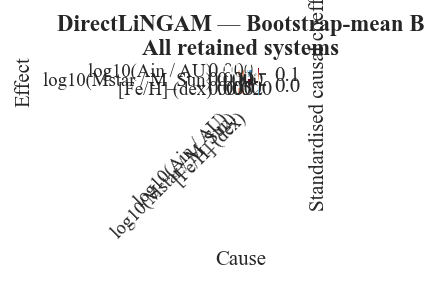

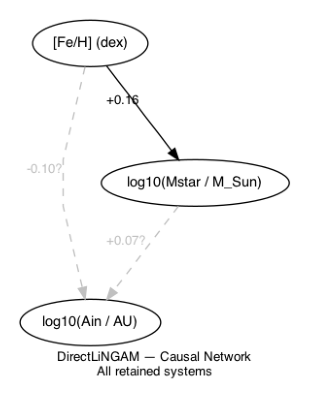

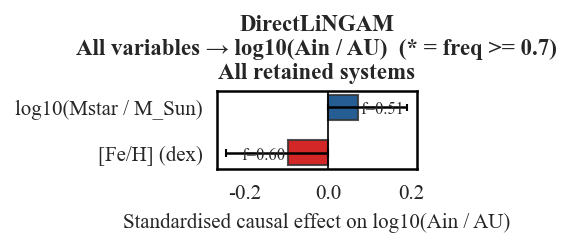


  Structural Equations — DirectLiNGAM  (freq >= 0.7, |coeff| > 0.01)

  log10(Ain / AU) = ε  (no active causal parents)

  log10(Mstar / M_Sun) =
      +0.157·[Fe/H] (dex) + ε
      [[Fe/H] (dex): coeff=+0.157, 95% CI=[+0.000,+0.288], freq=0.73] 

  [Fe/H] (dex) = ε  (no active causal parents)

  Interpretation Guide

  This file provides a Kepler-specific robustness comparison for the causal
  structure found in CI.py. It uses a separate catalogue pipeline, but may
  share systems with the NASA Exoplanet Archive sample; verify overlap before
  describing it as independent replication.

  Variable correspondences (approximate):
    log_Ain   <->  log_Ain    (inner-boundary semi-major axis)
    log_Mstar <->  st_mass    (stellar mass)
    FeH       <->  st_met     (metallicity)

  Interpretation caveat:
    KOI koi_sma is calculated from period and a KOI stellar-mass estimate.
    This analysis uses Berger iso_mass, which may differ; an Ain–Mstar edge
    is therefore not independent e

In [13]:
# ============================================================================
# Kepler Inner-Boundary Orbital Period — Causal Discovery (Kepler Sample)
# ============================================================================
#
# Purpose
# -------
# Kepler-specific causal analysis using the DR25 / Berger / PAST2 sample.
# This is a separate selection and measurement pipeline, but not guaranteed
# to represent an independent population: the NASA Archive may include these
# same systems. Treat agreement as robustness, not automatically replication.
#
# Key design choices (intentionally fixed)
# -----------------------------------------
#   Data source : Kepler DR25 + Berger stellar parameters + PAST2 metallicity
#                 (separate catalogue pipeline; system-level overlap is possible)
#   Variables   : log_Ain  = log10(inner semi-major axis / AU)   [target]
#                 log_Mstar = log10(stellar mass / M_Sun)
#                 FeH       = stellar [Fe/H] (dex, raw)
#   Method      : DirectLiNGAM + bootstrap only
#                 (PC and FCI omitted to keep this file focused)
#   Sample      : All retained systems only
#
# Alignment with CI.py
# ------------------------------------
#   Variable correspondences (approximate):
#     log_Ain   <->  log_Ain  (both measure inner-boundary semi-major axis)
#     log_Mstar <->  st_mass   (stellar mass)
#     FeH       <->  st_met    (metallicity)
#
#   Output structure mirrors causal_inference.py:
#     (a) Text edge table       — all directed edges, sorted
#     (b) Adjacency matrix      — p×p heatmap of B coefficients
#     (c) Causal network        — Graphviz DAG (strong + weak edges)
#     (d) Effects on target     — bar chart of all variables → log_Ain
#     (e) Structural equations  — full SEM in equation form
#
# Prerequisites
# -------------
#   pip install lingam graphviz
#   conda install -c conda-forge graphviz   (system binary)
#   Data files in working directory:
#     q1_q17_dr25_koi_2025.06.15_14.55.35.csv
#     GKSPCPapTable1_Final.txt
#     GKSPCPapTable2_Final.txt
#     PAST2_LAMOST-Gaia-Kepler_kinematic_catalog.txt
# ============================================================================


# ── 1. IMPORTS ──────────────────────────────────────────────────────────────

import io
import warnings

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
import numpy as np
import pandas as pd
import lingam
import seaborn as sns
import statsmodels.api as sm

from lingam.utils import make_prior_knowledge
from scipy.stats import kurtosis, normaltest, shapiro
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('mode.chained_assignment', None)


# ── 2. SETTINGS ─────────────────────────────────────────────────────────────

RANDOM_STATE  = 42
PROB_THR      = 0.70     # bootstrap frequency for strong edges (solid lines)
WEAK_THR      = 0.40     # bootstrap frequency for weak edges (dashed lines)
BOOT_N        = 500      # bootstrap iterations (matches original CI_Kepler)
MIN_EFFECT    = 0.01     # minimum |coefficient| to count an edge as active
ALPHA         = 0.05     # significance level for assumption checks
FIGURE_SCALE = 0.5    # result figures are rendered at half of the original size

KEPLER_FILE      = 'q1_q17_dr25_koi_2025.06.15_14.55.35.csv'
KEPLER_SKIP_ROWS = 144
BERGER_TABLE_1   = 'GKSPCPapTable1_Final.txt'
BERGER_TABLE_2   = 'GKSPCPapTable2_Final.txt'
PAST2_FILE       = 'PAST2_LAMOST-Gaia-Kepler_kinematic_catalog.txt'
PAST2_SKIP_ROWS  = 55

SAVE_INTERMEDIATE_TABLES = True
BERGER_OUTPUT = 'berger.csv'
PAST2_OUTPUT  = 'past.csv'

plt.rcParams.update({
    'font.family'       : 'serif',
    'font.serif'        : ['Times New Roman', 'DejaVu Serif'],
    'axes.edgecolor'    : 'black',
    'axes.linewidth'    : 1.2,
    'figure.dpi'        : 150,
    'mathtext.fontset'  : 'custom',
    'mathtext.rm'       : 'Times New Roman',
    'mathtext.it'       : 'Times New Roman:italic',
    'mathtext.bf'       : 'Times New Roman:bold',
    'axes.unicode_minus': False,
})


def scaled_figsize(width, height):
    """Return a result-figure size scaled by FIGURE_SCALE."""
    return (width * FIGURE_SCALE, height * FIGURE_SCALE)


# ── 3. VARIABLE DEFINITIONS ─────────────────────────────────────────────────

# Three causal variables (intentionally minimal — mirrors the original Kepler CI)
# Caveat: the KOI catalogue defines koi_sma from period and a KOI stellar-mass
# estimate. This analysis uses Berger iso_mass, which may differ; the
# Ain–Mstar relationship can still be mathematically coupled and needs cautious
# causal wording.
COLUMNS = ['log_Ain', 'log_Mstar', 'FeH']

LABELS = {
    'log_Ain'  : 'log10(Ain / AU)',
    'log_Mstar': 'log10(Mstar / M_Sun)',
    'FeH'      : '[Fe/H] (dex)',
}

def lbl(col):
    return LABELS.get(col, col)


# ── 4. DATA LOADING ─────────────────────────────────────────────────────────

def print_shape(name, df):
    n = df['kepid'].nunique() if 'kepid' in df.columns else 'n/a'
    print(f'  {name}: {df.shape[0]} rows, {n} systems')


def load_catalogues():
    """
    Read and merge Kepler DR25, Berger and PAST2 catalogues.
    Identical to the original CI_Kepler.py — data source unchanged.
    """
    print('=' * 65)
    print('  Loading Kepler DR25 / Berger / PAST2 catalogues')
    print('=' * 65)

    kdr25 = pd.read_csv(KEPLER_FILE, skiprows=KEPLER_SKIP_ROWS)
    kdr25 = kdr25.dropna(axis=1, how='all')
    print_shape('Kepler DR25', kdr25)

    ber1 = pd.read_table(BERGER_TABLE_1, sep='&')
    ber1 = ber1.rename(columns=lambda c: c.replace('\\', ''))
    if 'evstate' in ber1.columns:
        ber1['evstate'] = ber1['evstate'].astype(str).str.replace('\\', '', regex=False)
    print_shape('Berger table 1', ber1)

    ber2 = pd.read_table(BERGER_TABLE_2, sep='&')
    ber2 = ber2.rename(columns=lambda c: c.replace('\\', ''))
    if 'TAMS' in ber2.columns:
        ber2['TAMS'] = ber2['TAMS'].astype(str).str.replace('\\', '', regex=False)
    print_shape('Berger table 2', ber2)

    berger = pd.merge(ber1, ber2, on=['KIC']).dropna(axis=1, how='all')
    if SAVE_INTERMEDIATE_TABLES:
        berger.to_csv(BERGER_OUTPUT, index=False)
    print_shape('Berger merged', berger)

    past_cols = [
        'GaiaDR2','LAMOST','KIC','RAdeg','DEdeg','Par','e_Par',
        'pmRA','e_pmRA','pmDE','e_pmDE','Gmag','Kepmag','Teff','e_Teff',
        'logg','e_logg','Fe/H','e_Fe/H','a/Fe','e_a/Fe','vr','e_vr',
        'Np','R','theta','Z','VR','Vt','Vz','U','e_U','V','e_V','W','e_W',
        'TD/D','TD/H','Her/D','Her/TD','Comp1','Comp2',
    ]
    past = pd.read_table(PAST2_FILE, skiprows=PAST2_SKIP_ROWS,
                         names=past_cols, sep=r'\s+')
    past['Comp'] = past['Comp1'].astype(str) + ' ' + past['Comp2'].astype(str)
    past = past.drop(columns=['Comp1','Comp2'])
    past = past[past['Fe/H'] > -10].dropna(axis=1, how='all')
    if SAVE_INTERMEDIATE_TABLES:
        past.to_csv(PAST2_OUTPUT, index=False)
    print_shape('PAST2', past)

    pls = pd.merge(kdr25, berger, left_on='kepid', right_on='KIC',
                   suffixes=('','_ber')).drop(columns=['KIC'], errors='ignore')
    print_shape('Kepler + Berger', pls)

    pls = pd.merge(pls, past, left_on='kepid', right_on='KIC',
                   suffixes=('','_past')).drop(columns=['KIC'], errors='ignore')
    print_shape('Kepler + Berger + PAST2', pls)

    if 'koi_disposition' not in pls.columns:
        raise KeyError("Merged table missing 'koi_disposition'.")
    pls = pls.loc[pls['koi_disposition'] != 'FALSE POSITIVE'].copy()
    print_shape('After false-positive removal', pls)
    return pls


# ── 5. SAMPLE SELECTION ─────────────────────────────────────────────────────

def _step(label, pls):
    print(f'  [{label}]  Systems: {pls["kepid"].nunique()}   Rows: {len(pls)}')


def select_sample(pls):
    """
    Apply system-level and planet-level selection cuts.
    Identical to the original CI_Kepler.py — selection logic unchanged.
    """
    print('\n' + '='*65)
    print('  Sample Selection')
    print('='*65)
    pls = pls.copy()

    pls = pls.loc[pls['RUWE'] < 1.2].copy()
    _step('After binary removal (RUWE < 1.2)', pls)

    pls['log_iso_rad'] = np.log10(pls['iso_rad'])
    pls['new_iso_teff'] = 0.00035 * (pls['iso_teff'] - 4500) + 0.15
    pls = pls.loc[pls['log_iso_rad'] < pls['new_iso_teff']].copy()
    pls = pls.drop(columns=['log_iso_rad', 'new_iso_teff'])
    _step('After giant removal', pls)

    pls['usp'] = (~pls.groupby('kepid')['koi_period']
                  .transform(lambda v: (v > 1).all())).astype(int)
    pls = pls.loc[pls['usp'] != 1].copy()
    _step('After excluding USP systems (period <= 1 day)', pls)

    pls['koi_prad'] = pls['koi_ror'] * pls['iso_rad'] * 110
    pls['sp'] = (pls.groupby('kepid')['koi_prad']
                 .transform(lambda v: ~(v < 4).all())).astype(int)
    pls = pls.loc[pls['sp'] != 1].copy()
    _step('After excluding large-planet systems (R >= 4 R_Earth)', pls)

    pls = pls.loc[pls['koi_model_snr'] > 7.1].copy()
    _step('After SNR > 7.1 cut', pls)

    plsa = _select_inner_edge(pls)
    print(f'\n  All-systems inner-edge table: {len(plsa)} rows')
    return dict(pls=pls, plsa=plsa)


def _select_inner_edge(pls):
    """One row per system: minimum koi_sma (inner semi-major axis)."""
    if pls.empty:
        return pls.copy()
    min_sma = pls.groupby('kepid')['koi_sma'].min().rename('koi_sma')
    return pls.merge(min_sma.reset_index(), on=['kepid','koi_sma'], how='inner')


# ── 6. BUILD ANALYSIS DATAFRAME ─────────────────────────────────────────────

def safe_log10(s):
    s = s.copy().astype(float)
    s[~(s > 0)] = np.nan
    return np.log10(s)


def _pick_met_col(df):
    for c in ['Fe/H','feh','st_met','[Fe/H]','FeH']:
        if c in df.columns:
            return c
    raise KeyError("No metallicity column found.")


def build_system_df(pls):
    """
    One row per system: inner semi-major axis, stellar mass, metallicity.
    Unchanged from original CI_Kepler.py.
    """
    met_col = _pick_met_col(pls)
    valid   = pls.dropna(subset=['koi_sma']).copy()
    inner   = valid.loc[valid.groupby('kepid')['koi_sma'].idxmin(),
                        ['kepid','koi_sma']].rename(columns={'koi_sma':'Ain'})
    stars   = pls.groupby('kepid').agg(
        Mstar=(  'iso_mass', 'median'),
        FeH  =(met_col,     'median'),
    ).reset_index()
    sys_df = inner.merge(stars, on='kepid', how='inner')
    sys_df = sys_df.replace([np.inf,-np.inf], np.nan)
    return sys_df.dropna(subset=['Ain','Mstar','FeH']).reset_index(drop=True)


def build_lingam_df(sys_df):
    """Three-variable CI DataFrame: log_Ain, log_Mstar, FeH."""
    df = pd.DataFrame({
        'log_Ain'  : safe_log10(sys_df['Ain']),
        'log_Mstar': safe_log10(sys_df['Mstar']),
        'FeH'      : sys_df['FeH'].values.astype(float),
    })
    return df.replace([np.inf,-np.inf], np.nan).dropna().reset_index(drop=True)


# ── 7. ASSUMPTION CHECKS ────────────────────────────────────────────────────

def check_assumptions(df):
    """
    Three checks aligned with causal_inference.py:
      [1] Sample size ratio
      [2] Non-Gaussianity (Shapiro-Wilk)
      [3] Multicollinearity (VIF)
    """
    print('\n' + '='*60)
    print('  Assumption Checks  (DirectLiNGAM)')
    print('='*60)
    n, p = df.shape
    print(f"\n  [1] Sample size: {n} obs, {p} vars  (ratio {n/p:.1f})")
    print(f"      {'OK' if n/p >= 10 else 'WARNING: recommend >= 10 x n_vars'}")

    print(f"\n  [2] Non-Gaussianity (Shapiro-Wilk, alpha={ALPHA})")
    print(f"      {'Variable':<14} {'p-value':>10}  {'Skewness':>10}  Result")
    print(f"      {'─'*50}")
    for c in df.columns:
        _, pv = shapiro(df[c])
        sk    = float(df[c].skew())
        print(f"      {c:<14} {pv:>10.4f}  {sk:>10.3f}  "
              f"{'Non-Gaussian OK' if pv < ALPHA else 'Near-Gaussian'}")

    print(f"\n  [3] Multicollinearity (VIF; <10 acceptable)")
    print(f"      {'Variable':<14} {'VIF':>8}  Result")
    print(f"      {'─'*30}")
    Xsc  = StandardScaler().fit_transform(df)
    vifs = [variance_inflation_factor(Xsc, i) for i in range(p)]
    for c, v in zip(df.columns, vifs):
        print(f"      {c:<14} {v:>8.2f}  {'WARNING' if v > 10 else 'OK'}")
    print(f"\n      Max VIF = {max(vifs):.2f}")
    print('='*60)


def check_linearity(df):
    """
    [4] Linearity check: LinearRegression vs GBT R² per variable.
    A large gap suggests the linearity assumption may be violated.
    """
    print('\n' + '='*60)
    print('  [4] Linearity Check  (LinearRegression vs GBT R²)')
    print('='*60)
    print(f"  {'Variable':<14} {'R²_linear':>10} {'R²_GBT':>10} "
          f"{'gap':>8}  Result")
    print(f"  {'─'*55}")
    lin  = LinearRegression()
    gbt  = GradientBoostingRegressor(random_state=RANDOM_STATE,
                                     n_estimators=100, max_depth=3)
    gaps = []
    for col in df.columns:
        others = [c for c in df.columns if c != col]
        X, y   = df[others].values, df[col].values
        lin.fit(X, y);  r2l = r2_score(y, lin.predict(X))
        gbt.fit(X, y);  r2g = r2_score(y, gbt.predict(X))
        gap = r2g - r2l; gaps.append(gap)
        verdict = 'OK' if gap < 0.05 else ('MILD' if gap < 0.20 else 'WARNING')
        print(f"  {col:<14} {r2l:>10.3f} {r2g:>10.3f} {gap:>8.3f}  {verdict}")
    mean_gap = float(np.mean(gaps))
    print(f"\n  Mean gap = {mean_gap:.3f}  "
          f"({'OK' if mean_gap < 0.05 else 'MILD — interpret cautiously' if mean_gap < 0.20 else 'WARNING — strong nonlinearity'})")
    print('='*60)


# ── 8. DIRECTLINGAM + BOOTSTRAP ─────────────────────────────────────────────

def _make_prior(cols):
    """Force log_Ain to be a sink node (cannot cause other variables)."""
    idx      = {c: i for i, c in enumerate(cols)}
    no_paths = [(idx['log_Ain'], j)
                for j in range(len(cols)) if j != idx['log_Ain']] \
               if 'log_Ain' in idx else []
    return make_prior_knowledge(len(cols), no_paths=no_paths)


def run_lingam_bootstrap(df):
    """
    Fit DirectLiNGAM on standardised data + manual bootstrap loop.
    Returns: mean_B, ci_low_B, ci_high_B, probs, B_df, edge_df
      mean_B  : (p,p) mean adjacency matrix over bootstrap samples
      ci_*_B  : elementwise 2.5th and 97.5th percentile bounds
      probs   : (p,p) bootstrap frequency P[|coeff|>MIN_EFFECT]
      B_df    : bootstrap-mean adjacency DataFrame
      edge_df : long-format edge table (from, to, mean, freq, ci_low, ci_high, sig)
    """
    cols   = COLUMNS
    X      = StandardScaler().fit_transform(df[cols])
    prior  = _make_prior(cols)
    rng    = np.random.default_rng(RANDOM_STATE)

    model  = lingam.DirectLiNGAM(prior_knowledge=prior, random_state=RANDOM_STATE)
    model.fit(X)
    print(f"  Causal order: {[cols[i] for i in model.causal_order_]}")

    print(f"  Bootstrap ({BOOT_N} iterations) ...", end='', flush=True)
    boot_mats  = []
    for run in range(BOOT_N):
        idx  = rng.choice(len(df), len(df), replace=True)
        bm   = lingam.DirectLiNGAM(prior_knowledge=prior,
                                    random_state=RANDOM_STATE + run + 1)
        bm.fit(X[idx])
        boot_mats.append(bm.adjacency_matrix_.copy())
    print(' done.')

    stack  = np.array(boot_mats)          # (BOOT_N, p, p)
    mean_B = stack.mean(axis=0)
    ci_low_B, ci_high_B = np.percentile(stack, [2.5, 97.5], axis=0)
    p      = len(cols)
    probs  = np.zeros((p, p))
    for i in range(p):
        for j in range(p):
            if i != j:
                probs[i, j] = np.mean(np.abs(stack[:, i, j]) > MIN_EFFECT)

    rows = []
    for ti, tgt in enumerate(cols):
        for si, src in enumerate(cols):
            if ti == si:
                continue
            lo, hi = ci_low_B[ti, si], ci_high_B[ti, si]
            sig = (lo > 0) or (hi < 0)
            rows.append([src, tgt, mean_B[ti, si], probs[ti, si],
                         lo, hi, sig])

    edge_df = pd.DataFrame(rows,
                           columns=['from','to','mean','freq',
                                    'ci_low','ci_high','sig'])
    B_df = pd.DataFrame(mean_B, index=cols, columns=cols)
    return mean_B, ci_low_B, ci_high_B, probs, B_df, edge_df


# ── 9. TEXT OUTPUT ──────────────────────────────────────────────────────────

def print_all_edges_text(edge_df):
    """
    Print ALL edges (all variable pairs) sorted by frequency.
    Edges into log_Ain are marked with ***.
    Mirrors causal_inference.py print_lingam_all_edges style.
    """
    print(f"\n  {'─'*70}")
    print(f"  DirectLiNGAM — ALL edges  (freq = P[|coeff| > {MIN_EFFECT}])")
    print(f"  {'─'*70}")
    print(f"  {'Cause':<16} {'Effect':<16} {'Coeff':>8} {'Freq':>6} "
          f"{'95% CI':>22}  Active?")
    print(f"  {'─'*70}")
    sub = edge_df.copy()
    sub['abs_mean'] = sub['mean'].abs()
    sub = sub.sort_values(['freq','abs_mean'], ascending=False)
    for _, r in sub.iterrows():
        ci  = f"[{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]"
        act = 'Yes' if r['freq'] >= PROB_THR else 'No'
        mkr = '  *** target ***' if r['to'] == 'log_Ain' else ''
        print(f"  {lbl(r['from']):<16} {lbl(r['to']):<16} {r['mean']:>8.3f} "
              f"{r['freq']:>6.2f} {ci:>22}  {act}{mkr}")


def print_structural_equations(mean_B, ci_low_B, ci_high_B, probs,
                               prob_thr=None):
    """
    Express LiNGAM result as a system of structural equations.
    Mirrors causal_inference.py print_structural_equations style.
    """
    if prob_thr is None:
        prob_thr = PROB_THR
    cols = COLUMNS
    print('\n' + '='*70)
    print(f'  Structural Equations — DirectLiNGAM  '
          f'(freq >= {prob_thr}, |coeff| > {MIN_EFFECT})')
    print('='*70)
    for i, eff in enumerate(cols):
        terms = []
        for j, cau in enumerate(cols):
            if i == j: continue
            pij   = probs[i, j]
            coeff = mean_B[i, j]
            if pij >= prob_thr and abs(coeff) > MIN_EFFECT:
                ci_lo = ci_low_B[i, j]
                ci_hi = ci_high_B[i, j]
                terms.append((abs(coeff), cau, coeff, pij, ci_lo, ci_hi))
        terms.sort(key=lambda t: -t[0])
        if terms:
            eq = ' '.join(f'{c:+.3f}·{lbl(cau)}' for _, cau, c, *_ in terms)
            print(f"\n  {lbl(eff)} =")
            print(f"      {eq} + ε")
            for _, cau, c, pij, ci_lo, ci_hi in terms:
                mkr = '***' if eff == 'log_Ain' else ''
                print(f"      [{lbl(cau)}: coeff={c:+.3f}, "
                      f"95% CI=[{ci_lo:+.3f},{ci_hi:+.3f}], freq={pij:.2f}] {mkr}")
        else:
            print(f"\n  {lbl(eff)} = ε  (no active causal parents)")
    print('\n' + '='*70)


# ── 10. VISUALISATION ───────────────────────────────────────────────────────

def plot_adjacency_heatmap(B_df, title):
    """
    Numeric B matrix heatmap (RdBu_r).
    B[i,j] = standardised direct effect of variable j on variable i.
    Mirrors causal_inference.py plot_lingam_all heatmap.
    """
    labels = [lbl(c) for c in B_df.columns]
    fig, ax = plt.subplots(figsize=scaled_figsize(5, 4))
    sns.heatmap(B_df.values, xticklabels=labels, yticklabels=labels,
                cmap='RdBu_r', center=0, annot=True, fmt='.3f',
                linewidths=0.5, square=True, ax=ax,
                cbar_kws={'label': 'Standardised causal coefficient'})
    ax.set_title(f'DirectLiNGAM — Bootstrap-mean B\n{title}',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('Cause', fontsize=10)
    ax.set_ylabel('Effect', fontsize=10)
    plt.xticks(rotation=45, ha='right', fontsize=9)
    plt.yticks(rotation=0, fontsize=9)
    plt.tight_layout()
    plt.show()


def plot_causal_network(mean_B, probs, title):
    """
    Graphviz DAG with strong (solid) and weak (dashed grey) edges.
    log_Ain at the bottom (sink).  Mirrors causal_inference.py style.

    Strong : freq >= PROB_THR  — solid line with coefficient label
    Weak   : WEAK_THR <= freq < PROB_THR — grey dashed line
    """
    import graphviz as gv

    cols = COLUMNS
    graph_title = f'DirectLiNGAM — Causal Network\\n{title}'
    lines = [
        'digraph {',
        f'  graph [rankdir=TB nodesep=0.8 ranksep=1.0 splines=polyline'
        f' fontname="Times New Roman" label="{graph_title}" labelloc=b fontsize=10]',
        '  node  [shape=ellipse style=filled fillcolor=white'
        ' fontname="Times New Roman" fontsize=11]',
        '  edge  [fontname="Times New Roman" fontsize=10 arrowsize=0.9]',
        '  { rank=sink; "log_Ain" }',
    ]
    for v in cols:
        lines.append(f'  "{v}" [label="{lbl(v)}"]')

    p = len(cols)
    for i in range(p):
        for j in range(p):
            if i == j: continue
            pij   = probs[i, j]
            coeff = mean_B[i, j]
            if pij < WEAK_THR or abs(coeff) < MIN_EFFECT:
                continue
            cau, eff = cols[j], cols[i]
            weak     = pij < PROB_THR
            style    = ' style=dashed color=grey fontcolor=grey' if weak else ''
            edge_lbl = f'{coeff:+.2f}' if not weak else f'{coeff:+.2f}?'
            lines.append(f'  "{cau}" -> "{eff}" [xlabel="{edge_lbl}"{style}]')

    lines.append('}')
    dot_src = '\n'.join(lines)

    try:
        png_bytes = gv.Source(dot_src).pipe(format='png')
    except Exception as e:
        print(f"  Graphviz render failed: {e}")
        print("  Install: conda install -c conda-forge graphviz")
        return

    img = plt.imread(io.BytesIO(png_bytes))
    fig, ax = plt.subplots(figsize=scaled_figsize(6, 5))
    ax.imshow(img); ax.set_axis_off()
    plt.tight_layout(pad=0)
    plt.show()


def plot_effects_on_target(mean_B, ci_low_B, ci_high_B, probs,
                           title, target='log_Ain'):
    """
    Bar chart of all variables → log_Ain.
    All variables shown; active edges (freq >= PROB_THR) marked with *.
    Mirrors causal_inference.py plot_effects_on_target for LiNGAM.
    """
    cols    = COLUMNS
    ti      = cols.index(target)
    sources = [c for c in cols if c != target]
    rows    = []
    for src in sources:
        si  = cols.index(src)
        m   = mean_B[ti, si]
        p   = probs[ti, si]
        rows.append(dict(source=src, mean=m,
                         ci_lo=ci_low_B[ti, si], ci_hi=ci_high_B[ti, si], prob=p,
                         active=p >= PROB_THR))
    df_r = pd.DataFrame(rows).sort_values('mean', ascending=True)

    fig, ax = plt.subplots(figsize=scaled_figsize(6, 3.5))
    colors = ['#004080' if v >= 0 else '#cc0000' for v in df_r['mean']]
    ax.barh(range(len(df_r)), df_r['mean'],
            color=colors, edgecolor='#333', height=0.55, alpha=0.85)
    for i, (_, r) in enumerate(df_r.iterrows()):
        ax.hlines(i, r['ci_lo'], r['ci_hi'], color='black', lw=1.2)
        ax.vlines([r['ci_lo'], r['ci_hi']], i - 0.08, i + 0.08,
                  color='black', lw=1.0)
        offset = max(abs(r['mean']), 0.01) * 0.08
        ha     = 'left' if r['mean'] >= 0 else 'right'
        flag   = '*' if r['active'] else ''
        ax.text(r['mean'] + (offset if r['mean'] >= 0 else -offset),
                i - 0.05, f"f={r['prob']:.2f}{flag}",
                va='center', fontsize=8, ha=ha)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_yticks(range(len(df_r)))
    ax.set_yticklabels([lbl(c) for c in df_r['source']], fontsize=10)
    ax.set_xlabel(f"Standardised causal effect on {lbl(target)}", fontsize=10)
    ax.set_title(f'DirectLiNGAM\nAll variables → {lbl(target)}'
                 f'  (* = freq >= {PROB_THR})\n{title}',
                 fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()


# ── 11. ANALYSIS RUNNER ─────────────────────────────────────────────────────

def run_analysis(pls_subset, label):
    """
    Full DirectLiNGAM analysis for the All-systems sample.

    Outputs (in order):
      1. Assumption checks (sample size, non-Gaussianity, VIF, linearity)
      2. All edges text table
      3. Adjacency matrix heatmap
      4. Causal network (Graphviz, strong + weak edges)
      5. Effects on log_Ain bar chart
      6. Structural equations
    """
    if pls_subset.empty:
        print(f'\n  {label}: empty subset, skipping.')
        return None

    print('\n' + '#'*65)
    print(f'  DirectLiNGAM — {label}')
    print('#'*65)
    print(f'  Planet rows: {len(pls_subset)}'
          f'   Systems: {pls_subset["kepid"].nunique()}')

    sys_df = build_system_df(pls_subset)
    print(f'  Systems after CI cleaning: {len(sys_df)}')
    if len(sys_df) < 30:
        print('  WARNING: fewer than 30 systems — results may be unstable.')

    df = build_lingam_df(sys_df)
    print(f'  LiNGAM DataFrame: {len(df)} rows, variables: {COLUMNS}')
    if df.empty:
        print('  No complete rows remain — skipping.')
        return None

    check_assumptions(df)
    check_linearity(df)

    print(f'\n  Fitting DirectLiNGAM + Bootstrap ...')
    mean_B, ci_low_B, ci_high_B, probs, B_df, edge_df = run_lingam_bootstrap(df)

    print_all_edges_text(edge_df)

    plot_adjacency_heatmap(B_df, label)
    plot_causal_network(mean_B, probs, label)
    plot_effects_on_target(mean_B, ci_low_B, ci_high_B, probs, label)
    print_structural_equations(mean_B, ci_low_B, ci_high_B, probs)

    return dict(sys_df=sys_df, df=df,
                mean_B=mean_B, ci_low_B=ci_low_B,
                ci_high_B=ci_high_B, probs=probs,
                B_df=B_df, edge_df=edge_df, label=label)


# ── 12. MAIN — ALL SYSTEMS ONLY ─────────────────────────────────────────────

print('='*65)
print('  Causal Discovery — Kepler Sample')
print('  (Kepler-specific all-systems robustness analysis for CI.py)')
print('='*65)
print(f'  Method    : DirectLiNGAM + Bootstrap (N={BOOT_N})')
print(f'  Variables : {COLUMNS}')
print(f'  Target    : log_Ain = log10(inner semi-major axis / AU)')
print(f'  Alignment : log_Ain <-> log_Ain  |  log_Mstar <-> st_mass  |  FeH <-> st_met')
print(f'  Freq thr  : strong={PROB_THR} (solid), weak={WEAK_THR} (dashed)')
print('='*65)

merged_planets = load_catalogues()
selected       = select_sample(merged_planets)

result_all = run_analysis(selected['pls'], 'All retained systems')

# Interpretation guide
print('='*65)
print('  Interpretation Guide')
print('='*65)
print(f"""
  This file provides a Kepler-specific robustness comparison for the causal
  structure found in CI.py. It uses a separate catalogue pipeline, but may
  share systems with the NASA Exoplanet Archive sample; verify overlap before
  describing it as independent replication.

  Variable correspondences (approximate):
    log_Ain   <->  log_Ain    (inner-boundary semi-major axis)
    log_Mstar <->  st_mass    (stellar mass)
    FeH       <->  st_met     (metallicity)

  Interpretation caveat:
    KOI koi_sma is calculated from period and a KOI stellar-mass estimate.
    This analysis uses Berger iso_mass, which may differ; an Ain–Mstar edge
    is therefore not independent evidence of a physical causal effect.

  Cross-pipeline agreement (useful robustness evidence, not necessarily
  independent replication):
    An edge that appears with the SAME direction and sign in both
    the NASA Archive analysis (CI.py) and this Kepler analysis is supported
    across the two pipelines. The planet/system samples may overlap.

  Divergent results:
    Differences may arise from sample selection (Kepler transit-only
    vs Archive Transit+RV), stellar parameter sources (Berger vs
    archive values), or genuine astrophysical subpopulation effects.

  Structural equation format:
    Y = b1*X1 + b2*X2 + ε
    Coefficients are standardised (zero-mean, unit-SD).
    Positive = associated with larger log_Ain (longer inner orbit).
    Negative = associated with smaller log_Ain (shorter inner orbit).

  Bootstrap frequency (freq):
    >= {PROB_THR}  : stable under resampling (solid in network plot)
    {WEAK_THR}-{PROB_THR} : less stable (dashed grey in network plot)
    < {WEAK_THR}  : not shown
""")
